## prepare

In [ ]:
final = pd.Series(['MRE11','CANT1','ABCC4','MFAP5','CD8A','GSDME'])
final = 'matp_'+final
final

In [4]:
"""
依赖
----
只依赖标准库(os / re / json / datetime)以及 pandas / numpy / dill / matplotlib
/ plotly 这几个第三方包 —— 都是 pip 包，不是需要另外下载的项目文件
"""

import os
import re
import json
from os.path import join as J
import joblib

from datetime import datetime
from typing import Union, Callable, Literal
import dill
import pandas as pd
import numpy as np
from matplotlib.pyplot import Figure as pltFigure
from plotly.graph_objs._figure import Figure as plotly_Figure

INPUTDIR = 'export_c3' 
OUTPUTDIR = 'report_reply/model'

class Database:
    # ---- 类公共变量默认值, __init__ 不传参时就用这些 ----
    USE_FULL_PATH = True
    OUTPUTDIR = J(os.getcwd(), 'export')
    INPUT_DIR = J(os.getcwd(), 'report')
    _verbose = True

    def __init__(self, outputdir=None, input_dir=None, use_full_path=None, verbose=None):
        """
        不传参时全部使用类公共变量(Database.OUTPUTDIR/INPUT_DIR/USE_FULL_PATH/_verbose)
        的默认值; 传参则按当前实例单独赋值, 覆盖类默认值, 不影响其他实例。
        """
        self.OUTPUTDIR = outputdir or self.OUTPUTDIR
        self.INPUT_DIR = input_dir or self.OUTPUTDIR
        self.USE_FULL_PATH = self.USE_FULL_PATH if use_full_path is None else use_full_path
        self._verbose = self._verbose if verbose is None else verbose
        # 每个实例独立的运行时状态, 不再是共享的类属性
        self.last_exported_file_path = ""
        self._OUTPUTFILES = {}
        self._TOTAL_OUT_FILE_NUM = 0
    def __repr__(self):
        s = super().__repr__()
        s = s + f"""\n  OUTPUTDIR = {self.OUTPUTDIR}\n  INPUTDIR = {self.INPUT_DIR}\n  Verbose = {self._verbose}"""
        return s
        
    def exporting(self, x=None, export=None, outputdir=None,
                    fname=None,
                    worker=None, flag="", prefix="", suffix="",
                    verbose=True,
                    use_full_path=True,
                    method_name="to_csv",
                    add2downloadlist=True, retopath=False, **kwargs):
        """
        :fname: output file name. if you give a name with path, then use the given path instead of outputdir value, else file will be output to path <outputdir>
        :worker: :flag: :prefix: :suffix:
            tags added to the final output filename, in the order of worker_flag_prefix_fname_suffix.extname. each tag only appears when it is not None or empty string ""
        :verbose: print output file info to stdout or not, default True
        :use_full_path: {True,Flase,None} if True output info using full path, if False output info using relative path, if None use default setting self.USE_FULL_PATH
        :outputdir: if not None, output file redirected to outputdir indicated location, else use default path self.OUTPUT_ROOT
        :method_name: if x is an x with output file functions like to_csv, use x call method_name to output files, default to_csv
        :x: the x containing data to output, the behavior differs if x is string type, using function open(fname,'w') as f, f.write(x) .
        :add2downloadlist: if True, file name and path will be added to self._OUTPUTFILES for generating scp bash for download to local disc from the server side
        """
        # 原 self.verbosing(...) 内联为局部闭包, 不再是类方法
        def _print(msg, verbose=None):
            on = self._verbose if verbose is None else verbose
            if on:
                print(f"[{datetime.now().strftime('%m/%d %H:%M:%S')}]{msg}")

        if x is None:
            raise ValueError('x must be not None')

        if export is not None:
            if export == False:
                _print('stop export when export==False', verbose=verbose)
                return None
            elif type(export) == str:
                fname = export
            elif export == True:
                if fname is None:
                    fname = "default"
        assert fname is not None, "ValueError('fname and export both None)"

        if use_full_path is None:
            use_full_path = self.USE_FULL_PATH

        if fname is None or fname == "":
            raise ValueError('fname must not be empty!')

        # fname contains path, overwrite outputdir values
        if '/' in fname:
            outputdir = os.path.dirname(fname)
            fname = os.path.basename(fname)
        else:
            if outputdir is None:
                outputdir = self.OUTPUTDIR

        if use_full_path == True:
            # absolute path
            if outputdir[0] == '/':
                pass
            # relative path
            else:
                outputdir = J(os.getcwd(), outputdir)

        if '.' in fname:
            ext = fname.split('.')[-1]
            name = ".".join(fname.split('.')[:-1])
        else:
            # default output dfx
            name = fname
            tt = type(x)
            if tt == str:
                ext = 'txt'
            elif tt == pltFigure:
                ext = 'pdf'
            elif tt in (pd.DataFrame, pd.Series, np.ndarray, list, pd.Index):
                ext = 'dfx'
            elif tt == plotly_Figure:
                ext = 'pdf'
            else:
                raise TypeError(f'{tt} is unsurported output var type')

        o = []
        for i in [worker, flag, prefix, name, suffix]:
            if i is not None and i != '':
                o.append(i)

        out_full_path = J(outputdir, '_'.join(o) + '.' + ext)

        if os.path.exists(out_full_path):
            KEYWORD = 'overwritting'
        else:
            KEYWORD = 'writing'
        if ext == 'json':
            if type(x) == pd.DataFrame:
                x = x.to_dict('records')
            elif type(x) == pd.Series:
                x = x.to_dict()
            elif type(x) == np.ndarray:
                x = x.tolist()
            if isinstance(x, dict):
                add_token = '[json] with ' + str(len(x.keys())) + ' keys'
            else:
                add_token = ' with ' + str(len(x)) + ' in length'
            with open(out_full_path, 'w') as f:
                json.dump(x, f)
        elif ext in ['pkl', 'pickle']:
            raise ValueError('do not use pickle, using dill instead')
        elif ext == 'dill':
            with open(out_full_path, 'w') as f:
                dill.dump(x, f)
        elif ext in ['xlsx', 'xls']:
            if type(x) == pd.DataFrame:
                method_name = 'to_excel'
                method = getattr(x, method_name)
                method(out_full_path, **kwargs)
                add_token = f"{len(x)} lines"
            elif isinstance(x, dict):
                ## :engine: 'xlsxwriter' for .xlsx, 'xlwt' for .xls
                if ext == 'xlsx':
                    writer = pd.ExcelWriter(out_full_path, engine='xlsxwriter')
                elif ext == 'xls':
                    writer = pd.ExcelWriter(out_full_path, engine='xlwt')
                else:
                    raise ValueError('only xlsx,xls is supported at current')
                EXCEL_SHEETS_LIMIT = 255
                max_row = 50_000
                if 'index' not in kwargs:
                    kwargs['index'] = True
                count = 0
                sheet_names_used = {}
                l = len(x.keys())
                if l < EXCEL_SHEETS_LIMIT:
                    temp = f'{{:0{len(str(l))}d}}'
                else:
                    raise ValueError(f'too many DataFrames({l}) to be written, maximal 255!')
                cnt = 0
                for name, df in x.items():
                    if type(df) not in [pd.DataFrame, pd.Series]:
                        _print(f'⚠ skip {name} for {type(df)} is not df/series')
                        continue
                    l = len(df)
                    if l <= max_row:
                        count = count + 1
                        cc = temp.format(count)
                        _print(f'  append #{cc} Sheet [{name}]')
                        if len(name) > 30:
                            name = name[:28]
                        if name in sheet_names_used.keys():
                            suffix = sheet_names_used[name]
                            if suffix > 100:
                                print(f'⛔ too many(>100) sheets with the same name! skip sheet {name} : {suffix}')
                            name = name + str(suffix)
                            sheet_names_used[name] += 1
                        else:
                            sheet_names_used[name] = 0
                        # change any df column with dtype of datetime64+time zone to str, as current xlwt does not support datetime with time zone info format
                        mask = pd.Series([pd.api.types.is_datetime64_any_dtype(i) for i in df.dtypes])
                        df = df.astype({i: str for i in df.columns[mask]})
                        df.to_excel(writer, sheet_name=name, **kwargs)
                        cnt = cnt + 1
                    else:
                        _print(f'⛔ skip [{name}.dfx] for it contains {l} rows exceeding max_row setting.')
                writer.save()
                add_token = f"{cnt} sheets"
                print(f'writing 1 excel @ {out_full_path}')
            else:
                raise ValueError(f'x type {type(x)} not supported to excel')
        else:
            # ext in ['txt','csv','tsv','dfx','svg','pdf','png','tif','tiff'], etc
            tt = type(x)
            if tt == str:
                with open(out_full_path, 'w') as f:
                    f.write(x)
                    f.close()
                add_token = f"{len(x)} chars"
            elif tt == pltFigure:
                method_name = 'savefig'
                add_token = 'plt'
                method = getattr(x, method_name)
                method(out_full_path, **kwargs)
            elif tt == plotly_Figure:
                method_name = 'write_image'
                add_token = 'plotly'
                method = getattr(x, method_name)
                method(out_full_path, **kwargs)
            elif tt in (pd.DataFrame, pd.Series, np.ndarray, list, pd.Index):
                if tt in (np.ndarray, list, pd.Index):
                    x = pd.DataFrame(x).squeeze()
                if method_name == 'to_csv':
                    if "sep" not in kwargs:
                        kwargs['sep'] = '\t'
                    if "index" not in kwargs:
                        if type(x.index) == pd.RangeIndex:
                            kwargs['index'] = False
                        else:
                            kwargs['index'] = True

                add_token = f"{len(x)} lines"
                method = getattr(x, method_name)
                method(out_full_path, **kwargs)
            else:
                raise TypeError(f'{tt} is unsurported output var type')

        if verbose == True:
            _print(f" {KEYWORD} 1 file with {add_token} at \n\t{out_full_path}", verbose=verbose)

        self.last_exported_file_path = out_full_path

        if add2downloadlist == True:
            self._OUTPUTFILES[fname] = out_full_path
            self._TOTAL_OUT_FILE_NUM += 1
        if retopath:
            return out_full_path
        return None

    def importing(self, fname, frm=None, worker=None, flag="", prefix=None, suffix=None, method: Union[Callable, Literal['read_csv']] = "read_csv", verbose=True, raise_error=True, show_all_sheets=True, **kwargs):
        """
        :fname: file name to import, if '/' in fname, override frm value
        :frm: import fname from <frm>
        :prefix: fname will add prefix on search, fname = pre+'_+fname
        :worker: if not None, the file name searched is worker_fname, if worker_fname not found, retry with fname alone
        :method: method to import files, default "read_csv", for reading pd.read_csv
        :show_all_sheets: show all the sheets in the excel file, default False, only used when reading excel file xlsx, xls
        """
        # 原 self._read_json(...) 内联为局部闭包, 不再是类方法
        def _read_json(path):
            with open(path) as f:
                j = json.load(f)
            return j

        if frm is None:
            frm = self.INPUT_DIR

        if '/' in fname:
            frm = os.path.dirname(fname)
            fname = os.path.basename(fname)
        else:
            if frm is None:
                frm = self.OUTPUTDIR

        if '.' in fname:
            ext = fname.split('.')[-1]
            name = ".".join(fname.split('.')[:-1])
        else:
            # default output dfx
            name = fname
            ext = 'dfx'

        if ext in ['xlsx', 'xls']:
            read_method = getattr(pd, 'read_excel')
        elif ext in ['json']:
            read_method = _read_json
        elif method == 'read_csv':
            read_method = getattr(pd, method)
            if "sep" not in kwargs:
                kwargs["sep"] = '\t'
            if "index_col" not in kwargs:
                kwargs["index_col"] = None

        link = [i for i in [flag, prefix, name, suffix] if i is not None and i != '']
        name = '_'.join(link)
        if worker is not None and re.match('^[A-Z][0-9]$', worker):
            full_path = J(frm, worker + "_" + name + '.' + ext)
            backup_full_path = J(frm, name + '.' + ext)
        else:
            full_path = J(frm, name + '.' + ext)
            backup_full_path = None

        if verbose == True:
            print(f"[{datetime.now().strftime('%m/%d %H:%M:%S')}]reading {full_path}")

        if ext in ['xlsx', 'xls']:
            # show additional info of xls sheet names
            with pd.ExcelFile(full_path) as xl:
                sheets = xl.sheet_names
                sheet_name = kwargs.get('sheet_name', 0)
                if type(sheet_name) == int:
                    sheet_i = sheet_name
                    sheet_name = sheets[sheet_i]
                elif type(sheet_name) == str and sheet_name in sheets:
                    sheet_i = sheets.index(sheet_name)
                else:
                    raise ValueError(f'sheet_name {sheet_name} not found in {sheets}')
                if show_all_sheets:
                    print(f'  Sheets list: {sheets}')
                print(f'  Read the {sheet_i + 1} / {len(sheets)} sheet named <{sheet_name}>')

        if os.path.exists(full_path):
            return read_method(full_path, **kwargs)
        elif backup_full_path:
            print(f"[{datetime.now().strftime('%m/%d %H:%M:%S')}]not found, retry reading {backup_full_path}")
            return read_method(full_path, **kwargs)
        else:
            if raise_error:
                raise IOError(f'{full_path} does not exist!')

db = Database(input_dir=INPUTDIR, outputdir=OUTPUTDIR)
db


  OUTPUTDIR = report_reply/model
  INPUTDIR = export_c3
  Verbose = True

In [5]:
# from dalibs import *
from sklearn.linear_model import LogisticRegressionCV,LogisticRegression
from itertools import combinations

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import Binarizer
from sklearn.tree import export_graphviz
import graphviz
# from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

import seaborn as sns
import matplotlib.pyplot as plt
from copy import deepcopy
from matplotlib.patches import Patch
plt.rcParams['figure.dpi'] = 100      # controls inline/display resolution in the notebook
plt.rcParams['savefig.dpi'] = 300     # controls resolution when you call fig.savefig() / plt.savefig()

COL_bright = sns.color_palette('bright')
COL_ANNO = {"C1":'#F04923',"C2":'#3BA9DD',"Others":'#8A9197','Valid':COL_bright[0],"Train":COL_bright[1]}
# from dalibs import yplot_heatmap_by_input_matrix
def yplot_heatmap_by_input_matrix(inputs,colData,
                                   bygroup = False,
                                   title=None,
                                   outputdir = OUTPUTDIR,
                                   prefix="",
                                   row_cluster=True,
                                   col_cluster=True,
                                   export=False,
                                   suffix="",
                                   flag="",
                                   putdatatable=False,
                                   force_exe=False,
                                   width='auto',
                                   height='auto',
                                   color_dict = None,
                                   sel_col = 0,
                                  **kwargs
                                  ):
#     grps = set(colData.iloc[:,0])
    # 
    s = inputs.shape
    if width =='auto':
            width = 10 * ( s[1] // 24 + 1)
    if height == 'auto':
            height = max(0.3 * s[0], 6)
    if (pd.Series(inputs.shape) > 1000).any() and force_exe==False:
        raise Exception(f'{inputs.shape} too many cols or rows, set force_exe to continue')
    if type(sel_col)==int:
        grps = colData.iloc[:,sel_col].unique()
        sel_col = colData.iloc[:,sel_col].name
    else:
        grps = colData.loc[:,sel_col].unique()
    
    group_color = colData.apply(lambda x: x.map(dict(zip(x.unique(),[COL_ANNO[i] for i in x.unique()]))),0)
#     if color_dict is None:
#         if len(grps)==2:
#             color_dict = dict(zip(grps,[sns.color_palette('bright')[3],sns.color_palette('bright')[0]]))
#         else:
#             color_dict = dict(zip(grps,sns.color_palette('bright')[:len(grps)]))
#     else:
#         pass
#     if type(sel_col)==int:
#         group_color=colData.iloc[:,sel_col].map(color_dict)
#     else:
#         group_color=colData.loc[:,sel_col].map(color_dict)
    
    res2 = {}
    # print(grps)
    
    BASIC_KWARGS = {"col_cluster": True,
        "row_cluster": True,
        "col_colors": group_color,
        "cmap": sns.diverging_palette(255,10,n=100),
        "vmin": -2,
        "vmax": 2,
        "center": 0,
        "z_score": 1,
        "metric": 'correlation',
        "dendrogram_ratio": 0.2,
        "colors_ratio": 0.02,
        "robust": False,
        "yticklabels": True,
        "xticklabels": False,
        "figsize": (width, height),
        "cbar_pos": (1.065,0.75,0.02,0.1),
        "cbar_kws": {"ticks":[-2,-1,0,1,2]},
        "linewidths": 0.05,
        "linecolor": 'white'
    }
    BASIC_KWARGS.update(kwargs)
    mask = inputs.abs().sum(axis=1)!=0
    if sum(~mask) >0:
        print('⚠ dropping features with all zeros row value:',inputs.index[~mask])
    inputs = inputs.loc[mask,:] 
    
    if bygroup == True:
        for g in grps:
            # basic_kwargs = deepcopy(BASIC_KWARGS)
            # basic_kwargs.update({'col_cluster':True,'row_cluster':False})
            ax = sns.clustermap(inputs.loc[:,colData[colData.loc[:,sel_col]==g].index],
                                col_cluster=True,
                                row_cluster=False,
                                col_colors=group_color, 
                                cmap = sns.diverging_palette(255, 10, n=100)
                               )
            res2[g] = ax.data2d
            plt.close()

        #res2.keys()
        res = []
        for g in grps:
            res = res + res2[g].columns.to_list()
        
        mat = inputs.loc[:,res]
        # sns.set(font_scale=0.8)
        
        basic_kwargs = deepcopy(BASIC_KWARGS)
        basic_kwargs.update({'col_cluster':False,'row_cluster':True})
        basic_kwargs.update(kwargs)
        ax = sns.clustermap(mat,**basic_kwargs)
        
        ax.ax_row_dendrogram.set_visible(False)
        ax.ax_col_dendrogram.set_visible(False)
#         for label in grps:
#             ax.ax_col_dendrogram.bar(0, 0, color=color_dict[label],
#                                     label=label, linewidth=0)
#         ax.ax_col_dendrogram.legend(title='Group',loc='center left', ncol=1,fontsize=12, 
#                                     bbox_to_anchor=(1.2, -3),framealpha=0)
        all_luts = {}
        all_handles = []
        for col in colData.columns:
            lut = dict(zip(colData[col].unique(),group_color[col].unique()))
            for label, color in lut.items():
                ax.ax_col_dendrogram.bar(0, 0, color=color,
                                        label=label, linewidth=0)
            handles = [Patch(facecolor=lut[name]) for name in lut]
            all_handles += handles
            all_luts.update(lut)
        plt.legend(all_handles, all_luts, title=col,
               bbox_to_anchor=(1, 1), bbox_transform=plt.gcf().transFigure, loc='upper right')
        # ax.savefig(f'{REPORT}/ssGSEA_heatmap_immune_label.png', dpi=300) 
        if title is not None:
            ax.fig.suptitle(title) 
    else:
        mat = inputs
        
        basic_kwargs = deepcopy(BASIC_KWARGS)
        basic_kwargs.update(kwargs)
        ax = sns.clustermap(mat, **basic_kwargs)
        
        ax.ax_row_dendrogram.set_visible(False)
        ax.ax_col_dendrogram.set_visible(False)
        
        all_luts = {}
        all_handles = []
        for col in colData.columns:
            lut = dict(zip(colData[col].unique(),group_color[col].unique()))
            for label, color in lut.items():
                ax.ax_col_dendrogram.bar(0, 0, color=color,
                                        label=label, linewidth=0)
            handles = [Patch(facecolor=lut[name]) for name in lut]
            all_handles += handles
            all_luts.update(lut)
#             ax.ax_col_dendrogram.legend(title=col,loc='center left', ncol=1,fontsize=12, 
#                                         bbox_to_anchor=(1.2, -3),framealpha=0)
        plt.legend(all_handles, all_luts, title=col,
               bbox_to_anchor=(1, 1), bbox_transform=plt.gcf().transFigure, loc='upper right')

        if title is not None:
            ax.fig.suptitle(title) 
    if export != False:
#         if flag == "":
#             flag= 'heatMap'
        fname = "_".join([i for i in [flag,prefix,export,suffix] if i not in [None,""] ])
        out = f'{outputdir}/{fname}.pdf'
        print(out)
        
            
        ax.savefig(out, dpi=300) 
    if putdatatable ==True:
        db.exporting(mat,export='data.txt',outputdir=outputdir,flag='heatMap',prefix=prefix,suffix=suffix)
    # plt.close()
    return ax
#-----------------

from matplotlib.ticker import ScalarFormatter

def plot_test_scores(res, ret_fig=False, ax = None):

    alphas = res['coefs'].columns.values
    test_socres = res['test_scores'].values
    if 'features_left' in res:
        features_left = res['features_left']
    else:
        features_left = np.sum(res['coefs'].values != 0,axis=0)
    if ax is None:
        fig1, ax1 = plt.subplots(1,1,figsize=(6.5, 4.2))
    else:
        ax1 = ax
    ax1.semilogx(alphas, test_socres, linewidth=3, alpha=0.8)
    ax1.set_xscale("log")
    ax1.set_ylabel("Test Score (0~1)",color='tab:blue')
    ax1.set_ylim(0,1)
    ax1.tick_params(axis='y', labelcolor='tab:blue')
    ax1.set_xlabel("C")
#     ax1.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())

    
#     ax1.get_xaxis().set_major_formatter(LogFormatter())
#     res['best_alpha'] = gcv.best_params_["coxnetsurvivalanalysis__alphas"][0]
#     ax1.axvline(res['best_alpha'], c="C1")
#     ax1.axhline(0.5, color="r", linestyle="-.",)
    ax1.grid(True)
    
    ax2 = ax1.twinx()
    ax2.semilogx(alphas, features_left, color='tab:red', linewidth=3, alpha=0.8)
    ax2.tick_params(axis='y', labelcolor='tab:red')
    ax2.set_ylabel('Features Left', color='tab:red') #, color='tab:red'
    ax1.invert_xaxis()
#     plt.gca().get_xaxis().set_major_locator(LogLocator(numticks=20))
    plt.gca().set_xticks(alphas[::10])
    plt.gca().get_xaxis().set_major_formatter(ScalarFormatter())
    if ax is None and ret_fig:
        return fig1

    
def plot_venns(*args, labels = None, export=False,outputdir='report_reply/',ret=False, **kwargs):
    """
    :*args: arg list of plotting array/set/Series, like glx.G1,glx.G2, etc, max number of args is 5
    :lables: plotting label of each arg, ordered
    :export: whether output plot fig, if True use default out name, if str, use str.pdf as out name
    """
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 1)
    l = len(args)
    if l == 2:
        from matplotlib_venn import venn2 as venn
    elif l == 3:
        from matplotlib_venn import venn3 as venn
    elif l == 4:
        from matplotlib_venn import venn4 as venn
    elif l == 5:
        from matplotlib_venn import venn5 as venn
    else:
        raise ValueError('args length must <= 5')
    sets = []
    for i in args:
        sets.append(set(i))

    venn(subsets=sets,
         set_labels=labels,
         **kwargs
         )
    if export == True:
        export = f'default_venn{l}'
    if type(export) == str and export!="":
        if export[-4:] != '.pdf':
            export += '.pdf'
        out = J(outputdir,export)
        print("put one pdf at ", out)
        fig.savefig(out)
        
    if ret == True:
        return fig
    
import warnings
from sklearn.exceptions import ConvergenceWarning
from tqdm.notebook import tqdm
def ydo_feature_sel_lasso(XX,YY,C_list,l1_ratio=1,test_size=0.3, random_state=18):
    res = {}
    scores = []
    coefs = pd.DataFrame()
    
    # Turn off convergence warning
    warnings.filterwarnings("ignore", category=ConvergenceWarning)
    for c in tqdm(C_list, ncols=500):
        Xtrain,Xtest,Ytrain,Ytest = train_test_split(XX,YY,test_size=test_size,random_state=random_state,stratify=YY)
        lr = LogisticRegression(penalty='elasticnet',solver='saga',multi_class='multinomial',
                                C=c,
                                l1_ratio=l1_ratio,
                                max_iter=200,
                                random_state=None,
                                tol=1e-5
                               )

        lr.fit(Xtrain,Ytrain)
        coefficients_eNet = pd.DataFrame(
            lr.coef_[0],
            index=lr.feature_names_in_,
            columns=[np.round(lr.C, 5)]
        )
        coefs = pd.concat([coefs,coefficients_eNet],axis=1)
        scores.append(lr.score(Xtest,Ytest))
    # Turn convergence warning back on
    warnings.filterwarnings("default", category=ConvergenceWarning)
    
    _ = coefs.shape
    coefs_sum = coefs.sum(axis=1)
    coefs = coefs.loc[coefs_sum!=0,:]
    
    res['coefs'] = coefs
    print('Filter out all zero features: ',_,' => ',coefs.shape)
    #         res['scores'] = scores

#     bests = scores==scores.max()
#     bestc = coefs.columns[bests][-1]
#     bestf = coefs.loc[:,coefs.columns==bestc]
#     bestf.columns = ['coefficient']
#     bestf = bestf[bestf.coefficient!=0]
#     res['max_tscore_coefs'] = bestf
    scores = pd.Series(scores,name='scores')
    res['test_scores'] = scores
    res['features_left'] = np.sum(res['coefs'].values != 0,axis=0)
    res['best_test_score'] = scores.max()
    res['summary'] = pd.DataFrame({'coefs':res['coefs'].columns,'test_scores':res['test_scores'],'features_left':res['features_left']})
    return res


In [6]:
import pandas as pd
import numpy as np

from sklearn.metrics import roc_curve, accuracy_score, roc_auc_score, confusion_matrix, classification_report, auc
import matplotlib.pyplot as plt
from itertools import cycle
from sklearn.utils import resample

# Calculate Bx_avoided for class 2
def calculate_bx_avoided(cm, target_class):
    FP = cm[:, target_class].sum() - cm[target_class, target_class]
    TN = cm.sum() - (cm[target_class, :].sum() + cm[:, target_class].sum() - cm[target_class, target_class])
    FN = cm[target_class, :].sum() - cm[target_class, target_class]

    total_non_target = TN + FN
    avoidance_rate = 1 - (FP / total_non_target) if total_non_target > 0 else 0

    return avoidance_rate * 100

def plot_calc_metrics(dtc, x, y_true, class_to_avoid = 'Others', digits = 1
                 , n_bootstraps = 500, random_seed=42, represent = False
                 , plot_micro_average_curve = True
                 , fig_title = 'Receiver Operating Characteristic for Multi-Class'
                 , fig_colors = cycle(['#F04923', '#3BA9DD','#8A9197'])
                 )->tuple[pd.DataFrame, plt.Figure]:
    
    class_names = dtc.classes_
    n_classes = len(class_names)
    
    # 计算混淆矩阵\预测概率\预测类别
    y_pred = dtc.predict(x)
    cm = confusion_matrix(y_true,y_pred)
    y_prob = dtc.predict_proba(x)
    
    # Classification Report: includes Precision (PPV), Recall (Sensitivity)
    report = classification_report(y_true, y_pred, target_names=class_names,output_dict=True)
    # 计算将为报告添加的NPV, Specificity等指标
    res = {i:report[i] for i in class_names}
    colfrm = ['AUC','lower','upper','Sensitivity','Specificity','NPV','PPV','Accuracy','Total Accuracy']
    colnames = ['AUC','95% CI lower','95% CI upper','Sen(%)','Spe(%)',"NPV(%)",'PPV(%)','Accuracy(%)','Total Accuracy(%)']
    
    for i in range(n_classes):
        cls = class_names[i]
        tn = cm.sum() - (cm[i, :].sum() + cm[:, i].sum() - cm[i, i])
        fp = cm[:, i].sum() - cm[i, i]
        fn = cm[i, :].sum() - cm[i, i]
        # tp = cm[i, i] # 未使用

        res[cls]['Sensitivity'] = res[cls]['recall']
        res[cls]['Specificity'] = tn / (tn + fp) if (tn + fp) > 0 else 0
        res[cls]['PPV'] = res[cls]['precision']
        res[cls]['NPV'] = tn / (tn + fn) if (tn + fn) > 0 else 0 * 100
        
    # 计算AUC
    # Calculate AUC for each class
    y_true_bin = pd.get_dummies(y_true).values
    y_pred_bin = pd.get_dummies(y_pred).values
    
    fpr:dict[str,np.array] = dict()
    tpr:dict[str,np.array] = dict()
    roc_auc:dict[str,float] = dict()
    
    for i in range(n_classes):
        cls = class_names[i]
        # auc_score = roc_auc_score(y_true_bin[:, i], y_pred_bin[:, i])
        accuracy = accuracy_score(y_true_bin[:, i], y_pred_bin[:, i])
        # _, lower_bound, upper_bound = bootstrap_auc_ci(dtc, x , y_true_bin[:, i], n_bootstraps)
        fpr[cls], tpr[cls], _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
        auc_score = auc(fpr[cls], tpr[cls])
        
        roc_auc[cls] = auc_score
        res[cls]["AUC"] = auc_score
        res[cls]['lower'] = 0#lower_bound
        res[cls]['upper'] = 1#upper_bound
        res[cls]['Accuracy'] = accuracy
    
    if plot_micro_average_curve:
        ytruth_bin_c1_c2 = y_true_bin[:,:2].ravel()
        y_prob_c1_c2 = y_prob[:,:2].ravel()
        fpr["micro"], tpr["micro"], _ = roc_curve(ytruth_bin_c1_c2, y_prob_c1_c2)
        roc_auc["micro"] = roc_auc_score(ytruth_bin_c1_c2, y_prob_c1_c2)
    
    # 绘制ROC曲线
    fig:plt.Figure = plt.figure(figsize=(8,8))
    for i, color in zip(range(n_classes), fig_colors):
        cls = class_names[i]
        plt.plot(fpr[cls], tpr[cls], color=color, lw=2,
                 label='ROC curve of class {0} (area = {1:0.4f})'
                 ''.format(cls, roc_auc[cls]))
    if plot_micro_average_curve:
        plt.plot(fpr["micro"], tpr["micro"],
                 label='micro-average ROC curve (C1 & C2) (area = {0:0.4f})'
                    ''.format(roc_auc["micro"]),
                 color='deeppink', linestyle='--', linewidth=2)
    plt.plot([0, 1], [0, 1], 'k--', lw=2) 
    plt.xlim([-0.01, 1.0]) 
    plt.ylim([0.0, 1.01])
    plt.xlabel('False Positive Rate') 
    plt.ylabel('True Positive Rate') 
    plt.title(fig_title) 
    plt.legend(loc="lower right") 
    
    
    # 为报告添加各种指标
    res_df:pd.DataFrame = pd.DataFrame(res).T
    
    accuracy = accuracy_score(y_true, y_pred)
    res_df['Total Accuracy'] = accuracy
    
    res_df = res_df[colfrm]
    res_df.loc[:,colfrm] = (res_df.loc[:,colfrm].values * 100).round(digits)
    res_df.columns = colnames
    # Note: `Bx_avoided` is not a standard metric in sklearn; you may need to clarify its definition or compute it based on domain-specific logic.
    
    cta = np.where(class_names==class_to_avoid)[0][0]
    bx_avoided = calculate_bx_avoided(cm, cta)
    res_df['Bx Class'] = ""
    res_df.loc[class_to_avoid,'Bx Class'] = '√'
    
    res_df['Bx Avoided(%)'] = np.nan
    res_df.loc[class_to_avoid,'Bx Avoided(%)'] = round(bx_avoided,digits)
    # res_df.insert(0,'AUC(95% CI)', res_df["AUC"].astype(str) + " (" +res_df['95% CI lower'].astype(str) +'-'+res_df['95% CI upper'].astype(str)+ ")"  )
    
    # 挑选出特定需要的列名
    if represent:
        res_df = res_df[['AUC','Sen(%)','Spe(%)',"NPV(%)",'PPV(%)','Accuracy(%)','Total Accuracy(%)','Bx Class','Bx Avoided(%)']]
    
    # 增加混淆矩阵在报告中
    cm = pd.DataFrame(cm, index=class_names,columns=class_names)
    res_df = pd.merge(cm, res_df, left_index=True, right_index=True, how ='inner', suffixes=['','__xx'] ).reset_index(names=['Ground Truth Class'])
    
    return res_df, fig

print("ALL LOADED")

ALL LOADED


## set data

In [120]:
# mat33 = db.importing('export_c3/mat_p+r_bcrxhmxar', index_col = 0)
# mat33

In [66]:
o = db.importing('export_86_7/model_Hallmark_genes.txt')
o

[09/04 01:13:55]reading export_86_7/model_Hallmark_genes.txt


,term,gene
0,HALLMARK_TNFA_SIGNALING_VIA_NFKB,JUNB
1,HALLMARK_TNFA_SIGNALING_VIA_NFKB,CXCL2
2,HALLMARK_TNFA_SIGNALING_VIA_NFKB,ATF3
3,HALLMARK_TNFA_SIGNALING_VIA_NFKB,NFKBIA
4,HALLMARK_TNFA_SIGNALING_VIA_NFKB,TNFAIP3
...,...,...
4378,HALLMARK_PANCREAS_BETA_CELLS,SST
4379,HALLMARK_PANCREAS_BETA_CELLS,ELP4
4380,HALLMARK_PANCREAS_BETA_CELLS,PAK3
4381,HALLMARK_PANCREAS_BETA_CELLS,G6PC2


In [67]:
colData = db.importing('./export_c3/wes_glx.dfx', names=['tsb','Protein_ssGSEA_hm'], header=0)
colData['Group'] = ['pCR' if i=='pCR' else 'non.pCR' for i in colData['Protein_ssGSEA_hm']]
colData['Y'] = [1 if i=='C1' else -1 if i=='C2' else 0 for i in colData['Protein_ssGSEA_hm']]
colData['Y1'] = [1 if i =='C1' else 0 for i in colData['Protein_ssGSEA_hm'] ]
colData['Y2'] = [1 if i =='C2' else 0 for i in colData['Protein_ssGSEA_hm'] ]
colData['Yo'] = [1 if i =='C3' else 1 if i=='pCR' else 0 for i in colData['Protein_ssGSEA_hm'] ]
colData.index = colData['tsb'].values
colData = colData.sort_values('tsb')
colData


[09/04 01:13:56]reading ./export_c3/wes_glx.dfx


,tsb,Protein_ssGSEA_hm,Group,Y,Y1,Y2,Yo
P01,P01,C3,non.pCR,0,0,0,1
P02,P02,C3,non.pCR,0,0,0,1
P03,P03,C3,non.pCR,0,0,0,1
P04,P04,C3,non.pCR,0,0,0,1
P05,P05,C2,non.pCR,-1,0,1,0
...,...,...,...,...,...,...,...
P82,P82,C1,non.pCR,1,1,0,0
P83,P83,C1,non.pCR,1,1,0,0
P84,P84,C1,non.pCR,1,1,0,0
P85,P85,C2,non.pCR,-1,0,1,0


In [76]:
# p = db.importing('./export_86_7/p_matrix_raw_ordered86.dfx',index_col=0)
# p = db.importing('./export_by2_86_pCR_nonpCR/prt_ori_7717.dfx',index_col=0)
p = db.importing('./export_by2_86_pCR_nonpCR/prt_x_7346.dfx',index_col=0)
r = db.importing('./export_86_7/rna_normd.dfx',index_col=0)
r = r.loc[:,p.columns]
p


[09/04 01:15:17]reading ./export_by2_86_pCR_nonpCR/prt_x_7346.dfx
[09/04 01:15:17]reading ./export_86_7/rna_normd.dfx


,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,...,P77,P78,P79,P80,P81,P82,P83,P84,P85,P86
A1BG,0.287177,0.293907,-0.090630,0.002907,0.187286,0.078657,-0.209691,0.093071,-0.188679,-0.176356,...,0.091358,-0.006072,-0.051761,0.280976,0.027872,0.254332,-0.060817,0.193137,0.031455,0.260769
A2M,0.002230,0.409493,-0.195844,0.030337,0.462966,0.109976,-0.336960,-0.290850,-0.250644,-0.384376,...,-0.131748,0.351870,-0.140868,0.478877,0.195851,-0.006585,-0.269878,0.082911,-0.041390,0.393489
NAT1,-0.026872,0.143030,0.069544,0.290496,-0.247208,-0.293760,-0.361138,0.093702,0.040502,0.933905,...,0.036411,0.026475,-0.124584,-0.086729,0.003877,-0.003911,0.141630,0.118023,-0.036684,-0.377802
SERPINA3,0.286834,0.356661,0.121057,0.188521,0.321773,-0.188968,-0.259858,-0.105629,-0.233003,-0.249948,...,0.178106,-0.081600,-0.028814,0.159406,0.001115,0.190139,-0.018937,0.400535,0.263207,0.118722
AAMP,0.036425,0.078359,0.040885,0.001483,0.048074,-0.015932,0.075064,0.148782,-0.052825,-0.003412,...,-0.047984,0.171795,-0.454811,0.047884,0.037654,-0.031911,0.099635,0.165126,-0.050079,0.037061
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
OCLN,0.106066,-0.235441,-0.142057,-0.344645,-0.099525,0.006362,-0.001502,0.285986,0.025673,0.120930,...,0.360792,0.166006,0.240790,-0.023782,0.018744,-0.149050,-0.268459,-0.244233,-0.169998,-0.084521
MYZAP,-0.339042,-0.403736,-0.016798,-0.287818,-0.096971,-0.239942,0.626639,-0.080639,0.337641,-0.466595,...,0.429171,0.102401,1.128292,-0.192668,-0.005381,0.324293,-0.116873,-0.103861,0.178468,-0.292774
MMP24OS,-0.621264,-0.044449,0.269102,-0.765025,-0.122744,0.252025,0.215062,0.022976,-0.097899,-0.099396,...,0.150487,-0.082019,0.349750,-0.109430,0.378502,0.074560,-0.006555,0.046426,0.009285,-0.160911
PIGBOS1,-0.049885,-0.110429,-0.249997,0.126717,0.731167,0.455827,-0.091635,-0.058608,0.233400,0.080744,...,0.070838,-0.296358,0.426335,1.118059,0.000074,0.279004,0.050622,0.257834,0.202668,0.265910


In [69]:
r2 = pd.DataFrame(StandardScaler().fit_transform(r.T),columns=r.index,index=r.columns)
r2

symbol,A1BG,A1CF,A2M,A2ML1,A3GALT2,A4GALT,A4GNT,AAAS,AACS,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
P01,-0.208660,0.275775,-0.747594,0.469945,-0.141839,0.393992,0.752038,0.053063,0.018118,-0.246396,...,-1.024219,0.081107,-0.176868,-0.860996,0.414001,-0.120084,-0.777468,-0.861123,-0.118519,-0.254572
P02,0.488248,-0.198961,0.426578,1.106399,1.751171,0.285909,0.653413,0.487406,0.441895,-1.800860,...,-0.882582,-0.318477,0.765563,-0.358125,-0.213695,-0.264729,-0.379825,-0.028863,0.369534,-0.710798
P03,1.734129,-1.081337,1.421957,0.389744,0.163992,1.073447,-0.131332,1.446423,-0.287215,0.332458,...,-1.437271,-0.585237,0.574969,-0.740794,1.510104,-0.933953,-0.794244,-0.488137,0.982275,-0.481094
P04,0.162098,-0.315813,1.580765,-0.664642,1.218297,0.874832,2.569688,0.285313,0.270959,-0.016363,...,-0.260843,-0.649494,-0.831542,-1.990729,-0.064613,-0.293183,-0.218666,0.649500,0.208085,-0.845623
P05,0.105958,-0.195662,0.556189,-0.690886,-1.370906,0.591418,0.319927,0.442136,-0.807449,-1.800860,...,-0.643372,-1.461220,0.141720,0.019756,0.130930,-1.436105,0.106389,0.937019,0.951915,-0.218136
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P82,-1.373860,-0.805255,0.031876,0.121563,-0.816876,-1.338950,-0.823275,-0.790117,-0.502728,-0.518325,...,1.013434,1.597898,1.870007,1.508167,-0.931012,0.783779,1.005685,-0.696084,-1.124677,0.628987
P83,-1.238467,0.218972,-1.917543,0.709287,-1.517924,-0.343997,-0.256499,-2.058877,-0.148211,0.433024,...,-0.323808,1.339737,1.188270,0.406215,0.046981,-0.038012,-0.124055,-0.927338,-0.343795,1.214121
P84,-0.885209,-1.081337,-0.539622,1.414601,-0.813748,0.021841,-0.107221,-1.100019,0.355677,-0.043447,...,-0.285027,-0.101082,1.490541,1.149512,-0.714964,-0.366228,1.428924,-0.723742,0.065913,0.319644
P85,0.264666,-0.277071,-0.651120,1.639725,0.497736,1.252973,-1.336621,-1.241542,0.744926,1.091747,...,-1.706566,0.410036,1.170089,1.429789,-0.024166,-0.983615,-0.722256,1.496911,-0.451311,-0.477778


In [77]:
p2 = pd.DataFrame(StandardScaler().fit_transform(p.T),index=p.columns,columns=p.index)
p2
# sp = pd.Series(p2.columns)
# sp = sp.replace('P0C0L5_C4B_2','P0C0L5_C4B-2',regex=False)
# sp = sp.str.split('_',regex=False,expand=True)

# l = sp[sp[1].duplicated(keep='last')]
# sp.loc[l.index,1] = l[1]+'-2'

# p2.columns = sp[1].values
# p2

,A1BG,A2M,NAT1,SERPINA3,AAMP,AARS,ABAT,ABCA1,ABCA3,ABCB7,...,TOMM6,USP17L13,TIMM23,ZNF587B,IGLL5,OCLN,MYZAP,MMP24OS,PIGBOS1,C11orf98
P01,1.185567,0.062197,-0.146996,1.048106,0.001107,-0.329513,0.024977,0.286946,-0.262394,-1.673083,...,-0.199941,-0.238970,-0.963281,0.289677,0.483605,0.506270,-0.718261,-1.964097,-0.259648,-0.531772
P02,1.214953,1.180800,0.488295,1.287579,0.319764,0.501889,-1.080473,1.204304,-0.082769,-0.511076,...,-0.061345,1.503373,-0.032867,1.514681,2.384081,-0.920712,-0.873595,-0.107854,-0.411189,0.066202
P03,-0.464195,-0.481839,0.213517,0.479575,0.034999,-0.358845,-0.878872,-0.300985,0.192224,1.977111,...,0.394872,0.289770,0.468409,1.360538,-0.793852,-0.530509,0.055458,0.901181,-0.760524,0.151166
P04,-0.055746,0.139397,1.039696,0.710943,-0.264408,-0.021244,-0.009730,0.375984,0.009761,0.021718,...,-0.192684,0.277122,-0.102323,1.278245,-0.251906,-1.377016,-0.595271,-2.426732,0.182383,-0.340280
P05,0.749373,1.327673,-0.970871,1.167931,0.089632,-0.389999,-0.234320,0.010552,0.990904,-0.213237,...,-0.516199,-0.039143,-2.286543,1.977405,0.791468,-0.352789,-0.137040,-0.359814,1.695308,-0.586295
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P82,1.042143,0.037987,-0.061140,0.716492,-0.518171,0.712706,-0.298888,0.225484,-0.257877,-0.011781,...,0.089259,0.229869,0.204517,1.884639,1.004967,-0.559727,0.874430,0.275126,0.563555,-0.293996
P83,-0.334008,-0.685184,0.483061,-0.000537,0.481436,0.387852,-0.146056,-0.882163,0.689671,0.550146,...,-1.100425,-1.046413,-0.600433,-0.015049,-0.120817,-1.058675,-0.184826,0.014092,-0.008082,-0.021843
P84,0.774923,0.283799,0.394789,1.438045,0.979096,0.479576,0.012243,0.971013,0.056385,-2.763708,...,-0.098989,0.569041,0.056933,0.356070,1.398409,-0.957447,-0.153584,0.184590,0.510566,0.383525
P85,0.068911,-0.057609,-0.183687,0.967078,-0.656223,0.512685,-0.215500,-0.050871,-0.194953,-1.031216,...,-0.744755,-1.284745,-0.280634,-1.095963,0.594758,-0.647260,0.524300,0.065067,0.372486,2.215511


In [78]:
x = set(r2.columns) & set(o['gene'])
r3 = r2.loc[colData['tsb'],list(x)]
r3.columns = 'rna_'+r3.columns
r3


symbol,rna_ALDH1A3,rna_NUFIP1,rna_SOX9,rna_DCX,rna_MATN3,rna_EEF2,rna_PARP2,rna_G3BP2,rna_ATF5,rna_TALDO1,...,rna_RIT1,rna_IL4,rna_HSPD1,rna_PTGIS,rna_APAF1,rna_PRPF31,rna_ATOH8,rna_MAP2K3,rna_NCOA3,rna_CEBPD
P01,-0.535081,0.409467,0.434509,-0.028212,-0.923890,-0.513231,1.010072,0.519886,-0.651396,-0.237425,...,-0.232543,0.557734,0.413275,-0.652303,0.041498,0.686165,0.133738,-0.641802,-1.521713,-0.666601
P02,0.129840,-0.141295,0.849525,0.001147,-0.333895,-0.633171,1.422818,-0.259437,-0.776387,0.416468,...,-0.804450,-1.926081,0.692375,-0.115611,-1.029844,0.124419,0.140187,-0.176381,0.102138,-0.139325
P03,0.095809,-0.261250,0.357487,-1.104175,0.015276,-0.669409,0.736697,-0.807364,-0.487678,-0.800491,...,-0.303087,1.476274,0.352483,0.137755,-0.884535,0.640601,0.157625,-0.667821,-0.327581,-0.283472
P04,0.280690,-0.142185,0.152108,-1.104175,0.071237,-0.606281,0.121698,-0.656850,-0.429261,0.169975,...,-0.586458,-1.926081,0.739161,0.259286,-0.252504,-0.269820,0.389396,0.486931,0.453389,0.236527
P05,0.167771,-1.067263,-0.127348,-0.697030,-0.652104,-0.743415,0.936193,-0.184071,-0.980092,-0.003003,...,-0.382927,0.413872,-0.913978,-0.765409,-0.133410,0.254734,0.425187,1.672880,-0.069197,1.511932
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P82,0.813280,-0.113080,-0.231365,-1.104175,0.032244,0.022218,-0.495420,0.569881,-0.031619,-0.026780,...,1.049142,-0.473864,0.678887,0.600208,-0.201504,0.196931,0.433113,-1.562658,0.421076,-0.305507
P83,1.510719,0.735634,1.200277,-1.104175,-0.326238,1.369535,-1.285222,0.692558,-0.055805,-0.121171,...,2.316827,-0.657094,-0.400224,-1.054795,-0.857423,0.969901,1.194147,-1.000483,0.035842,1.855239
P84,1.027351,-0.608388,-0.773007,0.426938,0.154581,0.068677,-0.997197,0.347694,-0.713581,-0.459547,...,1.122892,-0.775064,0.613514,0.003092,0.250123,-0.800284,1.551548,-0.049594,-0.401397,0.162537
P85,0.663697,-0.927485,0.507049,0.359151,3.065008,2.264611,-2.417055,-0.055416,1.369726,0.376661,...,0.229456,-0.025592,0.159771,0.370782,-2.432629,1.916917,2.216953,1.343145,-1.103657,1.502790


In [79]:
x = set(p2.columns) & set(o['gene'])
p3 = p2.loc[colData['tsb'],list(x)]
p3.columns = "prt_"+p3.columns
p3


,prt_ALDH1A3,prt_EEF2,prt_PARP2,prt_G3BP2,prt_TALDO1,prt_CD276,prt_CENPA,prt_TGFBR3,prt_FBP2,prt_PPP1R2,...,prt_GNE,prt_ICAM5,prt_KRT17,prt_RIT1,prt_APAF1,prt_HSPD1,prt_PTGIS,prt_PRPF31,prt_MAP2K3,prt_NCOA3
P01,-0.212800,0.153549,0.651738,-0.534942,0.447499,0.350247,0.600735,0.285934,-0.621983,0.651509,...,-1.198652,1.104356,0.873017,-1.350569,1.024936,0.520516,-0.312347,1.021328,-0.168658,-3.392506
P02,0.293956,0.362157,0.586582,0.921218,0.555920,0.471673,0.397726,0.551119,0.642559,0.137259,...,0.608964,0.301318,1.599982,1.776514,-0.506692,-0.357466,-0.311986,1.090595,0.075271,-0.226681
P03,1.655397,-0.710023,-0.612628,-0.932077,0.591117,0.150792,-0.025111,0.111084,-0.474277,-0.745891,...,-0.432679,0.585444,0.342656,-0.970949,1.232124,-0.423837,-0.131539,-0.663542,-0.378017,0.025613
P04,0.978973,0.112990,0.319786,-0.043759,-0.884908,-0.197723,-1.093382,0.311538,-1.128822,0.535263,...,-1.418018,-3.806130,0.505914,1.924707,0.220579,-0.477614,0.576998,0.454782,0.035448,-0.120551
P05,0.053302,-0.819178,-0.441027,-1.390742,-0.634150,0.322816,-0.482652,-0.069015,0.377955,-0.485883,...,-0.843518,0.663544,0.316003,0.253916,0.653477,-0.861478,-1.103884,-0.669899,-0.120723,0.399671
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P82,0.259383,-0.060204,0.037451,0.818148,0.830222,0.027776,-0.691326,0.084881,0.980890,-0.064921,...,0.809953,-0.064988,-0.290997,-1.330871,-0.455606,-0.152713,-0.391599,-0.077318,0.731549,-0.104989
P83,-0.130302,-0.178181,-1.236305,0.814910,-0.390394,-0.072623,-0.103506,1.197162,-0.703701,0.508569,...,-1.013053,-0.777054,0.562347,-0.787506,-0.213896,-0.442984,-0.327997,1.550338,-1.427822,0.419550
P84,0.390350,-0.586246,0.109701,-0.019019,0.111234,-0.309501,-1.730414,0.397981,0.187893,-0.697770,...,0.416934,0.044232,1.836855,-0.516596,-0.251228,-0.271436,-1.094947,0.276493,1.398399,0.201685
P85,-1.124114,-0.772634,-1.365593,-0.873349,-1.109722,0.648438,-1.056149,0.209571,0.208564,-0.066332,...,-1.076141,-1.236810,-0.016215,0.425282,0.146583,-0.193623,-0.118054,-2.165894,-0.099521,0.797840


In [80]:
sel = colData.loc[colData['Group']=='non.pCR',:]
print(len(sel))

mat_merge = pd.merge(p3,r3,left_index=True,right_index=True)
mat_merge.shape



77


(86, 6791)

In [81]:
mat = mat_merge.loc[sel.index,:]
mat


,prt_ALDH1A3,prt_EEF2,prt_PARP2,prt_G3BP2,prt_TALDO1,prt_CD276,prt_CENPA,prt_TGFBR3,prt_FBP2,prt_PPP1R2,...,rna_RIT1,rna_IL4,rna_HSPD1,rna_PTGIS,rna_APAF1,rna_PRPF31,rna_ATOH8,rna_MAP2K3,rna_NCOA3,rna_CEBPD
P01,-0.212800,0.153549,0.651738,-0.534942,0.447499,0.350247,0.600735,0.285934,-0.621983,0.651509,...,-0.232543,0.557734,0.413275,-0.652303,0.041498,0.686165,0.133738,-0.641802,-1.521713,-0.666601
P02,0.293956,0.362157,0.586582,0.921218,0.555920,0.471673,0.397726,0.551119,0.642559,0.137259,...,-0.804450,-1.926081,0.692375,-0.115611,-1.029844,0.124419,0.140187,-0.176381,0.102138,-0.139325
P03,1.655397,-0.710023,-0.612628,-0.932077,0.591117,0.150792,-0.025111,0.111084,-0.474277,-0.745891,...,-0.303087,1.476274,0.352483,0.137755,-0.884535,0.640601,0.157625,-0.667821,-0.327581,-0.283472
P04,0.978973,0.112990,0.319786,-0.043759,-0.884908,-0.197723,-1.093382,0.311538,-1.128822,0.535263,...,-0.586458,-1.926081,0.739161,0.259286,-0.252504,-0.269820,0.389396,0.486931,0.453389,0.236527
P05,0.053302,-0.819178,-0.441027,-1.390742,-0.634150,0.322816,-0.482652,-0.069015,0.377955,-0.485883,...,-0.382927,0.413872,-0.913978,-0.765409,-0.133410,0.254734,0.425187,1.672880,-0.069197,1.511932
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P82,0.259383,-0.060204,0.037451,0.818148,0.830222,0.027776,-0.691326,0.084881,0.980890,-0.064921,...,1.049142,-0.473864,0.678887,0.600208,-0.201504,0.196931,0.433113,-1.562658,0.421076,-0.305507
P83,-0.130302,-0.178181,-1.236305,0.814910,-0.390394,-0.072623,-0.103506,1.197162,-0.703701,0.508569,...,2.316827,-0.657094,-0.400224,-1.054795,-0.857423,0.969901,1.194147,-1.000483,0.035842,1.855239
P84,0.390350,-0.586246,0.109701,-0.019019,0.111234,-0.309501,-1.730414,0.397981,0.187893,-0.697770,...,1.122892,-0.775064,0.613514,0.003092,0.250123,-0.800284,1.551548,-0.049594,-0.401397,0.162537
P85,-1.124114,-0.772634,-1.365593,-0.873349,-1.109722,0.648438,-1.056149,0.209571,0.208564,-0.066332,...,0.229456,-0.025592,0.159771,0.370782,-2.432629,1.916917,2.216953,1.343145,-1.103657,1.502790


In [82]:
colData = colData.loc[sel.index,:]
colData

,tsb,Protein_ssGSEA_hm,Group,Y,Y1,Y2,Yo
P01,P01,C3,non.pCR,0,0,0,1
P02,P02,C3,non.pCR,0,0,0,1
P03,P03,C3,non.pCR,0,0,0,1
P04,P04,C3,non.pCR,0,0,0,1
P05,P05,C2,non.pCR,-1,0,1,0
...,...,...,...,...,...,...,...
P82,P82,C1,non.pCR,1,1,0,0
P83,P83,C1,non.pCR,1,1,0,0
P84,P84,C1,non.pCR,1,1,0,0
P85,P85,C2,non.pCR,-1,0,1,0


In [83]:
OT = None

In [184]:
# pre_selected = db.importing('./export_86_7/model_padj005_features.dfx')
# # pre_selected = pre_selected[].iloc[:,0]
# pre_selected


In [19]:
# m = db.importing('export_86_7/x_inter_map.dfx')

# o = db.importing('export_86_7/model_Hallmark_genes.txt')
# print(o.shape)


# cn = mat.columns.str.split('_').str[1]
# mask = cn.isin(o['gene'])

# print('',mask.sum())

# add = mat.columns[mask]

# print(add.shape)



[08/31 06:40:30]reading export_86_7/x_inter_map.dfx
[08/31 06:40:30]reading export_86_7/model_Hallmark_genes.txt
(4383, 2)
 2627
(2627,)


In [21]:
# x = add.str.split('_')
# pro_hm = pd.DataFrame({'protein':add,"gene":x.str[1]})
# ot = pd.merge(o,pro_hm,how='right',on='gene').sort_values('term').reset_index(drop=True)
# OT = ot.rename(columns={'protein':'features'})
# OT


In [20]:
# colData = db.importing('export_c3/glx_86.dfx')
# colData = colData[colData['Group']!='pCR']

# colData['C1'] = [1 if i =='C1' else 0 for i in colData['Group'] ]
# colData['C2'] = [1 if i =='C2' else 0 for i in colData['Group'] ]
# colData['C3'] = [1 if i =='C3' else 0 for i in colData['Group'] ]
# colData['Y'] = colData['C1'] + colData['C2']*(0) + colData['C3']*(-1)
# colData = colData.sort_values('tsb').reset_index(drop=True)
# colData.index = colData['tsb'].values
# colData

### SAVE

In [84]:

joblib.dump([mat,colData,OT],filename='export_big/search_RAW_mat_colData.joblib')


['export_big/search_RAW_mat_colData.joblib']

### LOAD

In [22]:
mat,colData,OT = joblib.load('export_big/search_RAW_mat_colData.joblib')


In [26]:
mat.shpae

,prt_ALDH1A3,prt_EEF2,prt_PARP2,prt_G3BP2,prt_TALDO1,prt_CD276,prt_CENPA,prt_TGFBR3,prt_FBP2,prt_PPP1R2,...,rna_RIT1,rna_IL4,rna_HSPD1,rna_PTGIS,rna_APAF1,rna_PRPF31,rna_ATOH8,rna_MAP2K3,rna_NCOA3,rna_CEBPD
P01,-0.212800,0.153549,0.651738,-0.534942,0.447499,0.350247,0.600735,0.285934,-0.621983,0.651509,...,-0.232543,0.557734,0.413275,-0.652303,0.041498,0.686165,0.133738,-0.641802,-1.521713,-0.666601
P02,0.293956,0.362157,0.586582,0.921218,0.555920,0.471673,0.397726,0.551119,0.642559,0.137259,...,-0.804450,-1.926081,0.692375,-0.115611,-1.029844,0.124419,0.140187,-0.176381,0.102138,-0.139325
P03,1.655397,-0.710023,-0.612628,-0.932077,0.591117,0.150792,-0.025111,0.111084,-0.474277,-0.745891,...,-0.303087,1.476274,0.352483,0.137755,-0.884535,0.640601,0.157625,-0.667821,-0.327581,-0.283472
P04,0.978973,0.112990,0.319786,-0.043759,-0.884908,-0.197723,-1.093382,0.311538,-1.128822,0.535263,...,-0.586458,-1.926081,0.739161,0.259286,-0.252504,-0.269820,0.389396,0.486931,0.453389,0.236527
P05,0.053302,-0.819178,-0.441027,-1.390742,-0.634150,0.322816,-0.482652,-0.069015,0.377955,-0.485883,...,-0.382927,0.413872,-0.913978,-0.765409,-0.133410,0.254734,0.425187,1.672880,-0.069197,1.511932
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P82,0.259383,-0.060204,0.037451,0.818148,0.830222,0.027776,-0.691326,0.084881,0.980890,-0.064921,...,1.049142,-0.473864,0.678887,0.600208,-0.201504,0.196931,0.433113,-1.562658,0.421076,-0.305507
P83,-0.130302,-0.178181,-1.236305,0.814910,-0.390394,-0.072623,-0.103506,1.197162,-0.703701,0.508569,...,2.316827,-0.657094,-0.400224,-1.054795,-0.857423,0.969901,1.194147,-1.000483,0.035842,1.855239
P84,0.390350,-0.586246,0.109701,-0.019019,0.111234,-0.309501,-1.730414,0.397981,0.187893,-0.697770,...,1.122892,-0.775064,0.613514,0.003092,0.250123,-0.800284,1.551548,-0.049594,-0.401397,0.162537
P85,-1.124114,-0.772634,-1.365593,-0.873349,-1.109722,0.648438,-1.056149,0.209571,0.208564,-0.066332,...,0.229456,-0.025592,0.159771,0.370782,-2.432629,1.916917,2.216953,1.343145,-1.103657,1.502790


In [25]:
db.exporting(mat, 'model_rank_feature_input_mat.xlsx',outputdir='report_reply/model')

[09/05 02:17:33] writing 1 file with 77 lines at 
	[PROJECT_ROOT]/report_reply/model/model_rank_feature_input_mat.xlsx


In [ ]:

# with open('export_old/search_RAW_mat_colData.pkl','rb') as fs:
#      mat,colData,OT = pickle.load(file = fs)



In [8]:
# candidates = ['MYD88','BCL7A']


## Feature selection

### select C1 C2 markers

#### make X Y 

In [57]:
mat,colData,OT = joblib.load('export_big/search_RAW_mat_colData.joblib')


In [58]:
colData

,tsb,Protein_ssGSEA_hm,Group,Y,Y1,Y2,Yo
P01,P01,C3,non.pCR,0,0,0,1
P02,P02,C3,non.pCR,0,0,0,1
P03,P03,C3,non.pCR,0,0,0,1
P04,P04,C3,non.pCR,0,0,0,1
P05,P05,C2,non.pCR,-1,0,1,0
...,...,...,...,...,...,...,...
P82,P82,C1,non.pCR,1,1,0,0
P83,P83,C1,non.pCR,1,1,0,0
P84,P84,C1,non.pCR,1,1,0,0
P85,P85,C2,non.pCR,-1,0,1,0


In [59]:
mat

,prt_ALDH1A3,prt_EEF2,prt_PARP2,prt_G3BP2,prt_TALDO1,prt_CD276,prt_CENPA,prt_TGFBR3,prt_FBP2,prt_PPP1R2,...,rna_RIT1,rna_IL4,rna_HSPD1,rna_PTGIS,rna_APAF1,rna_PRPF31,rna_ATOH8,rna_MAP2K3,rna_NCOA3,rna_CEBPD
P01,-0.212800,0.153549,0.651738,-0.534942,0.447499,0.350247,0.600735,0.285934,-0.621983,0.651509,...,-0.232543,0.557734,0.413275,-0.652303,0.041498,0.686165,0.133738,-0.641802,-1.521713,-0.666601
P02,0.293956,0.362157,0.586582,0.921218,0.555920,0.471673,0.397726,0.551119,0.642559,0.137259,...,-0.804450,-1.926081,0.692375,-0.115611,-1.029844,0.124419,0.140187,-0.176381,0.102138,-0.139325
P03,1.655397,-0.710023,-0.612628,-0.932077,0.591117,0.150792,-0.025111,0.111084,-0.474277,-0.745891,...,-0.303087,1.476274,0.352483,0.137755,-0.884535,0.640601,0.157625,-0.667821,-0.327581,-0.283472
P04,0.978973,0.112990,0.319786,-0.043759,-0.884908,-0.197723,-1.093382,0.311538,-1.128822,0.535263,...,-0.586458,-1.926081,0.739161,0.259286,-0.252504,-0.269820,0.389396,0.486931,0.453389,0.236527
P05,0.053302,-0.819178,-0.441027,-1.390742,-0.634150,0.322816,-0.482652,-0.069015,0.377955,-0.485883,...,-0.382927,0.413872,-0.913978,-0.765409,-0.133410,0.254734,0.425187,1.672880,-0.069197,1.511932
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P82,0.259383,-0.060204,0.037451,0.818148,0.830222,0.027776,-0.691326,0.084881,0.980890,-0.064921,...,1.049142,-0.473864,0.678887,0.600208,-0.201504,0.196931,0.433113,-1.562658,0.421076,-0.305507
P83,-0.130302,-0.178181,-1.236305,0.814910,-0.390394,-0.072623,-0.103506,1.197162,-0.703701,0.508569,...,2.316827,-0.657094,-0.400224,-1.054795,-0.857423,0.969901,1.194147,-1.000483,0.035842,1.855239
P84,0.390350,-0.586246,0.109701,-0.019019,0.111234,-0.309501,-1.730414,0.397981,0.187893,-0.697770,...,1.122892,-0.775064,0.613514,0.003092,0.250123,-0.800284,1.551548,-0.049594,-0.401397,0.162537
P85,-1.124114,-0.772634,-1.365593,-0.873349,-1.109722,0.648438,-1.056149,0.209571,0.208564,-0.066332,...,0.229456,-0.025592,0.159771,0.370782,-2.432629,1.916917,2.216953,1.343145,-1.103657,1.502790


In [60]:
# m = db.importing('export_86_7/x_inter_map.dfx')
# # m = m.str.split('_',expand=True)

# o = db.importing('export_86_7/model_Hallmark_genes.txt')
# print(o.shape)

# fig = plot_venns(o['gene'], m['symbol'],labels=['HM_genes','Prt_genes'])
# fig



In [61]:
colData["Y"].value_counts()



Y
 0    34
-1    22
 1    21
Name: count, dtype: int64

#### Y1


In [85]:
X = mat
X

,prt_ALDH1A3,prt_EEF2,prt_PARP2,prt_G3BP2,prt_TALDO1,prt_CD276,prt_CENPA,prt_TGFBR3,prt_FBP2,prt_PPP1R2,...,rna_RIT1,rna_IL4,rna_HSPD1,rna_PTGIS,rna_APAF1,rna_PRPF31,rna_ATOH8,rna_MAP2K3,rna_NCOA3,rna_CEBPD
P01,-0.212800,0.153549,0.651738,-0.534942,0.447499,0.350247,0.600735,0.285934,-0.621983,0.651509,...,-0.232543,0.557734,0.413275,-0.652303,0.041498,0.686165,0.133738,-0.641802,-1.521713,-0.666601
P02,0.293956,0.362157,0.586582,0.921218,0.555920,0.471673,0.397726,0.551119,0.642559,0.137259,...,-0.804450,-1.926081,0.692375,-0.115611,-1.029844,0.124419,0.140187,-0.176381,0.102138,-0.139325
P03,1.655397,-0.710023,-0.612628,-0.932077,0.591117,0.150792,-0.025111,0.111084,-0.474277,-0.745891,...,-0.303087,1.476274,0.352483,0.137755,-0.884535,0.640601,0.157625,-0.667821,-0.327581,-0.283472
P04,0.978973,0.112990,0.319786,-0.043759,-0.884908,-0.197723,-1.093382,0.311538,-1.128822,0.535263,...,-0.586458,-1.926081,0.739161,0.259286,-0.252504,-0.269820,0.389396,0.486931,0.453389,0.236527
P05,0.053302,-0.819178,-0.441027,-1.390742,-0.634150,0.322816,-0.482652,-0.069015,0.377955,-0.485883,...,-0.382927,0.413872,-0.913978,-0.765409,-0.133410,0.254734,0.425187,1.672880,-0.069197,1.511932
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P82,0.259383,-0.060204,0.037451,0.818148,0.830222,0.027776,-0.691326,0.084881,0.980890,-0.064921,...,1.049142,-0.473864,0.678887,0.600208,-0.201504,0.196931,0.433113,-1.562658,0.421076,-0.305507
P83,-0.130302,-0.178181,-1.236305,0.814910,-0.390394,-0.072623,-0.103506,1.197162,-0.703701,0.508569,...,2.316827,-0.657094,-0.400224,-1.054795,-0.857423,0.969901,1.194147,-1.000483,0.035842,1.855239
P84,0.390350,-0.586246,0.109701,-0.019019,0.111234,-0.309501,-1.730414,0.397981,0.187893,-0.697770,...,1.122892,-0.775064,0.613514,0.003092,0.250123,-0.800284,1.551548,-0.049594,-0.401397,0.162537
P85,-1.124114,-0.772634,-1.365593,-0.873349,-1.109722,0.648438,-1.056149,0.209571,0.208564,-0.066332,...,0.229456,-0.025592,0.159771,0.370782,-2.432629,1.916917,2.216953,1.343145,-1.103657,1.502790


In [86]:
colData

,tsb,Protein_ssGSEA_hm,Group,Y,Y1,Y2,Yo
P01,P01,C3,non.pCR,0,0,0,1
P02,P02,C3,non.pCR,0,0,0,1
P03,P03,C3,non.pCR,0,0,0,1
P04,P04,C3,non.pCR,0,0,0,1
P05,P05,C2,non.pCR,-1,0,1,0
...,...,...,...,...,...,...,...
P82,P82,C1,non.pCR,1,1,0,0
P83,P83,C1,non.pCR,1,1,0,0
P84,P84,C1,non.pCR,1,1,0,0
P85,P85,C2,non.pCR,-1,0,1,0


In [87]:
Y1 = colData['Y1']
Y1.value_counts()


Y1
0    56
1    21
Name: count, dtype: int64

In [88]:
xmean = X.mean(axis=0)
xmean

prt_ALDH1A3    0.030030
prt_EEF2       0.081764
prt_PARP2      0.025250
prt_G3BP2      0.044181
prt_TALDO1     0.045885
                 ...   
rna_PRPF31     0.009144
rna_ATOH8     -0.065959
rna_MAP2K3     0.024581
rna_NCOA3     -0.046125
rna_CEBPD      0.030371
Length: 6791, dtype: float64

100%|███████████████████████████████| 100/100 [01:58<00:00,  1.19s/it]


Filter out all zero features:  (6791, 100)  =>  (6631, 100)


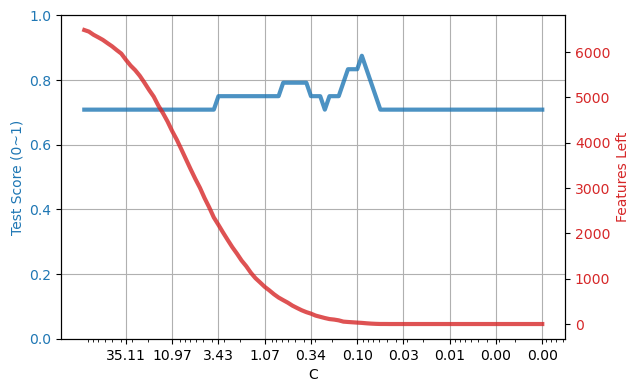

In [89]:
cs = np.logspace(-3,2,num=100)
r3 = ydo_feature_sel_lasso(X,Y1,cs)
fig = plot_test_scores(r3,ret_fig=True)
fig.savefig('report_reply/fig.S10_C1_search.pdf')



100%|███████████████████████████████| 100/100 [01:38<00:00,  1.01it/s]


Filter out all zero features:  (6791, 100)  =>  (189, 100)


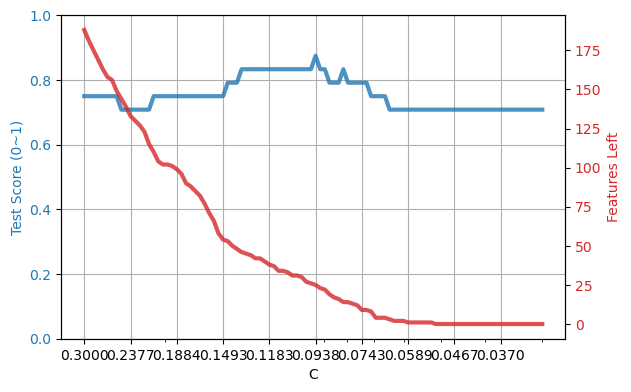

In [76]:
cs = np.logspace(np.log10(0.3),np.log10(0.03),num=100)
r4 = ydo_feature_sel_lasso(X,Y1,cs)
plot_test_scores(r4)



In [79]:
x = r4['summary'][(r4['summary']['features_left']>5)&(r4['summary']['features_left']<50)]
x



,coefs,test_scores,features_left
33,0.13925,0.791667,48
34,0.13605,0.833333,46
35,0.13292,0.833333,45
36,0.12986,0.833333,44
37,0.12688,0.833333,42
38,0.12396,0.833333,42
39,0.12111,0.833333,40
40,0.11833,0.833333,38
41,0.11561,0.833333,37
42,0.11295,0.833333,34


In [80]:
max_v = x.iloc[x['test_scores'].argmax()]['test_scores']
i = r4['test_scores'].loc[r4['test_scores']==max_v].index[-1]
x = r4['coefs'].iloc[:,i]
print(i)
x = x[x!=0].sort_values()
print(len(x))
x

50
25


rna_HTR1B     -0.037469
rna_IER5      -0.033584
prt_PEF1      -0.020966
rna_ATXN1     -0.015278
rna_CNN2      -0.013602
rna_TNFSF9    -0.005212
rna_MEF2C     -0.004777
rna_EGR2      -0.003372
rna_ARHGEF2   -0.001645
rna_CCL2      -0.000883
rna_FBXO9      0.000160
prt_SRSF6      0.000167
rna_ARG2       0.002735
rna_SMARCC1    0.004093
prt_ACAT2      0.004962
rna_PDIA5      0.006740
rna_MAPK9      0.007122
prt_DHRS7      0.009823
rna_SRSF6      0.010636
rna_BASP1      0.012525
rna_CRYBG1     0.016123
rna_RDH11      0.016686
prt_REEP6      0.017657
prt_KRT18      0.028701
rna_ABCC4      0.068658
Name: 0.09377, dtype: float64

In [62]:
final = pd.Series(['MRE11','CANT1','ABCC4','MFAP5','CD8A','GSDME'])
final = 'prt_'+final
final

0    prt_MRE11
1    prt_CANT1
2    prt_ABCC4
3    prt_MFAP5
4     prt_CD8A
5    prt_GSDME
dtype: object

In [112]:
# torun = set(x.index) | set(li)
torun = list(set(x.index))
print(len(torun))
print(torun)


39
['matp_YIPF6', 'matp_GET4', 'matp_CMBL', 'matp_FAM241A', 'matr_PRRX1', 'matp_CRAT', 'matp_ARFIP1', 'matp_PAICS', 'matp_MAST4', 'matr_AXL', 'matp_CPB2', 'matr_TGFBI', 'matp_ALDH6A1', 'matp_RAD23B', 'matp_STAT5A', 'matr_CNN2', 'matp_ACSL1', 'matp_LRBA', 'matp_ARFIP2', 'matr_TGFB1', 'matp_TC2N', 'matp_BAIAP2', 'matp_NUDT9', 'matp_ANKRD28', 'matp_CFI', 'matp_GOLGA4', 'matp_SERPINB1', 'matp_STOM', 'matp_VIM', 'matp_FKBP4', 'matp_SSPN', 'matp_GNL3', 'matp_CANT1', 'matr_LGALS1', 'matp_DCXR', 'matp_LACTB2', 'matr_JAK1', 'matp_C1S', 'matp_TRNT1']


In [113]:
len(list(combinations(torun,1))),len(list(combinations(torun,2))),len(list(combinations(torun,3))),len(list(combinations(torun,4)))


(39, 741, 9139, 82251)

In [114]:

N = 7
xtr = list(range(N))
xte = list(range(N))
ytr = list(range(N))
yte = list(range(N))
for i in range(N):
    xtr[i],xte[i],ytr[i],yte[i] = train_test_split(mat.loc[:,torun],Y1,test_size=0.3
                                                   ,stratify=Y1, random_state=i)


In [115]:
sc = {}
tags = {}
for i in range(1,5):
    if i >= 5:
        break
    g = combinations(torun,i)
    c = 0
    for j in tqdm(g):
        c = c + 1
        tag = "F" + str(i)+ "C" +str(len(j))+'G'+str(c)
        sc[tag] = []
        tags[tag] = j
        for k in range(N):
            lr = LogisticRegression(penalty=None)
            lr.fit(xtr[k].loc[:,j],ytr[k])
            sc[tag].append(lr.score(xte[k].loc[:,j],yte[k]))



39it [00:01, 37.75it/s]
741it [00:20, 36.22it/s]
9139it [04:25, 34.42it/s]


In [116]:
scpd = pd.DataFrame(sc).T

scpd['mean'] = scpd.apply(np.mean,1)
scpd['max'] = scpd.apply(np.max,1)
scpd['g'] = scpd.index.str[:2]
scpd = scpd.sort_values(['mean'],ascending=False)
scpd['pred'] = 'Y1'
scpd



,0,1,2,3,4,5,6,mean,max,g,pred
F3C3G5664,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F3,Y1
F3C3G5651,1.000000,1.000000,1.000000,0.958333,1.000000,1.000000,1.000000,0.994048,1.000000,F3,Y1
F3C3G5825,0.958333,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.994048,1.000000,F3,Y1
F3C3G5578,0.958333,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.994048,1.000000,F3,Y1
F3C3G5820,1.000000,1.000000,1.000000,0.958333,1.000000,1.000000,1.000000,0.994048,1.000000,F3,Y1
...,...,...,...,...,...,...,...,...,...,...,...
F3C3G3313,0.750000,0.875000,0.916667,0.750000,0.708333,0.750000,0.833333,0.797619,0.916667,F3,Y1
F3C3G3327,0.750000,0.833333,0.916667,0.791667,0.750000,0.708333,0.833333,0.797619,0.916667,F3,Y1
F1C1G6,0.750000,0.833333,0.750000,0.791667,0.833333,0.750000,0.833333,0.791667,0.833333,F1,Y1
F1C1G36,0.708333,0.791667,0.791667,0.791667,0.791667,0.833333,0.791667,0.785714,0.833333,F1,Y1


In [117]:
scpd_y1 = scpd
tags_y1 = tags


In [57]:
scpd[scpd['g']=='F1'].head(5)

,0,1,2,3,4,5,6,mean,max,g,pred
F1C1G13,0.958333,0.916667,0.875000,0.916667,0.916667,1.000000,0.916667,0.928571,1.000000,F1,Y1
F1C1G22,0.958333,0.833333,0.875000,0.875000,0.958333,0.958333,0.958333,0.916667,0.958333,F1,Y1
F1C1G1,0.875000,0.833333,0.875000,0.916667,0.916667,0.916667,0.958333,0.898810,0.958333,F1,Y1
F1C1G36,0.791667,0.833333,0.958333,1.000000,0.958333,0.791667,0.916667,0.892857,1.000000,F1,Y1
F1C1G9,0.958333,0.916667,0.875000,0.875000,0.833333,0.916667,0.875000,0.892857,0.958333,F1,Y1


In [58]:
scpd[scpd['g']=='F2'].head(5)

,0,1,2,3,4,5,6,mean,max,g,pred
F2C2G602,1.000000,1.000000,1.000000,1.000000,1.000000,0.958333,1.000000,0.994048,1.0,F2,Y1
F2C2G219,1.000000,0.958333,0.958333,0.958333,0.958333,0.958333,1.000000,0.970238,1.0,F2,Y1
F2C2G19,1.000000,0.958333,0.875000,0.958333,1.000000,1.000000,1.000000,0.970238,1.0,F2,Y1
F2C2G738,0.916667,1.000000,0.958333,0.958333,1.000000,0.958333,0.958333,0.964286,1.0,F2,Y1
F2C2G150,1.000000,1.000000,0.958333,0.958333,0.916667,0.916667,0.958333,0.958333,1.0,F2,Y1


In [59]:
scpd[scpd['g']=='F3'].head(10)


,0,1,2,3,4,5,6,mean,max,g,pred
F3C3G8428,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.0,1.000000,1.0,F3,Y1
F3C3G1860,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.0,1.000000,1.0,F3,Y1
F3C3G7860,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.0,1.000000,1.0,F3,Y1
F3C3G700,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.0,1.000000,1.0,F3,Y1
F3C3G8456,1.0,1.0,1.0,0.958333,1.000000,1.000000,1.0,0.994048,1.0,F3,Y1
F3C3G8378,1.0,1.0,1.0,1.000000,0.958333,1.000000,1.0,0.994048,1.0,F3,Y1
F3C3G8351,1.0,1.0,1.0,1.000000,0.958333,1.000000,1.0,0.994048,1.0,F3,Y1
F3C3G8336,1.0,1.0,1.0,1.000000,1.000000,0.958333,1.0,0.994048,1.0,F3,Y1
F3C3G1230,1.0,1.0,1.0,1.000000,1.000000,0.958333,1.0,0.994048,1.0,F3,Y1
F3C3G8167,1.0,1.0,1.0,1.000000,0.958333,1.000000,1.0,0.994048,1.0,F3,Y1


In [60]:
scpd[scpd['g']=='F4'].head(5)


,0,1,2,3,4,5,6,mean,max,g,pred
F4C4G54844,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,F4,Y1
F4C4G70346,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,F4,Y1
F4C4G79756,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,F4,Y1
F4C4G78508,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,F4,Y1
F4C4G79748,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,F4,Y1


In [68]:
select = pd.concat([scpd[scpd['g']=='F2'].head(1),scpd[scpd['g']=='F3'].head(10)])

select['features'] = [tags[i] for i in select.index]
select


,0,1,2,3,4,5,6,mean,max,g,pred,features
F2C2G602,1.000000,1.0,0.958333,1.000000,0.916667,1.0,1.0,0.982143,1.0,F2,Y1,"(prt_FKBP4, prt_CPB2)"
F3C3G4831,1.000000,1.0,1.000000,1.000000,1.000000,1.0,1.0,1.000000,1.0,F3,Y1,"(prt_GSDME, prt_GOLGA4, prt_FKBP4)"
F3C3G7860,1.000000,1.0,1.000000,1.000000,1.000000,1.0,1.0,1.000000,1.0,F3,Y1,"(rna_CNN2, prt_FKBP4, prt_CPB2)"
F3C3G8336,1.000000,1.0,1.000000,1.000000,1.000000,1.0,1.0,1.000000,1.0,F3,Y1,"(prt_FKBP4, rna_JAK1, prt_CPB2)"
F3C3G5724,1.000000,1.0,1.000000,1.000000,1.000000,1.0,1.0,1.000000,1.0,F3,Y1,"(rna_PRRX1, prt_FKBP4, prt_CPB2)"
F3C3G8351,0.958333,1.0,1.000000,1.000000,1.000000,1.0,1.0,0.994048,1.0,F3,Y1,"(prt_FKBP4, prt_STAT5A, prt_CPB2)"
F3C3G8950,1.000000,1.0,1.000000,0.958333,1.000000,1.0,1.0,0.994048,1.0,F3,Y1,"(prt_YIPF6, rna_TNC, prt_CPB2)"
F3C3G6156,1.000000,1.0,1.000000,0.958333,1.000000,1.0,1.0,0.994048,1.0,F3,Y1,"(rna_PMS2, prt_YIPF6, prt_CPB2)"
F3C3G8456,0.958333,1.0,1.000000,1.000000,1.000000,1.0,1.0,0.994048,1.0,F3,Y1,"(prt_FKBP4, prt_CPB2, rna_STAT5A)"
F3C3G6075,1.000000,1.0,1.000000,0.958333,1.000000,1.0,1.0,0.994048,1.0,F3,Y1,"(rna_PMS2, prt_FKBP4, prt_CPB2)"


In [61]:
select = pd.concat([scpd[scpd['g']=='F2'].head(1),scpd[scpd['g']=='F3'].head(10),scpd[scpd['g']=='F4'].head(3)])

select['features'] = [tags[i] for i in select.index]
select


,0,1,2,3,4,5,6,mean,max,g,pred,features
F2C2G602,1.0,1.0,1.0,1.000000,1.000000,0.958333,1.0,0.994048,1.0,F2,Y1,"(prt_FKBP4, prt_CPB2)"
F3C3G8428,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.0,1.000000,1.0,F3,Y1,"(prt_FKBP4, prt_ARFIP2, prt_CPB2)"
F3C3G1860,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.0,1.000000,1.0,F3,Y1,"(rna_POLR2H, prt_FKBP4, prt_CPB2)"
F3C3G7860,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.0,1.000000,1.0,F3,Y1,"(rna_CNN2, prt_FKBP4, prt_CPB2)"
F3C3G700,1.0,1.0,1.0,1.000000,1.000000,1.000000,1.0,1.000000,1.0,F3,Y1,"(prt_HSPA9, prt_CPB2, rna_STAT5A)"
F3C3G8456,1.0,1.0,1.0,0.958333,1.000000,1.000000,1.0,0.994048,1.0,F3,Y1,"(prt_FKBP4, prt_CPB2, rna_STAT5A)"
F3C3G8378,1.0,1.0,1.0,1.000000,0.958333,1.000000,1.0,0.994048,1.0,F3,Y1,"(prt_FKBP4, prt_VIM, prt_CPB2)"
F3C3G8351,1.0,1.0,1.0,1.000000,0.958333,1.000000,1.0,0.994048,1.0,F3,Y1,"(prt_FKBP4, prt_STAT5A, prt_CPB2)"
F3C3G8336,1.0,1.0,1.0,1.000000,1.000000,0.958333,1.0,0.994048,1.0,F3,Y1,"(prt_FKBP4, rna_JAK1, prt_CPB2)"
F3C3G1230,1.0,1.0,1.0,1.000000,1.000000,0.958333,1.0,0.994048,1.0,F3,Y1,"(rna_MYH9, prt_FKBP4, prt_CPB2)"


In [224]:
db.exporting(select,'Y1_features.xlsx',outputdir='report_reply/')

[06/29 03:12:30] writing 1 file with 14 lines at 
	[PROJECT_ROOT]/report/Y1_features.xlsx


'[PROJECT_ROOT]/report/Y1_features.xlsx'

In [230]:
label = 'Y1'
tag = 'F3C3G1660'
gs = tags[tag]
anno = colData.copy()
anno['Clin_classification'] = anno[label].apply(lambda i:label if i==1 else 'Others' if i ==0 else 'N/A')


In [43]:
plot_venns(pre_selected,li)



NameError: name 'li' is not defined

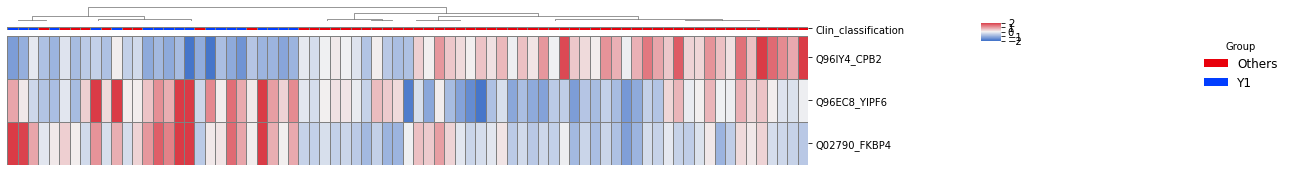

In [231]:
yplot_heatmap_by_input_matrix(mat.loc[:,gs].T, colData=anno , bygroup=False
                                  , export = False,prefix='Y1', suffix='grouped', outputdir=False
                                  , linewidths=0.5, z_score=None, figsize=(14,2.5) )


#### Y2

In [91]:
X = mat
print(X.shape)
X

(77, 6791)


,prt_ALDH1A3,prt_EEF2,prt_PARP2,prt_G3BP2,prt_TALDO1,prt_CD276,prt_CENPA,prt_TGFBR3,prt_FBP2,prt_PPP1R2,...,rna_RIT1,rna_IL4,rna_HSPD1,rna_PTGIS,rna_APAF1,rna_PRPF31,rna_ATOH8,rna_MAP2K3,rna_NCOA3,rna_CEBPD
P01,-0.212800,0.153549,0.651738,-0.534942,0.447499,0.350247,0.600735,0.285934,-0.621983,0.651509,...,-0.232543,0.557734,0.413275,-0.652303,0.041498,0.686165,0.133738,-0.641802,-1.521713,-0.666601
P02,0.293956,0.362157,0.586582,0.921218,0.555920,0.471673,0.397726,0.551119,0.642559,0.137259,...,-0.804450,-1.926081,0.692375,-0.115611,-1.029844,0.124419,0.140187,-0.176381,0.102138,-0.139325
P03,1.655397,-0.710023,-0.612628,-0.932077,0.591117,0.150792,-0.025111,0.111084,-0.474277,-0.745891,...,-0.303087,1.476274,0.352483,0.137755,-0.884535,0.640601,0.157625,-0.667821,-0.327581,-0.283472
P04,0.978973,0.112990,0.319786,-0.043759,-0.884908,-0.197723,-1.093382,0.311538,-1.128822,0.535263,...,-0.586458,-1.926081,0.739161,0.259286,-0.252504,-0.269820,0.389396,0.486931,0.453389,0.236527
P05,0.053302,-0.819178,-0.441027,-1.390742,-0.634150,0.322816,-0.482652,-0.069015,0.377955,-0.485883,...,-0.382927,0.413872,-0.913978,-0.765409,-0.133410,0.254734,0.425187,1.672880,-0.069197,1.511932
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P82,0.259383,-0.060204,0.037451,0.818148,0.830222,0.027776,-0.691326,0.084881,0.980890,-0.064921,...,1.049142,-0.473864,0.678887,0.600208,-0.201504,0.196931,0.433113,-1.562658,0.421076,-0.305507
P83,-0.130302,-0.178181,-1.236305,0.814910,-0.390394,-0.072623,-0.103506,1.197162,-0.703701,0.508569,...,2.316827,-0.657094,-0.400224,-1.054795,-0.857423,0.969901,1.194147,-1.000483,0.035842,1.855239
P84,0.390350,-0.586246,0.109701,-0.019019,0.111234,-0.309501,-1.730414,0.397981,0.187893,-0.697770,...,1.122892,-0.775064,0.613514,0.003092,0.250123,-0.800284,1.551548,-0.049594,-0.401397,0.162537
P85,-1.124114,-0.772634,-1.365593,-0.873349,-1.109722,0.648438,-1.056149,0.209571,0.208564,-0.066332,...,0.229456,-0.025592,0.159771,0.370782,-2.432629,1.916917,2.216953,1.343145,-1.103657,1.502790


In [92]:
Y2 = colData['Y2']
Y2

P01    0
P02    0
P03    0
P04    0
P05    1
      ..
P82    0
P83    0
P84    0
P85    1
P86    1
Name: Y2, Length: 77, dtype: int64

In [93]:
Y2.value_counts()

Y2
0    55
1    22
Name: count, dtype: int64

100%|███████████████████████████████| 100/100 [01:56<00:00,  1.16s/it]


Filter out all zero features:  (6791, 100)  =>  (6656, 100)


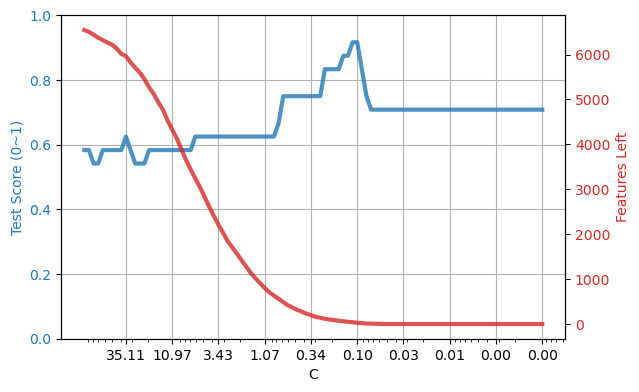

In [94]:
cs = np.logspace(-3,2,num=100)
r5 = ydo_feature_sel_lasso(X,Y2,cs)

plt = plot_test_scores(r5,ret_fig=True)
plt.savefig('report_reply/fig.S10_C2_search.pdf')

100%|███████████████████████████████| 100/100 [01:58<00:00,  1.18s/it]


Filter out all zero features:  (6791, 100)  =>  (6756, 100)


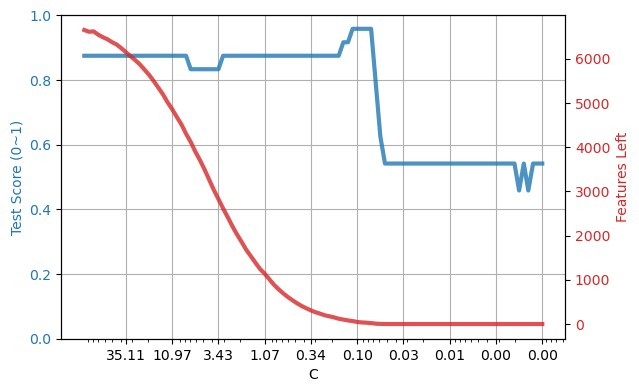

In [73]:
cs = np.logspace(-3,2,num=100)
r5 = ydo_feature_sel_lasso(X,Y2,cs)

plt = plot_test_scores(r5,ret_fig=True)
plt.savefig('report_reply/fig.S10_C2_search.pdf')


100%|███████████████████████████████| 100/100 [02:05<00:00,  1.26s/it]


Filter out all zero features:  (6791, 100)  =>  (161, 100)


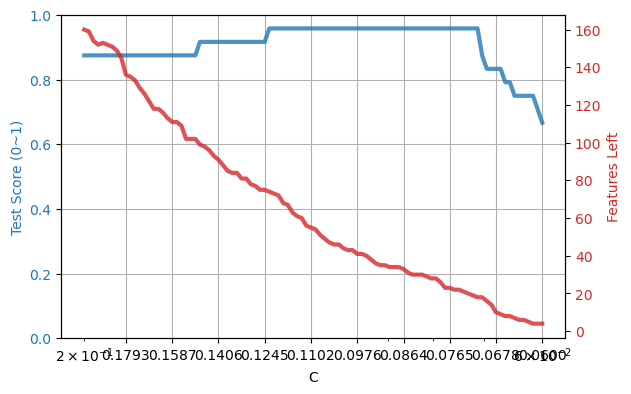

In [80]:
cs = np.logspace(np.log10(0.2), np.log10(0.06),num=100)
r6 = ydo_feature_sel_lasso(X,Y2,cs)
plot_test_scores(r6)


In [86]:
x = r6['summary'][(r6['summary']['features_left']>15)&(r6['summary']['features_left']<40)]
x


,coefs,test_scores,features_left
12,0.06943,0.833333,16
13,0.07028,0.875000,18
14,0.07114,0.958333,18
15,0.07201,0.958333,19
16,0.07290,0.958333,20
17,0.07379,0.958333,21
18,0.07469,0.958333,22
19,0.07560,0.958333,22
20,0.07653,0.958333,23
21,0.07746,0.958333,23


In [87]:
i = x.iloc[x['test_scores'].argmax(),:].name
x = r6['coefs'].iloc[:,i]
x = x[x!=0]
x

prt_CFI        0.002420
prt_MRE11     -0.003213
prt_C1QC       0.001316
prt_C8G        0.008781
prt_CXCL12     0.004042
prt_GPX3       0.005520
prt_CPB2       0.015131
prt_MGP        0.000820
prt_THSD4      0.027101
prt_QSOX1      0.002147
prt_EIF4A2    -0.016260
prt_CPN1       0.043953
prt_GRHPR     -0.010130
prt_C5         0.001206
prt_ARHGEF2    0.001721
prt_RAD50     -0.001948
prt_STAB1      0.006110
prt_CDK9      -0.001056
Name: 0.07114, dtype: float64

In [249]:
torun = set(x.index) | set(li)
torun = set(x.index)
len(torun)

16

In [250]:
len(list(combinations(torun,1))),len(list(combinations(torun,2))),len(list(combinations(torun,3))),len(list(combinations(torun,4)))


(16, 120, 560, 1820)

In [251]:

N = 7
xtr = list(range(N))
xte = list(range(N))
ytr = list(range(N))
yte = list(range(N))
for i in tqdm(range(N)):
    xtr[i],xte[i],ytr[i],yte[i] = train_test_split(mat.loc[:,torun],Y2,test_size=0.3,stratify=Y2)


  0%|          | 0/7 [00:00<?, ?it/s]

In [253]:
sc = {}
tags = {}
for i in range(1,5):
    if i >= 5:
        break
    g = combinations(torun,i)
    c = 0
    for j in tqdm(g):
        c = c + 1
        tag = "F" + str(i)+ "C" +str(len(j))+'G'+str(c)
        sc[tag] = []
        tags[tag] = j
        for k in range(N):
            lr = LogisticRegression(penalty='none')
            lr.fit(xtr[k].loc[:,j],ytr[k])
            sc[tag].append(lr.score(xte[k].loc[:,j],yte[k]))



0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

In [254]:
scpd = pd.DataFrame(sc).T

scpd['mean'] = scpd.apply(np.mean,1)
scpd['max'] = scpd.apply(np.max,1)
scpd['g'] = scpd.index.str[:2]
scpd = scpd.sort_values(['mean'],ascending=False)
scpd['pred'] = 'Y2'
scpd



,0,1,2,3,4,5,6,mean,max,g,pred
F4C4G430,0.958333,1.000000,1.000000,1.000000,0.875000,1.000000,0.958333,0.970238,1.000000,F4,Y2
F4C4G1158,0.958333,1.000000,0.958333,0.916667,0.958333,1.000000,0.916667,0.958333,1.000000,F4,Y2
F4C4G1143,0.958333,0.916667,1.000000,0.958333,0.958333,1.000000,0.916667,0.958333,1.000000,F4,Y2
F4C4G607,0.916667,1.000000,1.000000,0.958333,0.958333,0.916667,0.916667,0.952381,1.000000,F4,Y2
F4C4G1748,1.000000,0.916667,1.000000,1.000000,0.916667,0.916667,0.916667,0.952381,1.000000,F4,Y2
...,...,...,...,...,...,...,...,...,...,...,...
F2C2G49,0.833333,0.750000,0.791667,0.666667,0.750000,0.750000,0.708333,0.750000,0.833333,F2,Y2
F1C1G11,0.750000,0.750000,0.791667,0.666667,0.791667,0.708333,0.708333,0.738095,0.791667,F1,Y2
F1C1G4,0.750000,0.708333,0.791667,0.666667,0.750000,0.750000,0.666667,0.726190,0.791667,F1,Y2
F2C2G79,0.666667,0.625000,0.791667,0.666667,0.791667,0.666667,0.791667,0.714286,0.791667,F2,Y2


In [255]:
scpd_y2 = scpd
tags_y2 = tags


In [142]:
# scpd = scpd_y2
# tags = tags_y2

In [551]:
scpd[scpd['g']=='F1'].head(5)

,0,1,2,3,4,5,6,mean,max,g,pred
F1C1G14,0.958333,1.000000,0.833333,0.833333,0.750000,0.916667,0.833333,0.875000,1.000000,F1,Y2
F1C1G12,0.916667,0.833333,0.875000,0.875000,0.791667,0.750000,0.875000,0.845238,0.916667,F1,Y2
F1C1G5,0.791667,0.833333,0.875000,0.833333,0.833333,0.875000,0.791667,0.833333,0.875000,F1,Y2
F1C1G8,0.750000,0.791667,0.958333,0.791667,0.791667,0.791667,0.875000,0.821429,0.958333,F1,Y2
F1C1G15,0.833333,0.833333,0.875000,0.750000,0.833333,0.750000,0.791667,0.809524,0.875000,F1,Y2


In [552]:
scpd[scpd['g']=='F2'].head(5)

,0,1,2,3,4,5,6,mean,max,g,pred
F2C2G112,0.958333,0.916667,1.000000,1.000000,0.833333,0.875000,0.958333,0.934524,1.000000,F2,Y2
F2C2G115,0.958333,0.916667,0.958333,0.958333,0.833333,0.916667,0.958333,0.928571,0.958333,F2,Y2
F2C2G39,0.916667,0.916667,1.000000,0.958333,0.791667,0.875000,0.916667,0.910714,1.000000,F2,Y2
F2C2G91,0.958333,0.916667,0.916667,0.833333,0.958333,0.875000,0.916667,0.910714,0.958333,F2,Y2
F2C2G103,0.833333,0.916667,0.958333,0.916667,0.875000,0.958333,0.916667,0.910714,0.958333,F2,Y2


In [553]:
scpd[scpd['g']=='F3'].head(10)

,0,1,2,3,4,5,6,mean,max,g,pred
F3C3G88,0.916667,0.958333,1.000000,0.958333,0.958333,0.916667,0.916667,0.946429,1.0,F3,Y2
F3C3G257,0.958333,1.000000,1.000000,0.916667,0.875000,0.916667,0.958333,0.946429,1.0,F3,Y2
F3C3G532,0.916667,0.916667,1.000000,1.000000,0.916667,0.833333,1.000000,0.940476,1.0,F3,Y2
F3C3G558,0.958333,0.916667,0.958333,1.000000,0.875000,0.916667,0.916667,0.934524,1.0,F3,Y2
F3C3G551,0.958333,0.916667,1.000000,1.000000,0.833333,0.875000,0.958333,0.934524,1.0,F3,Y2
F3C3G542,0.958333,0.916667,1.000000,1.000000,0.833333,0.875000,0.958333,0.934524,1.0,F3,Y2
F3C3G195,1.000000,0.958333,0.958333,0.958333,0.833333,0.916667,0.875000,0.928571,1.0,F3,Y2
F3C3G273,1.000000,0.958333,0.958333,0.958333,0.833333,0.875000,0.916667,0.928571,1.0,F3,Y2
F3C3G100,1.000000,0.875000,1.000000,1.000000,0.833333,0.916667,0.875000,0.928571,1.0,F3,Y2
F3C3G390,0.916667,0.916667,0.916667,0.916667,0.916667,1.000000,0.916667,0.928571,1.0,F3,Y2


In [554]:
scpd[scpd['g']=='F4'].head(5)

,0,1,2,3,4,5,6,mean,max,g,pred
F4C4G430,0.958333,1.000000,1.000000,1.000000,0.875000,1.000000,0.958333,0.970238,1.0,F4,Y2
F4C4G1158,0.958333,1.000000,0.958333,0.916667,0.958333,1.000000,0.916667,0.958333,1.0,F4,Y2
F4C4G1143,0.958333,0.916667,1.000000,0.958333,0.958333,1.000000,0.916667,0.958333,1.0,F4,Y2
F4C4G607,0.916667,1.000000,1.000000,0.958333,0.958333,0.916667,0.916667,0.952381,1.0,F4,Y2
F4C4G1748,1.000000,0.916667,1.000000,1.000000,0.916667,0.916667,0.916667,0.952381,1.0,F4,Y2


In [555]:
select = pd.concat([scpd[scpd['g']=='F2'].head(1),scpd[scpd['g']=='F3'].head(10),scpd[scpd['g']=='F4'].head(1)])

select['features'] = [tags[i] for i in select.index]
select

,0,1,2,3,4,5,6,mean,max,g,pred,features
F2C2G112,0.958333,0.916667,1.000000,1.000000,0.833333,0.875000,0.958333,0.934524,1.0,F2,Y2,"(P15169_CPN1, P05156_CFI)"
F3C3G88,0.916667,0.958333,1.000000,0.958333,0.958333,0.916667,0.916667,0.946429,1.0,F3,Y2,"(Q92974_ARHGEF2, Q6ZMP0_THSD4, P05156_CFI)"
F3C3G257,0.958333,1.000000,1.000000,0.916667,0.875000,0.916667,0.958333,0.946429,1.0,F3,Y2,"(P02747_C1QC, Q6ZMP0_THSD4, P05156_CFI)"
F3C3G532,0.916667,0.916667,1.000000,1.000000,0.916667,0.833333,1.000000,0.940476,1.0,F3,Y2,"(Q6ZMP0_THSD4, P15169_CPN1, P05156_CFI)"
F3C3G558,0.958333,0.916667,0.958333,1.000000,0.875000,0.916667,0.916667,0.934524,1.0,F3,Y2,"(Q14240_EIF4A2, P05156_CFI, Q9NY15_STAB1)"
...,...,...,...,...,...,...,...,...,...,...,...,...
F3C3G195,1.000000,0.958333,0.958333,0.958333,0.833333,0.916667,0.875000,0.928571,1.0,F3,Y2,"(P49959_MRE11, P05156_CFI, Q9NY15_STAB1)"
F3C3G273,1.000000,0.958333,0.958333,0.958333,0.833333,0.875000,0.916667,0.928571,1.0,F3,Y2,"(P02747_C1QC, P05156_CFI, Q9NY15_STAB1)"
F3C3G100,1.000000,0.875000,1.000000,1.000000,0.833333,0.916667,0.875000,0.928571,1.0,F3,Y2,"(Q92974_ARHGEF2, Q14240_EIF4A2, P05156_CFI)"
F3C3G390,0.916667,0.916667,0.916667,0.916667,0.916667,1.000000,0.916667,0.928571,1.0,F3,Y2,"(Q9UBQ7_GRHPR, Q14240_EIF4A2, P05156_CFI)"


In [330]:
db.exporting(select,'Y2_features.xlsx',outputdir='report_reply/report_2914/')

[06/30 03:23:32] overwritting 1 file with 12 lines at 
	[PROJECT_ROOT]/report_2914/Y2_features.xlsx


'[PROJECT_ROOT]/report_2914/Y2_features.xlsx'

In [590]:
label = 'Y2'
tag = 'F3C3G88'
gs = tags[tag]
anno = colData.copy()
anno['Clin_classification'] = anno[label].apply(lambda i:label if i==1 else 'Others' if i ==0 else 'N/A')


In [591]:
gs

('Q92974_ARHGEF2', 'Q6ZMP0_THSD4', 'P05156_CFI')

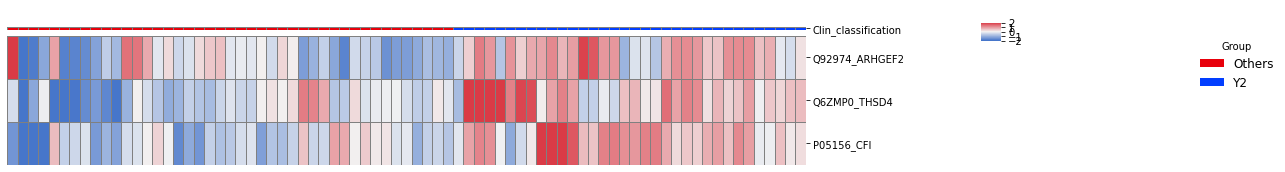

In [592]:

yplot_heatmap_by_input_matrix(mat.loc[:,gs].T, colData=anno , bygroup=True
                                  , export = False,prefix=label, suffix='grouped', outputdir='report_reply/'
                                  , linewidths=0.5, z_score=None, figsize=(14,2.5) )


In [586]:

label = 'Y2'
tag = 'F3C3G257'
gs = tags[tag]
anno = colData.copy()
anno['Clin_classification'] = anno[label].apply(lambda i:label if i==1 else 'Others' if i ==0 else 'N/A')


In [588]:
gs

('P02747_C1QC', 'Q6ZMP0_THSD4', 'P05156_CFI')

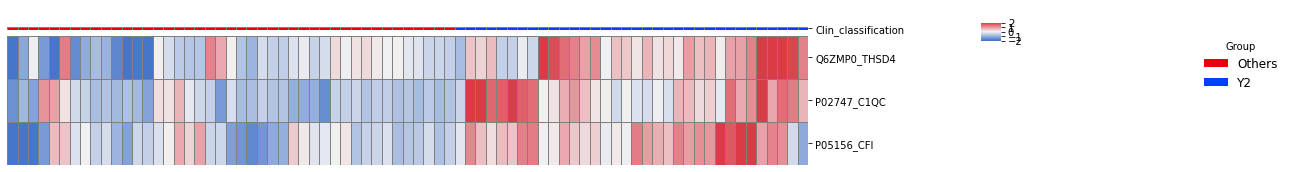

In [587]:

yplot_heatmap_by_input_matrix(mat.loc[:,gs].T, colData=anno , bygroup=True
                                  , export = False,prefix=label, suffix='grouped', outputdir='report_reply/'
                                  , linewidths=0.5, z_score=None, figsize=(14,2.5) )


In [264]:
label

'Y2'

report_2914//heatMap_Y2_F2C2G5_grouped.pdf
report_2914//heatMap_Y2_F2C2G5_free.pdf
report_2914//heatMap_Y2_F3C3G18_grouped.pdf
report_2914//heatMap_Y2_F3C3G18_free.pdf
report_2914//heatMap_Y2_F3C3G31_grouped.pdf
report_2914//heatMap_Y2_F3C3G31_free.pdf
report_2914//heatMap_Y2_F3C3G25_grouped.pdf
report_2914//heatMap_Y2_F3C3G25_free.pdf
report_2914//heatMap_Y2_F3C3G32_grouped.pdf
report_2914//heatMap_Y2_F3C3G32_free.pdf
report_2914//heatMap_Y2_F3C3G4_grouped.pdf
report_2914//heatMap_Y2_F3C3G4_free.pdf
report_2914//heatMap_Y2_F3C3G36_grouped.pdf
report_2914//heatMap_Y2_F3C3G36_free.pdf
report_2914//heatMap_Y2_F3C3G20_grouped.pdf
report_2914//heatMap_Y2_F3C3G20_free.pdf
report_2914//heatMap_Y2_F3C3G3_grouped.pdf
report_2914//heatMap_Y2_F3C3G3_free.pdf
report_2914//heatMap_Y2_F3C3G30_grouped.pdf
report_2914//heatMap_Y2_F3C3G30_free.pdf


[python_env]/lib/pythonX/site-packages/seaborn/matrix.py:805: RuntimeWarning:

More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).



report_2914//heatMap_Y2_F3C3G12_grouped.pdf
report_2914//heatMap_Y2_F3C3G12_free.pdf
report_2914//heatMap_Y2_F4C4G86_grouped.pdf
report_2914//heatMap_Y2_F4C4G86_free.pdf


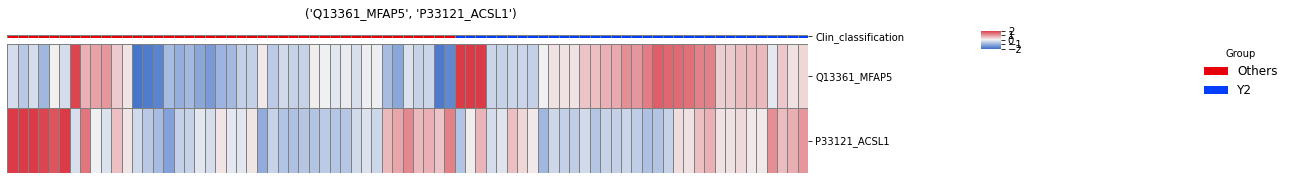

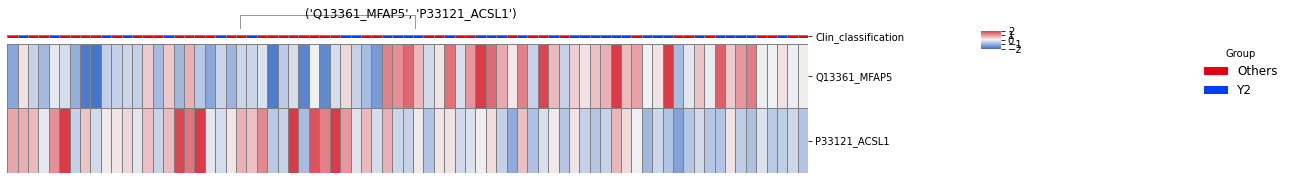

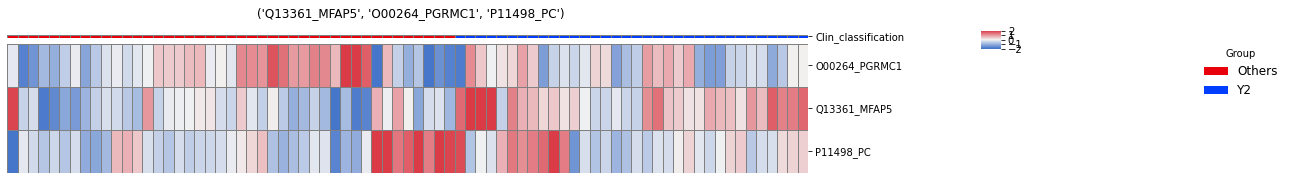

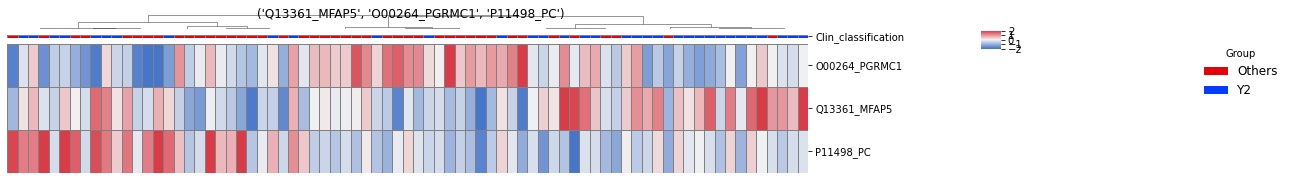

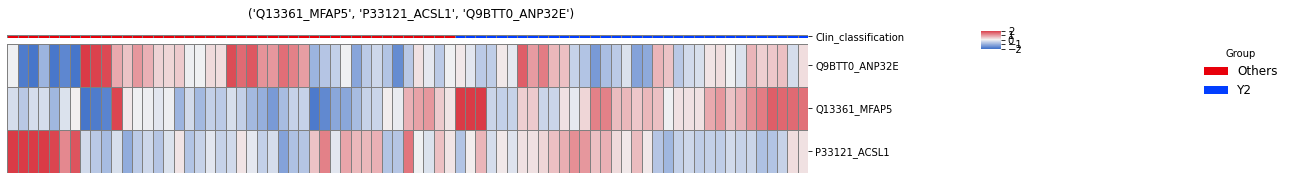

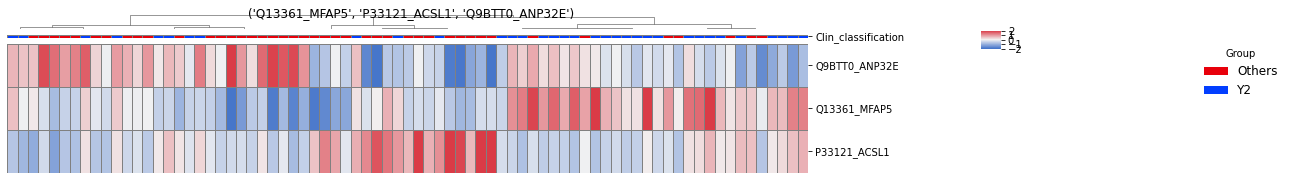

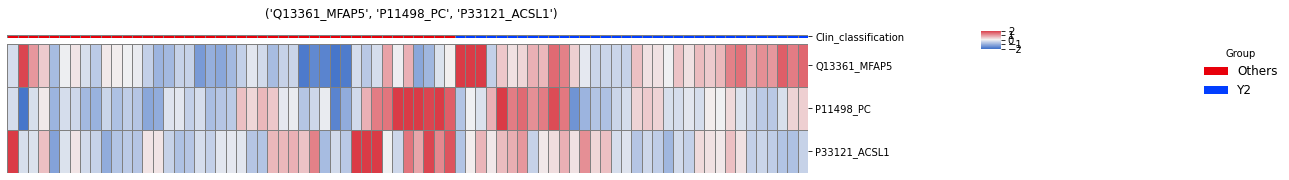

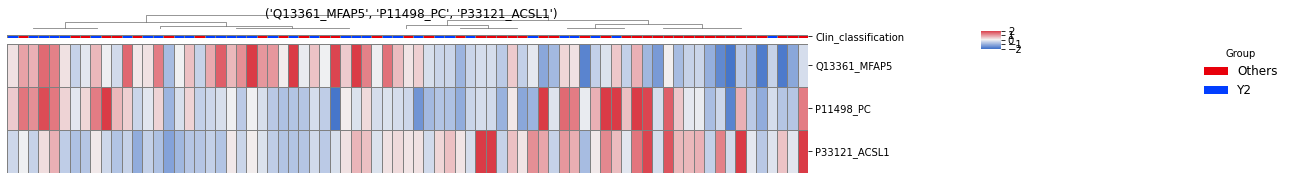

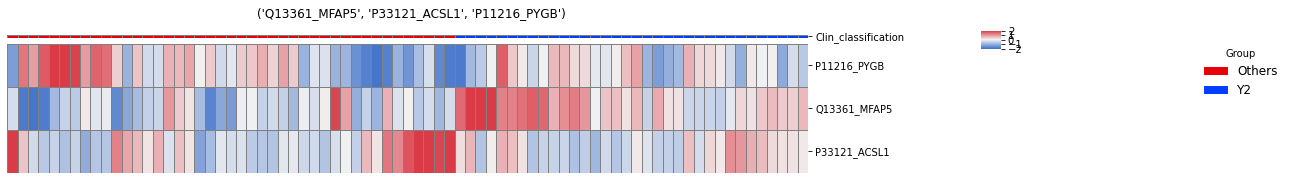

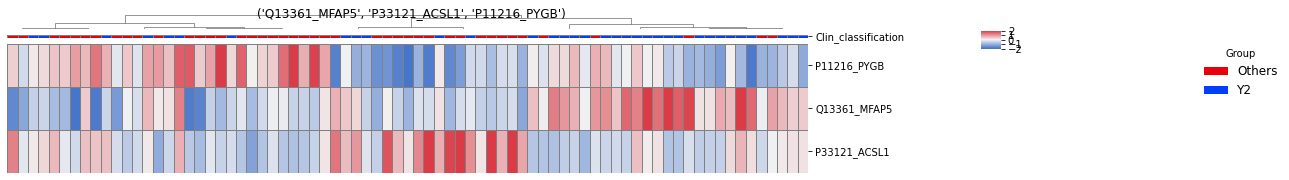

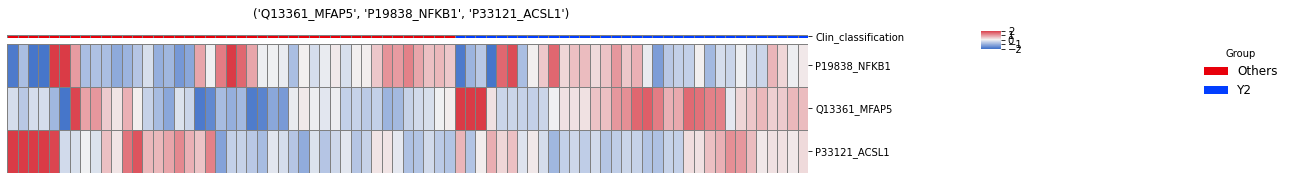

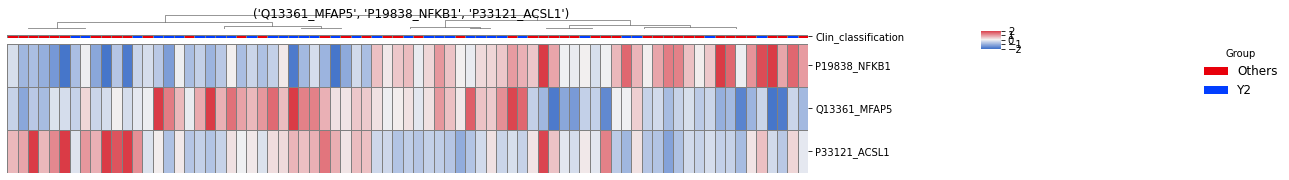

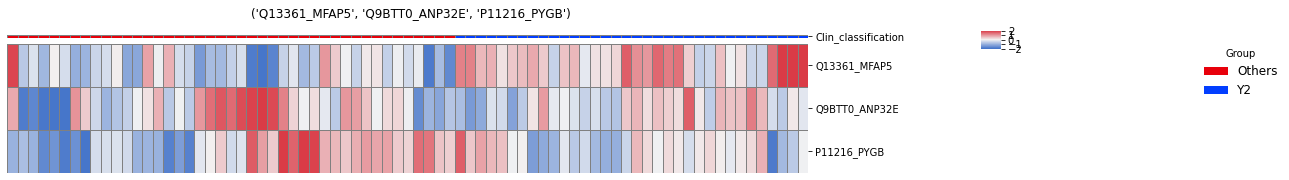

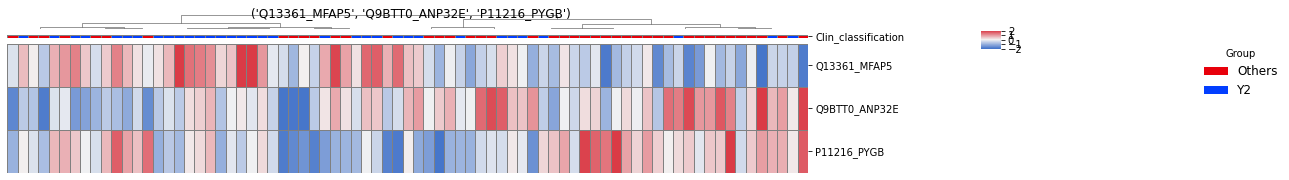

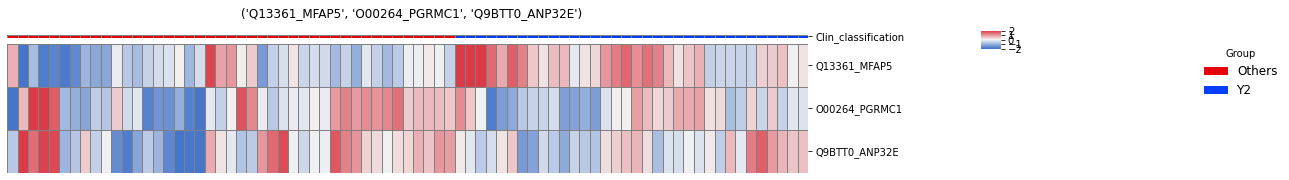

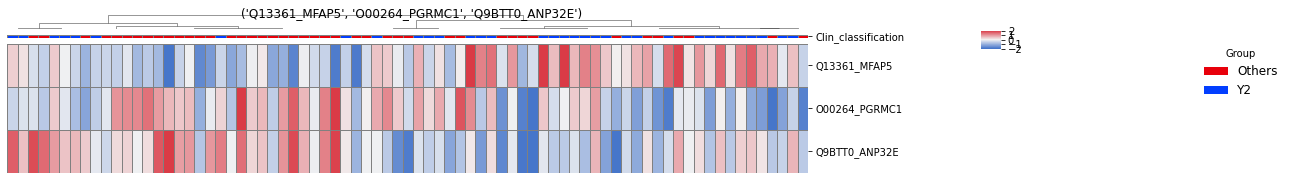

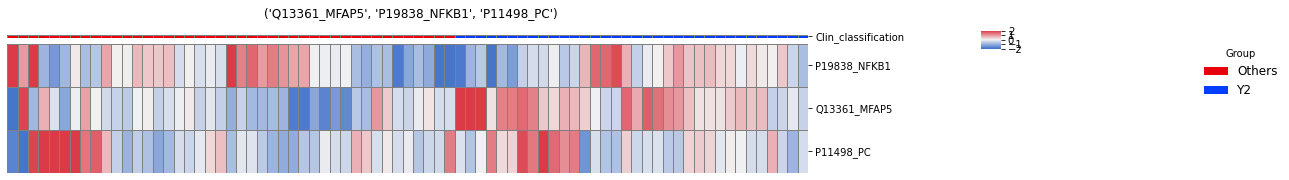

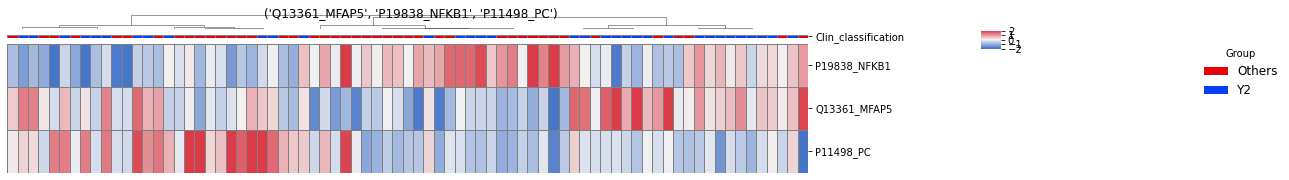

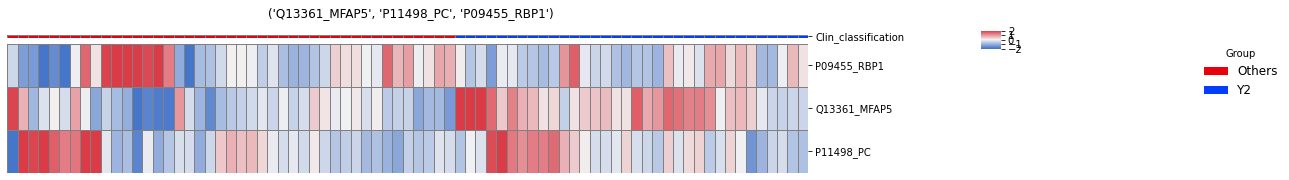

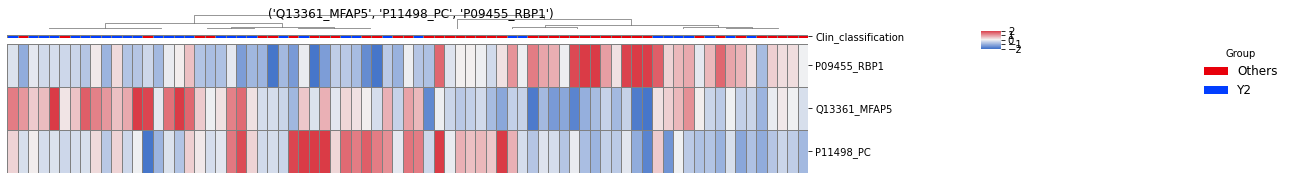

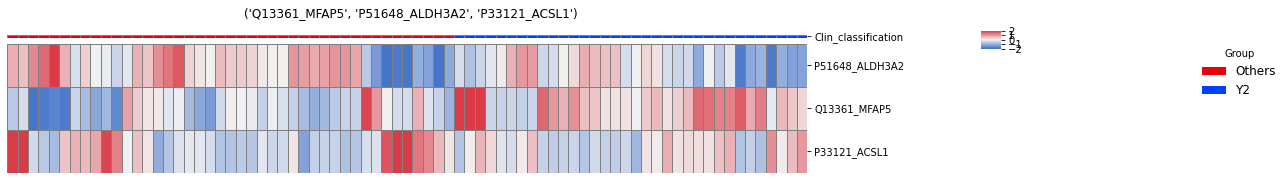

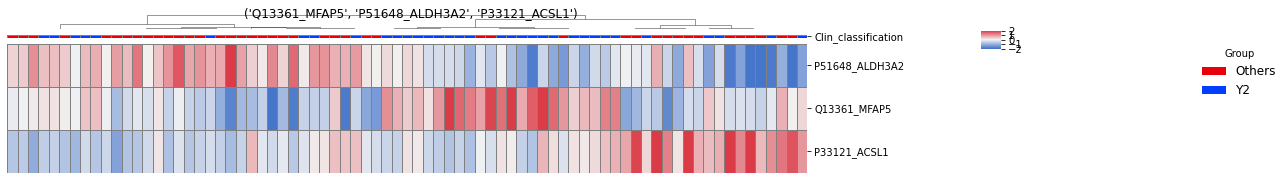

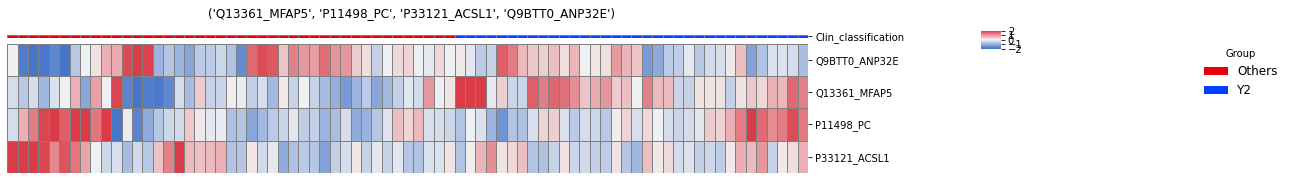

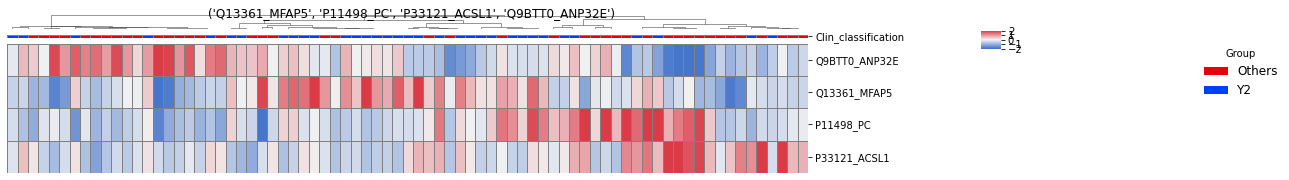

In [329]:
for i in select.index:# man choice: best
    gs = tags[i]
    yplot_heatmap_by_input_matrix(mat.loc[:,gs].T, colData=anno , bygroup=True, title = str(gs)
                                  , export = i,prefix=label, suffix='grouped', outputdir='report_reply/report_2914/'
                                  , linewidths=0.5, z_score=None, figsize=(14,2.5) )
    yplot_heatmap_by_input_matrix(mat.loc[:,gs].T, colData=anno , bygroup=False, title = str(gs)
                                  , export = i,prefix=label, suffix='free', outputdir='report_reply/report_2914/'
                                  , linewidths=0.5, z_score=None, figsize=(14,2.5) )
    
    
    

#### Yo

In [266]:
Yo = colData['Yo']
Yo

P01    1
P02    0
P03    1
P04    0
P05    0
      ..
P82    0
P83    0
P84    0
P85    0
P86    0
Name: Yo, Length: 77, dtype: int64

In [267]:
Yo.value_counts()

0    53
1    24
Name: Yo, dtype: int64

In [268]:
X.shape

(77, 2627)

  0%|          | 0/100 [00:00<?, ?it/s]

Filter out all zero features:  (2627, 100)  =>  (2612, 100)


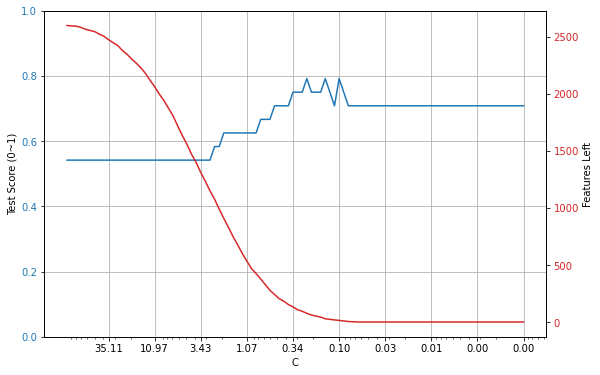

In [269]:
cs = np.logspace(-3,2,num=100)
r7 = ydo_feature_sel_lasso(X,Yo,cs)

plt = plot_test_scores(r7,ret_fig=True)
plt.savefig('report_reply/COthers_search.pdf')



(-0.6989700043360187, -1.2218487496163564)

  0%|          | 0/100 [00:00<?, ?it/s]

Filter out all zero features:  (2627, 100)  =>  (57, 100)


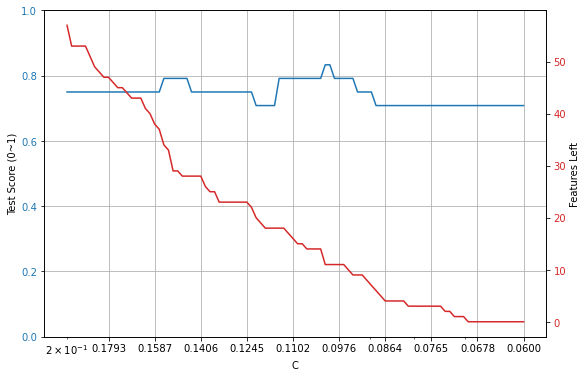

In [271]:
cs = np.logspace(np.log10(0.06),np.log10(0.2),num=100)
r8 = ydo_feature_sel_lasso(X,Yo,cs)
plot_test_scores(r8)


In [272]:
x = r8['summary'][(r8['summary']['features_left']>10)&(r8['summary']['features_left']<17)]
x


,coefs,test_scores,features_left
39,0.09641,0.791667,11
40,0.09759,0.791667,11
41,0.09879,0.791667,11
42,0.10000,0.833333,11
43,0.10122,0.833333,11
44,0.10246,0.791667,14
45,0.10371,0.791667,14
46,0.10498,0.791667,14
47,0.10626,0.791667,14
48,0.10756,0.791667,15


In [273]:
i = x.iloc[x['test_scores'].argmax(),:].name
x = r8['coefs'].iloc[:,i]
x = x[x!=0]
x

O00264_PGRMC1     0.008092
P09455_RBP1       0.039864
P09471_GNAO1      0.002946
P11216_PYGB       0.021077
P11498_PC        -0.011960
P19838_NFKB1      0.031762
P33121_ACSL1     -0.006508
P51648_ALDH3A2    0.002258
Q13361_MFAP5     -0.013847
Q15061_WDR43     -0.031745
Q9BTT0_ANP32E     0.010552
Name: 0.1, dtype: float64

In [274]:
torun = set(x.index) | set(li)
torun = set(x.index) 
len(torun)

11

In [275]:

N = 7
xtr = list(range(N))
xte = list(range(N))
ytr = list(range(N))
yte = list(range(N))
for i in tqdm(range(N)):
    xtr[i],xte[i],ytr[i],yte[i] = train_test_split(mat.loc[:,torun],Yo,test_size=0.3,stratify=Y2)


  0%|          | 0/7 [00:00<?, ?it/s]

In [276]:
len(list(combinations(torun,1))),len(list(combinations(torun,2))),len(list(combinations(torun,3))),len(list(combinations(torun,4)))


(11, 55, 165, 330)

In [277]:
sc = {}
tags = {}
for i in range(1,5):
    if i == 5:
        break
    g = combinations(torun,i)
    c = 0
    for j in tqdm(g):
        c = c + 1
        tag = "F" + str(i)+ "C" +str(len(j))+'G'+str(c)
        sc[tag] = []
        tags[tag] = j
        for k in range(N):
            lr = LogisticRegression(penalty='none')
            lr.fit(xtr[k].loc[:,j],ytr[k])
            sc[tag].append(lr.score(xte[k].loc[:,j],yte[k]))



0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

In [278]:
scpd = pd.DataFrame(sc).T

scpd['mean'] = scpd.apply(np.mean,1)
scpd['max'] = scpd.apply(np.max,1)
scpd['g'] = scpd.index.str[:2]
scpd = scpd.sort_values(['mean'],ascending=False)
scpd['pred'] = 'Yo'
scpd



,0,1,2,3,4,5,6,mean,max,g,pred
F3C3G18,0.833333,0.875000,0.958333,0.833333,1.000000,0.916667,0.916667,0.904762,1.000000,F3,Yo
F4C4G86,0.833333,0.916667,0.875000,0.916667,1.000000,0.916667,0.875000,0.904762,1.000000,F4,Yo
F4C4G37,0.833333,0.875000,0.958333,0.791667,1.000000,0.916667,0.916667,0.898810,1.000000,F4,Yo
F4C4G65,0.833333,0.875000,0.875000,0.875000,1.000000,0.916667,0.875000,0.892857,1.000000,F4,Yo
F3C3G31,0.958333,0.875000,0.875000,0.833333,0.958333,0.875000,0.875000,0.892857,0.958333,F3,Yo
...,...,...,...,...,...,...,...,...,...,...,...
F4C4G249,0.625000,0.625000,0.791667,0.666667,0.791667,0.750000,0.708333,0.708333,0.791667,F4,Yo
F2C2G43,0.666667,0.708333,0.666667,0.666667,0.750000,0.708333,0.708333,0.696429,0.750000,F2,Yo
F4C4G213,0.666667,0.625000,0.708333,0.666667,0.708333,0.666667,0.791667,0.690476,0.791667,F4,Yo
F4C4G284,0.625000,0.750000,0.708333,0.666667,0.708333,0.666667,0.708333,0.690476,0.750000,F4,Yo


In [279]:
scpd_yo = scpd
tags_yo = tags


In [164]:
# scpd = scpd_yo
# tags = tags_yo


In [280]:
scpd[scpd['g']=='F1'].head(5)

,0,1,2,3,4,5,6,mean,max,g,pred
F1C1G5,0.833333,0.833333,0.875000,0.625000,0.875000,0.791667,0.791667,0.803571,0.875000,F1,Yo
F1C1G10,0.875000,0.708333,0.875000,0.750000,0.708333,0.791667,0.875000,0.797619,0.875000,F1,Yo
F1C1G4,0.833333,0.708333,0.791667,0.625000,0.958333,0.833333,0.791667,0.791667,0.958333,F1,Yo
F1C1G1,0.833333,0.833333,0.750000,0.708333,0.750000,0.875000,0.750000,0.785714,0.875000,F1,Yo
F1C1G8,0.833333,0.875000,0.750000,0.666667,0.875000,0.750000,0.750000,0.785714,0.875000,F1,Yo


In [281]:
scpd[scpd['g']=='F2'].head(5)

,0,1,2,3,4,5,6,mean,max,g,pred
F2C2G5,0.875000,0.875000,0.875,0.875000,0.916667,0.875000,0.833333,0.875000,0.916667,F2,Yo
F2C2G3,0.916667,0.833333,0.875,0.708333,0.958333,0.916667,0.875000,0.869048,0.958333,F2,Yo
F2C2G9,0.958333,0.833333,0.875,0.750000,0.833333,0.875000,0.875000,0.857143,0.958333,F2,Yo
F2C2G8,0.916667,0.875000,0.750,0.791667,0.875000,0.916667,0.833333,0.851190,0.916667,F2,Yo
F2C2G36,0.833333,0.833333,0.875,0.791667,0.916667,0.833333,0.875000,0.851190,0.916667,F2,Yo


In [282]:
scpd[scpd['g']=='F3'].head(10)


,0,1,2,3,4,5,6,mean,max,g,pred
F3C3G18,0.833333,0.875000,0.958333,0.833333,1.000000,0.916667,0.916667,0.904762,1.000000,F3,Yo
F3C3G31,0.958333,0.875000,0.875000,0.833333,0.958333,0.875000,0.875000,0.892857,0.958333,F3,Yo
F3C3G25,0.833333,0.916667,0.833333,0.875000,0.958333,0.916667,0.875000,0.886905,0.958333,F3,Yo
F3C3G32,0.916667,0.875000,0.875000,0.875000,0.958333,0.916667,0.791667,0.886905,0.958333,F3,Yo
F3C3G4,0.875000,0.875000,0.916667,0.875000,0.958333,0.791667,0.875000,0.880952,0.958333,F3,Yo
F3C3G36,0.916667,0.916667,0.875000,0.750000,0.958333,0.875000,0.875000,0.880952,0.958333,F3,Yo
F3C3G20,0.958333,0.833333,0.875000,0.750000,0.916667,0.875000,0.916667,0.875000,0.958333,F3,Yo
F3C3G3,0.833333,0.916667,0.833333,0.791667,0.958333,0.916667,0.875000,0.875000,0.958333,F3,Yo
F3C3G30,0.791667,0.916667,0.875000,0.833333,1.000000,0.875000,0.833333,0.875000,1.000000,F3,Yo
F3C3G12,0.916667,0.875000,0.875000,0.875000,0.916667,0.833333,0.833333,0.875000,0.916667,F3,Yo


In [283]:
scpd[scpd['g']=='F4'].head(5)


,0,1,2,3,4,5,6,mean,max,g,pred
F4C4G86,0.833333,0.916667,0.875000,0.916667,1.000000,0.916667,0.875000,0.904762,1.000000,F4,Yo
F4C4G37,0.833333,0.875000,0.958333,0.791667,1.000000,0.916667,0.916667,0.898810,1.000000,F4,Yo
F4C4G65,0.833333,0.875000,0.875000,0.875000,1.000000,0.916667,0.875000,0.892857,1.000000,F4,Yo
F4C4G22,0.958333,0.875000,0.875000,0.875000,0.916667,0.875000,0.875000,0.892857,0.958333,F4,Yo
F4C4G104,0.958333,0.833333,0.875000,0.833333,1.000000,0.875000,0.875000,0.892857,1.000000,F4,Yo


In [284]:
select = pd.concat([scpd[scpd['g']=='F2'].head(1),scpd[scpd['g']=='F3'].head(10),scpd[scpd['g']=='F4'].head(1)])

select['features'] = [tags[i] for i in select.index]
select

,0,1,2,3,4,5,6,mean,max,g,pred,features
F2C2G5,0.875000,0.875000,0.875000,0.875000,0.916667,0.875000,0.833333,0.875000,0.916667,F2,Yo,"(Q13361_MFAP5, P33121_ACSL1)"
F3C3G18,0.833333,0.875000,0.958333,0.833333,1.000000,0.916667,0.916667,0.904762,1.000000,F3,Yo,"(Q13361_MFAP5, O00264_PGRMC1, P11498_PC)"
F3C3G31,0.958333,0.875000,0.875000,0.833333,0.958333,0.875000,0.875000,0.892857,0.958333,F3,Yo,"(Q13361_MFAP5, P33121_ACSL1, Q9BTT0_ANP32E)"
F3C3G25,0.833333,0.916667,0.833333,0.875000,0.958333,0.916667,0.875000,0.886905,0.958333,F3,Yo,"(Q13361_MFAP5, P11498_PC, P33121_ACSL1)"
F3C3G32,0.916667,0.875000,0.875000,0.875000,0.958333,0.916667,0.791667,0.886905,0.958333,F3,Yo,"(Q13361_MFAP5, P33121_ACSL1, P11216_PYGB)"
F3C3G4,0.875000,0.875000,0.916667,0.875000,0.958333,0.791667,0.875000,0.880952,0.958333,F3,Yo,"(Q13361_MFAP5, P19838_NFKB1, P33121_ACSL1)"
F3C3G36,0.916667,0.916667,0.875000,0.750000,0.958333,0.875000,0.875000,0.880952,0.958333,F3,Yo,"(Q13361_MFAP5, Q9BTT0_ANP32E, P11216_PYGB)"
F3C3G20,0.958333,0.833333,0.875000,0.750000,0.916667,0.875000,0.916667,0.875000,0.958333,F3,Yo,"(Q13361_MFAP5, O00264_PGRMC1, Q9BTT0_ANP32E)"
F3C3G3,0.833333,0.916667,0.833333,0.791667,0.958333,0.916667,0.875000,0.875000,0.958333,F3,Yo,"(Q13361_MFAP5, P19838_NFKB1, P11498_PC)"
F3C3G30,0.791667,0.916667,0.875000,0.833333,1.000000,0.875000,0.833333,0.875000,1.000000,F3,Yo,"(Q13361_MFAP5, P11498_PC, P09455_RBP1)"


In [285]:
db.exporting(select,'Yo_features.xlsx',outputdir='report_reply/')

[06/29 07:33:42] writing 1 file with 12 lines at 
	[PROJECT_ROOT]/report/Yo_features.xlsx


'[PROJECT_ROOT]/report/Yo_features.xlsx'

In [286]:
label = 'Yo'
tag = 'F3C3G18'
gs = tags[tag]
anno = colData.copy()
anno['Clin_classification'] = anno[label].apply(lambda i:label if i==1 else 'Others' if i ==0 else 'N/A')

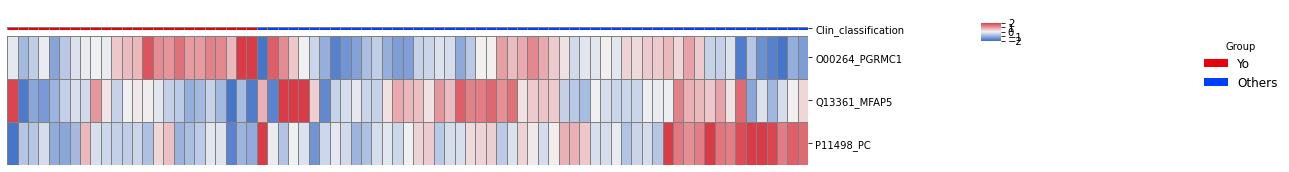

In [287]:
yplot_heatmap_by_input_matrix(mat.loc[:,gs].T, colData=anno , bygroup=True
                                  , export = False,prefix=label, suffix='grouped', outputdir=False
                                  , linewidths=0.5, z_score=None, figsize=(14,2.5) )


report//heatMap_Yo_F2C2G5_grouped.pdf
report//heatMap_Yo_F2C2G5_free.pdf
report//heatMap_Yo_F3C3G18_grouped.pdf
report//heatMap_Yo_F3C3G18_free.pdf
report//heatMap_Yo_F3C3G31_grouped.pdf
report//heatMap_Yo_F3C3G31_free.pdf
report//heatMap_Yo_F3C3G25_grouped.pdf
report//heatMap_Yo_F3C3G25_free.pdf
report//heatMap_Yo_F3C3G32_grouped.pdf
report//heatMap_Yo_F3C3G32_free.pdf
report//heatMap_Yo_F3C3G4_grouped.pdf
report//heatMap_Yo_F3C3G4_free.pdf
report//heatMap_Yo_F3C3G36_grouped.pdf
report//heatMap_Yo_F3C3G36_free.pdf
report//heatMap_Yo_F3C3G20_grouped.pdf
report//heatMap_Yo_F3C3G20_free.pdf
report//heatMap_Yo_F3C3G3_grouped.pdf
report//heatMap_Yo_F3C3G3_free.pdf
report//heatMap_Yo_F3C3G30_grouped.pdf
report//heatMap_Yo_F3C3G30_free.pdf


[python_env]/lib/pythonX/site-packages/seaborn/matrix.py:805: RuntimeWarning:

More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).



report//heatMap_Yo_F3C3G12_grouped.pdf
report//heatMap_Yo_F3C3G12_free.pdf
report//heatMap_Yo_F4C4G86_grouped.pdf
report//heatMap_Yo_F4C4G86_free.pdf


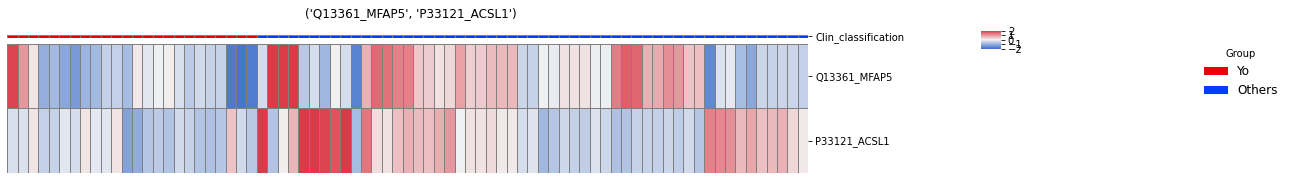

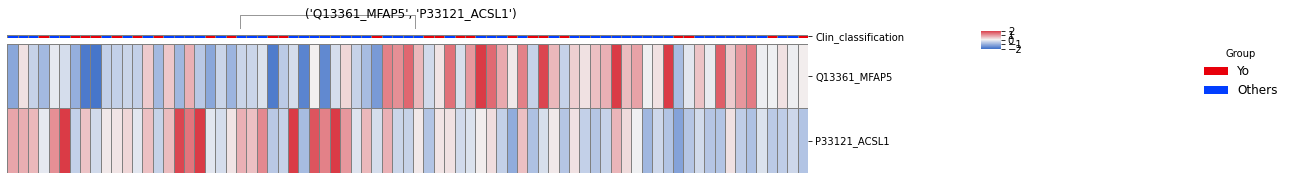

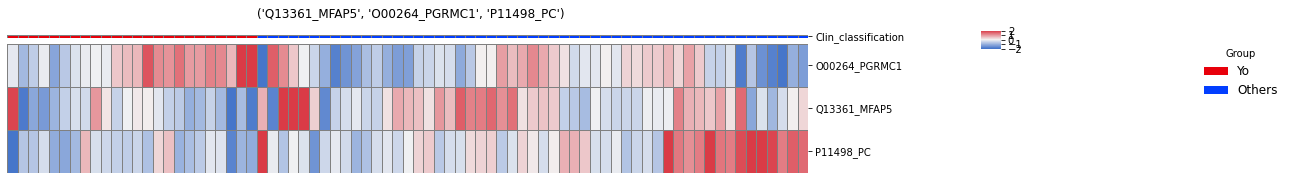

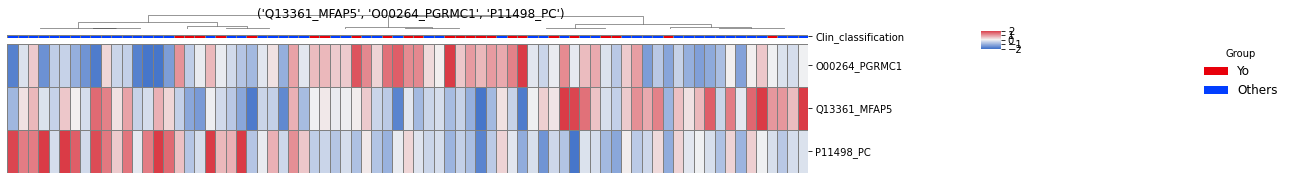

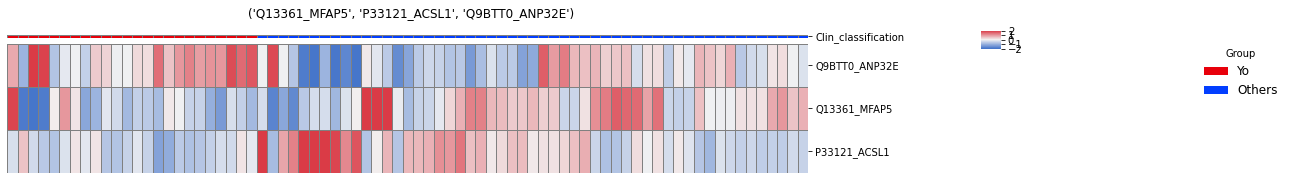

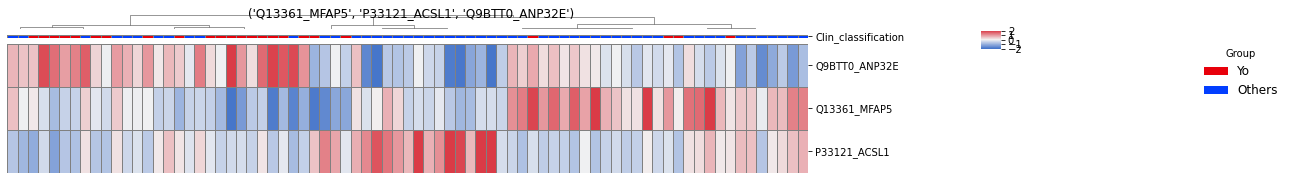

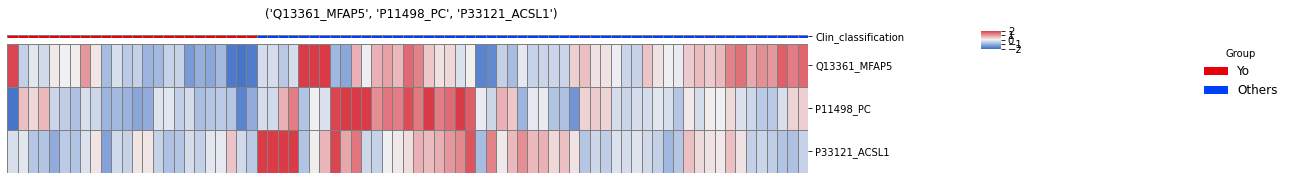

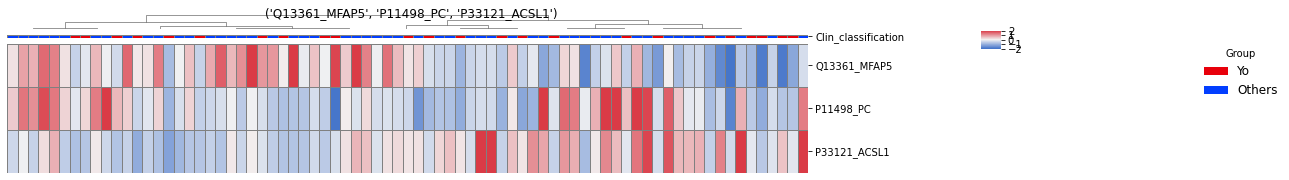

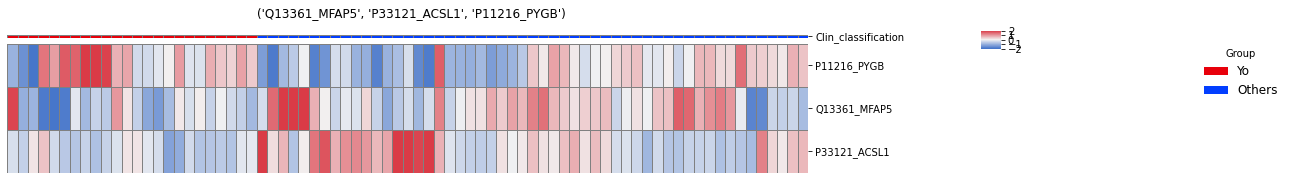

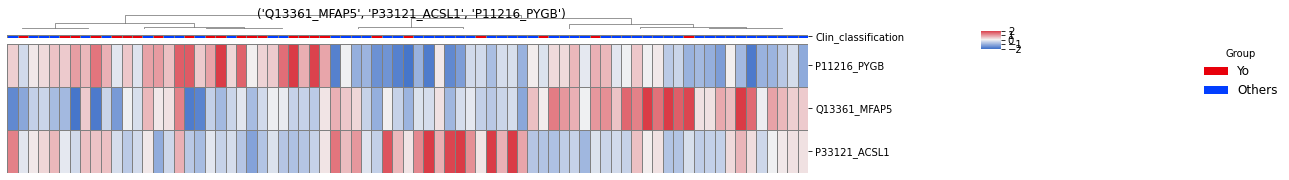

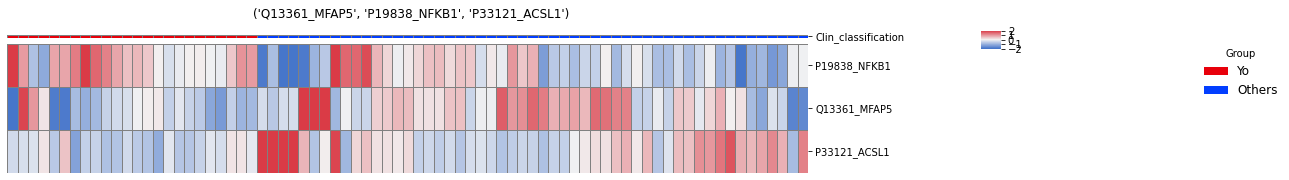

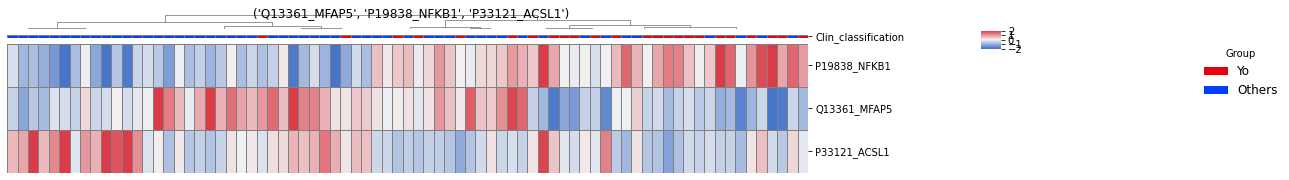

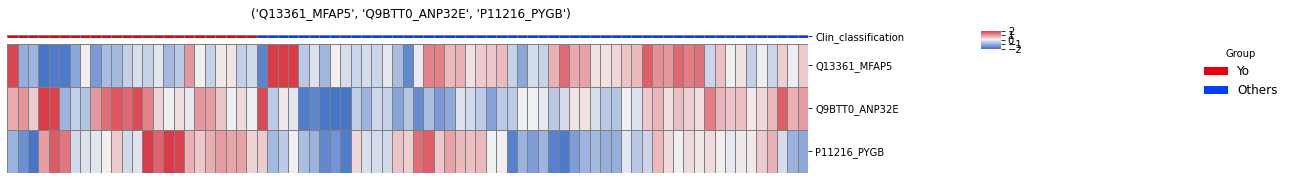

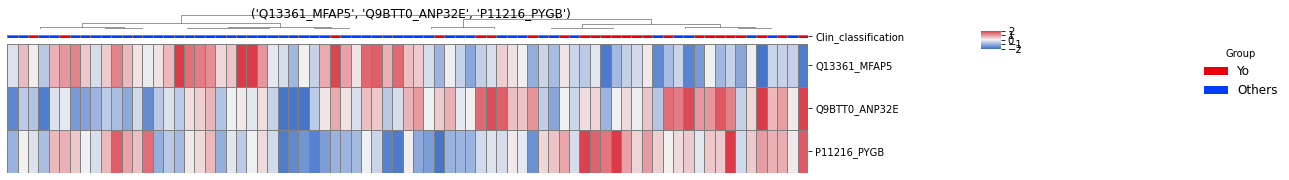

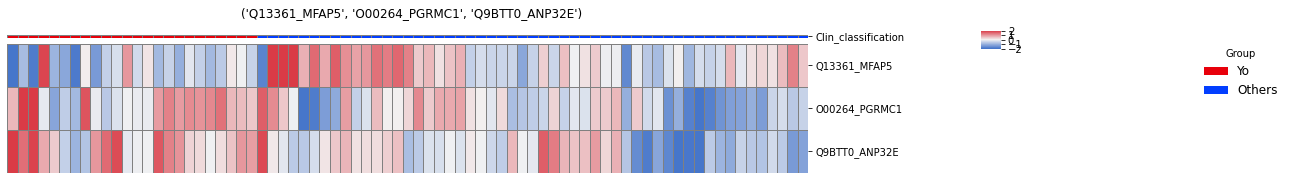

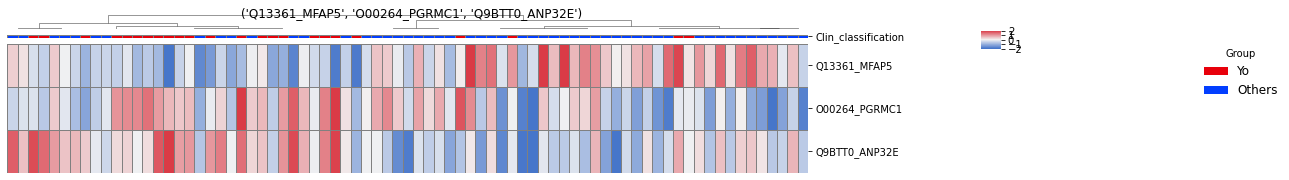

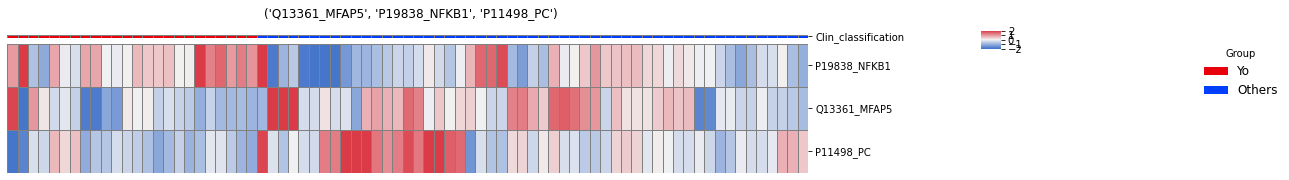

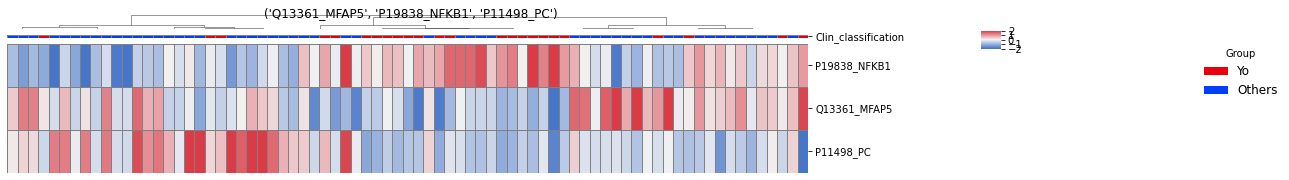

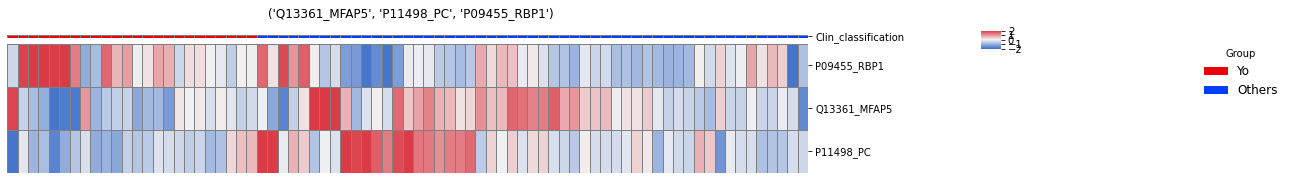

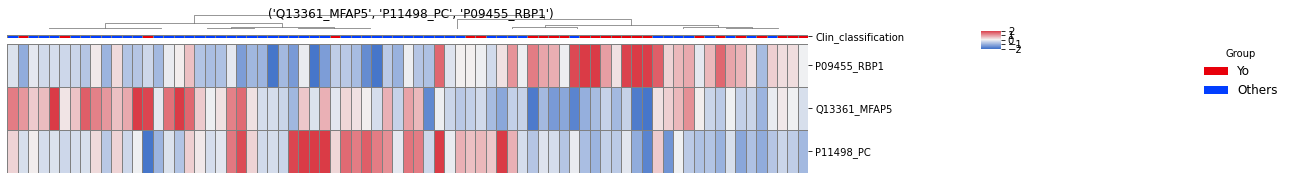

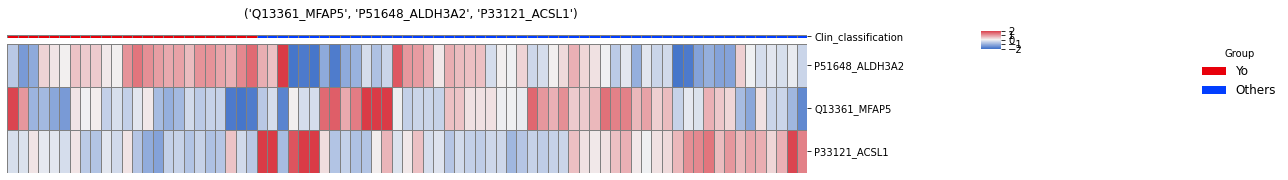

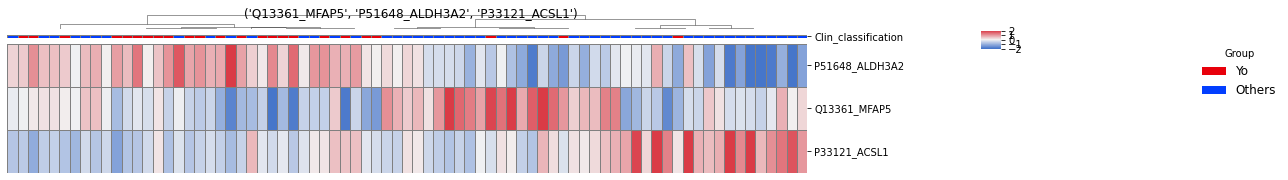

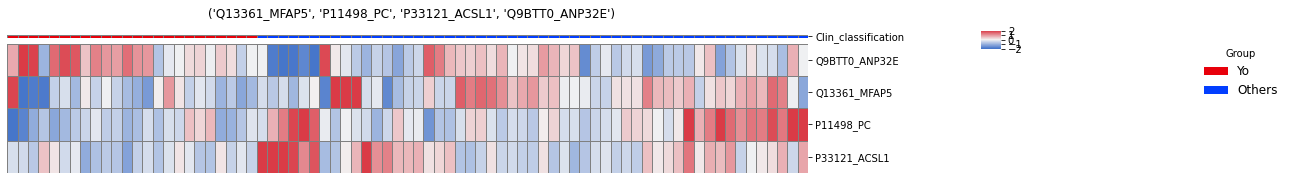

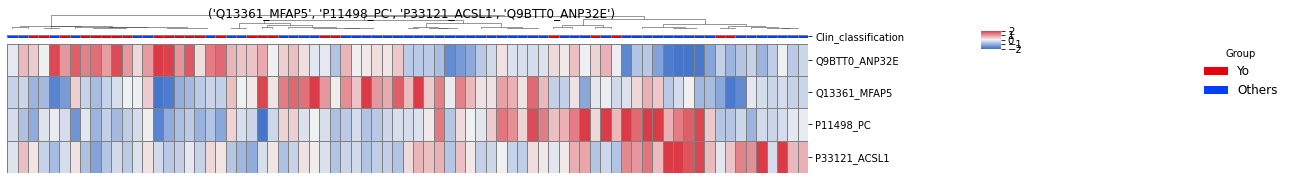

In [288]:
for i in select.index:# man choice: best
    gs = tags[i]
    yplot_heatmap_by_input_matrix(mat.loc[:,gs].T, colData=anno , bygroup=True, title = str(gs)
                                  , export = i,prefix=label, suffix='grouped', outputdir='report_reply/'
                                  , linewidths=0.5, z_score=None, figsize=(14,2.5) )
    yplot_heatmap_by_input_matrix(mat.loc[:,gs].T, colData=anno , bygroup=False, title = str(gs)
                                  , export = i,prefix=label, suffix='free', outputdir='report_reply/'
                                  , linewidths=0.5, z_score=None, figsize=(14,2.5) )
    
    
    

### sum

In [179]:
import pickle 

#### SAVE

In [186]:
# with open('export_old/search_C1C2_all_2914_features.pkl','wb') as fs:
#     pickle.dump([scpd_y1,tags_y1,scpd_y2,tags_y2,scpd_yo,tags_yo],file=fs)

In [315]:
# with open('export_old/search_C1C2_HM_2627_features.pkl','wb') as fs:
#     pickle.dump([scpd_y1,tags_y1,scpd_y2,tags_y2,scpd_yo,tags_yo,r3,r4,r5,r6,r7,r8],file=fs)
    

#### LOAD

In [8]:
ALL = pd.read_pickle('../../export_old/search_C1C2_all_2914_features.pkl')
# # # scpd_y1,tags_y1,scpd_y2,tags_y2,scpd_yo,tags_yo,r3,r4,r5,r6,r7,r8 = ALL
scpd_y1,tags_y1,scpd_y2,tags_y2,scpd_yo,tags_yo = ALL


In [21]:
HM = pd.read_pickle('../../export_old/search_C1C2_HM_2627_features.pkl')
scpd_y1,tags_y1,scpd_y2,tags_y2,scpd_yo,tags_yo,r3,r4,r5,r6,r7,r8 = HM


#### fig S10 (reply) plot Lasso curves

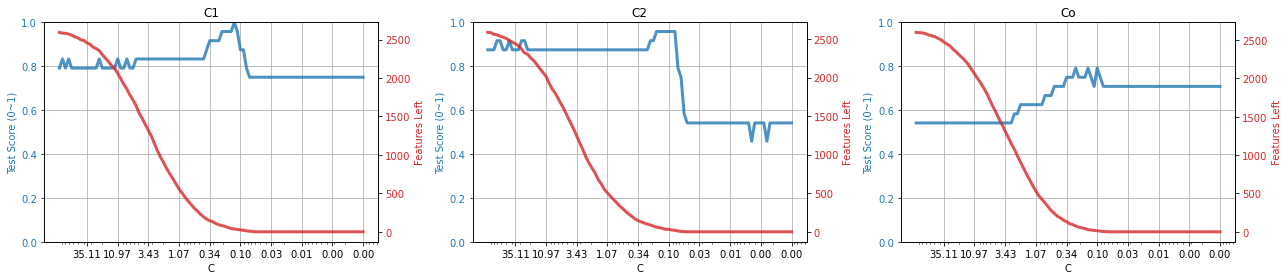

In [384]:
# 一起画
todo = {'C1':r3,'C2':r5,'Co':r7}
fig, axes = plt.subplots(1,3,figsize=(18,4))
axes = axes.flatten()
i = 0
for title, res in todo.items():
    
    alphas = res['coefs'].columns.values
    test_socres = res['test_scores'].values
    if 'features_left' in res:
        features_left = res['features_left']
    else:
        features_left = np.sum(res['coefs'].values != 0,axis=0)
    
    ax1 = axes[i]
    
    ax1.semilogx(alphas, test_socres, linewidth=3, alpha=0.8)
    ax1.set_xscale("log")
    ax1.set_ylabel("Test Score (0~1)",color='tab:blue')
    ax1.set_ylim(0,1)
    ax1.tick_params(axis='y', labelcolor='tab:blue')
    ax1.set_xlabel("C")
    ax1.set_title(title)
#     ax1.get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())

    
#     ax1.get_xaxis().set_major_formatter(LogFormatter())
#     res['best_alpha'] = gcv.best_params_["coxnetsurvivalanalysis__alphas"][0]
#     ax1.axvline(res['best_alpha'], c="C1")
#     ax1.axhline(0.5, color="r", linestyle="-.",)
    ax1.grid(True)
    
    ax2 = ax1.twinx()
    ax2.semilogx(alphas, features_left, color='tab:red', linewidth=3, alpha=0.8)
    ax2.tick_params(axis='y', labelcolor='tab:red')
    ax2.set_ylabel('Features Left', color='tab:red') #, color='tab:red'
    ax1.invert_xaxis()
#     plt.gca().get_xaxis().set_major_locator(LogLocator(numticks=20))
    plt.gca().set_xticks(alphas[::10])
    plt.gca().get_xaxis().set_major_formatter(ScalarFormatter())
    
    i += 1
plt.tight_layout()

In [386]:
fig.savefig('report_reply/fig.S10.LASSO_curves.pdf')

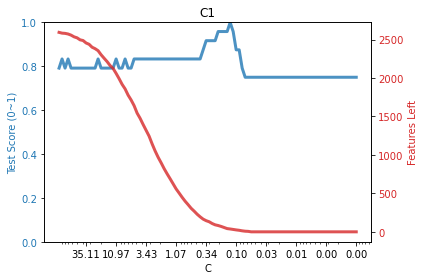

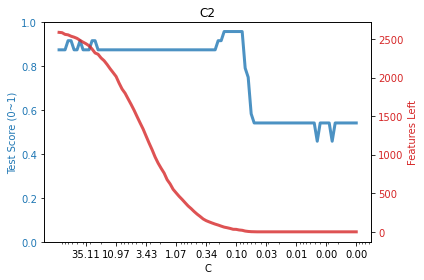

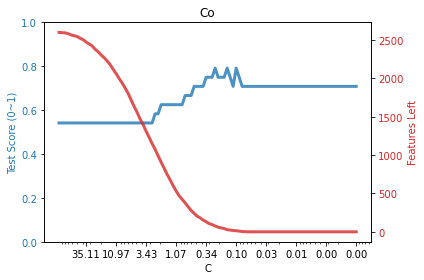

In [420]:
# 分开画
todo = {'C1':r3,'C2':r5,'Co':r7}
for title, res in todo.items():
    
    alphas = res['coefs'].columns.values
    test_socres = res['test_scores'].values
    if 'features_left' in res:
        features_left = res['features_left']
    else:
        features_left = np.sum(res['coefs'].values != 0,axis=0)
    
    fig, ax1 = plt.subplots(figsize=(6,4))
    
    ax1.semilogx(alphas, test_socres, linewidth=3, alpha=0.8)
    ax1.set_xscale("log")
    ax1.set_ylabel("Test Score (0~1)",color='tab:blue')
    ax1.set_ylim(0,1)
    ax1.tick_params(axis='y', labelcolor='tab:blue')
    ax1.set_xlabel("C")
    ax1.set_title(title)

    ax1.grid(False)

    ax2 = ax1.twinx()
    ax2.semilogx(alphas, features_left, color='tab:red', linewidth=3, alpha=0.8)
    ax2.tick_params(axis='y', labelcolor='tab:red')
    ax2.set_ylabel('Features Left', color='tab:red') #, color='tab:red'
    ax1.invert_xaxis()
#     plt.gca().get_xaxis().set_major_locator(LogLocator(numticks=20))
    plt.gca().set_xticks(alphas[::10])
    plt.gca().get_xaxis().set_major_formatter(ScalarFormatter())
    
    plt.tight_layout()

    fig.savefig(f'report_reply/fig.S10.LASSO_{title}.pdf')
    

In [424]:

r3['coefs']


,0.00100,0.00112,0.00126,0.00142,0.00159,0.00179,0.00201,0.00226,0.00254,0.00285,...,35.11192,39.44206,44.30621,49.77024,55.90810,62.80291,70.54802,79.24829,89.02151,100.00000
A1A4S6_ARHGAP10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.004767,0.005144,0.005025,0.004962,0.004829,0.005124,0.005423,0.005168,0.005203,0.005087
A1L0T0_ILVBL,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.005292,0.005355,0.005511,0.005371,0.005660,0.005677,0.005399,0.005482,0.005765,0.005467
A8MXV4_NUDT19,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.004062,-0.004021,-0.004267,-0.004178,-0.004230,-0.004199,-0.003866,-0.004318,-0.004331,-0.004257
O00139_KIF2A,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.003418,0.003611,0.003454,0.003651,0.003434,0.003813,0.003710,0.003708,0.003868,0.003684
O00142_TK2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.005430,0.005681,0.005668,0.005698,0.005273,0.005962,0.005724,0.006149,0.005758,0.005882
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Q9Y6M5_SLC30A1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.000082,-0.000011,-0.000233,-0.000110,-0.000290,-0.000180,0.000000,-0.000493,-0.000304,-0.000320
Q9Y6N5_SQOR,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.007708,-0.007775,-0.007804,-0.007916,-0.007596,-0.007882,-0.008202,-0.007882,-0.007393,-0.007794
Q9Y6Q9_NCOA3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.001374,0.001438,0.001453,0.001473,0.001659,0.001479,0.001930,0.001608,0.001811,0.001533
Q9Y6R1_SLC4A4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,-0.005737,-0.005297,-0.005439,-0.005706,-0.005613,-0.005801,-0.005491,-0.005651,-0.005774,-0.005548


In [464]:
rlist = [r3,r4,r5,r6,r7,r8]
c_screen = {}
i = 0
for label in ['C1','C2','Co']:
    for stage in ['Initial_Screen','Final_Screen']:
        tag = '_'+label+'_'+stage
        r = rlist[i]
        c_screen['coefs'+tag] = r['coefs']
        i += 1
    x = r['summary'].sort_values(['test_scores','features_left'],ascending=[False,True])
    x = r['coefs'].iloc[:,x.index[0]]
    x = x[x != 0]
    x = pd.DataFrame(x)    
    c_screen['selected'+"_"+label] = x
    x = r['summary'].sort_values(['test_scores','features_left'],ascending=[False,True]).reset_index().rename(columns={'index':f'column_index_0_based_in_Sheet[coefs_{label}_Final_Screen]'})
    x['chosen_best'] = False
    x.iloc[0,-1] = True
    c_screen['summary'+"_"+label] = x
    


In [465]:
c_screen['summary_C1']

,column_index_0_based_in_Sheet[coefs_C1_Final_Screen],coefs,test_scores,features_left,chosen_best
0,40,0.12101,1.00,31,True
1,41,0.12300,1.00,33,False
2,42,0.12502,1.00,34,False
3,43,0.12707,1.00,35,False
4,44,0.12915,1.00,36,False
...,...,...,...,...,...
95,8,0.07187,0.75,8,False
96,9,0.07305,0.75,8,False
97,10,0.07425,0.75,8,False
98,11,0.07547,0.75,10,False


In [467]:
write_excel(c_screen, 'fig.S10.screen_for_C_values.xlsx',outputdir='report_reply/')

  append #01 Sheet [coefs_C1_Initial_Screen]
  append #02 Sheet [coefs_C1_Final_Screen]
  append #03 Sheet [selected_C1]
  append #04 Sheet [summary_C1]
  append #05 Sheet [coefs_C2_Initial_Screen]
  append #06 Sheet [coefs_C2_Final_Screen]
  append #07 Sheet [selected_C2]
  append #08 Sheet [summary_C2]
  append #09 Sheet [coefs_Co_Initial_Screen]
  append #10 Sheet [coefs_Co_Final_Screen]
  append #11 Sheet [selected_Co]
  append #12 Sheet [summary_Co]
writing 1 .xls @ report_reply/fig.S10.screen_for_C_values.xlsx


#### fig S10 (reply) 穷举法

In [8]:
ALL = pd.read_pickle('../../export_old/search_C1C2_all_2914_features.pkl')
# # # scpd_y1,tags_y1,scpd_y2,tags_y2,scpd_yo,tags_yo,r3,r4,r5,r6,r7,r8 = ALL
scpd_y1,tags_y1,scpd_y2,tags_y2,scpd_yo,tags_yo = ALL


In [21]:
HM = pd.read_pickle('../../export_old/search_C1C2_HM_2627_features.pkl')
scpd_y1,tags_y1,scpd_y2,tags_y2,scpd_yo,tags_yo,r3,r4,r5,r6,r7,r8 = HM


In [202]:
len(ALL),len(HM)

(6, 12)

In [487]:
i = 0
REF = {'HM':HM}

SUM = []
for i in [0,2,4]:
    for k in REF.keys():
        ref = REF[k]
        y = ref[i]
        f = ref[i+1]

        best = y[y['mean']==y['mean'].max()].copy()
        best['Pre_selected'] = k
        best['score_filter'] = 'Best1'  

    #     y3 = y[y['g']!='F4']
    #     top3_scores_min = y3['mean'].drop_duplicates().head(3).min()
        top = []

        yf = y[y["g"]=='F2']
        best_score = yf.head(1).iloc[0,7]
        top.append(yf[yf['mean']>=best_score])

        yf = y[y["g"]=='F3']
        best_score = yf['mean'].drop_duplicates().head(3).min()
        top.append(yf[yf['mean']>=best_score])

        yf = y[y["g"]=='F4']
        top.append(yf.head(1))

        top = pd.concat(top)
        top['Pre_selected'] = k
        top['score_filter'] = 'TOP3'

        stat = pd.concat([best,top])
        stat['features'] = [f[i] for i in stat.index]
        stat = stat.reset_index()

        SUM.append(stat)
        
    
stat = pd.concat(SUM,ignore_index=True)


In [488]:
stat

,index,0,1,2,3,4,5,6,mean,max,g,pred,Pre_selected,score_filter,features
0,F4C4G32310,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,Best1,"(Q96IY4_CPB2, Q14789_GOLGB1, Q02790_FKBP4, P53..."
1,F4C4G21856,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,Best1,"(P78381_SLC35A2, Q96IY4_CPB2, Q14789_GOLGB1, Q..."
2,F4C4G31901,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,Best1,"(Q96IY4_CPB2, P01871_IGHM, Q02790_FKBP4, P5336..."
3,F4C4G32650,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,Best1,"(Q96IY4_CPB2, Q9H4A6_GOLPH3, Q02790_FKBP4, P53..."
4,F4C4G2166,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,Best1,"(P42229_STAT5A, Q96IY4_CPB2, P22234_PAICS, Q9H..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,F3C3G18,0.833333,0.875000,0.958333,0.833333,1.000000,0.916667,0.916667,0.904762,1.000000,F3,Yo,HM,TOP3,"(Q13361_MFAP5, O00264_PGRMC1, P11498_PC)"
96,F3C3G31,0.958333,0.875000,0.875000,0.833333,0.958333,0.875000,0.875000,0.892857,0.958333,F3,Yo,HM,TOP3,"(Q13361_MFAP5, P33121_ACSL1, Q9BTT0_ANP32E)"
97,F3C3G25,0.833333,0.916667,0.833333,0.875000,0.958333,0.916667,0.875000,0.886905,0.958333,F3,Yo,HM,TOP3,"(Q13361_MFAP5, P11498_PC, P33121_ACSL1)"
98,F3C3G32,0.916667,0.875000,0.875000,0.875000,0.958333,0.916667,0.791667,0.886905,0.958333,F3,Yo,HM,TOP3,"(Q13361_MFAP5, P33121_ACSL1, P11216_PYGB)"


In [204]:

stat.drop_duplicates(['g','pred','Pre_selected','score_filter'])


,index,0,1,2,3,4,5,6,mean,max,g,pred,Pre_selected,score_filter,features
0,F4C4G32310,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,Best1,"(Q96IY4_CPB2, Q14789_GOLGB1, Q02790_FKBP4, P53..."
14,F3C3G2853,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F3,Y1,ALL,Best1,"(Q96IY4_CPB2, Q14789_GOLGB1, Q02790_FKBP4)"
23,F2C2G168,1.000000,1.000000,0.958333,1.000000,0.958333,1.000000,1.000000,0.988095,1.000000,F2,Y1,ALL,TOP3,"(Q96IY4_CPB2, Q02790_FKBP4)"
24,F3C3G2853,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F3,Y1,ALL,TOP3,"(Q96IY4_CPB2, Q14789_GOLGB1, Q02790_FKBP4)"
32,F4C4G32310,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,TOP3,"(Q96IY4_CPB2, Q14789_GOLGB1, Q02790_FKBP4, P53..."
33,F4C4G7023,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,HM,Best1,"(O15021_MAST4, P08670_VIM, O60443_GSDME, Q8WVQ..."
45,F3C3G1660,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F3,Y1,HM,Best1,"(Q96EC8_YIPF6, Q96IY4_CPB2, Q02790_FKBP4)"
61,F2C2G344,1.000000,1.000000,1.000000,0.958333,1.000000,0.958333,1.000000,0.988095,1.000000,F2,Y1,HM,TOP3,"(P42126_ECI1, Q8WVQ1_CANT1)"
62,F3C3G1660,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F3,Y1,HM,TOP3,"(Q96EC8_YIPF6, Q96IY4_CPB2, Q02790_FKBP4)"
71,F4C4G7023,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,HM,TOP3,"(O15021_MAST4, P08670_VIM, O60443_GSDME, Q8WVQ..."


In [20]:

def explode_df(self,explode_col):
    res = []
    for _,row in self.iterrows():
        for i in row[explode_col]:
            r = row.copy()
            r[explode_col] = i
            res.append(r)
    res = pd.DataFrame(res,columns=self.columns)
    return res


In [490]:
stat_exp = explode_df(stat,'features')
stat_exp

,index,0,1,2,3,4,5,6,mean,max,g,pred,Pre_selected,score_filter,features
0,F4C4G32310,1.000000,1.000000,1.000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,Best1,Q96IY4_CPB2
0,F4C4G32310,1.000000,1.000000,1.000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,Best1,Q14789_GOLGB1
0,F4C4G32310,1.000000,1.000000,1.000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,Best1,Q02790_FKBP4
0,F4C4G32310,1.000000,1.000000,1.000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,Best1,P53365_ARFIP2
1,F4C4G21856,1.000000,1.000000,1.000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,Best1,P78381_SLC35A2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98,F3C3G32,0.916667,0.875000,0.875,0.875000,0.958333,0.916667,0.791667,0.886905,0.958333,F3,Yo,HM,TOP3,P11216_PYGB
99,F4C4G86,0.833333,0.916667,0.875,0.916667,1.000000,0.916667,0.875000,0.904762,1.000000,F4,Yo,HM,TOP3,Q13361_MFAP5
99,F4C4G86,0.833333,0.916667,0.875,0.916667,1.000000,0.916667,0.875000,0.904762,1.000000,F4,Yo,HM,TOP3,P11498_PC
99,F4C4G86,0.833333,0.916667,0.875,0.916667,1.000000,0.916667,0.875000,0.904762,1.000000,F4,Yo,HM,TOP3,P33121_ACSL1


In [22]:
def df_count(df,anno=OT):
    s = df.groupby(['pred','features'])[['index']].count().reset_index().sort_values(["pred",'index'],ascending=[True,False])
    s = pd.merge(s,anno,how='left',on='features')
    return s
def df_summary(df,anno=OT):
    s0 = df.groupby(['pred','features'])['index'].count()
    s0.name = 'Count'
    s1 = df.groupby(['pred','features'])['mean'].max()
    s1.name = 'score_max'
    s2 = df.groupby(['pred','features'])['mean'].mean()
    s2.name = 'score_mean'
    s = pd.concat([s0,s2,s1],axis=1).reset_index().sort_reset(["pred",'Count'],ascending=[True,False])
    s = pd.merge(s,anno,how='left',on='features')
    return s

In [230]:
s1 = df_count(stat_exp[(stat_exp['score_filter']=='TOP3')&(stat_exp['Pre_selected']=='ALL')])
s1

,pred,features,index,term,gene
0,Y1,Q02790_FKBP4,10,HALLMARK_ESTROGEN_RESPONSE_EARLY,FKBP4
1,Y1,Q96IY4_CPB2,9,HALLMARK_COAGULATION,CPB2
2,Y1,P53365_ARFIP2,2,HALLMARK_MITOTIC_SPINDLE,ARFIP2
3,Y1,Q14789_GOLGB1,2,NaN,NaN
4,Y1,Q9BTV4_TMEM43,2,NaN,NaN
5,Y1,O15084_ANKRD28,1,NaN,NaN
6,Y1,P42229_STAT5A,1,HALLMARK_TNFA_SIGNALING_VIA_NFKB,STAT5A
7,Y1,P78381_SLC35A2,1,NaN,NaN
8,Y1,Q13620_CUL4B,1,NaN,NaN
9,Y1,Q9BVP2_GNL3,1,HALLMARK_MYC_TARGETS_V1,GNL3


In [231]:
s2 = df_count(stat_exp[(stat_exp['score_filter']=='TOP3')&(stat_exp['Pre_selected']=='HM')])
s2


,pred,features,index,term,gene
0,Y1,Q02790_FKBP4,6,HALLMARK_ESTROGEN_RESPONSE_EARLY,FKBP4
1,Y1,Q8WVQ1_CANT1,5,HALLMARK_DNA_REPAIR,CANT1
2,Y1,Q96IY4_CPB2,5,HALLMARK_COAGULATION,CPB2
3,Y1,P42126_ECI1,3,HALLMARK_FATTY_ACID_METABOLISM,ECI1
4,Y1,P05156_CFI,2,HALLMARK_COAGULATION,CFI
5,Y1,P53365_ARFIP2,2,HALLMARK_MITOTIC_SPINDLE,ARFIP2
6,Y1,P53367_ARFIP1,2,HALLMARK_PROTEIN_SECRETION,ARFIP1
7,Y1,O15021_MAST4,1,HALLMARK_ESTROGEN_RESPONSE_EARLY,MAST4
8,Y1,O60443_GSDME,1,HALLMARK_DNA_REPAIR,GSDME
9,Y1,P00740_F9,1,HALLMARK_COAGULATION,F9


In [232]:
s3 = df_count(stat_exp[(stat_exp['score_filter']=='Best1')&(stat_exp['Pre_selected']=='ALL')])
s3


,pred,features,index,term,gene
0,Y1,Q02790_FKBP4,21,HALLMARK_ESTROGEN_RESPONSE_EARLY,FKBP4
1,Y1,Q96IY4_CPB2,20,HALLMARK_COAGULATION,CPB2
2,Y1,P53365_ARFIP2,9,HALLMARK_MITOTIC_SPINDLE,ARFIP2
3,Y1,P42229_STAT5A,8,HALLMARK_TNFA_SIGNALING_VIA_NFKB,STAT5A
4,Y1,Q14789_GOLGB1,7,NaN,NaN
5,Y1,P22234_PAICS,3,HALLMARK_E2F_TARGETS,PAICS
6,Y1,A0A075B6H9_IGLV4-69,2,NaN,NaN
7,Y1,P01871_IGHM,2,NaN,NaN
8,Y1,P09871_C1S,2,HALLMARK_INTERFERON_ALPHA_RESPONSE,C1S
9,Y1,P78381_SLC35A2,2,NaN,NaN


In [233]:
s4 = df_count(stat_exp[(stat_exp['score_filter']=='Best1')&(stat_exp['Pre_selected']=='HM')])
s4


,pred,features,index,term,gene
0,Y1,Q02790_FKBP4,19,HALLMARK_ESTROGEN_RESPONSE_EARLY,FKBP4
1,Y1,Q96IY4_CPB2,15,HALLMARK_COAGULATION,CPB2
2,Y1,P08183_ABCB1,12,HALLMARK_UV_RESPONSE_UP,ABCB1
3,Y1,O60443_GSDME,11,HALLMARK_DNA_REPAIR,GSDME
4,Y1,O15021_MAST4,6,HALLMARK_ESTROGEN_RESPONSE_EARLY,MAST4
5,Y1,Q8WVQ1_CANT1,6,HALLMARK_DNA_REPAIR,CANT1
6,Y1,Q13439_GOLGA4,5,HALLMARK_PROTEIN_SECRETION,GOLGA4
7,Y1,P09871_C1S,3,HALLMARK_INTERFERON_ALPHA_RESPONSE,C1S
8,Y1,P42126_ECI1,3,HALLMARK_FATTY_ACID_METABOLISM,ECI1
9,Y1,P53365_ARFIP2,3,HALLMARK_MITOTIC_SPINDLE,ARFIP2


In [468]:
stat

,index,0,1,2,3,4,5,6,mean,max,g,pred,Pre_selected,score_filter,features
0,F4C4G32310,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,Best1,"(Q96IY4_CPB2, Q14789_GOLGB1, Q02790_FKBP4, P53..."
1,F4C4G21856,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,Best1,"(P78381_SLC35A2, Q96IY4_CPB2, Q14789_GOLGB1, Q..."
2,F4C4G31901,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,Best1,"(Q96IY4_CPB2, P01871_IGHM, Q02790_FKBP4, P5336..."
3,F4C4G32650,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,Best1,"(Q96IY4_CPB2, Q9H4A6_GOLPH3, Q02790_FKBP4, P53..."
4,F4C4G2166,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,Best1,"(P42229_STAT5A, Q96IY4_CPB2, P22234_PAICS, Q9H..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,F3C3G18,0.833333,0.875000,0.958333,0.833333,1.000000,0.916667,0.916667,0.904762,1.000000,F3,Yo,HM,TOP3,"(Q13361_MFAP5, O00264_PGRMC1, P11498_PC)"
96,F3C3G31,0.958333,0.875000,0.875000,0.833333,0.958333,0.875000,0.875000,0.892857,0.958333,F3,Yo,HM,TOP3,"(Q13361_MFAP5, P33121_ACSL1, Q9BTT0_ANP32E)"
97,F3C3G25,0.833333,0.916667,0.833333,0.875000,0.958333,0.916667,0.875000,0.886905,0.958333,F3,Yo,HM,TOP3,"(Q13361_MFAP5, P11498_PC, P33121_ACSL1)"
98,F3C3G32,0.916667,0.875000,0.875000,0.875000,0.958333,0.916667,0.791667,0.886905,0.958333,F3,Yo,HM,TOP3,"(Q13361_MFAP5, P33121_ACSL1, P11216_PYGB)"


In [475]:
write_excel({'permutation_raw':stat
             ,'statistics_of_raw':stat_exp
             ,'permutation_of_1_gene':s1
             ,'permutation_of_2_genes':s2
             ,'permutation_of_3_genes':s3
             ,'permutation_of_4_genes':s4
            }
            ,'fig.S10.raw_permutation.xlsx'
            ,outputdir='report_reply'
           )

  append #1 Sheet [permutation_raw]
  append #2 Sheet [statistics_of_raw]
  append #3 Sheet [permutation_of_1_gene]
  append #4 Sheet [permutation_of_2_genes]
  append #5 Sheet [permutation_of_3_genes]
  append #6 Sheet [permutation_of_4_genes]
writing 1 .xls @ report_reply/fig.S10.raw_permutation.xlsx


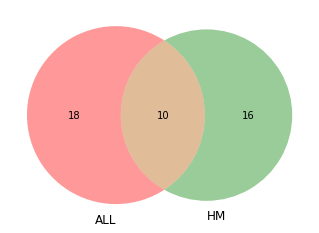

In [457]:
plot_venns(s1['features'],s2['features'],labels=['ALL','HM'])

In [5]:
stat_exp = db.importing('report_reply/fig.S10.raw_permutation.xlsx',sheet_name = 'statistics_of_raw')
stat_exp

[05/19 08:56:39]reading report_reply/fig.S10.raw_permutation.xlsx
  Sheets list: ['permutation_raw', 'statistics_of_raw', 'permutation_of_1_gene', 'permutation_of_2_genes', 'permutation_of_3_genes', 'permutation_of_4_genes']
  Read the 2 / 6 sheet named <statistics_of_raw>


,Unnamed: 0,index,0,1,2,3,4,5,6,mean,max,g,pred,Pre_selected,score_filter,features
0,0,F4C4G32310,1.000000,1.000000,1.000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,Best1,Q96IY4_CPB2
1,0,F4C4G32310,1.000000,1.000000,1.000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,Best1,Q14789_GOLGB1
2,0,F4C4G32310,1.000000,1.000000,1.000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,Best1,Q02790_FKBP4
3,0,F4C4G32310,1.000000,1.000000,1.000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,Best1,P53365_ARFIP2
4,1,F4C4G21856,1.000000,1.000000,1.000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,F4,Y1,ALL,Best1,P78381_SLC35A2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
346,98,F3C3G32,0.916667,0.875000,0.875,0.875000,0.958333,0.916667,0.791667,0.886905,0.958333,F3,Yo,HM,TOP3,P11216_PYGB
347,99,F4C4G86,0.833333,0.916667,0.875,0.916667,1.000000,0.916667,0.875000,0.904762,1.000000,F4,Yo,HM,TOP3,Q13361_MFAP5
348,99,F4C4G86,0.833333,0.916667,0.875,0.916667,1.000000,0.916667,0.875000,0.904762,1.000000,F4,Yo,HM,TOP3,P11498_PC
349,99,F4C4G86,0.833333,0.916667,0.875,0.916667,1.000000,0.916667,0.875000,0.904762,1.000000,F4,Yo,HM,TOP3,P33121_ACSL1


In [23]:
s = df_summary(stat_exp[(stat_exp['score_filter']=='TOP3')&(stat_exp['Pre_selected']=='HM')])
s

,pred,features,Count,score_mean,score_max,term,gene
0,Y1,Q02790_FKBP4,6,0.996032,1.000000,HALLMARK_ESTROGEN_RESPONSE_EARLY,FKBP4
1,Y1,Q8WVQ1_CANT1,5,0.994048,1.000000,HALLMARK_DNA_REPAIR,CANT1
2,Y1,Q96IY4_CPB2,5,0.996429,1.000000,HALLMARK_COAGULATION,CPB2
3,Y1,P42126_ECI1,3,0.992063,0.994048,HALLMARK_FATTY_ACID_METABOLISM,ECI1
4,Y1,P05156_CFI,2,0.994048,0.994048,HALLMARK_COAGULATION,CFI
5,Y1,P53365_ARFIP2,2,0.994048,0.994048,HALLMARK_MITOTIC_SPINDLE,ARFIP2
6,Y1,P53367_ARFIP1,2,0.994048,0.994048,HALLMARK_PROTEIN_SECRETION,ARFIP1
7,Y1,O15021_MAST4,1,1.000000,1.000000,HALLMARK_ESTROGEN_RESPONSE_EARLY,MAST4
8,Y1,O60443_GSDME,1,1.000000,1.000000,HALLMARK_DNA_REPAIR,GSDME
9,Y1,P00740_F9,1,0.994048,0.994048,HALLMARK_COAGULATION,F9


In [501]:
s = df_summary(stat_exp[(stat_exp['score_filter']=='TOP3')&(stat_exp['Pre_selected']=='HM')])
s

,pred,features,Count,score_mean,score_max,term,gene
0,Y1,Q02790_FKBP4,6,0.996032,1.000000,HALLMARK_ESTROGEN_RESPONSE_EARLY,FKBP4
1,Y1,Q8WVQ1_CANT1,5,0.994048,1.000000,HALLMARK_DNA_REPAIR,CANT1
2,Y1,Q96IY4_CPB2,5,0.996429,1.000000,HALLMARK_COAGULATION,CPB2
3,Y1,P42126_ECI1,3,0.992063,0.994048,HALLMARK_FATTY_ACID_METABOLISM,ECI1
4,Y1,P05156_CFI,2,0.994048,0.994048,HALLMARK_COAGULATION,CFI
5,Y1,P53365_ARFIP2,2,0.994048,0.994048,HALLMARK_MITOTIC_SPINDLE,ARFIP2
6,Y1,P53367_ARFIP1,2,0.994048,0.994048,HALLMARK_PROTEIN_SECRETION,ARFIP1
7,Y1,O15021_MAST4,1,1.000000,1.000000,HALLMARK_ESTROGEN_RESPONSE_EARLY,MAST4
8,Y1,O60443_GSDME,1,1.000000,1.000000,HALLMARK_DNA_REPAIR,GSDME
9,Y1,P00740_F9,1,0.994048,0.994048,HALLMARK_COAGULATION,F9


In [24]:
sel3rd = db.importing('external_info/3rd筛选出的C1-4markers.xlsx')
sel3rd = pd.merge(sel3rd,s,how='left',left_on='蛋白',right_on='features')
sel3rd

[05/19 08:58:58]reading external_info/3rd筛选出的C1-4markers.xlsx
  Sheets list: ['Sheet1']
  Read the 1 / 1 sheet named <Sheet1>


,蛋白,Group,出现频数,定位,sel,描述,pred,features,Count,score_mean,score_max,term,gene
0,Q9UBQ7_GRHPR,C2,NaN,细胞质、外泌体,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,O00391_QSOX1,C2,NaN,胞外、分泌蛋白、高尔基体,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,P02747_C1QC,C2,2.0,胞外、分泌蛋白,True,NaN,Y2,P02747_C1QC,1.0,0.946429,0.946429,HALLMARK_COMPLEMENT,C1QC
3,P05156_CFI,C2,12.0,胞外、分泌蛋白,True,NaN,Y1,P05156_CFI,2.0,0.994048,0.994048,HALLMARK_COAGULATION,CFI
4,P05156_CFI,C2,12.0,胞外、分泌蛋白,True,NaN,Y2,P05156_CFI,5.0,0.947619,0.970238,HALLMARK_COAGULATION,CFI
5,P15169_CPN1,C2,4.0,胞外、分泌蛋白,True,NaN,Y2,P15169_CPN1,2.0,0.937500,0.940476,HALLMARK_COAGULATION,CPN1
6,P49959_MRE11,C2,NaN,细胞核,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Q14240_EIF4A2,C2,5.0,细胞质,False,NaN,Y2,Q14240_EIF4A2,1.0,0.970238,0.970238,HALLMARK_MYOGENESIS,EIF4A2
8,Q6ZMP0_THSD4,C2,4.0,胞外、分泌蛋白,True,NaN,Y2,Q6ZMP0_THSD4,4.0,0.950893,0.970238,HALLMARK_ESTROGEN_RESPONSE_EARLY,THSD4
9,Q92974_ARHGEF2,C2,3.0,细胞质、细胞骨架,True,NaN,Y2,Q92974_ARHGEF2,2.0,0.958333,0.970238,HALLMARK_MITOTIC_SPINDLE,ARHGEF2


`HM基因、蛋白`：所有用到的Hallmark的蛋白的pathway信息

`选择的features表现`：`3rd筛选出的C1-4markers`表中各个features的对应跑分信息

`各个features表现`：`stat_exp['score_filter']=='TOP3')&(stat_exp['Pre_selected']=='HM')`中各个features表现的summary信息

`ALL：建模各个features表现`： `stat_exp['score_filter']=='TOP3')&(stat_exp['Pre_selected']=='ALL')`中各个features表现的具体信息

`HM：建模各个features表现`： `stat_exp['score_filter']=='TOP3')&(stat_exp['Pre_selected']=='HM')`中各个features表现具体信息

`stat_exp`：原始的各个features的跑分原始信息，最全，可用于grouping后做各种统计与图表


In [506]:
db.exporting({'HM基因、蛋白':ot,"选择的features表现":sel3rd,"各个features表现":s
              ,"ALL - 建模各个features表现":s1,"HM - 建模各个features表现":s2
              ,"stat_exp":stat_exp
             }
             ,'建模features总结.xlsx'
             ,outputdir='report_reply/'
            )


[06/30 06:04:09]  append #1 Sheet [HM基因、蛋白]
[06/30 06:04:09]  append #2 Sheet [选择的features表现]
[06/30 06:04:09]  append #3 Sheet [各个features表现]
[06/30 06:04:09]  append #4 Sheet [ALL - 建模各个features表现]
[06/30 06:04:09]  append #5 Sheet [HM - 建模各个features表现]
[06/30 06:04:09]  append #6 Sheet [stat_exp]
writing 1 excel @ [PROJECT_ROOT]/report/建模features总结.xlsx


UnboundLocalError: local variable 'add_token' referenced before assignment

####  heatmap

In [524]:
sel3rd['蛋白'].un()

(36,)

In [573]:
sel3rd['蛋白'].u()

array(['Q9UBQ7_GRHPR', 'O00391_QSOX1', 'P02747_C1QC', 'P05156_CFI',
       'P15169_CPN1', 'P49959_MRE11', 'Q14240_EIF4A2', 'Q6ZMP0_THSD4',
       'Q92974_ARHGEF2', 'Q9NY15_STAB1', 'Q96IY4_CPB2', 'Q96EC8_YIPF6',
       'Q96DG6_CMBL', 'Q02252_ALDH6A1', 'P42126_ECI1', 'P22234_PAICS',
       'P00740_F9', 'O15021_MAST4', 'Q9BW91_NUDT9', 'Q8WVQ1_CANT1',
       'Q13439_GOLGA4', 'Q02790_FKBP4', 'P53367_ARFIP1', 'P53365_ARFIP2',
       'P08670_VIM', 'P08183_ABCB1', 'O60443_GSDME', 'Q9BTT0_ANP32E',
       'Q13361_MFAP5', 'P51648_ALDH3A2', 'P33121_ACSL1', 'P19838_NFKB1',
       'P11498_PC', 'P11216_PYGB', 'P09455_RBP1', 'O00264_PGRMC1'],
      dtype=object)

In [510]:
anno

,Group,Response2,NEPC,Cribriform,RNA_ssGSEA_hm,Protein_ssGSEA_hm,Response_level,Response.Group,Y,Y1,Y2,Yo,Clin_classification
P01,non.pCR,I,1,0,4,4,0,non.pCR,0,0,0,1,Others
P02,non.pCR,I,1,0,4,2,1,non.pCR,-1,0,1,0,Y2
P03,non.pCR,I,0,0,3,3,0,non.pCR,0,0,0,1,Others
P04,non.pCR,I,0,0,4,2,1,non.pCR,-1,0,1,0,Y2
P05,non.pCR,I,0,0,2,2,1,non.pCR,-1,0,1,0,Y2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
P82,non.pCR,II,1,0,1,2,0,non.pCR,-1,0,1,0,Y2
P83,non.pCR,II,1,0,2,2,0,non.pCR,-1,0,1,0,Y2
P84,non.pCR,I,0,0,4,2,1,non.pCR,-1,0,1,0,Y2
P85,non.pCR,II,0,0,2,2,0,non.pCR,-1,0,1,0,Y2


In [577]:
def gen_anno():
    colData = db.importing('./export_86_7/x_clusters_rna_protein.dfx')
    colData['Y'] = [1 if i=='1' else -1 if i=='2' else 0  for i in colData.Protein_ssGSEA_hm]
    colData['Y1'] = [1 if i =='1' else 0 for i in colData['Protein_ssGSEA_hm'] ]
    colData['Y2'] = [1 if i =='2' else 0 for i in colData['Protein_ssGSEA_hm'] ]
    colData['Yo'] = [1 if i =='3' else 1 if i=='4' else 0 for i in colData['Protein_ssGSEA_hm'] ]
    
    anno = colData.copy()
    anno['Clin_classification'] = anno["Y"].apply(lambda i:'C2' if i==-1 else 'C1' if i == 1 else 'Others' if i ==0 else 'N/A')
    
    return anno

In [578]:
gs = sel3rd[sel3rd['sel']==True]['蛋白'].u()


anno = gen_anno()
anno


[05/20 04:49:11]reading ./export_86_7/x_clusters_rna_protein.dfx


,Group,Response2,NEPC,Cribriform,RNA_ssGSEA_hm,Protein_ssGSEA_hm,Response_level,Response.Group,Y,Y1,Y2,Yo,Clin_classification
P01,non.pCR,I,1,0,4,4,0,non.pCR,0,0,0,1,Others
P02,non.pCR,I,1,0,4,2,1,non.pCR,-1,0,1,0,C2
P03,non.pCR,I,0,0,3,3,0,non.pCR,0,0,0,1,Others
P04,non.pCR,I,0,0,4,2,1,non.pCR,-1,0,1,0,C2
P05,non.pCR,I,0,0,2,2,1,non.pCR,-1,0,1,0,C2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
P82,non.pCR,II,1,0,1,2,0,non.pCR,-1,0,1,0,C2
P83,non.pCR,II,1,0,2,2,0,non.pCR,-1,0,1,0,C2
P84,non.pCR,I,0,0,4,2,1,non.pCR,-1,0,1,0,C2
P85,non.pCR,II,0,0,2,2,0,non.pCR,-1,0,1,0,C2


In [27]:
# gs2 = np.array(['Q9UBQ7_GRHPR', 'O00391_QSOX1', 'P02747_C1QC', 'P05156_CFI',
#        'P15169_CPN1', 'P49959_MRE11', 'Q14240_EIF4A2', 'Q6ZMP0_THSD4',
#        'Q92974_ARHGEF2', 'Q9NY15_STAB1', 'Q96IY4_CPB2', 'Q96EC8_YIPF6',
#        'Q96DG6_CMBL', 'Q02252_ALDH6A1', 'P42126_ECI1', 'P22234_PAICS',
#        'P00740_F9', 'O15021_MAST4', 'Q9BW91_NUDT9', 'Q8WVQ1_CANT1',
#        'Q13439_GOLGA4', 'Q02790_FKBP4', 'P53367_ARFIP1', 'P53365_ARFIP2',
#        'P08670_VIM', 'P08183_ABCB1', 'O60443_GSDME', 'Q9BTT0_ANP32E',
#        'Q13361_MFAP5', 'P51648_ALDH3A2', 'P33121_ACSL1', 'P19838_NFKB1',
#        'P11498_PC', 'P11216_PYGB', 'P09455_RBP1', 'O00264_PGRMC1'])

array(['Q9UBQ7_GRHPR', 'O00391_QSOX1', 'P02747_C1QC', 'P05156_CFI',
       'P15169_CPN1', 'P49959_MRE11', 'Q14240_EIF4A2', 'Q6ZMP0_THSD4',
       'Q92974_ARHGEF2', 'Q9NY15_STAB1', 'Q96IY4_CPB2', 'Q96EC8_YIPF6',
       'Q96DG6_CMBL', 'Q02252_ALDH6A1', 'P42126_ECI1', 'P22234_PAICS',
       'P00740_F9', 'O15021_MAST4', 'Q9BW91_NUDT9', 'Q8WVQ1_CANT1',
       'Q13439_GOLGA4', 'Q02790_FKBP4', 'P53367_ARFIP1', 'P53365_ARFIP2',
       'P08670_VIM', 'P08183_ABCB1', 'O60443_GSDME', 'Q9BTT0_ANP32E',
       'Q13361_MFAP5', 'P51648_ALDH3A2', 'P33121_ACSL1', 'P19838_NFKB1',
       'P11498_PC', 'P11216_PYGB', 'P09455_RBP1', 'O00264_PGRMC1'],
      dtype=object)

In [584]:
len(gs2)

36

In [585]:
mat.loc[:,gs2].T

,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,P16,P17,P18,P19,P20,P21,P22,P23,P24,P25,P26,P27,P28,P29,P30,...,P49,P50,P51,P52,P53,P54,P55,P56,P57,P58,P59,P60,P61,P62,P63,P65,P66,P67,P68,P69,P70,P71,P72,P73,P80,P82,P83,P84,P85,P86
Q9UBQ7_GRHPR,0.423039,-0.328207,-0.930429,-0.657070,-0.713588,-0.577116,0.160843,0.886691,1.050787,0.772658,0.128565,0.157948,-1.001684,-1.006571,0.702997,0.861668,-0.693521,-1.438266,1.354356,-0.442868,0.144853,-0.370475,1.038233,-1.011144,-0.961053,0.231556,-0.426625,-1.310285,-0.981337,-0.617896,...,2.143647,-0.294824,0.518512,0.558455,-1.618352,-0.079218,-0.014460,2.340744,-1.711418,0.481414,0.217020,-1.075267,0.935307,-0.371037,-0.024599,2.064940,0.709006,0.005757,0.602992,-0.079120,1.975021,0.790396,0.855763,0.330258,-1.059023,-0.377071,0.053624,-2.278030,-0.348459,-0.624508
O00391_QSOX1,-0.511055,-0.000912,-0.714820,-1.367637,1.142098,0.551030,-0.522659,-0.096754,-0.604241,-1.130093,-0.440463,-0.382313,-0.254592,2.639384,-0.457523,-1.828516,1.636921,1.960017,0.747547,-0.759026,-0.595103,-0.966029,1.564882,1.953836,0.258418,-0.829652,1.194311,0.261300,0.956018,0.691223,...,-1.965622,0.932937,-1.202949,-0.114374,0.884169,-0.019184,0.234188,-0.533063,1.061298,1.247189,-0.664370,-1.701720,0.811565,-0.885562,2.409246,-0.406010,-1.151207,-0.988377,0.630358,-0.365709,-0.193826,-0.756257,-1.393868,-0.194674,0.062827,0.071873,-0.029161,0.240838,0.605370,1.318989
P02747_C1QC,-0.617802,0.771724,-0.147907,-0.365945,3.185729,1.263387,-0.284143,-0.573772,-0.733829,-0.781761,-0.049754,-0.507266,-0.459037,-0.591586,-1.046445,1.002036,2.222379,0.733641,-1.079944,0.569419,-0.435271,0.171901,0.053572,0.534917,0.966285,-0.814160,0.815960,1.583764,3.154457,0.000595,...,-0.731657,-0.292369,-1.272002,-0.374207,1.925820,-0.853484,-0.674844,-0.790616,1.034973,0.160389,-0.850443,-0.554207,-0.521533,0.662247,1.412099,-1.559558,-1.241908,-0.471567,-1.370016,1.551475,-0.817119,-0.738669,-1.544596,0.647517,1.391985,-0.135289,-0.258902,0.386878,0.195843,1.436128
P05156_CFI,-0.344350,2.185469,0.338780,0.123011,1.119991,-0.392044,-1.282042,-0.459810,-1.120575,-0.825085,0.720587,-0.004428,-0.195393,-0.268284,0.417758,-1.380252,0.844053,0.772628,0.081657,0.907962,0.856298,0.488625,-0.113743,0.247278,0.452105,-0.550316,1.160368,0.569477,0.539516,-0.061981,...,-1.067321,0.537653,-2.543315,-0.272188,0.497455,-1.440640,-0.672746,-1.276335,2.034825,0.028473,-0.655951,-1.441169,0.134038,1.221024,1.644280,-0.125552,-0.536811,-0.735661,-0.432053,1.188445,-1.655867,-0.551883,-2.038494,0.772289,1.255973,2.361900,1.269227,0.970446,0.096039,1.066944
P15169_CPN1,0.588914,1.241849,-0.158750,-0.654740,0.804841,0.620383,-0.162733,-0.194479,0.058729,-0.516932,0.331022,-0.244791,1.085657,-0.355192,-0.508127,-1.475003,1.536528,0.738799,-0.573773,0.491687,-0.722033,-1.036718,-0.105499,1.132211,1.332971,0.156933,2.169290,0.724971,2.701244,0.560696,...,-0.675124,1.589560,-1.337500,-0.636914,0.512018,0.253913,-0.520792,-1.019922,1.190456,0.251494,-0.282967,0.047612,-1.873350,-0.107353,1.833500,-0.673597,-2.345002,-0.093483,-1.074525,1.195359,-1.598200,-0.762715,-0.942153,0.153605,1.150672,-0.475739,0.232544,0.549321,0.735217,0.741518
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P19838_NFKB1,-0.121278,0.271610,1.252601,0.511189,1.488840,-0.994487,-0.807490,-0.018654,-0.311690,-0.954109,-0.640950,0.462397,0.010460,-1.423430,-0.314223,2.182030,-0.519278,0.287790,2.232405,-0.540813,1.219515,0.948464,0.559102,1.492420,-0.642685,0.613830,-0.105517,0.668541,-0.904062,-1.346439,...,-0.679614,0.976997,-1.074939,-0.311951,-0.051837,-1.170903,0.833581,-3.024719,0.092780,1.493271,0.441430,1.019656,-0.099657,-0.437747,0.577695,-0.944641,-0.842032,0.050153,0.952969,-1.886434,-0.044957,-0.801648,-2.256869,-1.132224,-0.076143,0.672565,0.442336,-0.453652

In [29]:
db.exporting(mat.loc[:,gs2].T,'export_by2_86_pCR_nonpCR/mod_prt_77_sel_36fea_mat')

[05/19 09:13:24] writing 1 file with 36 lines at 
	[PROJECT_ROOT]/export_by2_86_pCR_nonpCR/mod_prt_77_sel_36fea_mat.dfx


report/heatMap_tk_sel3rd_all_grouped.pdf
report/heatMap_tk_sel3rd_all_free.pdf


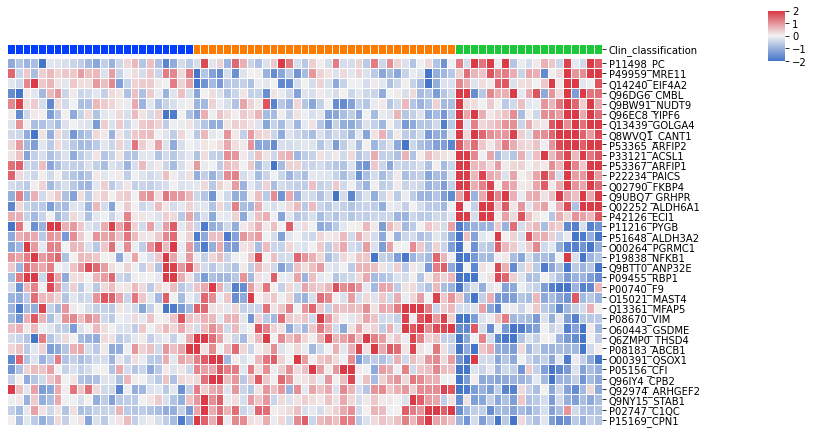

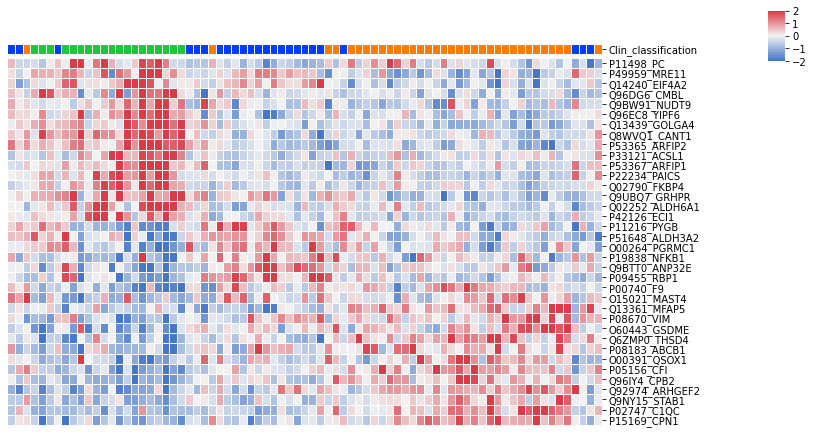

In [26]:
yplot_heatmap_by_input_matrix(mat.loc[:,gs2].T, colData=anno , bygroup=True
                                  , export = 'sel3rd_all',prefix='tk', suffix='grouped', outputdir='report_reply/'
                                  , linewidths=0.5, z_score=None, figsize=(12,7) )

yplot_heatmap_by_input_matrix(mat.loc[:,gs2].T, colData=anno , bygroup=False
                                  , export = 'sel3rd_all',prefix='tk', suffix='free', outputdir='report_reply/'
                                  , linewidths=0.5, z_score=None, figsize=(12,7) )


In [68]:
matv = db.importing('export_by2_86_pCR_nonpCR/mod_prt_52_sel_31fea_mat.dfx')

matv = matv.apply(lambda x:(x-x.mean())/x.std(),1).T
matv

[05/19 09:57:46]reading export_by2_86_pCR_nonpCR/mod_prt_52_sel_31fea_mat.dfx


,GRHPR,QSOX1,CFAI,MRE11,IF4A2,THSD4,ARHG2,STAB1,CBPB2,YIPF6,...,MDR1,GSDME,AN32E,AL3A2,ACSL1,NFKB1,PYC,PYGB,RET1,PGRC1
1491165,-0.034440,1.842282,-0.010001,0.116592,0.087765,-0.449196,-0.765883,-0.210550,-0.327293,0.964288,...,0.064949,-0.141370,-0.624476,-0.104721,-0.048326,0.255164,-0.306398,0.047889,0.504998,0.195027
1494425,-0.313649,0.397231,0.340966,0.268890,0.209991,-0.383997,-0.099075,-0.212826,0.395324,0.694063,...,-0.047559,-0.069887,0.736868,0.344500,0.032671,-0.174564,-0.244669,-0.300464,-0.155464,0.660338
1494688,0.188438,1.019377,-0.199286,-0.129833,0.741217,-0.526515,0.103991,-0.185825,-0.968196,0.286107,...,0.136921,0.129544,1.168536,-0.314960,-0.271658,0.664949,-0.362152,0.428954,0.147077,0.411103
1498899,-0.192592,-0.343327,-0.185752,0.403143,0.119124,-0.542891,0.017837,-0.065149,-0.530086,0.260813,...,-0.041541,-0.185421,-0.710876,-0.147322,-0.258908,-0.135948,-0.195332,0.048937,-0.579632,-0.475365
1499496,-0.221690,0.297582,0.111750,-0.242301,0.804087,-0.614251,0.988987,-0.189565,1.581008,0.141717,...,0.065765,0.111028,0.668382,0.559240,0.396530,0.451497,0.061063,0.631871,-0.096462,1.562866
1499777,-0.014640,-0.268434,-0.146639,-0.107702,-0.200741,-0.621109,-0.652717,-0.234576,-0.669456,0.110759,...,-0.078681,-0.081087,-0.594061,-0.164686,-0.176553,0.010053,-0.372959,0.425180,0.811843,0.645479
1504457,-0.438929,1.361088,0.083691,0.694925,1.729194,0.005489,0.575647,-0.142421,-0.117585,2.354884,...,0.268908,0.211460,-0.447155,0.151661,0.217644,1.404434,0.184964,-0.698924,-0.506100,-0.612385
1507100,-0.031296,0.018786,0.125660,-0.040346,0.098182,-0.394993,0.614431,-0.187776,0.501848,0.513712,...,0.073244,-0.214562,-0.162051,0.094010,0.416704,0.154125,-0.184283,0.429786,0.330161,0.612893
1509204,-0.289483,0.047589,0.369906,0.089077,0.368294,-0.645935,0.330147,-0.055508,-0.221175,0.524743,...,0.216867,0.148045,0.691992,0.142241,-0.006071,0.213064,-0.115470,0.370591,0.131567,-0.015419
1509451,-0.061286,0.120973,0.090206,-0.317043,-0.393081,-0.705660,-0.779100,-0.250801,-0.626886,-0.425095,...,-0.141005,-0.559249,-0.013871,-0.286729,-0.655047,-0.145893,-0.261460,-0.301877,1.232397,0.350249


####  31 fea model on valid data

In [1141]:
organ_uid = ["1528731","1535920","1538224","1554631","1555314","1557024","1563492","1567143","1567947"]
info_v = db.importing('external_info/Organoids/organoid_and_verification/前瞻性队列临床病理信息总结20240504_v3.0（完善病理信息）.xlsx')
info_v['uid'] = info_v['病理号'].astype(str)
exclude = info_v.loc[info_v['pT stage']=='pCR','uid'].values
exclude

[05/20 08:36:01]reading external_info/Organoids/organoid_and_verification/前瞻性队列临床病理信息总结20240504_v3.0（完善病理信息）.xlsx
  Sheets list: ['Sheet1']
  Read the 1 / 1 sheet named <Sheet1>


array(['1566005', '1522368', '1515949'], dtype=object)

In [1144]:
matv_ori = db.importing('export_by2_86_pCR_nonpCR/mod_prt_52_mat.dfx').T
matv_ori = matv_ori.loc[~matv_ori.index.isin(exclude),:]

x = StandardScaler().fit_transform(matv_ori)
matv_ori =pd.DataFrame(x, index = matv_ori.index, columns=matv_ori.columns)

matv_ori

[05/20 08:36:58]reading export_by2_86_pCR_nonpCR/mod_prt_52_mat.dfx


,ACTB,ACTA,ACTH,ACTG,PLEC,VIME,DESM,ACTC,ACTS,MYH11,TPM2,ALBU,MYH9,CO6A3,CALD1,TPM1,POTEF,POTEE,FBN1,TPM4,POTEI,LMNA,POTEJ,FLNA,TPM3,EIF3A,K1C10,HNRPM,ACTBL,TERA,...,RN157,C2C4C,KAT6B,PHF14,UNKL,PAX2,PAX8,LRP11,BEGIN,CCD68,CC174,FADS2,RHOU,MITOK,MRAP2,BIRC8,NEDD8,TM215,PTPRO,5HT1F,CO039,MAGBA,FHOD3,RHG32,LIPH,STS,GDF6,GDF7,TNIP2,SPRL1
1491165,0.086979,-0.073534,-0.107888,0.088484,0.280514,0.160856,-0.678864,0.053819,0.039891,-0.153476,-0.155718,1.086391,0.356986,0.815194,0.750106,0.100026,0.420396,0.562226,2.618319,0.207104,0.595609,-0.128880,0.582157,0.603673,0.345444,-0.572451,-0.333221,-0.650368,0.646182,0.096072,...,0.230175,-0.129368,0.014495,0.160099,0.447880,0.286916,0.286916,-0.003404,-0.003404,-0.343025,-0.343025,0.270933,-0.018608,0.574018,0.574018,0.574018,0.225680,0.169621,-0.162313,-0.290796,0.365189,0.064280,0.188927,-0.144638,-0.144638,-0.279908,0.473963,0.473963,-0.222932,-0.505151
1494425,-0.074626,-0.084951,-0.066575,-0.078495,0.433038,1.681931,0.673848,0.126297,0.089447,0.120107,0.332338,-0.534848,-0.167566,-0.407862,0.260233,0.740884,0.254923,0.219011,0.108438,0.575973,0.277051,0.549432,0.274111,0.022575,0.958660,-0.565218,0.382067,-0.015438,0.403355,-0.369382,...,0.306314,-0.149189,0.110699,0.024834,0.027305,-0.004395,-0.004395,0.198518,0.198518,0.269499,0.269499,-0.250070,-0.263280,-0.180886,-0.180886,-0.180886,0.560807,-0.366972,0.255254,-0.181712,0.310479,0.351933,0.573980,-0.196677,-0.196677,-0.247310,-0.205698,-0.205698,-0.311152,-0.312520
1494688,-0.777892,-0.738083,-0.773414,-0.772001,-0.407035,-0.825352,-1.012977,-0.764877,-0.743530,-0.878269,-1.312290,-0.946108,-0.543219,-0.669119,-1.315656,-1.205596,-0.603812,-0.614125,-0.029473,-1.296594,-0.382561,-0.366282,-0.410102,-0.787861,-1.168970,-0.288202,0.166588,0.415443,-0.237966,0.639758,...,0.011972,0.301549,-0.611826,0.090876,0.370371,0.159586,0.159586,0.150225,0.150225,0.400467,0.400467,0.020400,0.302875,-0.133963,-0.133963,-0.133963,0.048056,0.441640,0.072099,0.381978,0.102174,-1.382390,-0.477589,-0.160796,-0.160796,-0.057775,-0.001529,-0.001529,-0.155153,-0.433752
1498899,-0.087003,-0.054490,-0.072570,-0.070913,-0.535124,-1.135498,-0.809044,-0.057324,-0.069993,-0.454953,0.116880,-0.455662,-0.174908,-0.808844,-0.001328,0.403138,-0.076409,-0.050535,-0.529260,0.090170,-0.019324,-0.772014,-0.041257,-0.536828,0.317513,-0.345739,-0.347932,0.201672,0.272062,0.211563,...,0.010648,-0.239778,-0.373662,-0.019273,-0.081561,-0.131894,-0.131894,0.041109,0.041109,-0.527320,-0.527320,-0.154215,-0.280981,-0.634392,-0.634392,-0.634392,-0.048480,-0.065447,-0.273095,-0.267618,-0.118388,-0.526916,-0.059778,-0.239709,-0.239709,-0.282563,-0.096613,-0.096613,-0.232938,-0.449111
1499496,-0.207821,-0.273668,-0.270288,-0.204119,0.779966,0.684295,0.353422,-0.284555,-0.264525,1.013660,-0.638341,0.554593,0.053862,1.276012,0.168634,-0.515436,0.065406,-0.213570,0.343563,-0.961142,-0.448897,0.172614,-0.529457,0.541413,-0.692991,0.104212,-0.145237,0.457237,-0.064132,-0.016715,...,0.620004,0.484363,0.298205,0.669907,0.363368,0.239333,0.239333,0.472584,0.472584,-0.658629,-0.658629,0.222525,0.685806,-0.452259,-0.452259,-0.452259,0.799478,-0.106859,0.030321,0.392691,0.320078,0.227601,0.126627,-0.138165,-0.138165,0.115825,0.120112,0.120112,-0.229982,-0.243272
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1538224,2.468773,2.160141,2.356114,2.467968,-1.572320,0.832062,2.166797,2.317058,2.393163,-1.517474,2.446206,-1.311415,-1.588609,-1.495123,-0.872463,-0.045706,0.462347,0.497673,-1.873244,2.363458,1.002440,-0.056707,1.049829,-1.715902,-0.529731,1.299388,-0.782005,-0.980494,-1.376033,-1.669521,...,-2.007902,-1.960261,-1.032626,-2.232650,-1.665265,-1.862287,-1.862287,-1.672939,-1.672939,0.775856,0.775856,-1.625420,-0.697982,-1.338176,-1.338176,-1.338176,-1.672652,-2.314088,-1.286493,-2.24

In [1145]:
valid_des_all = db.importing('external_info/Organoids/prt_valid52_des.dfx')
valid_des_all['uid'] = valid_des_all['Protein_ID'] +'_' + valid_des_all['Protein_Name']
valid_des_all


[05/20 08:37:12]reading external_info/Organoids/prt_valid52_des.dfx


,PID,Protein_ID,Protein_Name,Group_ID,Group_Name,source,ProteinName,GroupType,GroupID,Number_PSM_ID,Empty_Separator,uid
0,sp|P60709|ACTB_HUMAN,P60709,ACTB,P60709,ACTB,7,sp|P60709|ACTB_HUMAN,Leading,sp|P60709|ACTB_HUMAN,691,NaN,P60709_ACTB
1,sp|P62736|ACTA_HUMAN,P62736,ACTA,P62736,ACTA,7,sp|P62736|ACTA_HUMAN,Leading,sp|P62736|ACTA_HUMAN,570,NaN,P62736_ACTA
2,sp|P63267|ACTH_HUMAN,P63267,ACTH,P63267,ACTH,7,sp|P63267|ACTH_HUMAN,Leading,sp|P63267|ACTH_HUMAN,579,NaN,P63267_ACTH
3,sp|P63261|ACTG_HUMAN,P63261,ACTG,P63261,ACTG,7,sp|P63261|ACTG_HUMAN,Leading,sp|P63261|ACTG_HUMAN,414,NaN,P63261_ACTG
4,sp|Q15149|PLEC_HUMAN,Q15149,PLEC,Q15149,PLEC,6,sp|Q15149|PLEC_HUMAN,Leading,sp|Q15149|PLEC_HUMAN,77,NaN,Q15149_PLEC
...,...,...,...,...,...,...,...,...,...,...,...,...
10110,sp|P08842|STS_HUMAN,P08842,STS,P36957,ODO2,1,sp|P08842|STS_HUMAN,Sameset,sp|P36957|ODO2_HUMAN,1,NaN,P08842_STS
10111,sp|Q6KF10|GDF6_HUMAN,Q6KF10,GDF6,Q8WZ42,TITIN,1,sp|Q6KF10|GDF6_HUMAN,Subset,REV_sp|Q8WZ42|TITIN_HUMAN,1,NaN,Q6KF10_GDF6
10112,sp|Q7Z4P5|GDF7_HUMAN,Q7Z4P5,GDF7,Q8WZ42,TITIN,1,sp|Q7Z4P5|GDF7_HUMAN,Sameset,REV_sp|Q8WZ42|TITIN_HUMAN,1,NaN,Q7Z4P5_GDF7
10113,sp|Q8NFZ5|TNIP2_HUMAN,Q8NFZ5,TNIP2,A5YKK6,CNOT1,1,sp|Q8NFZ5|TNIP2_HUMAN,Sameset,REV_sp|A5YKK6|CNOT1_HUMAN,1,NaN,Q8NFZ5_TNIP2


In [1146]:
cant = ['SCAN-1','CANT1','SHAPY',"Q8WVQ1","B4DJ54","Q7Z2J7","Q8NG05","Q8NHP0","Q9BSD5"]
valid_des_all[(valid_des_all['Protein_Name'].isin(cant))|(valid_des_all['Group_Name'].isin(cant))]


,PID,Protein_ID,Protein_Name,Group_ID,Group_Name,source,ProteinName,GroupType,GroupID,Number_PSM_ID,Empty_Separator,uid


In [1147]:
valid_des_all[(valid_des_all['Protein_ID'].isin(cant))|(valid_des_all['Group_ID'].isin(cant))]

,PID,Protein_ID,Protein_Name,Group_ID,Group_Name,source,ProteinName,GroupType,GroupID,Number_PSM_ID,Empty_Separator,uid


In [1148]:
m = db.importing('export_by2_86_pCR_nonpCR/mod_prt_77x52_sel_31fea_des.dfx')
m


[05/20 08:37:15]reading export_by2_86_pCR_nonpCR/mod_prt_77x52_sel_31fea_des.dfx


,uid,ID,Name
1,Q9UBQ7_GRHPR,Q9UBQ7,GRHPR
2,O00391_QSOX1,O00391,QSOX1
4,P05156_CFI,P05156,CFI
6,P49959_MRE11,P49959,MRE11
7,Q14240_EIF4A2,Q14240,EIF4A2
...,...,...,...
32,P19838_NFKB1,P19838,NFKB1
33,P11498_PC,P11498,PC
34,P11216_PYGB,P11216,PYGB
35,P09455_RBP1,P09455,RBP1


In [1166]:
matt_des = db.importing('export_by2_86_pCR_nonpCR/wes_glx.dfx')
matt_exlude = matt_des.loc[matt_des['Group']=='pCR','Custom_Label'].values
matt_exlude

[05/20 08:41:13]reading export_by2_86_pCR_nonpCR/wes_glx.dfx


array(['P35', 'P64', 'P74', 'P75', 'P76', 'P77', 'P78', 'P79', 'P81'],
      dtype=object)

In [1168]:
matt_ori = db.importing('export_by2_86_pCR_nonpCR/prt_ori_7717.dfx',index_col=0).T
matt_ori = matt_ori.loc[~matt_ori.index.isin(matt_exlude),:]
x = StandardScaler().fit_transform(matt_ori)
matt_ori =pd.DataFrame(x, index = matt_ori.index, columns=matt_ori.columns)

matt_ori

[05/20 08:41:20]reading export_by2_86_pCR_nonpCR/prt_ori_7717.dfx


,A0A075B6H7_IGKV3-7,A0A075B6H9_IGLV4-69,A0A075B6I0_IGLV8-61,A0A075B6I4_IGLV10-54,A0A075B6I9_IGLV7-46,A0A075B6J6_IGLV3-22,A0A075B6J9_IGLV2-18,A0A075B6K0_IGLV3-16,A0A075B6K4_IGLV3-10,A0A075B6K5_IGLV3-9,A0A075B6P5_IGKV2-28,A0A075B6Q5_IGHV3-64,A0A075B6R2_IGHV4-4,A0A075B6R9_IGKV2D-24,A0A075B6S2_IGKV2D-29,A0A075B6S5_IGKV1-27,A0A075B6S9_IGKV1-37,A0A075B759_PPIAL4E,A0A087WSY4_IGHV4-30-2,A0A087WSY6_IGKV3D-15,A0A087WSZ0_IGKV1D-8,A0A096LP55_UQCRHL,A0A0A0MRZ8_IGKV3D-11,A0A0A0MS15_IGHV3-49,A0A0A0MT89_IGKJ1,A0A0B4J1U7_IGHV6-1,A0A0B4J1V0_IGHV3-15,A0A0B4J1V2_IGHV2-26,A0A0B4J1V6_IGHV3-73,A0A0B4J1X5_IGHV3-74,...,Q9Y6J0_CABIN1,Q9Y6K0_CEPT1,Q9Y6K1_DNMT3A,Q9Y6K5_OAS3,Q9Y6K9_IKBKG,Q9Y6M1_IGF2BP2,Q9Y6M5_SLC30A1,Q9Y6M7_SLC4A7,Q9Y6M9_NDUFB9,Q9Y6N5_SQOR,Q9Y6N6_LAMC3,Q9Y6N7_ROBO1,Q9Y6N8_CDH10,Q9Y6Q2_STON1,Q9Y6Q5_AP1M2,Q9Y6Q9_NCOA3,Q9Y6R0_NUMBL,Q9Y6R1_SLC4A4,Q9Y6R4_MAP3K4,Q9Y6R7_FCGBP,Q9Y6R9_CCDC61,Q9Y6U3_SCIN,Q9Y6V7_DDX49,Q9Y6W3_CAPN7,Q9Y6W5_WASF2,Q9Y6X4_FAM169A,Q9Y6X5_ENPP4,Q9Y6X8_ZHX2,Q9Y6X9_MORC2,Q9Y6Y8_SEC23IP
P01,0.610034,-0.044147,1.121882,0.171524,0.433942,-0.758291,0.102553,0.438582,-0.046816,0.984374,0.822188,-0.206388,-0.129554,0.168119,0.438030,-0.166906,0.360211,-0.390720,-0.142984,1.491617,-0.302802,-0.931909,1.027126,0.745178,0.488716,0.897113,0.457237,0.296235,0.105800,0.522212,...,-0.167429,0.005482,-0.498968,1.475171,-1.002146,0.610002,0.124177,-0.004276,1.430088,-0.112969,0.985188,-0.586565,0.240027,0.047011,-0.043541,-3.395759,0.026438,-0.133418,-0.171694,-0.326741,-0.260919,-0.029951,-0.054658,-1.002401,0.312834,-0.372470,-0.392770,-0.262974,-0.138607,-1.026516
P02,1.803415,2.957628,-1.165978,3.983947,2.698387,1.132304,1.298490,1.888290,2.655426,1.057907,2.652105,0.618899,-0.425797,2.717938,2.365659,-0.246067,0.164597,0.697773,0.482161,1.586032,-0.325341,1.885872,1.874150,1.253949,0.483928,0.540731,2.128805,0.453651,2.033673,1.483055,...,0.148485,0.393370,-0.328523,1.072703,1.319956,-0.446264,-0.821615,-1.285641,-0.524840,0.493493,0.256280,-0.006013,0.289734,-0.781104,-0.977658,-0.185447,-0.544342,0.182379,-0.439338,0.520848,-0.161374,-1.257934,-0.290484,-0.543666,1.123526,0.667471,-0.448818,-1.292891,-0.353205,0.922514
P03,-0.984229,-0.474705,0.155933,0.177307,0.135060,-0.324045,1.790188,-0.490130,-0.363925,-0.885446,0.249353,-0.239685,0.348974,0.433295,1.339798,-1.818155,-0.367484,0.048937,0.227492,0.293967,0.124860,-0.278745,-0.531129,-0.367315,-0.212930,-1.200399,-0.441755,-0.375905,0.017637,0.319764,...,2.930309,0.366107,-0.116418,-0.282094,0.186960,0.018838,0.106681,0.593839,-1.344022,-1.041690,-1.070174,0.726204,1.640460,-1.352278,-1.132500,0.070392,-0.118345,-0.194686,0.003347,-1.142033,-0.222068,0.018413,-0.059013,-0.107779,0.294940,1.845370,-0.669012,1.461098,0.708143,-0.271883
P04,-0.300546,0.085789,0.851427,-0.131214,0.571838,-0.881294,-0.036282,-0.440701,0.420596,-1.205934,0.072862,-0.024007,-0.508908,-0.801379,-1.239488,-1.003916,-1.005368,0.201308,-0.859742,-0.830749,-0.067625,-1.024815,-0.771471,-0.788680,-0.340766,0.699893,-0.572177,-0.146912,0.840018,0.120888,...,0.020089,1.795384,-0.567152,-0.449897,0.418147,0.686188,0.216939,-0.490774,0.064048,-0.016236,0.112953,-0.506678,-0.263783,-1.812955,-1.517953,-0.077826,-0.500410,-0.251332,-0.353181,-0.961155,0.020476,0.813532,0.407089,-0.413162,-0.572789,-0.574032,-0.768668,-0.844418,-0.702804,-0.616226
P05,0.421933,0.245844,0.082477,0.508199,-0.494899,0.101188,-0.017583,0.829754,0.537431,1.975020,0.294820,0.634178,0.235030,-0.965371,0.967606,0.845773,0.293040,-0.754195,1.388181,0.974231,-0.537648,-1.779061,0.653875,1.128076,0.351400,-0.615487,-0.050567,1.693136,0.050418,0.833421,...,1.257277,-0.512969,-0.123968,0.556029,1.332231,-0.321546,-0.425939,0.398893,-0.750509,-1.235022,1.785445,1.076602,0.421846,-1.187410,-0.698473,0.449707,-0.099344,-2.495929,1.245628,-0.239622,0.368836,2.107598,-1.398481,1.112868,0.872543,0.395618,-0.582510,-0.000223,0.015404,-0.305776
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,..

In [1169]:
sel = valid_des_all[valid_des_all['Protein_ID'].isin(m['ID'])]
sel = sel.set_index('Protein_ID').loc[m['ID']].reset_index('Protein_ID')

matv = matv_ori.loc[:,sel['Protein_Name']]
matv = matv.T.apply(lambda x:(x-x.mean())/x.std(),1).T

matt = matt_ori.loc[:,m['uid']]

assert (matt.columns==m['uid']).all()
assert (matv.columns==sel['Protein_Name']).all()
m['pQuant_Name'] = sel['Protein_Name']
m['msfragger_ID'] = matt.columns

matt.columns = matv.columns
matt

,GRHPR,QSOX1,CFAI,MRE11,IF4A2,THSD4,ARHG2,STAB1,CBPB2,YIPF6,CMBL,MMSA,ECI1,PUR6,FA9,MAST4,GOGA4,FKBP4,ARFP1,ARFP2,VIME,MDR1,GSDME,AN32E,AL3A2,ACSL1,NFKB1,PYC,PYGB,RET1,PGRC1
P01,0.359167,-0.463427,-0.348964,-0.093467,-0.547241,-0.424037,-0.071923,-0.552123,0.637822,-0.267514,-0.689893,0.336757,1.082847,-0.612398,0.242152,-0.464620,-0.412943,0.074147,-0.973404,-0.332159,-0.209428,-0.084929,-0.245830,0.344941,1.400660,-0.820878,-0.078645,0.251318,1.639162,-0.536004,1.163880
P02,-0.377277,0.046360,2.209118,0.242022,-0.550486,0.825844,1.136832,0.930569,0.570603,-0.787498,0.040985,-0.579827,-0.508920,-0.847554,1.193219,-0.272269,-1.013040,-0.461153,-0.742780,-0.550517,-0.028147,-0.212919,-1.103998,-0.055195,0.652839,-0.502473,0.307232,-0.363896,-0.081898,-0.399818,0.866399
P03,-0.967634,-0.667050,0.341798,0.446176,1.130231,-0.672221,-0.158007,-1.050262,-1.048979,-0.400439,0.145601,-0.552868,-0.563613,-0.279136,0.764966,-0.651817,0.066821,-0.683212,-0.464417,-0.894985,0.647946,-0.605401,0.097427,1.449808,0.947442,-1.402040,1.270721,-1.018086,0.124783,2.721488,2.467143
P04,-0.699661,-1.319411,0.123618,0.299929,-0.086215,0.534130,-0.296473,-0.301485,-0.040157,-1.112700,-0.156549,-0.578549,-0.591539,-1.524377,1.127195,-0.361657,-0.788551,-0.694767,-1.309375,-0.847899,0.180204,1.760849,0.773309,0.669588,0.815195,-0.826621,0.542536,0.307999,0.152998,0.319926,-0.406309
P05,-0.755065,1.188572,1.131737,-1.076721,-1.140377,0.479202,1.081143,0.990892,0.734133,-0.838136,-1.251100,-0.645183,-0.426727,-0.816775,0.725614,1.951213,-0.372821,-0.832498,0.023614,-1.199997,0.876491,1.246881,1.718784,1.297942,-0.091783,0.174684,1.502744,-0.760117,0.334530,0.638514,0.437249
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P82,-0.425179,0.119094,2.387520,0.927939,-0.388386,0.056043,0.833165,0.327047,0.410561,-0.270953,-0.265627,0.492222,-0.348494,-0.180865,0.618468,-0.300808,0.183713,0.460242,-0.470253,-0.232392,-0.442929,-0.882842,0.425124,0.562625,-0.360744,-0.630244,0.701034,0.323456,0.053573,0.589159,0.104231
P83,-0.002969,0.018131,1.282640,-0.009795,-0.816030,0.136521,-0.637769,1.138849,0.499870,0.305914,-0.506102,-0.962906,-0.246935,-0.169881,1.034361,2.151228,0.163684,-0.220035,0.421417,0.956248,-1.545059,-0.472347,0.003397,-0.592873,0.787963,-0.466845,0.474912,-0.511062,0.381262,-0.826810,0.342837
P84,-2.288682,0.287941,0.980521,-0.303785,-1.177320,0.624438,-0.220444,0.309309,0.040713,-1.146475,-0.300963,-0.451750,-0.767732,-0.538665,1.878071,0.075351,-0.473576,0.337896,-0.726803,-1.275095,0.273914,0.662296,-0.392491,-0.282915,0.269248,-0.038698,-0.405089,1.203131,-0.575293,-0.630915,0.476706
P85,-0.397130,0.652219,0.096345,0.152976,-0.346586,1.683623,0.792350,0.651887,1.000419,-1.230513,-0.129264,-0.680074,-0.550945,-0.241166,0.731547,1.152022,-1.261849,-0.503858,-0.569424,-0.304571,0.918603,-0.022574,0.686965,-0.148151,0.146478,-0.348094,-0.759536,-0.384993,-0.914191,-0.016377,-0.505863


In [1170]:
matv

,GRHPR,QSOX1,CFAI,MRE11,IF4A2,THSD4,ARHG2,STAB1,CBPB2,YIPF6,CMBL,MMSA,ECI1,PUR6,FA9,MAST4,GOGA4,FKBP4,ARFP1,ARFP2,VIME,MDR1,GSDME,AN32E,AL3A2,ACSL1,NFKB1,PYC,PYGB,RET1,PGRC1
1491165,-0.036875,1.810700,-0.004049,0.110980,0.082987,-0.449606,-0.745349,-0.212115,-0.353275,1.009278,-0.282647,-0.436959,-0.031233,-0.625924,-0.160176,-0.011055,-0.320778,-0.508472,0.116711,1.129450,0.159206,0.046184,-0.135310,-0.629182,-0.095705,-0.041571,0.225449,-0.302378,0.132753,0.488906,0.192667
1494425,-0.308995,0.401084,0.340730,0.260628,0.201910,-0.386243,-0.097079,-0.214325,0.354888,0.737553,-0.482758,-0.762427,0.022135,-0.298185,-0.520732,0.216263,-0.563536,-0.281933,0.372338,2.215686,1.664680,-0.063264,-0.065832,0.700449,0.341366,0.037573,-0.194925,-0.242416,-0.232883,-0.152336,0.646592
1494688,0.180343,1.007974,-0.189996,-0.131158,0.718780,-0.524749,0.100342,-0.188115,-0.981359,0.327333,-0.223481,0.793620,0.093148,0.462309,0.002593,-0.053068,0.297156,0.180209,0.673556,1.378665,-0.816887,0.116199,0.128005,1.122061,-0.300259,-0.259793,0.626313,-0.356536,0.532723,0.141401,0.403456
1498899,-0.191012,-0.321315,-0.176701,0.392544,0.113498,-0.540664,0.016582,-0.070972,-0.552012,0.301899,-0.292447,-0.195148,-0.191951,-0.655799,-0.257020,-0.135170,-0.345823,-0.173569,-0.059387,-0.166166,-1.123852,-0.057410,-0.178126,-0.713569,-0.137154,-0.247336,-0.157150,-0.194490,0.133852,-0.564159,-0.461319
1499496,-0.219370,0.303878,0.115555,-0.241669,0.779951,-0.610015,0.960734,-0.191744,1.516856,0.182143,-0.151089,0.020942,0.453149,-0.392881,0.161286,0.762020,-0.399822,-0.414337,1.464677,-1.026324,0.677276,0.046977,0.110009,0.633558,0.550299,0.393108,0.417507,0.054567,0.745707,-0.095051,1.527035
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1538224,-0.012915,-1.249850,-0.947260,-1.585873,-2.196259,0.661119,-0.858214,-0.232452,2.686166,-2.059588,0.227582,-0.048007,-1.510284,-0.942726,-2.010583,-1.032205,-0.228914,-0.601338,-1.241487,-0.486257,0.823528,-1.301254,-1.630157,-1.167510,-1.312467,-1.444941,-0.509899,-0.444368,-1.749294,-1.073161,-0.135415
1557024,0.000008,-1.253795,-0.944944,-1.551909,-2.233196,0.701731,-0.799313,-0.223434,2.787227,-2.021187,0.290409,-0.274670,-1.485070,-0.897274,-1.992955,-0.992121,-0.179394,-1.293542,-1.214264,-0.405657,0.775661,-1.299501,-1.619085,-1.135867,-1.283114,-1.420272,-0.436827,-0.423483,-1.733589,-1.027125,-0.056332
1555314,-0.296305,-1.085223,-0.992065,-1.312084,-2.303182,1.610269,-0.427749,-0.213510,2.633994,-2.011977,0.473928,0.480364,-1.452885,-0.827317,-1.982497,-1.027679,-0.388630,-0.236219,-0.468120,-1.263485,0.621162,-1.337996,-1.744684,-0.937857,-1.542792,-1.545042,0.043294,-0.555980,-2.103273,-1.497246,-1.305416
1535920,-1.256888,-1.375089,-0.449407,-1.793318,-2.136907,-0.591955,-2.059673,-0.429594,-1.326394,-1.944070,-1.836796,-2.426625,-1.375610,-1.668927,-0.984019,-1.880539,-1.509650,-1.166434,-1.468435,-1.442116,-1.407853,-0.664681,-1.128844,-1.953900,-1.418199,-1.392212,-2.065192,-0.819880,-2.158489,-0.910846,-1.951773


In [1171]:
anno

,Group,Response2,NEPC,Cribriform,RNA_ssGSEA_hm,Protein_ssGSEA_hm,Response_level,Response.Group,Y,Y1,Y2,Yo,Clin_classification
P01,non.pCR,I,1,0,4,4,0,non.pCR,0,0,0,1,Others
P02,non.pCR,I,1,0,4,2,1,non.pCR,-1,0,1,0,C2
P03,non.pCR,I,0,0,3,3,0,non.pCR,0,0,0,1,Others
P04,non.pCR,I,0,0,4,2,1,non.pCR,-1,0,1,0,C2
P05,non.pCR,I,0,0,2,2,1,non.pCR,-1,0,1,0,C2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
P82,non.pCR,II,1,0,1,2,0,non.pCR,-1,0,1,0,C2
P83,non.pCR,II,1,0,2,2,0,non.pCR,-1,0,1,0,C2
P84,non.pCR,I,0,0,4,2,1,non.pCR,-1,0,1,0,C2
P85,non.pCR,II,0,0,2,2,0,non.pCR,-1,0,1,0,C2


In [1172]:
yt = anno[anno['Group']=='non.pCR']['Clin_classification']
yt

P01    Others
P02        C2
P03    Others
P04        C2
P05        C2
        ...  
P82        C2
P83        C2
P84        C2
P85        C2
P86        C2
Name: Clin_classification, Length: 77, dtype: object

In [1173]:
XX = matt
YY = yt
assert (XX.index==YY.index).all()
XX


,GRHPR,QSOX1,CFAI,MRE11,IF4A2,THSD4,ARHG2,STAB1,CBPB2,YIPF6,CMBL,MMSA,ECI1,PUR6,FA9,MAST4,GOGA4,FKBP4,ARFP1,ARFP2,VIME,MDR1,GSDME,AN32E,AL3A2,ACSL1,NFKB1,PYC,PYGB,RET1,PGRC1
P01,0.359167,-0.463427,-0.348964,-0.093467,-0.547241,-0.424037,-0.071923,-0.552123,0.637822,-0.267514,-0.689893,0.336757,1.082847,-0.612398,0.242152,-0.464620,-0.412943,0.074147,-0.973404,-0.332159,-0.209428,-0.084929,-0.245830,0.344941,1.400660,-0.820878,-0.078645,0.251318,1.639162,-0.536004,1.163880
P02,-0.377277,0.046360,2.209118,0.242022,-0.550486,0.825844,1.136832,0.930569,0.570603,-0.787498,0.040985,-0.579827,-0.508920,-0.847554,1.193219,-0.272269,-1.013040,-0.461153,-0.742780,-0.550517,-0.028147,-0.212919,-1.103998,-0.055195,0.652839,-0.502473,0.307232,-0.363896,-0.081898,-0.399818,0.866399
P03,-0.967634,-0.667050,0.341798,0.446176,1.130231,-0.672221,-0.158007,-1.050262,-1.048979,-0.400439,0.145601,-0.552868,-0.563613,-0.279136,0.764966,-0.651817,0.066821,-0.683212,-0.464417,-0.894985,0.647946,-0.605401,0.097427,1.449808,0.947442,-1.402040,1.270721,-1.018086,0.124783,2.721488,2.467143
P04,-0.699661,-1.319411,0.123618,0.299929,-0.086215,0.534130,-0.296473,-0.301485,-0.040157,-1.112700,-0.156549,-0.578549,-0.591539,-1.524377,1.127195,-0.361657,-0.788551,-0.694767,-1.309375,-0.847899,0.180204,1.760849,0.773309,0.669588,0.815195,-0.826621,0.542536,0.307999,0.152998,0.319926,-0.406309
P05,-0.755065,1.188572,1.131737,-1.076721,-1.140377,0.479202,1.081143,0.990892,0.734133,-0.838136,-1.251100,-0.645183,-0.426727,-0.816775,0.725614,1.951213,-0.372821,-0.832498,0.023614,-1.199997,0.876491,1.246881,1.718784,1.297942,-0.091783,0.174684,1.502744,-0.760117,0.334530,0.638514,0.437249
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P82,-0.425179,0.119094,2.387520,0.927939,-0.388386,0.056043,0.833165,0.327047,0.410561,-0.270953,-0.265627,0.492222,-0.348494,-0.180865,0.618468,-0.300808,0.183713,0.460242,-0.470253,-0.232392,-0.442929,-0.882842,0.425124,0.562625,-0.360744,-0.630244,0.701034,0.323456,0.053573,0.589159,0.104231
P83,-0.002969,0.018131,1.282640,-0.009795,-0.816030,0.136521,-0.637769,1.138849,0.499870,0.305914,-0.506102,-0.962906,-0.246935,-0.169881,1.034361,2.151228,0.163684,-0.220035,0.421417,0.956248,-1.545059,-0.472347,0.003397,-0.592873,0.787963,-0.466845,0.474912,-0.511062,0.381262,-0.826810,0.342837
P84,-2.288682,0.287941,0.980521,-0.303785,-1.177320,0.624438,-0.220444,0.309309,0.040713,-1.146475,-0.300963,-0.451750,-0.767732,-0.538665,1.878071,0.075351,-0.473576,0.337896,-0.726803,-1.275095,0.273914,0.662296,-0.392491,-0.282915,0.269248,-0.038698,-0.405089,1.203131,-0.575293,-0.630915,0.476706
P85,-0.397130,0.652219,0.096345,0.152976,-0.346586,1.683623,0.792350,0.651887,1.000419,-1.230513,-0.129264,-0.680074,-0.550945,-0.241166,0.731547,1.152022,-1.261849,-0.503858,-0.569424,-0.304571,0.918603,-0.022574,0.686965,-0.148151,0.146478,-0.348094,-0.759536,-0.384993,-0.914191,-0.016377,-0.505863


In [53]:
from sklearn.datasets import make_classification
from sklearn.cluster import k_means
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
from itertools import cycle
from sklearn.multiclass import OneVsRestClassifier

from sklearn.decomposition import PCA


In [543]:
matall = pd.concat([matt,matv],axis=0)
matall

,HALLMARK_ADIPOGENESIS,HALLMARK_ALLOGRAFT_REJECTION,HALLMARK_ANDROGEN_RESPONSE,HALLMARK_ANGIOGENESIS,HALLMARK_APICAL_JUNCTION,HALLMARK_APICAL_SURFACE,HALLMARK_APOPTOSIS,HALLMARK_BILE_ACID_METABOLISM,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_COAGULATION,HALLMARK_COMPLEMENT,HALLMARK_DNA_REPAIR,HALLMARK_E2F_TARGETS,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,HALLMARK_ESTROGEN_RESPONSE_EARLY,HALLMARK_ESTROGEN_RESPONSE_LATE,HALLMARK_FATTY_ACID_METABOLISM,HALLMARK_G2M_CHECKPOINT,HALLMARK_GLYCOLYSIS,HALLMARK_HEDGEHOG_SIGNALING,HALLMARK_HEME_METABOLISM,HALLMARK_HYPOXIA,HALLMARK_IL2_STAT5_SIGNALING,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_INFLAMMATORY_RESPONSE,HALLMARK_INTERFERON_ALPHA_RESPONSE,HALLMARK_INTERFERON_GAMMA_RESPONSE,HALLMARK_KRAS_SIGNALING_DN,HALLMARK_KRAS_SIGNALING_UP,HALLMARK_MITOTIC_SPINDLE,...,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,HALLMARK_UV_RESPONSE_DN,HALLMARK_UV_RESPONSE_UP,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_XENOBIOTIC_METABOLISM,Activated B cell,Activated CD4 T cell,Activated CD8 T cell,Activated dendritic cell,CD56bright natural killer cell,Central memory CD4 T cell,Central memory CD8 T cell,Effector memeory CD4 T cell,Effector memeory CD8 T cell,Gamma delta T cell,Immature dendritic cell,Macrophage,Mast cell,MDSC,Memory B cell,Monocyte,Natural killer cell,Natural killer T cell,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 2 T helper cell
P001,0.126638,0.074637,0.020085,-0.015686,0.157679,0.245465,0.214680,0.008837,0.081716,0.279176,0.161117,0.133009,0.156089,0.103643,0.167404,0.177005,0.150482,0.144519,0.097282,0.049182,0.121107,0.091207,0.026213,0.081935,0.086848,0.191769,0.142450,0.187347,0.166789,-0.009366,...,-0.081509,0.022661,0.017984,0.170702,0.083729,0.184736,0.059915,0.249311,-0.377603,0.122279,-0.089037,0.039078,0.127286,0.097829,0.049951,0.083183,0.015861,0.183164,0.050453,0.186585,0.023903,0.128525,-0.156038,0.099613,0.129707,0.053262,0.007581,0.126016,0.089989,0.162087
P002,0.041123,0.188312,0.040942,0.314344,0.126977,0.124125,0.191690,0.021362,-0.126694,0.388007,0.214286,0.006072,0.005382,0.123791,0.099629,0.224127,-0.092507,0.076754,0.093892,0.225576,-0.063493,0.082616,0.044693,0.245637,0.066333,0.348971,0.338557,0.276492,0.191354,0.006097,...,0.024921,0.150915,0.100976,0.058803,0.002829,0.022580,0.106016,0.231143,0.013494,-0.016430,0.037400,0.111200,0.075067,0.038504,-0.022286,-0.056606,0.056776,0.076632,0.143560,0.244927,0.185639,0.048815,0.013154,0.044508,0.065593,0.099435,0.180644,0.117305,0.175953,0.085536
P003,-0.001274,-0.063303,-0.154018,0.043574,0.055773,0.159586,0.054615,0.101614,-0.108530,-0.095707,-0.003349,0.149498,0.178072,-0.012600,-0.047890,0.006720,-0.107581,0.135504,-0.087959,0.043613,0.004958,0.002239,0.016843,-0.044700,0.048148,0.110515,0.031491,-0.000880,0.064961,0.219912,...,0.124641,0.003253,-0.046197,0.159595,-0.044561,0.174208,0.085555,-0.180907,-0.208864,0.043244,-0.081049,-0.082139,0.058855,-0.065547,-0.068684,0.125716,-0.038420,0.090349,0.027856,-0.096467,-0.154909,-0.017156,0.068394,0.039908,0.073207,-0.036356,-0.036607,0.001837,0.100879,0.139593
P004,0.095334,0.144622,0.056604,0.011330,0.221448,0.174547,0.088901,-0.010775,-0.092545,0.212799,0.168263,0.087980,0.051118,0.147448,0.064007,0.031069,-0.020457,0.034410,-0.020666,0.089116,-0.022024,0.097639,0.119317,0.138513,0.062685,0.072272,0.076070,0.038998,0.012496,0.152406,...,-0.093833,0.204479,0.059010,0.186469,0.138388,-0.061687,-0.000771,0.231038,-0.254441,0.032152,0.026280,-0.039536,0.083427,0.024456,-0.047576,0.159978,0.061030,0.069635,0.200056,-0.071290,0.283744,-0.006536,0.056670,0.003763,0.063805,0.007712,0.046626,0.000705,0.081275,0.099943
P005,-0.009961,0.251757,-0.068170,0.140099,0.172583,0.013317,0.270294,0.153919,0.083676,0.357624,0.378677,0.097710,-0.034518,0.207055,0.151769,0.102177,-0.108033,-0.101383,-0.015703,0.172126,0.049869,0.117977,0.245417,0.107395,0.406072,0.272445,0.277203,0.132

In [1177]:
labelsall = pd.Series(['Valid','Train'])[matall.index.str.startswith('P').astype(int)]
labelsall.index = matall.index
labelsall

P01        Train
P02        Train
P03        Train
P04        Train
P05        Train
           ...  
1538224    Valid
1557024    Valid
1555314    Valid
1535920    Valid
1528731    Valid
Length: 126, dtype: object

In [1179]:
colData2 = colData.copy()
colData2.loc[colData2['set']=='Valid','Cluster'] = 'valid'
colData2.loc[organ_uid,'Cluster'] = 'Organ'
colData2

,Cluster,set
P01,Others,Train
P02,C2,Train
P03,Others,Train
P04,C2,Train
P05,C2,Train
...,...,...
1538224,Organ,Valid
1557024,Organ,Valid
1555314,Organ,Valid
1535920,Organ,Valid


Text(0.5, 1.0, 'PCA of dataset')

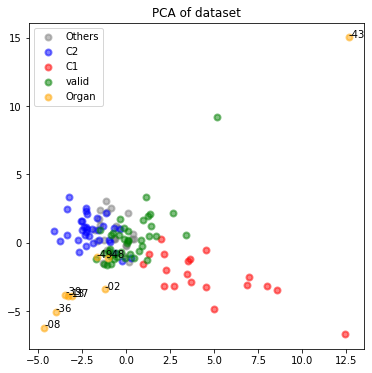

In [1180]:
plt.figure(figsize=(6,6))

lw = 2
y = colData2['Cluster']
labels = colData2['Cluster'].unique()
for color, i, target_name in zip(['gray','blue','red','green','orange'],labels,labels):
    plt.scatter(
        X_r[y == i, 0], X_r[y == i, 1], color=color, alpha=0.5, lw=lw, label=target_name
    )
labels = pd.DataFrame({'Cluster':y,"X1":X_r[:,0],"X2":X_r[:,1]})
for _,row in labels[labels['Cluster']=='Organ'].iterrows():
    plt.text(row['X1'],row['X2'], s=mm[row.name],alpha=1)
plt.legend(loc="best", shadow=False, scatterpoints=1)
plt.title("PCA of dataset")

In [ ]:
best_pred ={
    "1528731":["C1"],
    "1535920":["C1","Others"],
    "1538224":["C1","C2"],
    "1554631":["Others"],
    "1555314":["C1"],
    "1557024":["C1"],
    "1563492":["Others"],
    "1567143":["Others"],
    "1567947":["C2"]
}


In [1226]:
while True:
#     dtc = RandomForestClassifier() #
    dtc = SVC(C=1.5)
    xtrain,xtest,ytrain,ytest = train_test_split(XX, YY, test_size=0.3, stratify=YY.values)

    dtc.fit(xtrain,ytrain)

    print(dtc.score(xtest,ytest))
    p2 = dtc.predict(matv)
    p2 = pd.Series(p2,index=matv.index)
    p = pd.Series(p2).value_counts()
    colData = pd.DataFrame({'Cluster':list(yt) + list(p2.values),'set':labelsall})
    
    _ = colData.loc[organ_uid,:]
    _ = _['Cluster'].to_dict()
    cnt = 0
    for i,j in _.items():
        if j in best_pred[i]:
            cnt +=1
    if cnt > 5:
        break
#     _['ORG'] = pd.Series(mm)
    
    
p

1.0
0.9166666666666666
0.8333333333333334
0.9166666666666666
0.875
0.9583333333333334
0.875
0.9583333333333334
1.0
1.0
0.7916666666666666
0.9166666666666666
0.9166666666666666
0.9166666666666666
0.7916666666666666
0.9583333333333334
0.875
0.9166666666666666
0.9166666666666666
0.9583333333333334
0.9583333333333334
0.9583333333333334
0.9583333333333334
0.9583333333333334
0.9166666666666666
0.875
0.9583333333333334
0.8333333333333334
0.9166666666666666
0.8333333333333334
0.75
0.7916666666666666
0.9166666666666666
0.9166666666666666
0.9583333333333334
0.8333333333333334
0.9166666666666666
0.875
0.9166666666666666
1.0
1.0
0.9166666666666666
0.9583333333333334
0.875
0.875
0.9583333333333334
0.875
0.875
0.7916666666666666
0.7916666666666666
0.9166666666666666
0.9166666666666666
1.0
0.9166666666666666
0.9583333333333334
0.9166666666666666
1.0
0.9166666666666666
0.9166666666666666
0.875
0.9583333333333334
0.9583333333333334
0.875
0.9583333333333334
0.7916666666666666
0.7916666666666666
0.875
0.

Others    33
C1         9
C2         7
Name: count, dtype: int64

In [681]:
matall

,GRHPR,QSOX1,CFAI,MRE11,IF4A2,THSD4,ARHG2,STAB1,CBPB2,YIPF6,CMBL,MMSA,ECI1,PUR6,FA9,MAST4,GOGA4,FKBP4,ARFP1,ARFP2,VIME,MDR1,GSDME,AN32E,AL3A2,ACSL1,NFKB1,PYC,PYGB,RET1,PGRC1
P01,0.423039,-0.511055,-0.344350,-0.057901,-0.500216,-0.445065,-0.106737,-0.573228,0.604870,-0.285366,-0.751048,0.407608,1.157233,-0.588825,0.125557,-0.453076,-0.434944,0.152846,-0.969991,-0.336388,-0.153386,-0.066783,-0.242329,0.341808,1.327024,-0.691610,-0.121278,0.289637,1.523264,-0.587429,1.082392
P02,-0.328207,-0.000912,2.185469,0.276582,-0.503375,0.866370,1.144573,0.758335,0.537648,-0.822495,0.006169,-0.532541,-0.458076,-0.832705,1.053119,-0.267663,-1.063677,-0.385690,-0.731336,-0.562907,0.028921,-0.198835,-1.125538,-0.046413,0.582935,-0.377483,0.271610,-0.330603,-0.167461,-0.449248,0.784019
P03,-0.930429,-0.714820,0.338780,0.480122,1.132531,-0.705472,-0.195852,-1.020592,-1.081979,-0.422674,0.114555,-0.504889,-0.513578,-0.243200,0.635450,-0.633522,0.067714,-0.609092,-0.443281,-0.920250,0.708840,-0.603772,0.110944,1.413777,0.876067,-1.264962,1.252601,-0.990138,0.035577,2.717781,2.389566
P04,-0.657070,-1.367637,0.123011,0.334315,-0.051483,0.560289,-0.339193,-0.348137,-0.073129,-1.158419,-0.198484,-0.531231,-0.541917,-1.534635,0.988727,-0.353827,-0.828475,-0.620717,-1.317662,-0.871404,0.238451,1.837569,0.806548,0.656789,0.744480,-0.697275,0.511189,0.346781,0.063294,0.281039,-0.492508
P05,-0.713588,1.142098,1.119991,-1.038201,-1.077538,0.502657,1.086923,0.812510,0.701183,-0.874802,-1.332479,-0.599578,-0.374668,-0.800784,0.597071,1.875626,-0.392907,-0.759280,0.061745,-1.236662,0.938678,1.307290,1.779612,1.266433,-0.157971,0.290574,1.488840,-0.730061,0.241627,0.604294,0.353581
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1538224,-0.012915,-1.249850,-0.947260,-1.585873,-2.196259,0.661119,-0.858214,-0.232452,2.686166,-2.059588,0.227582,-0.048007,-1.510284,-0.942726,-2.010583,-1.032205,-0.228914,-0.601338,-1.241487,-0.486257,0.823528,-1.301254,-1.630157,-1.167510,-1.312467,-1.444941,-0.509899,-0.444368,-1.749294,-1.073161,-0.135415
1557024,0.000008,-1.253795,-0.944944,-1.551909,-2.233196,0.701731,-0.799313,-0.223434,2.787227,-2.021187,0.290409,-0.274670,-1.485070,-0.897274,-1.992955,-0.992121,-0.179394,-1.293542,-1.214264,-0.405657,0.775661,-1.299501,-1.619085,-1.135867,-1.283114,-1.420272,-0.436827,-0.423483,-1.733589,-1.027125,-0.056332
1555314,-0.296305,-1.085223,-0.992065,-1.312084,-2.303182,1.610269,-0.427749,-0.213510,2.633994,-2.011977,0.473928,0.480364,-1.452885,-0.827317,-1.982497,-1.027679,-0.388630,-0.236219,-0.468120,-1.263485,0.621162,-1.337996,-1.744684,-0.937857,-1.542792,-1.545042,0.043294,-0.555980,-2.103273,-1.497246,-1.305416
1535920,-1.256888,-1.375089,-0.449407,-1.793318,-2.136907,-0.591955,-2.059673,-0.429594,-1.326394,-1.944070,-1.836796,-2.426625,-1.375610,-1.668927,-0.984019,-1.880539,-1.509650,-1.166434,-1.468435,-1.442116,-1.407853,-0.664681,-1.128844,-1.953900,-1.418199,-1.392212,-2.065192,-0.819880,-2.158489,-0.910846,-1.951773


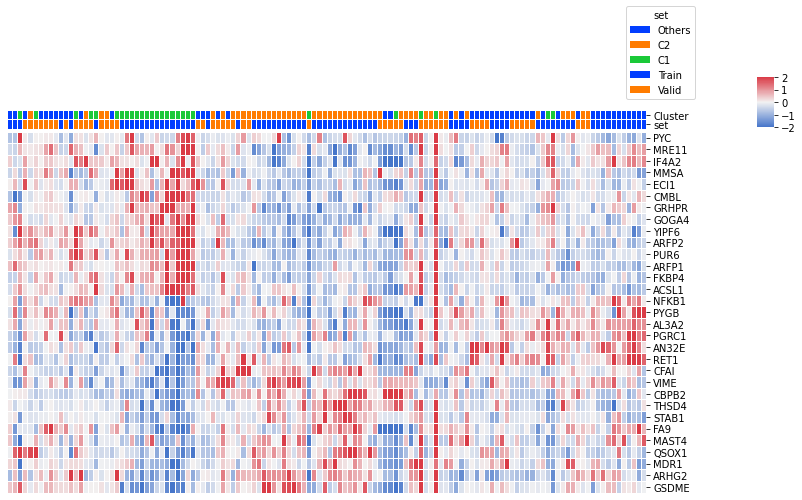

In [1211]:
ax = yplot_heatmap_by_input_matrix(matall.T, colData=colData, bygroup=False
                                  , export = False, prefix='tk', suffix='free', outputdir='report_reply/'
                                  , linewidths=0.5, z_score=None, figsize=(12,7) )

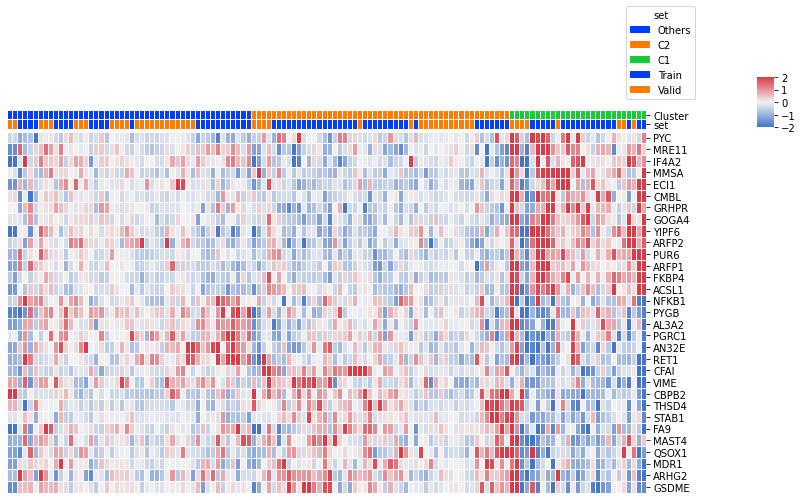

In [1212]:
ax = yplot_heatmap_by_input_matrix(matall.T, colData=colData, bygroup=True
                                  , export = False, prefix='tk', suffix='free', outputdir='report_reply/'
                                  , linewidths=0.5, z_score=None, figsize=(12,7) )

In [1213]:
mat_gsea = db.importing('export_by2_86_pCR_nonpCR/mod_ssgsea_77+52_mat.dfx').loc[:,colData.index]
mat_gsea

[05/20 08:48:19]reading export_by2_86_pCR_nonpCR/mod_ssgsea_77+52_mat.dfx


,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,P16,P17,P18,P19,P20,P21,P22,P23,P24,P25,P26,P27,P28,P29,P30,...,1515051,1516112,1516992,1517415,1518995,1519279,1519610,1524487,1524521,1526829,1530827,1537976,1540897,1544807,1545989,1549428,1550185,1552417,1553097,1556913,1563173,1563492,1567143,1567947,1554631,1538224,1557024,1555314,1535920,1528731
HALLMARK_TNFA_SIGNALING_VIA_NFKB,0.022661,0.150915,0.003253,0.204479,0.189557,0.232344,-0.046177,0.151203,0.114918,-0.024512,0.135109,0.165125,0.220517,0.004839,0.006357,0.017355,0.128388,0.134609,0.025944,0.181745,0.017361,0.130607,0.138236,0.209038,0.222579,0.187987,0.118480,0.207544,0.179989,0.089142,...,0.253960,0.183949,0.272087,0.163785,0.190096,0.054200,0.143674,0.049176,0.224132,0.207084,0.042064,0.043481,0.131360,0.279503,-0.002025,0.201818,0.066370,0.063673,0.255361,0.228492,0.079634,0.014593,0.124861,0.276620,0.136398,0.100467,0.106806,0.090750,0.190441,0.063323
HALLMARK_HYPOXIA,0.091207,0.082616,0.002239,0.097639,0.117977,0.194542,-0.018040,0.065133,0.199147,0.048020,0.140886,0.059633,0.109821,-0.156854,0.122018,-0.057584,0.151016,0.080422,0.088856,0.119991,0.059030,0.038027,0.176126,0.152956,0.232422,0.085768,0.153223,0.075016,0.228871,0.099098,...,0.089281,-0.012441,0.012507,0.021848,0.153402,-0.054421,0.071690,-0.056104,0.166038,0.159127,0.234496,0.133543,0.079696,0.221386,0.056966,-0.042950,0.050780,0.133996,0.163573,0.087409,0.047188,0.144936,0.185098,0.166558,0.165406,0.158205,0.147756,0.187913,0.093635,0.063456
HALLMARK_CHOLESTEROL_HOMEOSTASIS,0.081716,-0.126694,-0.108530,-0.092545,0.083676,0.059954,0.109535,-0.012380,0.126017,0.122421,0.015116,-0.107604,0.063295,0.135075,0.047467,0.201746,0.076138,0.060737,0.004454,-0.061561,-0.071827,-0.031743,0.046714,-0.093016,0.149136,-0.102532,-0.030687,-0.077499,0.113283,-0.054067,...,-0.042629,0.042108,-0.061384,0.085449,0.147415,0.257461,-0.157877,-0.018383,0.275745,0.151941,0.301644,0.117491,-0.025202,0.221333,-0.153234,0.010689,0.126125,0.200028,0.075180,0.073438,-0.035736,0.365840,0.079247,-0.043021,0.054897,0.052255,0.050336,0.060271,0.292624,0.059812
HALLMARK_MITOTIC_SPINDLE,-0.009366,0.006097,0.219912,0.152406,0.116066,0.183618,0.035187,0.137415,0.146633,0.019911,0.192396,0.059679,0.083540,0.006072,0.059216,0.009048,0.029938,-0.012127,0.110945,-0.030956,0.130394,0.154169,0.199342,0.080197,0.126163,0.165172,0.158854,0.083706,0.102906,0.018260,...,0.156168,0.209557,0.016313,0.092172,0.012366,0.126304,0.162420,0.115455,0.048939,0.047521,0.133853,0.194242,0.064768,-0.012621,0.137443,0.172566,0.096874,0.091601,0.031974,-0.014478,0.026564,0.105600,0.140636,0.004572,-0.009454,0.049243,0.048389,0.004004,-0.071108,0.021834
HALLMARK_WNT_BETA_CATENIN_SIGNALING,0.184736,0.022580,0.174208,-0.061687,0.159168,0.267367,0.123854,0.316218,0.190877,-0.054334,0.413786,-0.182336,-0.014392,0.064951,0.193027,-0.028571,0.052084,0.152956,0.162448,-0.150749,0.258043,0.190588,0.297174,-0.008897,0.089863,0.226329,0.092982,0.042087,-0.044167,-0.003096,...,0.286813,0.301791,0.121106,-0.046158,0.051265,0.103902,0.321329,0.333118,-0.047950,0.049703,0.081289,0.048191,-0.049057,-0.087190,0.170017,0.162566,-0.140276,0.214666,0.224225,-0.025664,0.239134,0.387050,0.090754,-0.146173,0.185093,0.164984,0.169077,0.212995,0.354040,0.109283
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Regulatory T cell,0.008138,0.193919,-0.039297,0.050053,0.330159,0.266521,-0.080231,-0.153095,0.101329,-0.059722,0.071908,0.084467,0.062200,-0.137179,-0.177833,-0.173156,0.213313,0.336842,-0.151035,0.094160,-0.177670,0.069394,-0.179233,-0.032456,0.313199,0.252362,0.207895,0.259456,0.388206,0.060717,...,0.092546,0.022440,0.012759,-0.053895,0.100654,0.261816,0.176748,0.002267,-0.153702,0.293244,0.003353,0.158857,0.012471,-0.008979,-0.309997,0.178559,0.335121,-0.143364

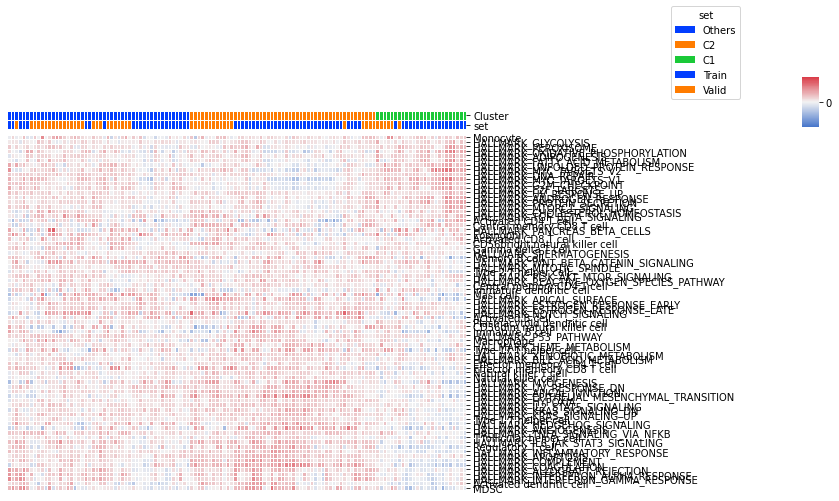

In [2012]:
ax = yplot_heatmap_by_input_matrix(mat_gsea, colData=colData, bygroup=True, vmin = -0.8,vmax=0.8
                                  , export = False, prefix='tk', suffix='free', outputdir='report_reply/'
                                  , linewidths=0.5, z_score=None, figsize=(12,7) )

In [1214]:
dtc

SVC(C=1.5)

In [331]:
import dill

In [1215]:
(np.__version__,
pd.__version__,
dill.__version__)

('1.26.4', '2.2.1', '0.3.6')

In [1216]:
# # dump model
# with open('export_by2_86_pCR_nonpCR/mod_traintest+valid_model.dill','wb') as f:
#     ALL = [dtc, matall, xtrain,xtest,ytrain,ytest,XX,YY, matv,yv, colData, organ_uid]
#     dill.dump(ALL,f)

In [557]:
# load model
with open('export_by2_86_pCR_nonpCR/mod_traintest+valid_model.dill','rb') as f:
    dtc, matall, xtrain,xtest,ytrain,ytest,XX,YY, matv,yv, colData, organ_uid= dill.load(f)

In [469]:
OUTPUTROOT

'report_2914'

In [558]:

matall


,GRHPR,QSOX1,CFAI,MRE11,IF4A2,THSD4,ARHG2,STAB1,CBPB2,YIPF6,CMBL,MMSA,ECI1,PUR6,FA9,MAST4,GOGA4,FKBP4,ARFP1,ARFP2,VIME,MDR1,GSDME,AN32E,AL3A2,ACSL1,NFKB1,PYC,PYGB,RET1,PGRC1
P01,0.359167,-0.463427,-0.348964,-0.093467,-0.547241,-0.424037,-0.071923,-0.552123,0.637822,-0.267514,-0.689893,0.336757,1.082847,-0.612398,0.242152,-0.464620,-0.412943,0.074147,-0.973404,-0.332159,-0.209428,-0.084929,-0.245830,0.344941,1.400660,-0.820878,-0.078645,0.251318,1.639162,-0.536004,1.163880
P02,-0.377277,0.046360,2.209118,0.242022,-0.550486,0.825844,1.136832,0.930569,0.570603,-0.787498,0.040985,-0.579827,-0.508920,-0.847554,1.193219,-0.272269,-1.013040,-0.461153,-0.742780,-0.550517,-0.028147,-0.212919,-1.103998,-0.055195,0.652839,-0.502473,0.307232,-0.363896,-0.081898,-0.399818,0.866399
P03,-0.967634,-0.667050,0.341798,0.446176,1.130231,-0.672221,-0.158007,-1.050262,-1.048979,-0.400439,0.145601,-0.552868,-0.563613,-0.279136,0.764966,-0.651817,0.066821,-0.683212,-0.464417,-0.894985,0.647946,-0.605401,0.097427,1.449808,0.947442,-1.402040,1.270721,-1.018086,0.124783,2.721488,2.467143
P04,-0.699661,-1.319411,0.123618,0.299929,-0.086215,0.534130,-0.296473,-0.301485,-0.040157,-1.112700,-0.156549,-0.578549,-0.591539,-1.524377,1.127195,-0.361657,-0.788551,-0.694767,-1.309375,-0.847899,0.180204,1.760849,0.773309,0.669588,0.815195,-0.826621,0.542536,0.307999,0.152998,0.319926,-0.406309
P05,-0.755065,1.188572,1.131737,-1.076721,-1.140377,0.479202,1.081143,0.990892,0.734133,-0.838136,-1.251100,-0.645183,-0.426727,-0.816775,0.725614,1.951213,-0.372821,-0.832498,0.023614,-1.199997,0.876491,1.246881,1.718784,1.297942,-0.091783,0.174684,1.502744,-0.760117,0.334530,0.638514,0.437249
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1538224,-0.012915,-1.249850,-0.947260,-1.585873,-2.196259,0.661119,-0.858214,-0.232452,2.686166,-2.059588,0.227582,-0.048007,-1.510284,-0.942726,-2.010583,-1.032205,-0.228914,-0.601338,-1.241487,-0.486257,0.823528,-1.301254,-1.630157,-1.167510,-1.312467,-1.444941,-0.509899,-0.444368,-1.749294,-1.073161,-0.135415
1557024,0.000008,-1.253795,-0.944944,-1.551909,-2.233196,0.701731,-0.799313,-0.223434,2.787227,-2.021187,0.290409,-0.274670,-1.485070,-0.897274,-1.992955,-0.992121,-0.179394,-1.293542,-1.214264,-0.405657,0.775661,-1.299501,-1.619085,-1.135867,-1.283114,-1.420272,-0.436827,-0.423483,-1.733589,-1.027125,-0.056332
1555314,-0.296305,-1.085223,-0.992065,-1.312084,-2.303182,1.610269,-0.427749,-0.213510,2.633994,-2.011977,0.473928,0.480364,-1.452885,-0.827317,-1.982497,-1.027679,-0.388630,-0.236219,-0.468120,-1.263485,0.621162,-1.337996,-1.744684,-0.937857,-1.542792,-1.545042,0.043294,-0.555980,-2.103273,-1.497246,-1.305416
1535920,-1.256888,-1.375089,-0.449407,-1.793318,-2.136907,-0.591955,-2.059673,-0.429594,-1.326394,-1.944070,-1.836796,-2.426625,-1.375610,-1.668927,-0.984019,-1.880539,-1.509650,-1.166434,-1.468435,-1.442116,-1.407853,-0.664681,-1.128844,-1.953900,-1.418199,-1.392212,-2.065192,-0.819880,-2.158489,-0.910846,-1.951773


In [341]:

db.exporting(matall, 'export_by2_86_pCR_nonpCR/mod_traintest+valid_fea_mat')
db.exporting(colData, 'export_by2_86_pCR_nonpCR/mod_traintest+valid_fea_colData')
db.exporting(mat_gsea, 'export_by2_86_pCR_nonpCR/mod_traintest+valid_ssgsea_mat')


[05/19 14:56:27] overwritting 1 file with 129 lines at 
	[PROJECT_ROOT]/export_by2_86_pCR_nonpCR/mod_traintest+valid_fea_mat.dfx
[05/19 14:56:27] overwritting 1 file with 129 lines at 
	[PROJECT_ROOT]/export_by2_86_pCR_nonpCR/mod_traintest+valid_fea_colData.dfx
[05/19 14:56:27] writing 1 file with 77 lines at 
	[PROJECT_ROOT]/export_by2_86_pCR_nonpCR/mod_traintest+valid_ssgsea_mat.dfx


#### fig S10 (reply) select 8 heatmap

In [255]:
# best_old = set(HM[1]['F3C3G1660'] + HM[3]['F3C3G88'] + HM[3]['F3C3G257'] + HM[5]['F3C3G18'])
# best_old

{'O00264_PGRMC1',
 'P02747_C1QC',
 'P05156_CFI',
 'P11498_PC',
 'Q02790_FKBP4',
 'Q13361_MFAP5',
 'Q6ZMP0_THSD4',
 'Q92974_ARHGEF2',
 'Q96EC8_YIPF6',
 'Q96IY4_CPB2'}

In [344]:
m = db.importing('export_by2_86_pCR_nonpCR/mod_prt_77x52_sel_31fea_des.dfx')
m

[05/20 01:49:36]reading export_by2_86_pCR_nonpCR/mod_prt_77x52_sel_31fea_des.dfx


,uid,ID,Name
1,Q9UBQ7_GRHPR,Q9UBQ7,GRHPR
2,O00391_QSOX1,O00391,QSOX1
4,P05156_CFI,P05156,CFI
6,P49959_MRE11,P49959,MRE11
7,Q14240_EIF4A2,Q14240,EIF4A2
...,...,...,...
32,P19838_NFKB1,P19838,NFKB1
33,P11498_PC,P11498,PC
34,P11216_PYGB,P11216,PYGB
35,P09455_RBP1,P09455,RBP1


In [345]:
# 2023-10-27 新更新8个featrues
best = {'Q8WVQ1_CANT1','O60443_GSDME'
        ,'P49959_MRE11','P08183_ABCB1'
        ,'P08670_VIM','Q9NY15_STAB1'
        ,'O00264_PGRMC1','P19838_NFKB1'}
best


{'O00264_PGRMC1',
 'O60443_GSDME',
 'P08183_ABCB1',
 'P08670_VIM',
 'P19838_NFKB1',
 'P49959_MRE11',
 'Q8WVQ1_CANT1',
 'Q9NY15_STAB1'}

In [347]:
best - set(m['uid'])

{'Q8WVQ1_CANT1'}

In [346]:
m[m['uid'].isin(best)]

,uid,ID,Name
6,P49959_MRE11,P49959,MRE11
10,Q9NY15_STAB1,Q9NY15,STAB1
25,P08670_VIM,P08670,VIM
26,P08183_ABCB1,P08183,ABCB1
27,O60443_GSDME,O60443,GSDME
32,P19838_NFKB1,P19838,NFKB1
36,O00264_PGRMC1,O00264,PGRMC1


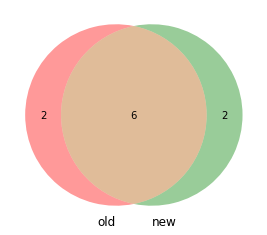

In [260]:
plot_venns(XX.columns,pd.Series(list(best)).str.split('_').str[1], labels=['old','new'])

In [251]:
gs = best
anno = colData.copy()
anno['Clin_classification'] = anno["Y"].apply(lambda i:'Y2' if i==-1 else 'Y1' if i == 1 else 'Others' if i ==0 else 'N/A')


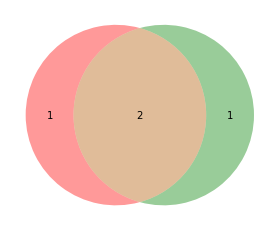

In [252]:
plot_venns(HM[3]['F3C3G88'], HM[3]['F3C3G257'] )

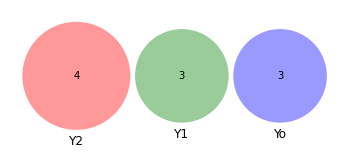

In [253]:
plot_venns(set(HM[3]['F3C3G88']+HM[3]['F3C3G257'] ),HM[1]['F3C3G1660'],HM[5]['F3C3G18'],labels=['Y2','Y1','Yo'])

In [310]:
anno = colData.copy()
anno['Clin_classification'] = anno["Y"].apply(lambda i:'C2' if i==-1 else 'C1' if i == 1 else 'Co' if i ==0 else 'N/A')
display(anno)

col_color = {i:j for i,j in zip(['Co','C1','C2'],['#8A9197', '#F04923', '#3BA9DD'])}
col_color


,Group,Response2,NEPC,Cribriform,RNA_ssGSEA_hm,Protein_ssGSEA_hm,Response_level,Response.Group,Y,Y1,Y2,Yo,Clin_classification
P01,non.pCR,I,1,0,4,4,0,non.pCR,0,0,0,1,Co
P02,non.pCR,I,1,0,4,2,1,non.pCR,-1,0,1,0,C2
P03,non.pCR,I,0,0,3,3,0,non.pCR,0,0,0,1,Co
P04,non.pCR,I,0,0,4,2,1,non.pCR,-1,0,1,0,C2
P05,non.pCR,I,0,0,2,2,1,non.pCR,-1,0,1,0,C2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
P82,non.pCR,II,1,0,1,2,0,non.pCR,-1,0,1,0,C2
P83,non.pCR,II,1,0,2,2,0,non.pCR,-1,0,1,0,C2
P84,non.pCR,I,0,0,4,2,1,non.pCR,-1,0,1,0,C2
P85,non.pCR,II,0,0,2,2,0,non.pCR,-1,0,1,0,C2


{'Co': '#8A9197', 'C1': '#F04923', 'C2': '#3BA9DD'}

report_reply/fig.4D_sel8_grouped.pdf
report_reply/fig.4D_sel8_free.pdf


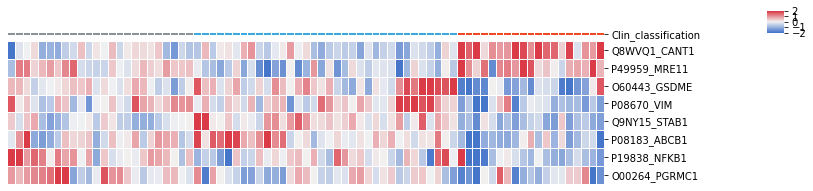

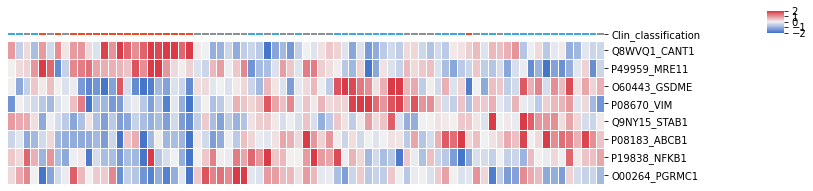

In [414]:
yplot_heatmap_by_input_matrix(mat.loc[:,gs].T, colData=anno , bygroup=True, color_dict = col_color
                                  , export = 'sel8',flag='fig.S10.sel8', suffix='grouped', outputdir='report_reply'
                                  , linewidths=0.5, z_score=None, figsize=(12,3), )


yplot_heatmap_by_input_matrix(mat.loc[:,gs].T, colData=anno , bygroup=False, color_dict = col_color
                                  , export = 'sel8',flag='fig.S10.sel8', suffix='free', outputdir='report_reply'
                                  , linewidths=0.5, z_score=None, figsize=(12,3) )


#### SEL ssgsea ROC

In [515]:
from sklearn.datasets import make_classification
from sklearn.cluster import k_means
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
from itertools import cycle
from sklearn.multiclass import OneVsRestClassifier

from sklearn.decomposition import PCA
import dill


from sklearn.metrics import confusion_matrix, classification_report

from sklearn.tree import DecisionTreeClassifier

from sklearn import metrics
from sklearn.metrics import confusion_matrix, classification_report


In [568]:
class ensemble_cls():
    try:
        COL
    except NameError as e:
        with open('export_big/DTC_30.dill','rb') as f:
            COL = dill.load(f)
    voter1 = COL[13]
    voter2 = COL[21]
    _MAP = {'C1':1,'C2':2,'Others':0}
    _REVMAP = {1:'C1',2:'C2',0:'Others'}
    @staticmethod
    def predict(mat):
        o1 = voter1.predict(mat)
        o2 = voter2.predict(mat)
        v1 = [_MAP[i] for i in o1]
        v2 = [_MAP[i] for i in o2]
        res = [_REVMAP[(i+j)%3] if i!=j else _REVMAP[i] for i,j in zip(v1,v2)]
        return np.array(res)

    @staticmethod
    def score(x, y):
        pass

dtc = ensemble_cls


In [550]:
glx_valid = db.importing('external_info/Cohort_Prospective/data_washed/prt_glx_valid.dfx')
glx_valid['uid'] = glx_valid['uid'].astype(str)
glx_valid = glx_valid.set_index('uid')['Custom_Label'].to_dict()
glx_valid

[07/07 09:51:31]reading external_info/Cohort_Prospective/data_washed/prt_glx_valid.dfx


{'1554631': 'P087',
 '1538224': 'P088',
 '1557024': 'P089',
 '1555314': 'P090',
 '1535920': 'P091',
 '1528731': 'P092',
 '1491165': 'P093',
 '1494425': 'P094',
 '1494688': 'P095',
 '1498899': 'P096',
 '1499496': 'P097',
 '1499777': 'P098',
 '1504457': 'P099',
 '1507100': 'P100',
 '1509204': 'P101',
 '1509451': 'P102',
 '1510339': 'P103',
 '1510436': 'P104',
 '1510834': 'P105',
 '1511128': 'P106',
 '1511292': 'P107',
 '1511700': 'P108',
 '1512209': 'P109',
 '1513118': 'P110',
 '1515049': 'P111',
 '1515051': 'P112',
 '1515949': 'P113',
 '1516112': 'P114',
 '1516992': 'P115',
 '1517415': 'P116',
 '1518995': 'P117',
 '1519279': 'P118',
 '1519610': 'P119',
 '1522368': 'P120',
 '1524487': 'P121',
 '1524521': 'P122',
 '1526829': 'P123',
 '1530827': 'P124',
 '1537976': 'P125',
 '1540897': 'P126',
 '1544807': 'P127',
 '1545989': 'P128',
 '1549428': 'P129',
 '1550185': 'P130',
 '1552417': 'P131',
 '1553097': 'P132',
 '1556913': 'P133',
 '1563173': 'P134',
 '1563492': 'P135',
 '1566005': 'P136',


In [516]:
nepc = db.importing('./external_info/20230427NEPC占比终评（CgA染色）.xlsx',sheet_name=1)
nepc['uid'] = nepc['病理号'].astype(int)
nepc

[07/07 09:44:00]reading ./external_info/20230427NEPC占比终评（CgA染色）.xlsx
  Sheets list: ['所有标本', 'NEPC']
  Read the 2 / 2 sheet named <NEPC>


,病理号,PSA,病理科分级,复核分级by pathologist,备注,重新评级,CgA染色（NEPC占比）,uid
0,1360412,0.0030,1,1,癌细胞（20%）有反应，疑NEPC约~3%,1,0.01,1360412
1,1426798,0.0631,1,1,癌细胞占比50-60%，所有细胞都是小圆形,1,0.15,1426798
2,1372867,0.0030,2,2,癌细胞占比40%，有NEPC（10%）,2,0.15,1372867
3,1428424,0.0190,1,2,癌细胞占比20%，有NEPC,1,0.06,1428424
4,1455040,0.0340,1,2,癌细胞占比50%，疑NEPC,1,0.20,1455040
5,1320203,0.1180,1,2,癌细胞占比65%，基本已空泡化，纤维化，淀粉样变，NEPC~5%,1,0.06,1320203


In [517]:
glx = db.importing('./export_86_7/wes_glx.dfx')
# glx['old_NEPC'] = glx['NEPC']
glx.loc[:,'NEPC'] = 0
glx.loc[glx['uid'].isin(nepc['uid']),'NEPC'] = 1
print(glx['NEPC'].sum())
glx = glx.loc[:,glx.columns!='old_NEPC'].set_index('Tumor_Sample_Barcode')
glx

[07/07 09:44:01]reading ./export_86_7/wes_glx.dfx
6


,a,t,p,uid,Custom_Label,ap,PSA,Treat_Res,NEPC,Cribriform,Group,Response,Response2,Clin_classification,RNA_Cluster,Protein_Cluster,Cluster,endocrine_therapy,therapy_month,ARi_type,Thpy_class
Tumor_Sample_Barcode,,,,,,,,,,,,,,,,,,,,,
P001,K00143,TR22030713,P010143142842401,1428424,P001,K00143P010143142842401,0.019,1,1,0,C4,non.pCR,I,1,C4,C4,C4,戈舍瑞林+阿比特龙+泼尼松,6,2,>3
P002,K00144,TR22030669,P010144144820001,1448200,P002,K00144P010144144820001,0.024,1,0,0,C2,non.pCR,I,1,C2,C2,C2,戈舍瑞林+比卡鲁胺,3,1,≤3
P003,K00145,TR22030670,P010145141850101,1418501,P003,K00145P010145141850101,0.006,1,0,0,C3,non.pCR,I,1,C4,C3,C3,戈舍瑞林+比卡鲁胺,18,1,>3
P004,K00146,TR22030671,P010146141521801,1415218,P004,K00146P010146141521801,0.310,1,0,0,C2,non.pCR,I,1,C4,C2,C2,戈舍瑞林+比卡鲁胺,3,1,≤3
P005,K00147,TR22030672,P010147140043801,1400438,P005,K00147P010147140043801,0.006,1,0,0,C2,non.pCR,I,1,C2,C2,C2,戈舍瑞林+阿比特龙+泼尼松,3,2,≤3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P082,K00265,TR22303747,P010265146210101,1462101,P082,K00265P010265146210101,4.010,2,0,0,C2,non.pCR,II,2,C3,C2,C2,戈舍瑞林+比卡鲁胺,6,1,>3
P083,K00266,TR22303743,P010266147461501,1474615,P083,K00266P010266147461501,0.208,2,0,0,C2,non.pCR,II,2,C1,C2,C2,戈舍瑞林+比卡鲁胺,3,1,≤3
P084,K00267,TR22303734,P010267145448901,1454489,P084,K00267P010267145448901,0.246,1,0,0,C2,non.pCR,I,1,C2,C2,C2,戈舍瑞林+比卡鲁胺,3,1,≤3


In [518]:
anno = glx.copy()
anno['Group'] = anno['Response']
anno['Clin_classification'] = ['Others' if i =='C3' or i=='C4' else i for i in anno['Protein_Cluster']]
anno

,a,t,p,uid,Custom_Label,ap,PSA,Treat_Res,NEPC,Cribriform,Group,Response,Response2,Clin_classification,RNA_Cluster,Protein_Cluster,Cluster,endocrine_therapy,therapy_month,ARi_type,Thpy_class
Tumor_Sample_Barcode,,,,,,,,,,,,,,,,,,,,,
P001,K00143,TR22030713,P010143142842401,1428424,P001,K00143P010143142842401,0.019,1,1,0,non.pCR,non.pCR,I,Others,C4,C4,C4,戈舍瑞林+阿比特龙+泼尼松,6,2,>3
P002,K00144,TR22030669,P010144144820001,1448200,P002,K00144P010144144820001,0.024,1,0,0,non.pCR,non.pCR,I,C2,C2,C2,C2,戈舍瑞林+比卡鲁胺,3,1,≤3
P003,K00145,TR22030670,P010145141850101,1418501,P003,K00145P010145141850101,0.006,1,0,0,non.pCR,non.pCR,I,Others,C4,C3,C3,戈舍瑞林+比卡鲁胺,18,1,>3
P004,K00146,TR22030671,P010146141521801,1415218,P004,K00146P010146141521801,0.310,1,0,0,non.pCR,non.pCR,I,C2,C4,C2,C2,戈舍瑞林+比卡鲁胺,3,1,≤3
P005,K00147,TR22030672,P010147140043801,1400438,P005,K00147P010147140043801,0.006,1,0,0,non.pCR,non.pCR,I,C2,C2,C2,C2,戈舍瑞林+阿比特龙+泼尼松,3,2,≤3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P082,K00265,TR22303747,P010265146210101,1462101,P082,K00265P010265146210101,4.010,2,0,0,non.pCR,non.pCR,II,C2,C3,C2,C2,戈舍瑞林+比卡鲁胺,6,1,>3
P083,K00266,TR22303743,P010266147461501,1474615,P083,K00266P010266147461501,0.208,2,0,0,non.pCR,non.pCR,II,C2,C1,C2,C2,戈舍瑞林+比卡鲁胺,3,1,≤3
P084,K00267,TR22303734,P010267145448901,1454489,P084,K00267P010267145448901,0.246,1,0,0,non.pCR,non.pCR,I,C2,C2,C2,C2,戈舍瑞林+比卡鲁胺,3,1,≤3


In [ ]:
hm = db.importing()

In [521]:
mat_ss = db.importing('external_info/Proteomics52/washed/prt_ssgsea_hm.dfx')

mat_ss.columns = [glx_valid[i] for i in mat_ss.columns]
mat_ss

[07/07 09:44:40]reading external_info/Cohort_Prospective/data_washed/prt_ssgsea_mat.dfx


,P087,P088,P089,P090,P091,P092,P093,P094,P095,P096,P097,P098,P099,P100,P101,P102,P103,P104,P105,P106,P107,P108,P109,P110,P111,P112,P113,P114,P115,P116,P117,P118,P119,P120,P121,P122,P123,P124,P125,P126,P127,P128,P129,P130,P131,P132,P133,P134,P135,P136,P137,P138
HALLMARK_ADIPOGENESIS,0.094798,0.103430,0.027652,0.068734,0.003276,0.104567,0.041840,0.009355,0.134889,0.053406,0.062193,0.144665,0.003334,0.020110,0.057585,0.097305,0.080375,0.046915,0.056579,0.055786,0.049043,0.009457,-0.004521,0.055336,-0.003035,-0.048480,0.117438,-0.040548,0.061420,0.039967,0.026069,0.022132,-0.031928,0.091381,0.005774,0.020547,0.065912,0.071154,0.099146,0.096884,0.023731,0.148357,0.071363,0.019099,0.087454,-0.032408,-0.021530,0.012970,0.062222,0.113023,-0.011210,-0.023614
HALLMARK_ALLOGRAFT_REJECTION,0.063369,0.072039,0.115266,0.201255,0.073561,0.080801,-0.086594,0.154012,-0.001616,-0.023900,0.129337,-0.058623,0.088333,0.058336,0.051642,0.001376,0.008023,0.033654,0.046789,0.011020,0.033456,0.003220,0.005989,-0.052491,0.087723,0.043226,-0.003302,-0.022268,0.083022,-0.037596,0.065015,0.022433,0.202770,-0.013351,0.029039,-0.138913,0.015596,-0.028633,0.119481,0.068075,0.018201,-0.030182,0.029590,0.076997,-0.051379,0.104770,0.012149,0.100755,0.043832,-0.121734,-0.009849,0.158605
HALLMARK_ANDROGEN_RESPONSE,0.101711,0.067691,0.001340,0.110520,0.121592,0.123736,0.020603,-0.022605,0.015983,0.026426,0.031011,0.059085,0.073218,0.096709,-0.060453,0.046918,0.085802,-0.016054,0.062250,0.032409,0.116003,0.139542,0.150569,-0.069193,-0.035161,0.129991,-0.056402,0.232902,0.112347,-0.058087,0.076872,-0.068518,-0.008628,0.082070,-0.060423,0.087333,0.035170,-0.058896,0.009179,0.000641,-0.076012,0.071880,-0.021594,0.069447,0.029047,-0.049610,0.087591,-0.056872,0.064018,0.159939,0.024383,-0.033316
HALLMARK_ANGIOGENESIS,0.014744,0.041954,0.044628,0.140107,0.022363,0.074944,0.263497,0.106635,-0.140809,-0.226392,0.081957,-0.060387,0.075919,0.199963,0.109908,-0.009425,0.127527,0.308973,0.022170,0.055863,0.092343,-0.012178,-0.001833,-0.132632,-0.160390,-0.063963,0.068923,-0.084975,-0.124483,-0.231007,-0.259898,0.053330,-0.313858,0.060274,0.108899,-0.254298,0.239449,-0.007867,0.233171,0.107071,-0.088520,-0.095136,0.021574,0.338726,0.088480,-0.092876,0.008389,0.073206,0.133858,-0.179013,0.114530,-0.038830
HALLMARK_APICAL_JUNCTION,0.004599,-0.022622,0.007765,0.021807,0.092842,-0.088510,0.200287,0.039143,-0.079471,-0.045213,0.099926,0.127952,0.028024,0.061235,0.041137,0.094656,0.146470,0.075615,0.099509,0.148847,0.119256,0.079510,0.128538,0.086988,-0.070446,0.097900,0.122339,0.030240,-0.054113,0.023151,0.089686,0.093846,0.116347,0.113666,0.032839,-0.008332,0.217434,0.102223,0.162534,0.136089,0.011756,0.015460,0.125022,0.106797,0.041254,-0.013313,0.007286,0.003791,0.114108,0.084531,0.162159,0.089183
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Plasmacytoid dendritic cell,0.173513,0.196102,0.004067,0.245671,0.118072,0.201768,-0.070985,0.006290,-0.059166,-0.032916,0.091611,-0.175645,0.068818,-0.037618,-0.014351,-0.077294,0.029846,-0.066770,0.065396,0.058670,0.021000,-0.026830,-0.109656,0.028178,0.035987,-0.058323,-0.042010,-0.065030,-0.024930,-0.083066,-0.017110,-0.070424,0.172602,-0.004609,-0.025942,-0.037165,0.029022,0.023841,-0.003016,-0.017083,0.019760,-0.019360,0.127596,-0.017565,0.029530,0.124773,-0.027537,0.021350,-0.008416,0.024857,0.083381,0.083849
Regulatory T cell,-0.037886,0.083433,0.145357,0.100057,0.401245,0.047684,0.051262,0.110395,0.006380,0.271845,0.023327,0.050582,-0.123784,0.223206,0.101121,-0.115772,0.193246,-0.190420,0.204434,0.173091,0.082297,0.272135,0.103914,0.075638,0.038445,0.311812,0.087219,0.028498,0.200349,0.036619,-0.022472,0.015513,0.323067,-0.100847,0.105956,-0.062611,0.030397,-0.215781,0.145089,0.097308,-0.122135,0.038671,0.235543,0.228300,-0.089251,0.100838,0.074791,0.054659,-0.019256,-

In [ ]:
pd.Series.str.match()

In [527]:
matt

,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_HYPOXIA,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_MITOTIC_SPINDLE,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_DNA_REPAIR,HALLMARK_G2M_CHECKPOINT,HALLMARK_APOPTOSIS,HALLMARK_NOTCH_SIGNALING,HALLMARK_ADIPOGENESIS,HALLMARK_ESTROGEN_RESPONSE_EARLY,HALLMARK_ESTROGEN_RESPONSE_LATE,HALLMARK_ANDROGEN_RESPONSE,HALLMARK_MYOGENESIS,HALLMARK_PROTEIN_SECRETION,HALLMARK_INTERFERON_ALPHA_RESPONSE,HALLMARK_INTERFERON_GAMMA_RESPONSE,HALLMARK_APICAL_JUNCTION,HALLMARK_APICAL_SURFACE,HALLMARK_HEDGEHOG_SIGNALING,HALLMARK_COMPLEMENT,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,HALLMARK_PI3K_AKT_MTOR_SIGNALING,HALLMARK_MTORC1_SIGNALING,HALLMARK_E2F_TARGETS,HALLMARK_MYC_TARGETS_V1,HALLMARK_MYC_TARGETS_V2,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,...,HALLMARK_KRAS_SIGNALING_DN,HALLMARK_PANCREAS_BETA_CELLS,Activated B cell,Activated CD4 T cell,Activated CD8 T cell,Activated dendritic cell,CD56bright natural killer cell,CD56dim natural killer cell,Central memory CD4 T cell,Central memory CD8 T cell,Effector memeory CD4 T cell,Effector memeory CD8 T cell,Eosinophil,Gamma delta T cell,Immature B cell,Immature dendritic cell,Macrophage,Mast cell,MDSC,Memory B cell,Monocyte,Natural killer cell,Natural killer T cell,Neutrophil,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 17 T helper cell,Type 2 T helper cell
P16,0.017355,-0.057584,0.201746,0.009048,-0.028571,0.232973,0.014416,0.146096,0.180783,0.004957,-0.019835,0.133250,0.052696,0.000326,0.256330,-0.274790,0.277903,-0.019846,-0.071459,-0.173587,-0.255946,-0.126958,-0.114999,0.234710,0.167023,0.228749,0.151208,0.254713,0.251607,-0.258588,...,-0.031692,0.252028,-0.119515,0.313162,0.170656,0.060336,-0.000239,0.085765,-0.194596,0.136065,0.067991,0.072195,0.097445,0.062986,-0.124212,0.062649,0.021582,-0.289942,-0.012514,-0.085377,0.194692,-0.020855,-0.110900,0.076521,0.079434,-0.161302,-0.041637,-0.069048,0.089780,-0.146618
P52,-0.113971,0.024556,0.232992,-0.075770,-0.039805,0.165653,-0.059094,0.240450,0.178359,0.028940,-0.033258,0.168059,0.017396,-0.042115,0.371736,-0.297375,0.323686,0.006486,-0.015278,-0.140100,-0.227180,-0.086418,-0.128121,0.241388,0.054955,0.232253,0.162222,0.290965,0.346337,-0.147505,...,-0.015195,0.155211,-0.369640,0.284707,0.067668,0.055514,0.096344,0.180600,-0.066756,0.063931,0.038015,-0.184013,0.134469,-0.074698,0.034716,0.044769,-0.012397,0.133842,-0.051569,-0.185290,0.157208,-0.083116,-0.138658,0.175342,0.046257,-0.069097,-0.174884,-0.038549,-0.257348,-0.055126
P72,0.027023,0.019653,0.354119,-0.070810,-0.049400,0.051833,-0.044716,0.241891,0.337223,0.078507,-0.102023,0.254503,0.042865,0.062653,0.400328,-0.323779,0.333683,0.096741,0.074725,-0.148214,-0.080738,-0.254484,-0.070832,0.350701,0.133139,0.366767,0.383567,0.515731,0.518466,-0.361263,...,-0.089070,0.209939,0.099283,0.190921,0.070803,0.093763,0.032365,0.049744,0.011605,0.207197,0.025360,-0.095730,0.074294,0.041902,-0.119516,-0.014283,0.046070,-0.133765,-0.086313,-0.388434,0.121627,-0.029440,-0.034909,-0.208673,0.072097,-0.224902,0.025345,-0.093688,-0.216950,-0.175166
P65,-0.043837,0.127440,0.204038,0.009678,0.083338,0.108605,-0.020648,0.146833,0.114268,0.180582,-0.174368,0.360177,-0.015682,0.073982,0.244986,-0.144846,0.266242,-0.039434,0.028179,-0.073825,-0.299057,-0.076206,-0.034521,0.126245,0.216517,0.304022,0.161334,0.316776,0.378083,-0.065585,...,-0.119412,0.183703,-0.269378,0.231109,0.111263,-0.023558,0.050826,-0.030889,-0.000511,0.133707,-0.059380,-0.159118,0.284278,-0.023199,-0.132212,0.085759,0.070905,-0.226494,-0.130164,-0.186701,0.028434,-0.058099,0.007595,0.207414,0.023634,-0.089206,0.039002,-0.055545,-0.116497,-0.106040
P10,-0.024512,0.048020,0.122421,0.019911,-0.054334,0.249016,0.059383,0.173922,0.105019,0.105555,-0.259305,0.176599,0.019567,-0.016768,0.257956,-0.114027,0.333794,0.118006,0.116821,-0.043706,-0.010062,-0.018533,-0.013736,0.206756,0.188117,0.330755,0.212671,0

In [531]:
matt = db.importing('export_by2_86_pCR_nonpCR/mod_ssgsea_77_mat.dfx').T
if matt.index.str.match('^P\d{2}').all():
    matt.index = matt.index.str.replace('P','P0',regex=False)
matt

[07/07 09:47:53]reading export_by2_86_pCR_nonpCR/mod_ssgsea_77_mat.dfx


,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_HYPOXIA,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_MITOTIC_SPINDLE,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_DNA_REPAIR,HALLMARK_G2M_CHECKPOINT,HALLMARK_APOPTOSIS,HALLMARK_NOTCH_SIGNALING,HALLMARK_ADIPOGENESIS,HALLMARK_ESTROGEN_RESPONSE_EARLY,HALLMARK_ESTROGEN_RESPONSE_LATE,HALLMARK_ANDROGEN_RESPONSE,HALLMARK_MYOGENESIS,HALLMARK_PROTEIN_SECRETION,HALLMARK_INTERFERON_ALPHA_RESPONSE,HALLMARK_INTERFERON_GAMMA_RESPONSE,HALLMARK_APICAL_JUNCTION,HALLMARK_APICAL_SURFACE,HALLMARK_HEDGEHOG_SIGNALING,HALLMARK_COMPLEMENT,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,HALLMARK_PI3K_AKT_MTOR_SIGNALING,HALLMARK_MTORC1_SIGNALING,HALLMARK_E2F_TARGETS,HALLMARK_MYC_TARGETS_V1,HALLMARK_MYC_TARGETS_V2,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,...,HALLMARK_KRAS_SIGNALING_DN,HALLMARK_PANCREAS_BETA_CELLS,Activated B cell,Activated CD4 T cell,Activated CD8 T cell,Activated dendritic cell,CD56bright natural killer cell,CD56dim natural killer cell,Central memory CD4 T cell,Central memory CD8 T cell,Effector memeory CD4 T cell,Effector memeory CD8 T cell,Eosinophil,Gamma delta T cell,Immature B cell,Immature dendritic cell,Macrophage,Mast cell,MDSC,Memory B cell,Monocyte,Natural killer cell,Natural killer T cell,Neutrophil,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 17 T helper cell,Type 2 T helper cell
P016,0.017355,-0.057584,0.201746,0.009048,-0.028571,0.232973,0.014416,0.146096,0.180783,0.004957,-0.019835,0.133250,0.052696,0.000326,0.256330,-0.274790,0.277903,-0.019846,-0.071459,-0.173587,-0.255946,-0.126958,-0.114999,0.234710,0.167023,0.228749,0.151208,0.254713,0.251607,-0.258588,...,-0.031692,0.252028,-0.119515,0.313162,0.170656,0.060336,-0.000239,0.085765,-0.194596,0.136065,0.067991,0.072195,0.097445,0.062986,-0.124212,0.062649,0.021582,-0.289942,-0.012514,-0.085377,0.194692,-0.020855,-0.110900,0.076521,0.079434,-0.161302,-0.041637,-0.069048,0.089780,-0.146618
P052,-0.113971,0.024556,0.232992,-0.075770,-0.039805,0.165653,-0.059094,0.240450,0.178359,0.028940,-0.033258,0.168059,0.017396,-0.042115,0.371736,-0.297375,0.323686,0.006486,-0.015278,-0.140100,-0.227180,-0.086418,-0.128121,0.241388,0.054955,0.232253,0.162222,0.290965,0.346337,-0.147505,...,-0.015195,0.155211,-0.369640,0.284707,0.067668,0.055514,0.096344,0.180600,-0.066756,0.063931,0.038015,-0.184013,0.134469,-0.074698,0.034716,0.044769,-0.012397,0.133842,-0.051569,-0.185290,0.157208,-0.083116,-0.138658,0.175342,0.046257,-0.069097,-0.174884,-0.038549,-0.257348,-0.055126
P072,0.027023,0.019653,0.354119,-0.070810,-0.049400,0.051833,-0.044716,0.241891,0.337223,0.078507,-0.102023,0.254503,0.042865,0.062653,0.400328,-0.323779,0.333683,0.096741,0.074725,-0.148214,-0.080738,-0.254484,-0.070832,0.350701,0.133139,0.366767,0.383567,0.515731,0.518466,-0.361263,...,-0.089070,0.209939,0.099283,0.190921,0.070803,0.093763,0.032365,0.049744,0.011605,0.207197,0.025360,-0.095730,0.074294,0.041902,-0.119516,-0.014283,0.046070,-0.133765,-0.086313,-0.388434,0.121627,-0.029440,-0.034909,-0.208673,0.072097,-0.224902,0.025345,-0.093688,-0.216950,-0.175166
P065,-0.043837,0.127440,0.204038,0.009678,0.083338,0.108605,-0.020648,0.146833,0.114268,0.180582,-0.174368,0.360177,-0.015682,0.073982,0.244986,-0.144846,0.266242,-0.039434,0.028179,-0.073825,-0.299057,-0.076206,-0.034521,0.126245,0.216517,0.304022,0.161334,0.316776,0.378083,-0.065585,...,-0.119412,0.183703,-0.269378,0.231109,0.111263,-0.023558,0.050826,-0.030889,-0.000511,0.133707,-0.059380,-0.159118,0.284278,-0.023199,-0.132212,0.085759,0.070905,-0.226494,-0.130164,-0.186701,0.028434,-0.058099,0.007595,0.207414,0.023634,-0.089206,0.039002,-0.055545,-0.116497,-0.106040
P010,-0.024512,0.048020,0.122421,0.019911,-0.054334,0.249016,0.059383,0.173922,0.105019,0.105555,-0.259305,0.176599,0.019567,-0.016768,0.257956,-0.114027,0.333794,0.118006,0.116821,-0.043706,-0.010062,-0.018533,-0.013736,0.206756,0.188117,0.330755,0.212

In [533]:
info_v = db.importing('external_info/Organoids/organoid_and_verification/前瞻性队列临床病理信息总结20240504_v3.0（完善病理信息）.xlsx')
info_v['uid'] = info_v['病理号'].astype(str)
info_v['Custom_Label'] = [glx_valid[i] for i in info_v['uid']]
exclude = info_v.loc[info_v['pT stage']=='pCR','Custom_Label'].values
exclude

[07/07 09:49:05]reading external_info/Organoids/organoid_and_verification/前瞻性队列临床病理信息总结20240504_v3.0（完善病理信息）.xlsx
  Sheets list: ['Sheet1']
  Read the 1 / 1 sheet named <Sheet1>


array(['P136', 'P120', 'P113'], dtype=object)

In [534]:
matv = mat_ss.copy().T
matv = matv.loc[~matv.index.isin(exclude),:]
matv


,HALLMARK_ADIPOGENESIS,HALLMARK_ALLOGRAFT_REJECTION,HALLMARK_ANDROGEN_RESPONSE,HALLMARK_ANGIOGENESIS,HALLMARK_APICAL_JUNCTION,HALLMARK_APICAL_SURFACE,HALLMARK_APOPTOSIS,HALLMARK_BILE_ACID_METABOLISM,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_COAGULATION,HALLMARK_COMPLEMENT,HALLMARK_DNA_REPAIR,HALLMARK_E2F_TARGETS,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,HALLMARK_ESTROGEN_RESPONSE_EARLY,HALLMARK_ESTROGEN_RESPONSE_LATE,HALLMARK_FATTY_ACID_METABOLISM,HALLMARK_G2M_CHECKPOINT,HALLMARK_GLYCOLYSIS,HALLMARK_HEDGEHOG_SIGNALING,HALLMARK_HEME_METABOLISM,HALLMARK_HYPOXIA,HALLMARK_IL2_STAT5_SIGNALING,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_INFLAMMATORY_RESPONSE,HALLMARK_INTERFERON_ALPHA_RESPONSE,HALLMARK_INTERFERON_GAMMA_RESPONSE,HALLMARK_KRAS_SIGNALING_DN,HALLMARK_KRAS_SIGNALING_UP,HALLMARK_MITOTIC_SPINDLE,...,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,HALLMARK_UV_RESPONSE_DN,HALLMARK_UV_RESPONSE_UP,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_XENOBIOTIC_METABOLISM,Activated B cell,Activated CD4 T cell,Activated CD8 T cell,Activated dendritic cell,CD56bright natural killer cell,Central memory CD4 T cell,Central memory CD8 T cell,Effector memeory CD4 T cell,Effector memeory CD8 T cell,Gamma delta T cell,Immature dendritic cell,Macrophage,Mast cell,MDSC,Memory B cell,Monocyte,Natural killer cell,Natural killer T cell,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 2 T helper cell
P087,0.094798,0.063369,0.101711,0.014744,0.004599,0.488049,0.142458,0.070095,0.033404,0.024078,0.039617,0.108110,0.047227,-0.028617,0.012065,0.034873,0.102197,0.050827,0.103030,-0.191228,0.006822,0.064321,0.009466,-0.019264,0.084288,0.089804,0.012654,0.308384,-0.077852,0.141947,...,-0.010203,0.020382,-0.025271,-0.037068,0.085238,0.319198,0.020244,-0.171379,-0.279968,0.388243,0.022275,0.082533,-0.247874,0.145742,0.068292,0.324825,0.118398,0.143655,0.142833,0.303170,0.142725,0.023240,-0.257037,0.107848,0.124989,0.173513,-0.037886,0.108341,-0.154823,-0.416859
P088,0.103430,0.072039,0.067691,0.041954,-0.022622,0.475713,0.139545,0.112900,0.053760,0.070788,0.098012,0.075828,0.079731,0.001868,0.004717,0.020614,0.071036,0.091912,0.119072,-0.144980,0.032976,0.139164,0.057563,0.021426,0.131846,0.131888,0.085932,0.172323,-0.039346,0.120171,...,-0.030346,0.060020,-0.009296,-0.022516,0.102305,0.136469,0.048375,-0.242993,-0.358854,0.351894,0.303719,0.062197,-0.156953,-0.102777,0.063650,0.484917,0.067268,0.199496,0.174578,0.129930,0.200779,0.052405,-0.254048,0.147749,0.268142,0.196102,0.083433,0.098334,-0.109516,-0.409898
P089,0.027652,0.115266,0.001340,0.044628,0.007765,-0.427911,-0.000102,0.066004,-0.014390,0.107641,0.113350,0.005059,0.142430,0.029486,-0.066291,-0.084125,0.015536,0.116148,0.041775,0.420495,0.021698,0.120720,-0.058761,-0.093561,-0.046201,0.102932,0.084958,-0.146442,0.114715,-0.033214,...,-0.127711,0.079984,0.065431,-0.140731,-0.013433,-0.227448,0.027083,0.007150,0.159319,-0.152358,-0.234808,-0.106904,-0.173280,0.237334,-0.311241,-0.112915,0.083565,0.026101,-0.097678,-0.421499,-0.076396,0.439489,0.022012,0.000575,0.243518,0.004067,0.145357,0.281172,0.283807,-0.080433
P090,0.068734,0.201255,0.110520,0.140107,0.021807,0.228219,0.145569,0.089605,0.083771,0.115378,0.112316,0.068104,0.085005,-0.018625,0.006429,0.046550,0.066939,0.100896,0.044765,-0.102619,0.017047,0.065442,0.010752,0.112868,0.136152,0.133727,0.099376,-0.051139,-0.017064,0.130859,...,-0.026636,0.049342,0.033267,-0.046881,0.064597,0.272167,0.047155,-0.101215,-0.375869,0.389017,0.421387,0.013693,-0.045185,0.147605,-0.086320,0.358081,0.072465,0.249500,0.348451,0.180974,0.191230,0.087264,-0.194621,0.098441,0.291997,0.245671,0.100057,0.126200,0.044139,-0.453982
P091,0.003276,0.073561,0.121592,0.022363,0.092842,0.037779,0.100544,0.097548,0.193834,0.172340,0.194732,0.038359,0.019945,0.180393,0.192297,0.109977,-0.058497,0.118579,0.010208,0.040736,-0.013878,0.140810,0.159842,0.058863,-0.278365,0.050007,0.068

In [535]:
yt = anno[anno['Group']=='non.pCR']['Clin_classification']
yt

Tumor_Sample_Barcode
P001    Others
P002        C2
P003    Others
P004        C2
P005        C2
         ...  
P082        C2
P083        C2
P084        C2
P085        C2
P086        C2
Name: Clin_classification, Length: 77, dtype: object

In [536]:
matt = matt.loc[yt.index,matv.columns]
matt


,HALLMARK_ADIPOGENESIS,HALLMARK_ALLOGRAFT_REJECTION,HALLMARK_ANDROGEN_RESPONSE,HALLMARK_ANGIOGENESIS,HALLMARK_APICAL_JUNCTION,HALLMARK_APICAL_SURFACE,HALLMARK_APOPTOSIS,HALLMARK_BILE_ACID_METABOLISM,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_COAGULATION,HALLMARK_COMPLEMENT,HALLMARK_DNA_REPAIR,HALLMARK_E2F_TARGETS,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,HALLMARK_ESTROGEN_RESPONSE_EARLY,HALLMARK_ESTROGEN_RESPONSE_LATE,HALLMARK_FATTY_ACID_METABOLISM,HALLMARK_G2M_CHECKPOINT,HALLMARK_GLYCOLYSIS,HALLMARK_HEDGEHOG_SIGNALING,HALLMARK_HEME_METABOLISM,HALLMARK_HYPOXIA,HALLMARK_IL2_STAT5_SIGNALING,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_INFLAMMATORY_RESPONSE,HALLMARK_INTERFERON_ALPHA_RESPONSE,HALLMARK_INTERFERON_GAMMA_RESPONSE,HALLMARK_KRAS_SIGNALING_DN,HALLMARK_KRAS_SIGNALING_UP,HALLMARK_MITOTIC_SPINDLE,...,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,HALLMARK_UV_RESPONSE_DN,HALLMARK_UV_RESPONSE_UP,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_XENOBIOTIC_METABOLISM,Activated B cell,Activated CD4 T cell,Activated CD8 T cell,Activated dendritic cell,CD56bright natural killer cell,Central memory CD4 T cell,Central memory CD8 T cell,Effector memeory CD4 T cell,Effector memeory CD8 T cell,Gamma delta T cell,Immature dendritic cell,Macrophage,Mast cell,MDSC,Memory B cell,Monocyte,Natural killer cell,Natural killer T cell,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 2 T helper cell
Tumor_Sample_Barcode,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
P001,0.126638,0.074637,0.020085,-0.015686,0.157679,0.245465,0.214680,0.008837,0.081716,0.279176,0.161117,0.133009,0.156089,0.103643,0.167404,0.177005,0.150482,0.144519,0.097282,0.049182,0.121107,0.091207,0.026213,0.081935,0.086848,0.191769,0.142450,0.187347,0.166789,-0.009366,...,-0.081509,0.022661,0.017984,0.170702,0.083729,0.184736,0.059915,0.249311,-0.377603,0.122279,-0.089037,0.039078,0.127286,0.097829,0.049951,0.083183,0.015861,0.183164,0.050453,0.186585,0.023903,0.128525,-0.156038,0.099613,0.129707,0.053262,0.007581,0.126016,0.089989,0.162087
P002,0.041123,0.188312,0.040942,0.314344,0.126977,0.124125,0.191690,0.021362,-0.126694,0.388007,0.214286,0.006072,0.005382,0.123791,0.099629,0.224127,-0.092507,0.076754,0.093892,0.225576,-0.063493,0.082616,0.044693,0.245637,0.066333,0.348971,0.338557,0.276492,0.191354,0.006097,...,0.024921,0.150915,0.100976,0.058803,0.002829,0.022580,0.106016,0.231143,0.013494,-0.016430,0.037400,0.111200,0.075067,0.038504,-0.022286,-0.056606,0.056776,0.076632,0.143560,0.244927,0.185639,0.048815,0.013154,0.044508,0.065593,0.099435,0.180644,0.117305,0.175953,0.085536
P003,-0.001274,-0.063303,-0.154018,0.043574,0.055773,0.159586,0.054615,0.101614,-0.108530,-0.095707,-0.003349,0.149498,0.178072,-0.012600,-0.047890,0.006720,-0.107581,0.135504,-0.087959,0.043613,0.004958,0.002239,0.016843,-0.044700,0.048148,0.110515,0.031491,-0.000880,0.064961,0.219912,...,0.124641,0.003253,-0.046197,0.159595,-0.044561,0.174208,0.085555,-0.180907,-0.208864,0.043244,-0.081049,-0.082139,0.058855,-0.065547,-0.068684,0.125716,-0.038420,0.090349,0.027856,-0.096467,-0.154909,-0.017156,0.068394,0.039908,0.073207,-0.036356,-0.036607,0.001837,0.100879,0.139593
P004,0.095334,0.144622,0.056604,0.011330,0.221448,0.174547,0.088901,-0.010775,-0.092545,0.212799,0.168263,0.087980,0.051118,0.147448,0.064007,0.031069,-0.020457,0.034410,-0.020666,0.089116,-0.022024,0.097639,0.119317,0.138513,0.062685,0.072272,0.076070,0.038998,0.012496,0.152406,...,-0.093833,0.204479,0.059010,0.186469,0.138388,-0.061687,-0.000771,0.231038,-0.254441,0.032152,0.026280,-0.039536,0.083427,0.024456,-0.047576,0.159978,0.061030,0.069635,0.200056,-0.071290,0.283744,-0.006536,0.056670,0.003763,0.063805,0.007712,0.046626,0.000705,0.081275,0.099943
P005,-0.009961,0.251757,-0.068170,0.140099,0.172583,0.013317,0.270294,0.153919,0.083676,0.357624,0.378677,0.097710,-0.034518,0.207055,0.151769,0.102177,-0.108033,-0.101383,-0.01

In [537]:
assert (matv.columns == matt.columns).all()

In [538]:
XX = matt
YY = yt
assert (XX.index==YY.index).all()
XX


,HALLMARK_ADIPOGENESIS,HALLMARK_ALLOGRAFT_REJECTION,HALLMARK_ANDROGEN_RESPONSE,HALLMARK_ANGIOGENESIS,HALLMARK_APICAL_JUNCTION,HALLMARK_APICAL_SURFACE,HALLMARK_APOPTOSIS,HALLMARK_BILE_ACID_METABOLISM,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_COAGULATION,HALLMARK_COMPLEMENT,HALLMARK_DNA_REPAIR,HALLMARK_E2F_TARGETS,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,HALLMARK_ESTROGEN_RESPONSE_EARLY,HALLMARK_ESTROGEN_RESPONSE_LATE,HALLMARK_FATTY_ACID_METABOLISM,HALLMARK_G2M_CHECKPOINT,HALLMARK_GLYCOLYSIS,HALLMARK_HEDGEHOG_SIGNALING,HALLMARK_HEME_METABOLISM,HALLMARK_HYPOXIA,HALLMARK_IL2_STAT5_SIGNALING,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_INFLAMMATORY_RESPONSE,HALLMARK_INTERFERON_ALPHA_RESPONSE,HALLMARK_INTERFERON_GAMMA_RESPONSE,HALLMARK_KRAS_SIGNALING_DN,HALLMARK_KRAS_SIGNALING_UP,HALLMARK_MITOTIC_SPINDLE,...,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,HALLMARK_UV_RESPONSE_DN,HALLMARK_UV_RESPONSE_UP,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_XENOBIOTIC_METABOLISM,Activated B cell,Activated CD4 T cell,Activated CD8 T cell,Activated dendritic cell,CD56bright natural killer cell,Central memory CD4 T cell,Central memory CD8 T cell,Effector memeory CD4 T cell,Effector memeory CD8 T cell,Gamma delta T cell,Immature dendritic cell,Macrophage,Mast cell,MDSC,Memory B cell,Monocyte,Natural killer cell,Natural killer T cell,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 2 T helper cell
Tumor_Sample_Barcode,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
P001,0.126638,0.074637,0.020085,-0.015686,0.157679,0.245465,0.214680,0.008837,0.081716,0.279176,0.161117,0.133009,0.156089,0.103643,0.167404,0.177005,0.150482,0.144519,0.097282,0.049182,0.121107,0.091207,0.026213,0.081935,0.086848,0.191769,0.142450,0.187347,0.166789,-0.009366,...,-0.081509,0.022661,0.017984,0.170702,0.083729,0.184736,0.059915,0.249311,-0.377603,0.122279,-0.089037,0.039078,0.127286,0.097829,0.049951,0.083183,0.015861,0.183164,0.050453,0.186585,0.023903,0.128525,-0.156038,0.099613,0.129707,0.053262,0.007581,0.126016,0.089989,0.162087
P002,0.041123,0.188312,0.040942,0.314344,0.126977,0.124125,0.191690,0.021362,-0.126694,0.388007,0.214286,0.006072,0.005382,0.123791,0.099629,0.224127,-0.092507,0.076754,0.093892,0.225576,-0.063493,0.082616,0.044693,0.245637,0.066333,0.348971,0.338557,0.276492,0.191354,0.006097,...,0.024921,0.150915,0.100976,0.058803,0.002829,0.022580,0.106016,0.231143,0.013494,-0.016430,0.037400,0.111200,0.075067,0.038504,-0.022286,-0.056606,0.056776,0.076632,0.143560,0.244927,0.185639,0.048815,0.013154,0.044508,0.065593,0.099435,0.180644,0.117305,0.175953,0.085536
P003,-0.001274,-0.063303,-0.154018,0.043574,0.055773,0.159586,0.054615,0.101614,-0.108530,-0.095707,-0.003349,0.149498,0.178072,-0.012600,-0.047890,0.006720,-0.107581,0.135504,-0.087959,0.043613,0.004958,0.002239,0.016843,-0.044700,0.048148,0.110515,0.031491,-0.000880,0.064961,0.219912,...,0.124641,0.003253,-0.046197,0.159595,-0.044561,0.174208,0.085555,-0.180907,-0.208864,0.043244,-0.081049,-0.082139,0.058855,-0.065547,-0.068684,0.125716,-0.038420,0.090349,0.027856,-0.096467,-0.154909,-0.017156,0.068394,0.039908,0.073207,-0.036356,-0.036607,0.001837,0.100879,0.139593
P004,0.095334,0.144622,0.056604,0.011330,0.221448,0.174547,0.088901,-0.010775,-0.092545,0.212799,0.168263,0.087980,0.051118,0.147448,0.064007,0.031069,-0.020457,0.034410,-0.020666,0.089116,-0.022024,0.097639,0.119317,0.138513,0.062685,0.072272,0.076070,0.038998,0.012496,0.152406,...,-0.093833,0.204479,0.059010,0.186469,0.138388,-0.061687,-0.000771,0.231038,-0.254441,0.032152,0.026280,-0.039536,0.083427,0.024456,-0.047576,0.159978,0.061030,0.069635,0.200056,-0.071290,0.283744,-0.006536,0.056670,0.003763,0.063805,0.007712,0.046626,0.000705,0.081275,0.099943
P005,-0.009961,0.251757,-0.068170,0.140099,0.172583,0.013317,0.270294,0.153919,0.083676,0.357624,0.378677,0.097710,-0.034518,0.207055,0.151769,0.102177,-0.108033,-0.101383,-0.01

In [539]:
yt

Tumor_Sample_Barcode
P001    Others
P002        C2
P003    Others
P004        C2
P005        C2
         ...  
P082        C2
P083        C2
P084        C2
P085        C2
P086        C2
Name: Clin_classification, Length: 77, dtype: object

In [540]:
# from sklearn.datasets import make_classification
# from sklearn.cluster import k_means
# from sklearn.model_selection import train_test_split
# from sklearn.linear_model import LogisticRegression
# from sklearn.tree import DecisionTreeClassifier
# from sklearn.ensemble import RandomForestClassifier
# from sklearn.metrics import roc_curve, roc_auc_score, auc
# from sklearn.preprocessing import label_binarize
# import matplotlib.pyplot as plt
# from itertools import cycle
# from sklearn.multiclass import OneVsRestClassifier
# from sklearn.decomposition import PCA



In [545]:
matall = pd.concat([matt,matv],axis=0)
matall

,HALLMARK_ADIPOGENESIS,HALLMARK_ALLOGRAFT_REJECTION,HALLMARK_ANDROGEN_RESPONSE,HALLMARK_ANGIOGENESIS,HALLMARK_APICAL_JUNCTION,HALLMARK_APICAL_SURFACE,HALLMARK_APOPTOSIS,HALLMARK_BILE_ACID_METABOLISM,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_COAGULATION,HALLMARK_COMPLEMENT,HALLMARK_DNA_REPAIR,HALLMARK_E2F_TARGETS,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,HALLMARK_ESTROGEN_RESPONSE_EARLY,HALLMARK_ESTROGEN_RESPONSE_LATE,HALLMARK_FATTY_ACID_METABOLISM,HALLMARK_G2M_CHECKPOINT,HALLMARK_GLYCOLYSIS,HALLMARK_HEDGEHOG_SIGNALING,HALLMARK_HEME_METABOLISM,HALLMARK_HYPOXIA,HALLMARK_IL2_STAT5_SIGNALING,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_INFLAMMATORY_RESPONSE,HALLMARK_INTERFERON_ALPHA_RESPONSE,HALLMARK_INTERFERON_GAMMA_RESPONSE,HALLMARK_KRAS_SIGNALING_DN,HALLMARK_KRAS_SIGNALING_UP,HALLMARK_MITOTIC_SPINDLE,...,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,HALLMARK_UV_RESPONSE_DN,HALLMARK_UV_RESPONSE_UP,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_XENOBIOTIC_METABOLISM,Activated B cell,Activated CD4 T cell,Activated CD8 T cell,Activated dendritic cell,CD56bright natural killer cell,Central memory CD4 T cell,Central memory CD8 T cell,Effector memeory CD4 T cell,Effector memeory CD8 T cell,Gamma delta T cell,Immature dendritic cell,Macrophage,Mast cell,MDSC,Memory B cell,Monocyte,Natural killer cell,Natural killer T cell,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 2 T helper cell
P001,0.126638,0.074637,0.020085,-0.015686,0.157679,0.245465,0.214680,0.008837,0.081716,0.279176,0.161117,0.133009,0.156089,0.103643,0.167404,0.177005,0.150482,0.144519,0.097282,0.049182,0.121107,0.091207,0.026213,0.081935,0.086848,0.191769,0.142450,0.187347,0.166789,-0.009366,...,-0.081509,0.022661,0.017984,0.170702,0.083729,0.184736,0.059915,0.249311,-0.377603,0.122279,-0.089037,0.039078,0.127286,0.097829,0.049951,0.083183,0.015861,0.183164,0.050453,0.186585,0.023903,0.128525,-0.156038,0.099613,0.129707,0.053262,0.007581,0.126016,0.089989,0.162087
P002,0.041123,0.188312,0.040942,0.314344,0.126977,0.124125,0.191690,0.021362,-0.126694,0.388007,0.214286,0.006072,0.005382,0.123791,0.099629,0.224127,-0.092507,0.076754,0.093892,0.225576,-0.063493,0.082616,0.044693,0.245637,0.066333,0.348971,0.338557,0.276492,0.191354,0.006097,...,0.024921,0.150915,0.100976,0.058803,0.002829,0.022580,0.106016,0.231143,0.013494,-0.016430,0.037400,0.111200,0.075067,0.038504,-0.022286,-0.056606,0.056776,0.076632,0.143560,0.244927,0.185639,0.048815,0.013154,0.044508,0.065593,0.099435,0.180644,0.117305,0.175953,0.085536
P003,-0.001274,-0.063303,-0.154018,0.043574,0.055773,0.159586,0.054615,0.101614,-0.108530,-0.095707,-0.003349,0.149498,0.178072,-0.012600,-0.047890,0.006720,-0.107581,0.135504,-0.087959,0.043613,0.004958,0.002239,0.016843,-0.044700,0.048148,0.110515,0.031491,-0.000880,0.064961,0.219912,...,0.124641,0.003253,-0.046197,0.159595,-0.044561,0.174208,0.085555,-0.180907,-0.208864,0.043244,-0.081049,-0.082139,0.058855,-0.065547,-0.068684,0.125716,-0.038420,0.090349,0.027856,-0.096467,-0.154909,-0.017156,0.068394,0.039908,0.073207,-0.036356,-0.036607,0.001837,0.100879,0.139593
P004,0.095334,0.144622,0.056604,0.011330,0.221448,0.174547,0.088901,-0.010775,-0.092545,0.212799,0.168263,0.087980,0.051118,0.147448,0.064007,0.031069,-0.020457,0.034410,-0.020666,0.089116,-0.022024,0.097639,0.119317,0.138513,0.062685,0.072272,0.076070,0.038998,0.012496,0.152406,...,-0.093833,0.204479,0.059010,0.186469,0.138388,-0.061687,-0.000771,0.231038,-0.254441,0.032152,0.026280,-0.039536,0.083427,0.024456,-0.047576,0.159978,0.061030,0.069635,0.200056,-0.071290,0.283744,-0.006536,0.056670,0.003763,0.063805,0.007712,0.046626,0.000705,0.081275,0.099943
P005,-0.009961,0.251757,-0.068170,0.140099,0.172583,0.013317,0.270294,0.153919,0.083676,0.357624,0.378677,0.097710,-0.034518,0.207055,0.151769,0.102177,-0.108033,-0.101383,-0.015703,0.172126,0.049869,0.117977,0.245417,0.107395,0.406072,0.272445,0.277203,0.132

In [546]:
labelsall = pd.Series(['Valid','Train'])[matall.index.str.startswith('P').astype(int)]
labelsall.index = matall.index
labelsall

P001    Train
P002    Train
P003    Train
P004    Train
P005    Train
        ...  
P133    Train
P134    Train
P135    Train
P137    Train
P138    Train
Length: 126, dtype: object

In [547]:
pca = PCA(n_components=2)
X_r = pca.fit_transform(matall)

In [548]:
colData2 = colData.copy()
colData2.loc[colData2['set']=='Valid','Cluster'] = 'valid'
colData2.loc[organ_uid,'Cluster'] = 'Organ'
colData2

,Cluster,set
P01,Others,Train
P02,C2,Train
P03,Others,Train
P04,C2,Train
P05,C2,Train
...,...,...
1556913,valid,Valid
1563173,valid,Valid
1563492,Organ,Valid
1567143,Organ,Valid


In [221]:
labels = colData2['Cluster'].unique()
labels

array(['Others', 'C2', 'C1', 'Organ', 'valid'], dtype=object)

In [506]:
pca = PCA(n_components=2)
X_r = pca.fit_transform(matall)
mm = {
    "1528731":"-02",
    "1535920":"-08",
    "1538224":"-13",
    "1554631":"-36",
    "1555314":"-37",
    "1557024":"-39",
    "1563492":"-43",
    "1567143":"-48",
    "1567947":"-49"
}
mm = {i:'-'+glx_valid[i] for i in mm.keys()}
mm

{'1528731': '-P092',
 '1535920': '-P091',
 '1538224': '-P088',
 '1554631': '-P087',
 '1555314': '-P090',
 '1557024': '-P089',
 '1563492': '-P135',
 '1567143': '-P137',
 '1567947': '-P138'}

Text(0.5, 1.0, 'PCA of dataset')

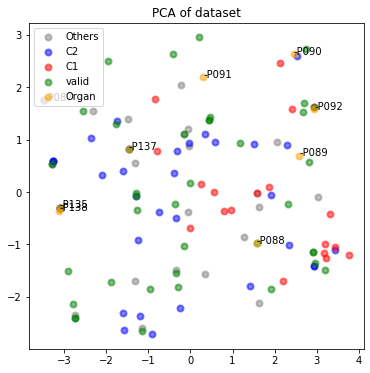

In [507]:
plt.figure(figsize=(6,6))

lw = 2
y = colData2['Cluster']
labels = colData2['Cluster'].unique()
for color, i, target_name in zip(['gray','blue','red','green','orange'],labels,labels):
    plt.scatter(
        X_r[y == i, 0], X_r[y == i, 1], color=color, alpha=0.5, lw=lw, label=target_name
    )
labels = pd.DataFrame({'Cluster':y,"X1":X_r[:,0],"X2":X_r[:,1]})
for _,row in labels[labels['Cluster']=='Organ'].iterrows():
    plt.text(row['X1'],row['X2'], s=mm[row.name],alpha=1)
plt.legend(loc="best", shadow=False, scatterpoints=1)
plt.title("PCA of dataset")


In [224]:
matt

,HALLMARK_ADIPOGENESIS,HALLMARK_ALLOGRAFT_REJECTION,HALLMARK_ANDROGEN_RESPONSE,HALLMARK_ANGIOGENESIS,HALLMARK_APICAL_JUNCTION,HALLMARK_APICAL_SURFACE,HALLMARK_APOPTOSIS,HALLMARK_BILE_ACID_METABOLISM,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_COAGULATION,...,MDSC,Memory B cell,Monocyte,Natural killer cell,Natural killer T cell,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 2 T helper cell
Tumor_Sample_Barcode,,,,,,,,,,,,,,,,,,,,,
P01,0.126638,0.074637,0.020085,-0.015686,0.157679,0.245465,0.214680,0.008837,0.081716,0.279176,...,0.023903,0.128525,-0.156038,0.099613,0.129707,0.053262,0.007581,0.126016,0.089989,0.162087
P02,0.041123,0.188312,0.040942,0.314344,0.126977,0.124125,0.191690,0.021362,-0.126694,0.388007,...,0.185639,0.048815,0.013154,0.044508,0.065593,0.099435,0.180644,0.117305,0.175953,0.085536
P03,-0.001274,-0.063303,-0.154018,0.043574,0.055773,0.159586,0.054615,0.101614,-0.108530,-0.095707,...,-0.154909,-0.017156,0.068394,0.039908,0.073207,-0.036356,-0.036607,0.001837,0.100879,0.139593
P04,0.095334,0.144622,0.056604,0.011330,0.221448,0.174547,0.088901,-0.010775,-0.092545,0.212799,...,0.283744,-0.006536,0.056670,0.003763,0.063805,0.007712,0.046626,0.000705,0.081275,0.099943
P05,-0.009961,0.251757,-0.068170,0.140099,0.172583,0.013317,0.270294,0.153919,0.083676,0.357624,...,0.492671,0.127687,0.136210,0.108621,0.162313,0.080111,0.307557,0.121933,0.161333,0.034317
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P82,0.112981,-0.006067,0.172443,0.281101,0.094204,-0.017025,0.180607,0.028059,0.040634,0.244273,...,-0.117522,0.009274,-0.059046,0.112277,0.157892,0.081214,0.100455,0.058398,0.090819,-0.089744
P83,0.045524,0.116518,0.130200,0.029926,0.097528,0.132613,0.186863,0.107196,0.157853,0.299945,...,0.241070,0.210211,-0.036925,0.066883,0.147748,0.134352,-0.019459,0.016438,0.044241,-0.002845
P84,0.049503,-0.027447,0.012867,0.293915,0.235866,0.213403,0.266981,0.107490,0.052249,0.395151,...,0.024920,0.166121,0.037890,0.132872,0.126653,0.063256,0.197220,0.125649,0.167422,0.156547


**k_mean method**

In [225]:
import numpy as np

clusters = yt.unique()

# Initialize an array to store the cluster centers
cluster_centers = np.zeros((len(clusters), matt.shape[1]))
# Iterate over each cluster
for i in range(len(clusters)):
    tag = clusters[i]
    # Find the indices of data points that belong to the current cluster
    cluster_indices = yt==tag
    
    # Calculate the center of the current cluster as the mean of data points in that cluster
    cluster_center = np.mean(matt.loc[cluster_indices,:], axis=0)
    
    # Store the cluster center in the array
    cluster_centers[i] = cluster_center
cluster_centers = pd.DataFrame(cluster_centers,index=clusters, columns=matt.columns).T


def cal_cos_sim(A,B):
    dot_product = np.dot(A, B)
    norm_A = np.linalg.norm(A)
    norm_B = np.linalg.norm(B)

    cosine_similarity = dot_product / (norm_A * norm_B)
    return cosine_similarity

cluster_centers

,Others,C2,C1
HALLMARK_ADIPOGENESIS,0.037175,0.079739,0.159207
HALLMARK_ALLOGRAFT_REJECTION,0.061487,0.153068,-0.017628
HALLMARK_ANDROGEN_RESPONSE,0.041900,0.068898,0.222609
HALLMARK_ANGIOGENESIS,-0.023697,0.237830,-0.078599
HALLMARK_APICAL_JUNCTION,0.104275,0.180980,-0.009400
...,...,...,...
Plasmacytoid dendritic cell,0.029245,0.062074,0.021877
Regulatory T cell,0.028483,0.153018,-0.113870
T follicular helper cell,0.019221,0.083224,-0.024757
Type 1 T helper cell,0.053127,0.116279,-0.032658


In [226]:
v1 = cluster_centers['C1'].values
v2 = cluster_centers['C2'].values
v3 = cluster_centers['Others'].values
pred = []
for sid in matv.index:
    sample = matv.loc[sid,:].values
    r = np.array([cal_cos_sim(sample,v1),cal_cos_sim(sample,v2),cal_cos_sim(sample,v3)])
    pred.append([sid,['C1','C2','Others'][r.argmin()]] + r.tolist())
pred = pd.DataFrame(pred,columns=['uid','PredC','v1','v2','v3']).set_index('uid')
pred

,PredC,v1,v2,v3
uid,,,,
1554631,C1,0.141909,0.288254,0.328688
1538224,C1,0.031014,0.382259,0.365240
1557024,C2,0.156713,0.023089,0.048989
1555314,C1,0.101093,0.431844,0.414902
1535920,C1,-0.087854,0.509590,0.459476
1528731,C2,0.283495,0.117334,0.188869
1491165,C1,-0.081293,0.504228,0.293130
1494425,C1,-0.019956,0.399973,0.365962
1494688,C2,0.421026,-0.139639,0.068133


In [227]:
pred.loc[organ_uid,:]

,PredC,v1,v2,v3
uid,,,,
1528731,C2,0.283495,0.117334,0.188869
1535920,C1,-0.087854,0.509590,0.459476
1538224,C1,0.031014,0.382259,0.365240
1554631,C1,0.141909,0.288254,0.328688
1555314,C1,0.101093,0.431844,0.414902
1557024,C2,0.156713,0.023089,0.048989
1563492,C2,0.205662,0.174628,0.238764
1567143,C1,-0.025926,0.230910,0.252439
1567947,C1,-0.042903,0.233185,0.298046


In [228]:
organ_uid = ["1528731","1535920","1538224","1554631","1555314","1557024","1563492","1567143","1567947"]


**SVC / RF model**

In [229]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import CategoricalNB, GaussianNB


In [258]:
len(matv)

49

In [259]:
_ = YY.value_counts()
_ / _.sum() * 49

Clin_classification
C2        21.636364
Others    15.272727
C1        12.090909
Name: count, dtype: float64

In [348]:
# # save model 保存模型
# import dill

# with open('export_big/DTCs.dill','wb') as f:
#     dill.dump({'gausi_naive_bayes':nb_dtc,'SVC':svc_dtc,'random_forest':rf_dtc},f)

with open('export_big/DTCs.dill','rb') as f:
    DTCs = dill.load(f)
    svc_dtc = DTCs['SVC']
    nb_dtc = DTCs['gausi_naive_bayes']
    rf_dtc = DTCs['random_forest']
    


In [2054]:
pd.__version__, dill.__version__


('2.2.1', '0.3.6')

In [2055]:
!python -V

Python 3.9.7


In [357]:
COL = []

In [360]:
chosen = {'score':0.5,'C1':0}
sel = matv.index=='1528731'
mask = matv.index.isin(mm.keys())
i = 0
add = 0
while True:
    i += 1
#     dtc = GaussianNB()
#     dtc = SVC(C=1,probability=True) 
    dtc = RandomForestClassifier(n_estimators = 20, max_depth = 3)

    xtrain,xtest,ytrain,ytest = train_test_split(XX, YY, test_size=0.3, stratify=YY.values)

    dtc.fit(xtrain,ytrain)

    ypred = dtc.predict(xtest)
    cm = confusion_matrix(ytest,ypred)
    cm = pd.DataFrame(cm, index=dtc.classes_,columns=dtc.classes_)
    cm.index.name = 'GroundTruth'
    PPV = cm.apply(lambda x: x[x.name] / x.sum(),0)[['C1','C2']].mean()
    yv = dtc.predict(matv)
    p = pd.Series(yv).value_counts()
    if 'C1' not in p:
        continue

    if i==10000:
        break
#     if 'C1' in pd.Series(yv)[mask].values:
#     if PPV > chosen['score'] or p['C1'] >= chosen['C1']:
#         chosen = {'model':dtc,'score':PPV,'cm':cm,'C1':p['C1'],'xtest':xtest,'ytest':ytest}
    if PPV > 0.9 and p['C1']> 5 and p['C2'] > 10 and 'C1' in pd.Series(yv)[mask].values:
        print(f"PPV = {PPV}, #C1 = {p['C1']}")
        COL.append(dtc)
        add +=1
        if add >= 10:
            break



PPV = 0.9583333333333333, #C1 = 14
PPV = 0.9230769230769231, #C1 = 7
PPV = 0.95, #C1 = 10
PPV = 0.9583333333333333, #C1 = 12
PPV = 1.0, #C1 = 22
PPV = 0.95, #C1 = 7
PPV = 0.9545454545454546, #C1 = 12
PPV = 0.9230769230769231, #C1 = 6
PPV = 0.9166666666666667, #C1 = 13
PPV = 0.9545454545454546, #C1 = 15


In [ ]:
# chosen = {'score':0.5,'C1':0}
# sel = matv.index=='1528731'
# mask = matv.index.isin(mm.keys())
# i = 0
# COL = []
# while True:
#     i += 1
# #     dtc = SVC(C=1,probability=True) 
#     dtc = RandomForestClassifier(n_estimators = 20, max_depth = 3)
# #     dtc = GaussianNB()

#     xtrain,xtest,ytrain,ytest = train_test_split(XX, YY, test_size=0.3, stratify=YY.values)

#     dtc.fit(xtrain,ytrain)

# #     print(dtc.score(xtest,ytest))
# #     p2 = dtc.predict(matv)
# #     p2 = pd.Series(p2,index=matv.index)
# #     p = pd.Series(p2).value_counts()

#     ypred = dtc.predict(xtest)
#     cm = confusion_matrix(ytest,ypred)
#     cm = pd.DataFrame(cm, index=dtc.classes_,columns=dtc.classes_)
#     cm.index.name = 'GroundTruth'
#     PPV = cm.apply(lambda x: x[x.name] / x.sum(),0)[['C1','C2']].mean()
#     yv = dtc.predict(matv)
#     p = pd.Series(yv).value_counts()
#     if 'C1' not in p:
# #         print(f'    {i} No C1 in yv, skip')
#         continue
# #     if i%100 == 0:
# #         print(f"{i}, PPV = {PPV}, #C1 = {p['C1']}")
# #     if p['Others'] <= 26 and p['C1'] > 5 :
# #     if 'C1' in p and p['C1']>5: 
#     if i==10000:
#         break
# #     if 'C1' in pd.Series(yv)[mask].values:
#     if PPV > chosen['score'] or p['C1'] >= chosen['C1']:
#         chosen = {'model':dtc,'score':PPV,'cm':cm,'C1':p['C1'],'xtest':xtest,'ytest':ytest}

#         if PPV > 0.85 and p['C1']> 5 and p['C2'] > 10 and 'C1' in pd.Series(yv)[mask].values:
#             print(f"PPV = {PPV}, #C1 = {p['C1']}")
#             COL.append(dtc)
#             if len(COL) >= 10:
#                 break
#         #             yv = dtc.predict(matv)
#         #             if yv[sel][0] == 'C1':
        
    
# #     if (p2.loc[["1538224","1554631",'1563492']].values=='C1').any() and p['C1'] >= 2:
# #         break

# #     _ = colData.loc[organ_uid,:]
# #     _ = _['Cluster'].to_dict()
# #     cnt = 0
# #     for i,j in _.items():
# #         if j in best_pred[i]:
# #             cnt +=1
# #     if cnt > 5:
# #         break


In [352]:
len(COL)

10

In [509]:
xtest = chosen['xtest']
ytest = chosen['ytest']
ypred = dtc.predict(xtest)
cm = confusion_matrix(ytest,ypred)
cm = pd.DataFrame(cm, index=dtc.classes_,columns=dtc.classes_)
cm.index.name = 'GroundTruth'
PPV = cm.apply(lambda x: x[x.name] / x.sum(),0)[['C1','C2']].mean()
print(f"PPV = {PPV}")
cm

PPV = 0.9375


,C1,C2,Others
GroundTruth,,,
C1,4,0,2
C2,0,7,4
Others,0,1,6


In [510]:
ypred = dtc.predict(matt)
cm = confusion_matrix(yt,ypred)
cm = pd.DataFrame(cm, index=dtc.classes_,columns=dtc.classes_)
cm.index.name = 'GroundTruth'
PPV = cm.apply(lambda x: x[x.name] / x.sum(),0)[['C1','C2']].mean()
print(f"PPV = {PPV}")
cm

PPV = 0.9549808429118773


,C1,C2,Others
GroundTruth,,,
C1,17,0,2
C2,0,28,6
Others,1,1,22


In [566]:
yv = dtc.predict(matv)

colData = pd.DataFrame({'Cluster':list(yt) + list(yv),'set':labelsall})
colData


[python_env]/lib/pythonX/site-packages/sklearn/base.py:493: FutureWarning:

The feature names should match those that were passed during fit. Starting version 1.2, an error will be raised.
Feature names seen at fit time, yet now missing:
- Activated CD8 T cell




ValueError: X has 72 features, but SVC is expecting 73 features as input.

In [512]:
_ = colData.loc[organ_uid,:]
_['ORG'] = pd.Series(mm)
_

,Cluster,set,ORG
1528731,C2,Valid,-P092
1535920,C2,Valid,-P091
1538224,C2,Valid,-P088
1554631,Others,Valid,-P087
1555314,C2,Valid,-P090
1557024,C2,Valid,-P089
1563492,Others,Valid,-P135
1567143,C2,Valid,-P137
1567947,Others,Valid,-P138


In [513]:

# matall needs to be updated
assert (colData.index == matall.index).all()
colData2 = colData.copy()
colData2.loc[colData2['set']=='Valid','Cluster'] = 'valid'
colData2.loc[organ_uid,'Cluster'] = 'Organ'

pca = PCA(n_components=2)
X_r = pca.fit_transform(matall)


fig = plt.figure(figsize=(6,6))
lw = 1.5
m_cluster = {"C1":'#F04923',"C2":'#3BA9DD',"Others":'#8A9197'}
m_set = {'Train':'x','Valid':'o'}

for i in range(len(colData)):
    c, s = colData.iloc[i,:]
    plt.scatter(
        X_r[i, 0], X_r[i, 1], color=m_cluster[c],marker=m_set[s],
        alpha=0.75, lw=lw
    )
labels = pd.DataFrame({'Cluster':colData2['Cluster'].values,"X1":X_r[:,0],"X2":X_r[:,1]},index=matall.index)
for _,row in labels[labels['Cluster']=='Organ'].iterrows():
    plt.text(row['X1'],row['X2'], s=mm[row.name],alpha=1)
plt.legend(loc="best", shadow=False, scatterpoints=1)
plt.title("PCA of dataset")


AssertionError: 

'RandomForestClassifier'

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that 

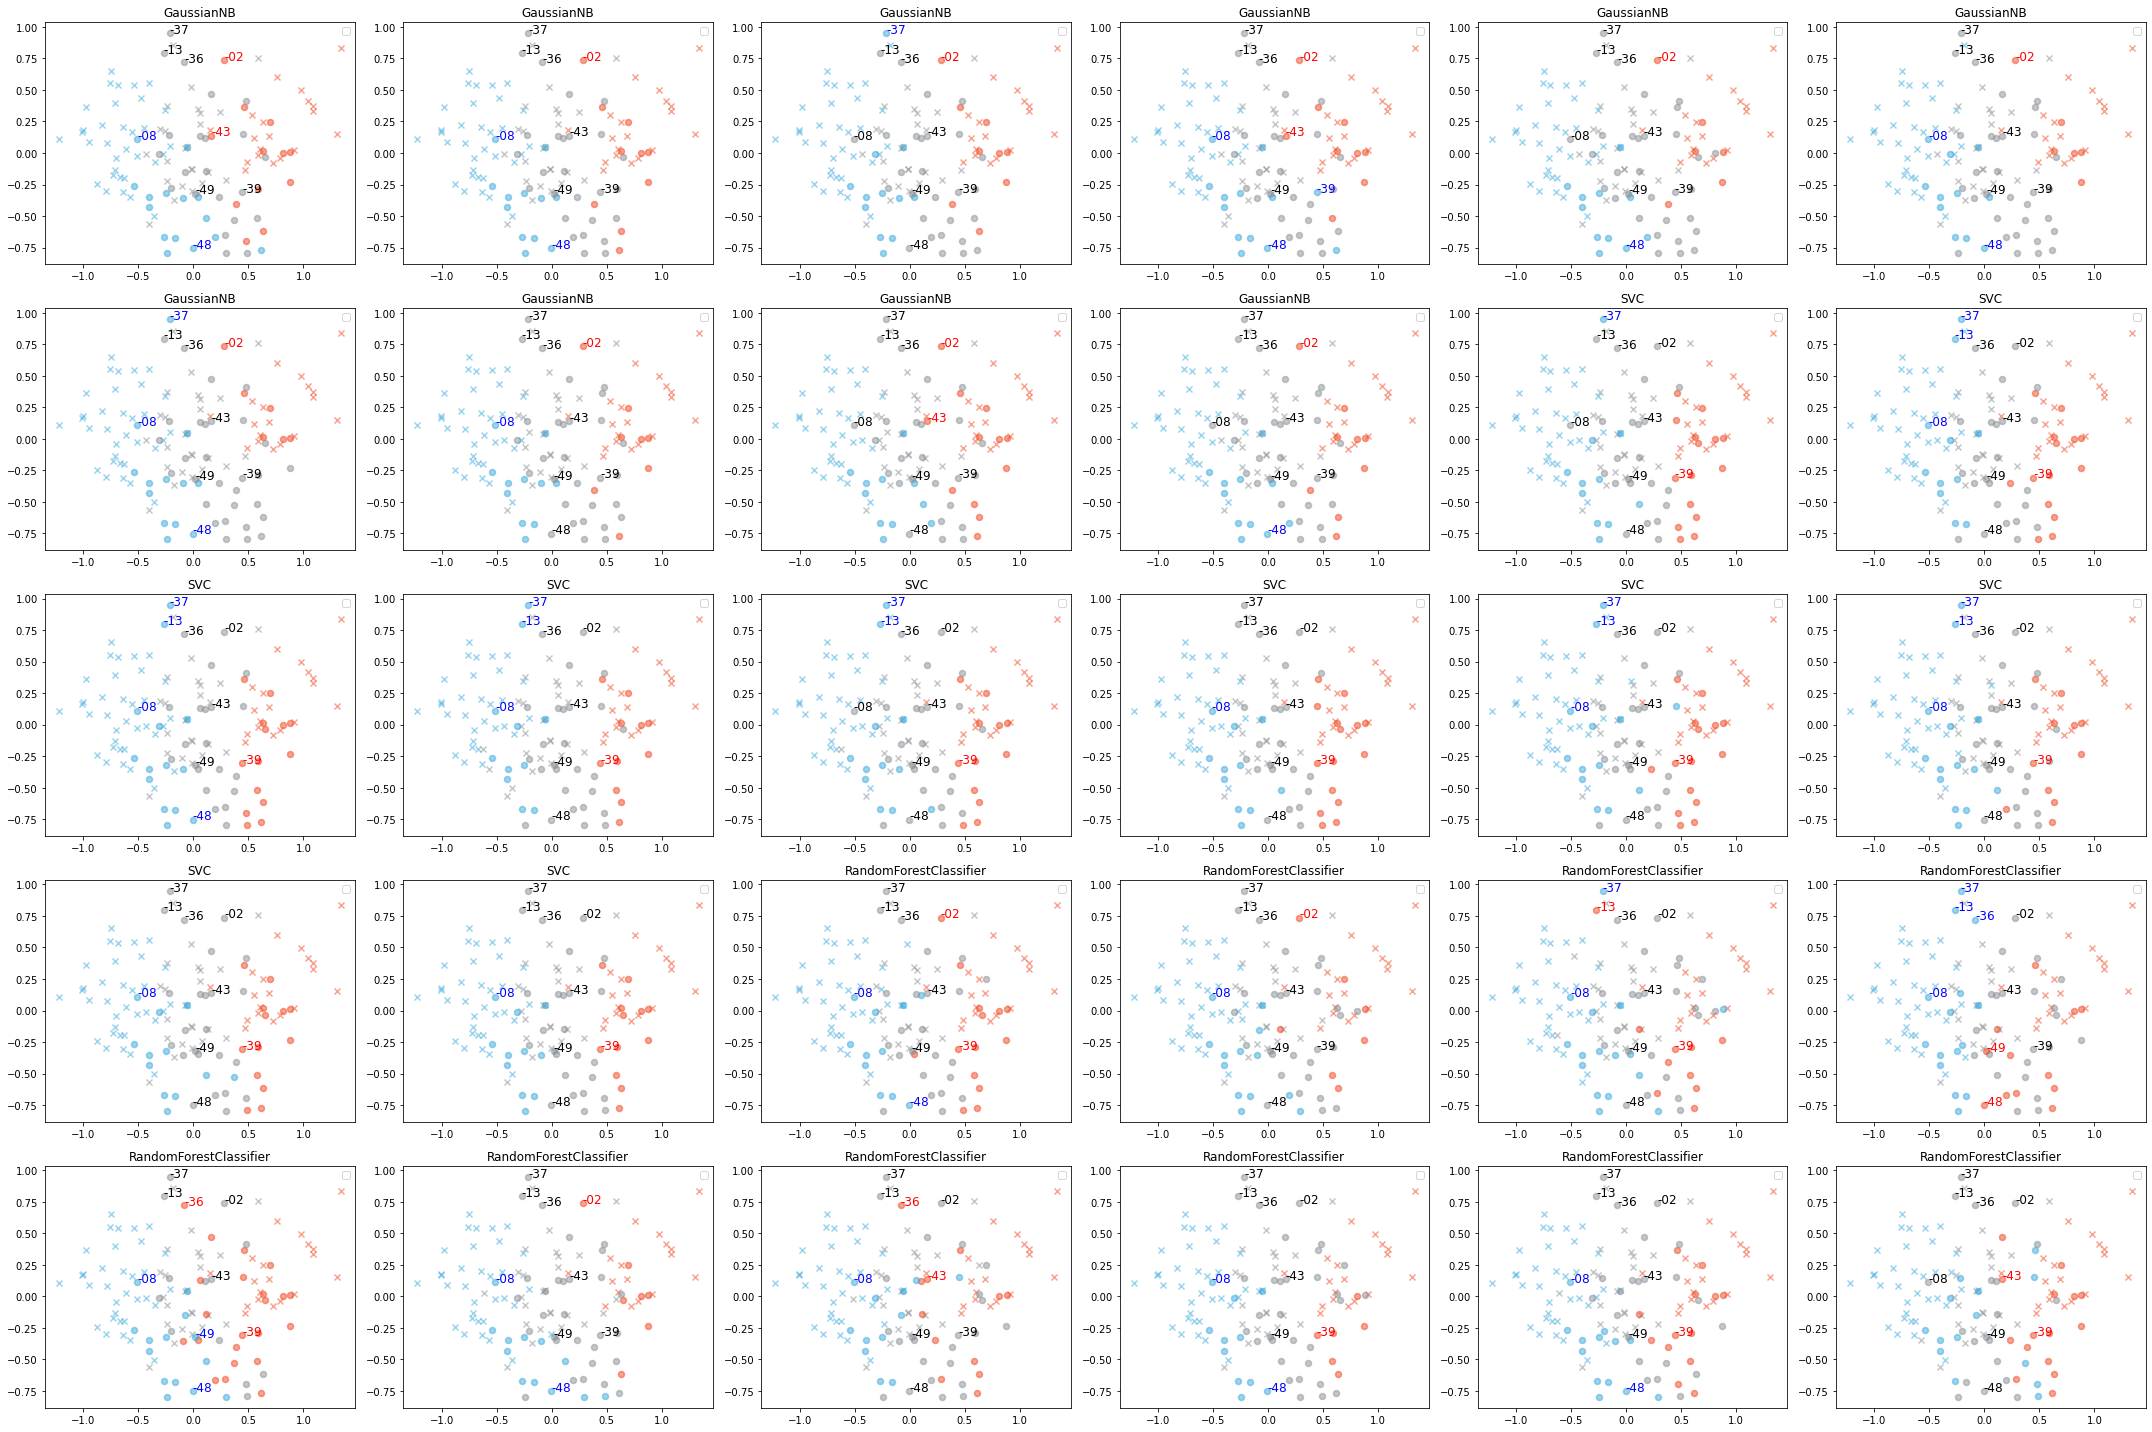

In [403]:

fig, axs = plt.subplots(5, 6, figsize=(30, 20))  # Assuming 30 figures, you can adjust the layout as needed

for index, dtc in enumerate(COL):
    dtc_name = str(dtc).split('(')[0]
    yv = dtc.predict(matv)
    ytt = dtc.predict(matt)
    colData = pd.DataFrame({'Cluster':list(ytt) + list(yv),'set':labelsall})

    # matall needs to be updated
    assert (colData.index == matall.index).all()
    colData2 = colData.copy()
    colData2.loc[colData2['set']=='Valid','Cluster'] = 'valid'
    colData2.loc[organ_uid,'Cluster'] = 'Organ'

    pca = PCA(n_components=2)
    X_r = pca.fit_transform(matall)

    ax = axs[index // 6, index % 6]
    lw = 1.5
    m_cluster = {"C1":'#F04923',"C2":'#3BA9DD',"Others":'#8A9197'}
    m_organ_c = {'C1':'red','C2':'blue','Others':'black'}
    m_set = {'Train':'x','Valid':'o'}

    for i in range(len(colData)):
        c, s = colData.iloc[i,:]
        ax.scatter(
            X_r[i, 0], X_r[i, 1], color=m_cluster[c],marker=m_set[s],
            alpha=0.5, lw=lw
        )
    labels = pd.DataFrame({'Cluster':colData2['Cluster'].values,"X1":X_r[:,0],"X2":X_r[:,1]},index=matall.index)
    for _,row in labels[labels['Cluster']=='Organ'].iterrows():
        ax.text(row['X1'],row['X2'], s=mm[row.name],alpha=1,fontsize=12,color=m_organ_c[colData.loc[row.name,'Cluster']])
    ax.legend(loc="best", shadow=False, scatterpoints=1)
    ax.set_title(dtc_name)

plt.tight_layout()
plt.show()



In [404]:
fig.savefig('tmp/model_prediction_pca_xy_dots.pdf')

In [409]:
# with open('export_big/DTC_30.dill','wb') as f:
#     dill.dump(COL,f)

In [10]:
import dill

In [ ]:
with open('export_big/DTC_30.dill','rb') as f:
    COL = dill.load(f)
    

In [411]:
sel = [13,21,23]


30

In [412]:
# from sklearn.ensemble import VotingClassifier

In [508]:
yv = dtc.predict(matv)
ytt = dtc.predict(matt)
colData = pd.DataFrame({'Cluster':list(ytt) + list(yv),'set':labelsall})

fig = plt.figure(figsize=(8,8))
# matall needs to be updated
assert (colData.index == matall.index).all()
colData2 = colData.copy()
colData2.loc[colData2['set']=='Valid','Cluster'] = 'valid'
colData2.loc[organ_uid,'Cluster'] = 'Organ'

pca = PCA(n_components=2)
X_r = pca.fit_transform(matall)

lw = 1.5
m_cluster = {"C1":'#F04923',"C2":'#3BA9DD',"Others":'#8A9197'}
m_organ_c = {'C1':'red','C2':'blue','Others':'black'}
m_set = {'Train':'x','Valid':'o'}

for i in range(len(colData)):
    c, s = colData.iloc[i,:]
    plt.scatter(
        X_r[i, 0], X_r[i, 1], color=m_cluster[c],marker=m_set[s],
        alpha=0.5, lw=lw
    )
labels = pd.DataFrame({'Cluster':colData2['Cluster'].values,"X1":X_r[:,0],"X2":X_r[:,1]},index=matall.index)
for _,row in labels[labels['Cluster']=='Organ'].iterrows():
    plt.text(row['X1'],row['X2'], s=mm[row.name],alpha=1,fontsize=12,color=m_organ_c[colData.loc[row.name,'Cluster']])
plt.legend(loc="best", shadow=False, scatterpoints=1)


AssertionError: 

<Figure size 576x576 with 0 Axes>

In [453]:
db.exporting(colData,'predict_by_ensemble_model.tsv', outputdir='report_reply')

[06/27 12:04:20] writing 1 file with 126 lines at 
	[PROJECT_ROOT]/report_reply/predict_by_ensemble_model.tsv


In [400]:
ax.text(row['X1'],row['X2'], s=mm[row.name],alpha=1,fontsize=10,color=m_organ_c[colData.loc[row.name,'Cluster']])

Text(0.01726679963567028, -0.3222512368529302, '-49')

report_reply/model_Prediction_hm_bygrp.pdf


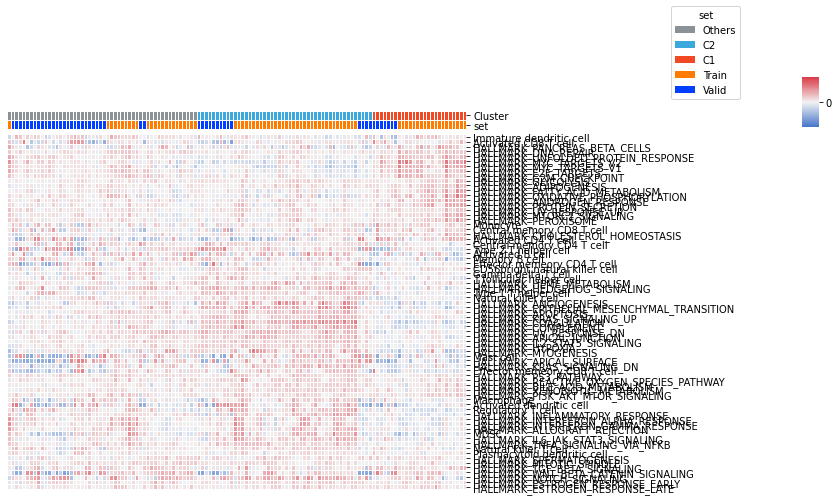

In [298]:
ax = yplot_heatmap_by_input_matrix(matall.T, colData=colData, bygroup=True, vmin=-0.8, vmax= 0.8
                                  , linewidths=0.5, z_score=None, figsize=(12,7)
                                  , export = 'model_Prediction_hm_bygrp', outputdir = 'report_reply'
                                  )


report_reply/model_Prediction_hm_free.pdf


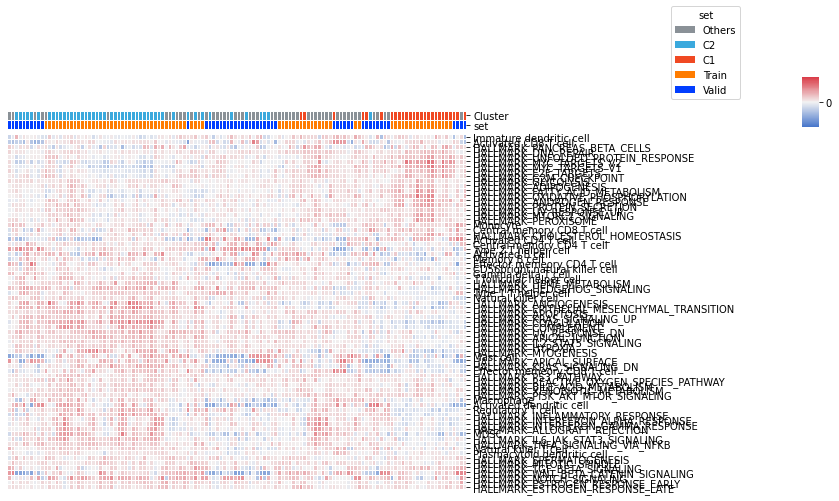

In [299]:
ax = yplot_heatmap_by_input_matrix(matall.T, colData=colData, bygroup=False, vmin=-0.8, vmax= 0.8
                                  , linewidths=0.5, z_score=None, figsize=(12,7)
                                   ,export = 'model_Prediction_hm_free' ,outputdir = 'report_reply'
                                  )

In [65]:
# # dump model
# with open('export_by2_86_pCR_nonpCR/mod_traintest+valid_model_ssgsea2.dill','wb') as f:
#     ALL = [dtc, matall,XX,YY, matt, yt, matv,yv, colData, chosen, organ_uid]
#     dill.dump(ALL,f)
    

In [15]:
import dill
# load model
with open('export_by2_86_pCR_nonpCR/mod_traintest+valid_model_ssgsea2.dill','rb') as f:
    dtc, matall, XX, YY, matt, yt, matv,yv, colData,chosen, organ_uid = dill.load(f)

[python_env]/lib/pythonX/site-packages/sklearn/base.py:347: InconsistentVersionWarning:

Trying to unpickle estimator SVC from version 1.0.2 when using version 1.3.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations



In [314]:
db.exporting(colData,'report_reply/model_ssgsea_predict.tsv')

[06/12 14:06:10] overwritting 1 file with 126 lines at 
	[PROJECT_ROOT]/report_reply/model_ssgsea_predict.tsv


In [663]:
chosen.keys()


dict_keys(['model', 'score', 'cm', 'C1', 'xtest', 'ytest'])

In [668]:
import matplotlib as mpl
print(mpl.rcParams['text.usetex'])
mpl.rcParams['font.sans-serif']
mpl.rcParams['font.sans-serif'] = 'Arial' 

False


24

24

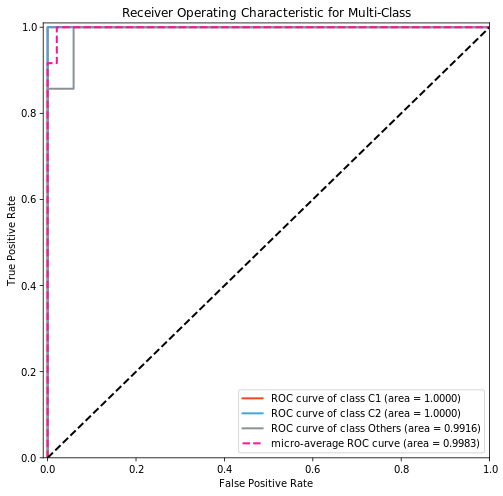

In [678]:
EXPORT = True
xtest = chosen['xtest']
ytest = chosen['ytest']
_ = plot_auc_3plus(dtc, xtest, ytest)
if EXPORT:
    _.savefig(f'report_reply/fig.S10A_model_auc_test_{len(ytest)}_of_77.pdf')

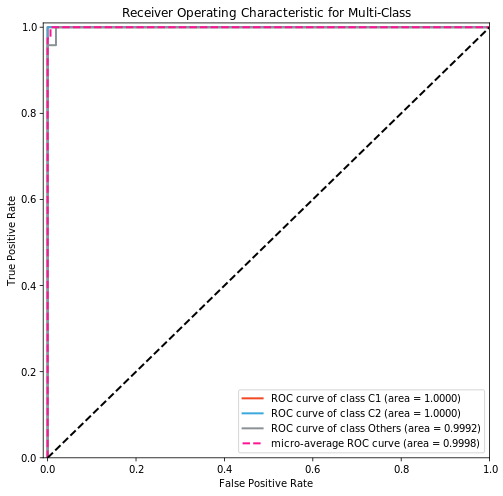

In [679]:
_ = plot_auc_3plus(dtc, matt, yt)
if EXPORT:
    _.savefig(f'report_reply/fig.S10B_model_auc_traintest_{len(yt)}.pdf')

#### fig S10 (reply) SEL 8 fea ROC

In [3]:
os.getcwd()

'[PROJECT_ROOT]'

In [262]:
best

{'O00264_PGRMC1',
 'O60443_GSDME',
 'P08183_ABCB1',
 'P08670_VIM',
 'P19838_NFKB1',
 'P49959_MRE11',
 'Q8WVQ1_CANT1',
 'Q9NY15_STAB1'}

In [265]:
XX = mat.loc[:,best]
XX.columns = XX.columns.str.split('_').str[1]
XX

,NFKB1,STAB1,CANT1,GSDME,VIM,MRE11,PGRMC1,ABCB1
P01,-0.121278,-0.573228,-0.412160,-0.242329,-0.153386,-0.057901,1.082392,-0.066783
P02,0.271610,0.758335,-0.533692,-1.125538,0.028921,0.276582,0.784019,-0.198835
P03,1.252601,-1.020592,-1.106991,0.110944,0.708840,0.480122,2.389566,-0.603772
P04,0.511189,-0.348137,-0.196969,0.806548,0.238451,0.334315,-0.492508,1.837569
P05,1.488840,0.812510,-1.041326,1.779612,0.938678,-1.038201,0.353581,1.307290
...,...,...,...,...,...,...,...,...
P82,0.672565,0.216330,-0.810120,0.448203,-0.388208,0.960438,0.019564,-0.890018
P83,0.442336,0.945386,0.932466,0.014171,-1.496575,0.025521,0.258885,-0.466496
P84,-0.453652,0.200400,-0.405490,-0.393269,0.332692,-0.267587,0.393156,0.704154
P85,-0.814537,0.508059,-0.617722,0.717684,0.981028,0.187803,-0.592361,-0.002450


In [266]:
db.exporting(XX, 'model_sel8_mat_new.dfx',outputdir='export_old',index=True)


[10/27 08:42:36] writing 1 file with 77 lines at 
	[PROJECT_ROOT]/export_old/model_sel8_mat_new.dfx


'[PROJECT_ROOT]/export_old/model_sel8_mat_new.dfx'

In [267]:
# XX = db.importing('export_old/model_sel8_mat.dfx',index_col=0)
XX = db.importing('export_old/model_sel8_mat_new.dfx',index_col=0)
YY = db.importing('export_old/model_sel8_colData.dfx',index_col=0)


[10/27 08:42:47]reading export_old/model_sel8_mat_new.dfx
[10/27 08:42:47]reading export_old/model_sel8_colData.dfx


In [268]:
XX

,NFKB1,STAB1,CANT1,GSDME,VIM,MRE11,PGRMC1,ABCB1
P01,-0.121278,-0.573228,-0.412160,-0.242329,-0.153386,-0.057901,1.082392,-0.066783
P02,0.271610,0.758335,-0.533692,-1.125538,0.028921,0.276582,0.784019,-0.198835
P03,1.252601,-1.020592,-1.106991,0.110944,0.708840,0.480122,2.389566,-0.603772
P04,0.511189,-0.348137,-0.196969,0.806548,0.238451,0.334315,-0.492508,1.837569
P05,1.488840,0.812510,-1.041326,1.779612,0.938678,-1.038201,0.353581,1.307290
...,...,...,...,...,...,...,...,...
P82,0.672565,0.216330,-0.810120,0.448203,-0.388208,0.960438,0.019564,-0.890018
P83,0.442336,0.945386,0.932466,0.014171,-1.496575,0.025521,0.258885,-0.466496
P84,-0.453652,0.200400,-0.405490,-0.393269,0.332692,-0.267587,0.393156,0.704154
P85,-0.814537,0.508059,-0.617722,0.717684,0.981028,0.187803,-0.592361,-0.002450


In [269]:
Y = YY['Group']
Y

P01    Co
P02    C2
P03    Co
P04    C2
P05    C2
       ..
P82    C2
P83    C2
P84    C2
P85    C2
P86    C2
Name: Group, Length: 77, dtype: object

In [270]:
(YY.index==XX.index).all()

True

In [271]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
from itertools import cycle
from sklearn.multiclass import OneVsRestClassifier


In [272]:
# # Create a simple multi-class classification dataset
# X, y = make_classification(n_samples=1000, n_features=20, n_informative=3, n_redundant=10,
#                            n_classes=3, random_state=42)
# X

In [273]:
Y.unique()

array(['Co', 'C2', 'C1'], dtype=object)

In [274]:
YY

,Group,Response,NEPC,Cribriform
P01,Co,non.pCR,1,0
P02,C2,non.pCR,0,0
P03,Co,non.pCR,0,0
P04,C2,non.pCR,0,0
P05,C2,non.pCR,0,0
...,...,...,...,...
P82,C2,non.pCR,0,0
P83,C2,non.pCR,0,0
P84,C2,non.pCR,0,0
P85,C2,non.pCR,0,0


In [275]:
glx = db.importing('export_86_7/wes_glx.dfx')
glx

[10/27 08:42:58]reading export_86_7/wes_glx.dfx


,Tumor_Sample_Barcode,a,t,p,uid,Custom_Label,ap,PSA,Treat_Res,NEPC,...,Response,Response2,Clin_classification,RNA_Cluster,Protein_Cluster,Cluster,endocrine_therapy,therapy_month,ARi_type,Thpy_class
0,P01,K00143,TR22030713,P010143142842401,1428424,P01,K00143P010143142842401,0.019,1,1,...,non.pCR,I,1,C4,C4,C4,戈舍瑞林+阿比特龙+泼尼松,6,2,>3
1,P02,K00144,TR22030669,P010144144820001,1448200,P02,K00144P010144144820001,0.024,1,0,...,non.pCR,I,1,C2,C2,C2,戈舍瑞林+比卡鲁胺,3,1,≤3
2,P03,K00145,TR22030670,P010145141850101,1418501,P03,K00145P010145141850101,0.006,1,0,...,non.pCR,I,1,C4,C3,C3,戈舍瑞林+比卡鲁胺,18,1,>3
3,P04,K00146,TR22030671,P010146141521801,1415218,P04,K00146P010146141521801,0.310,1,0,...,non.pCR,I,1,C4,C2,C2,戈舍瑞林+比卡鲁胺,3,1,≤3
4,P05,K00147,TR22030672,P010147140043801,1400438,P05,K00147P010147140043801,0.006,1,0,...,non.pCR,I,1,C2,C2,C2,戈舍瑞林+阿比特龙+泼尼松,3,2,≤3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
81,P82,K00265,TR22303747,P010265146210101,1462101,P82,K00265P010265146210101,4.010,2,0,...,non.pCR,II,2,C3,C2,C2,戈舍瑞林+比卡鲁胺,6,1,>3
82,P83,K00266,TR22303743,P010266147461501,1474615,P83,K00266P010266147461501,0.208,2,0,...,non.pCR,II,2,C1,C2,C2,戈舍瑞林+比卡鲁胺,3,1,≤3
83,P84,K00267,TR22303734,P010267145448901,1454489,P84,K00267P010267145448901,0.246,1,0,...,non.pCR,I,1,C2,C2,C2,戈舍瑞林+比卡鲁胺,3,1,≤3
84,P85,K00268,TR22303735,P010268147734101,1477341,P85,K00268P010268147734101,0.711,2,0,...,non.pCR,II,2,C2,C2,C2,地加瑞克,3,1,≤3


In [ ]:
ax.lengend(title=,color=,break=)

In [280]:
# Binarize the output
X = XX
y = label_binarize(Y, classes=['Co','C1','C2'])
n_classes = y.shape[1]
# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y)


In [144]:
# Train a logistic regression model on the training set
# classifier = LogisticRegression(solver='lbfgs', multi_class='ovr')
# y_score = classifier.fit(X_train, y_train).decision_function(X_test)




In [ ]:
DecisionTreeClassifier()

In [ ]:
RandomForestClassifier()

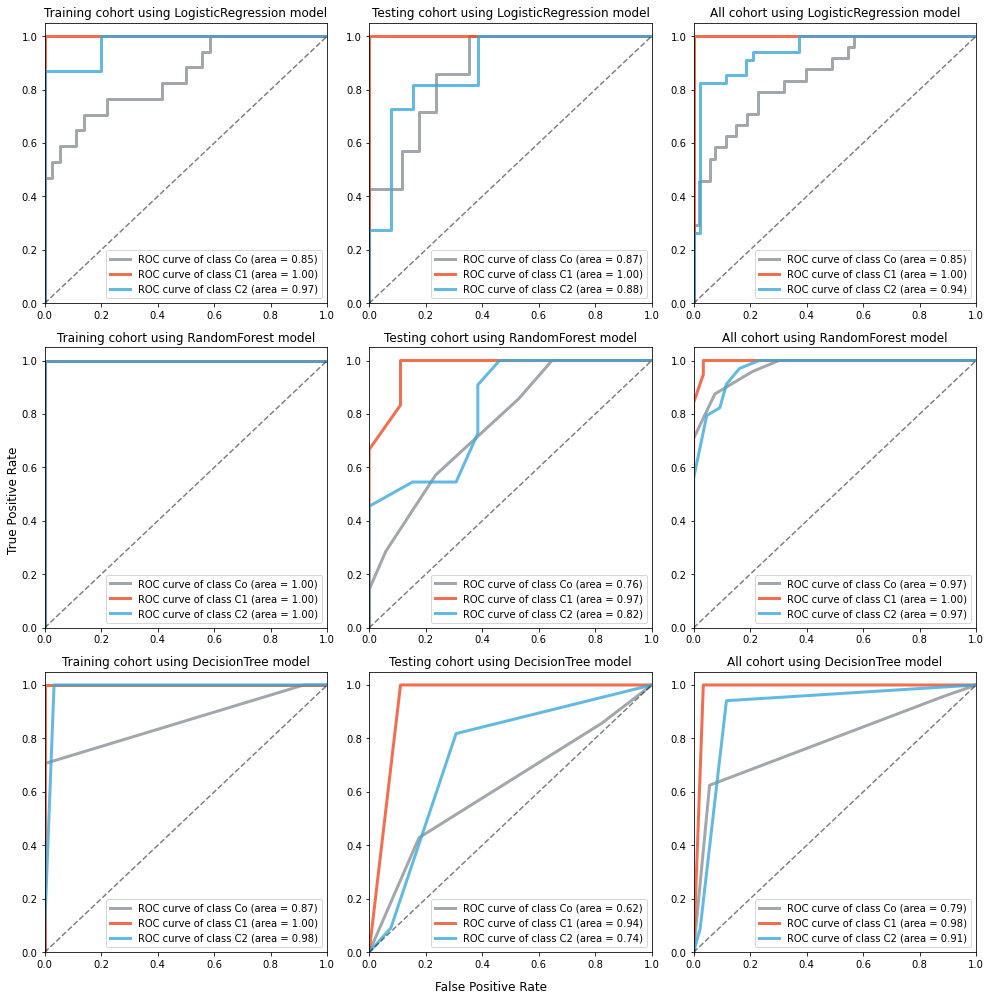

In [340]:
params = {'LogisticRegression':{"solver":'lbfgs'}
          ,'RandomForest':{"n_estimators":8}
          ,'DecisionTree':{"max_depth":3}
         }
methods = {'LogisticRegression':'decision_function'
          ,'RandomForest':'predict_proba'
          ,'DecisionTree':'predict_proba'
         }
ground_trues = {'Training':y_train,'Testing':y_test,'All':y}
Models = {}

fig, axes = plt.subplots(3,3, figsize=(14,14))
axes = axes.flatten()
fig_i = 0

for key, Model in {'LogisticRegression':LogisticRegression
                   , 'RandomForest':RandomForestClassifier
                   , 'DecisionTree':DecisionTreeClassifier}.items():
    
    classifier = OneVsRestClassifier(Model(**params[key])).fit(X_train, y_train)
    Models[key] = classifier
    
    # generate predictions index
    r = {}
    r['Training'] = getattr(classifier,methods[key])(X_train)
    r['Testing'] = getattr(classifier,methods[key])(X_test)
    r['All'] = getattr(classifier,methods[key])(X)

    for group, scores in r.items():
        # generate ROC curves
        fpr = dict()
        tpr = dict()
        roc_auc = dict()
        for c in range(n_classes):
            fpr[c], tpr[c], _ = roc_curve(ground_trues[group][:, c], scores[:, c])
            roc_auc[c] = auc(fpr[c], tpr[c])
        
        # Plot all ROC curves
#         fig = plt.figure(figsize=(8,8))

        colors = cycle(['#8A9197', '#F04923', '#3BA9DD'])
        ax = axes[fig_i]
        for i, color in zip(range(n_classes), colors):
            ax.plot(fpr[i], tpr[i], color=color,alpha=0.8,linewidth=3,
                     label='ROC curve of class {0} (area = {1:0.2f})'
                     ''.format(['Co','C1','C2'][i], roc_auc[i]))

        ax.plot([0, 1], [0, 1], 'k--',alpha=0.5)
        ax.set_xlim([0.0, 1.0])
        ax.set_ylim([0.0, 1.05])
        ax.set_title(f'{group} cohort using {key} model')
        ax.legend(loc="lower right")
#         ax.set_xlabel('False Positive Rate')
#         ax.set_ylabel('True Positive Rate')
        fig_i += 1
        
#         fig.savefig('')
fig.supxlabel('False Positive Rate')
fig.supylabel('True Positive Rate')

plt.tight_layout()

plt.show()

In [341]:
fig.savefig('report_reply/fig.S10.ROC_curve_new.pdf')

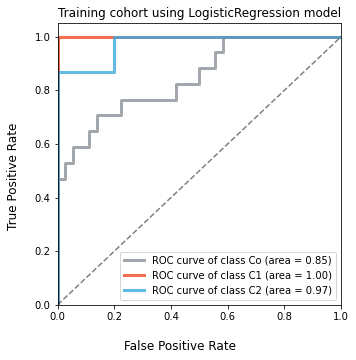

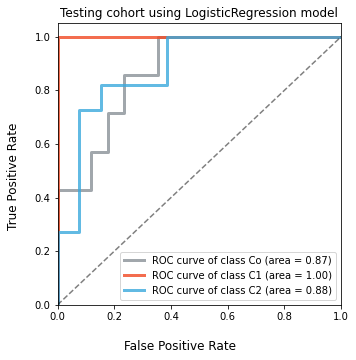

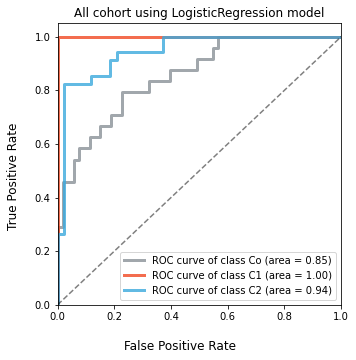

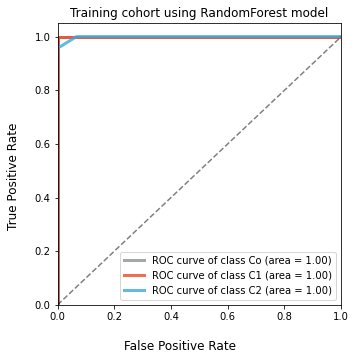

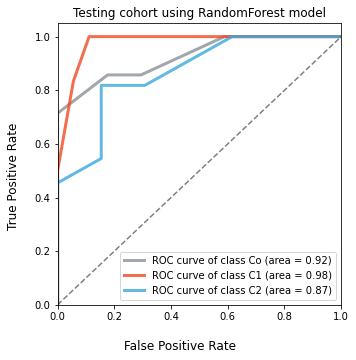

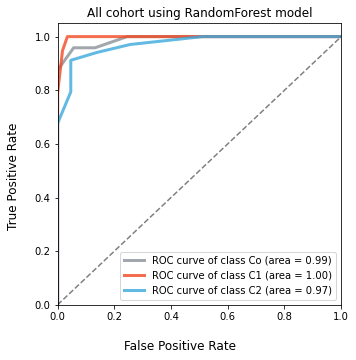

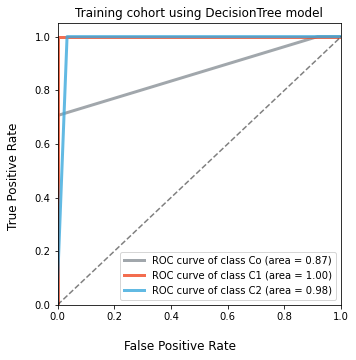

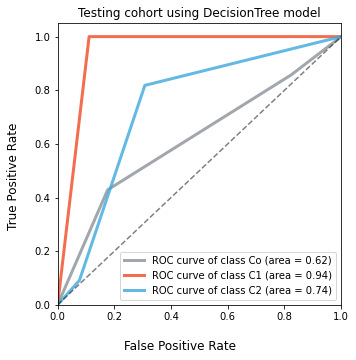

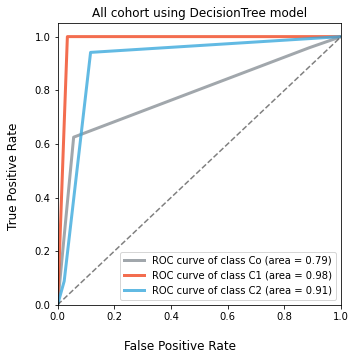

In [410]:
# 分开画
params = {'LogisticRegression':{"solver":'lbfgs'}
          ,'RandomForest':{"n_estimators":8}
          ,'DecisionTree':{"max_depth":3}
         }
methods = {'LogisticRegression':'decision_function'
          ,'RandomForest':'predict_proba'
          ,'DecisionTree':'predict_proba'
         }
ground_trues = {'Training':y_train,'Testing':y_test,'All':y}
Models = {}


for key, Model in {'LogisticRegression':LogisticRegression
                   , 'RandomForest':RandomForestClassifier
                   , 'DecisionTree':DecisionTreeClassifier}.items():
    
    classifier = OneVsRestClassifier(Model(**params[key])).fit(X_train, y_train)
    Models[key] = classifier
    
    # generate predictions index
    r = {}
    r['Training'] = getattr(classifier,methods[key])(X_train)
    r['Testing'] = getattr(classifier,methods[key])(X_test)
    r['All'] = getattr(classifier,methods[key])(X)
    
    for group, scores in r.items():
        # generate ROC curves
        fpr = dict()
        tpr = dict()
        roc_auc = dict()
        for c in range(n_classes):
            fpr[c], tpr[c], _ = roc_curve(ground_trues[group][:, c], scores[:, c])
            roc_auc[c] = auc(fpr[c], tpr[c])
        
        # Plot all ROC curves
        fig,ax = plt.subplots(figsize=(5,5))

        colors = cycle(['#8A9197', '#F04923', '#3BA9DD'])
        
        for i, color in zip(range(n_classes), colors):
            ax.plot(fpr[i], tpr[i], color=color,alpha=0.8,linewidth=3,
                     label='ROC curve of class {0} (area = {1:0.2f})'
                     ''.format(['Co','C1','C2'][i], roc_auc[i]))

        ax.plot([0, 1], [0, 1], 'k--',alpha=0.5)
        ax.set_xlim([0.0, 1.0])
        ax.set_ylim([0.0, 1.05])
        ax.set_title(f'{group} cohort using {key} model')
        ax.legend(loc="lower right")
#         ax.set_xlabel('False Positive Rate')
#         ax.set_ylabel('True Positive Rate')
        
        fig.supxlabel('False Positive Rate')
        fig.supylabel('True Positive Rate')

        plt.tight_layout()

        fig.savefig(f'report_reply/fig.S10.ROC_{key}_{group}.pdf')
        


In [405]:
group

'All'

In [120]:
# res = []
# names = ['Co','C1','C2']
# for i in range(3):
#     f,t = fpr[i],tpr[i]
#     for j in range(len(f)):
#         res
#         f[j],p[j]
        
#     break

## ssGSEA model

### load Train test Valid X,y

Train test 77

In [201]:
gt = db.importing('export_by2_86_pCR_nonpCR/wes_glx.dfx')
gt = gt[gt['Cluster']!='pCR']
gt['uid'] = gt['uid'].astype(str)
gt

[08/03 01:20:06]reading export_by2_86_pCR_nonpCR/wes_glx.dfx


,Tumor_Sample_Barcode,a,t,p,uid,Custom_Label,ap,PSA,Treat_Res,NEPC,Cribriform,Group,Response,Response2,Clin_classification,RNA_Cluster,Protein_Cluster,Cluster,endocrine_therapy,therapy_month,ARi_type,Thpy_class,PSA_class,tsb,new_tsb
0,P001,K00143,TR22030713,P010143142842401,1428424,P01,K00143P010143142842401,0.019,1,1,0,C4,non.pCR,I,1,C3,C4,C4,戈舍瑞林+阿比特龙+泼尼松,6,2,>3,≤0.2,P01,P001
1,P002,K00144,TR22030669,P010144144820001,1448200,P02,K00144P010144144820001,0.024,1,0,0,C2,non.pCR,I,1,C2,C2,C2,戈舍瑞林+比卡鲁胺,3,1,≤3,≤0.2,P02,P002
2,P003,K00145,TR22030670,P010145141850101,1418501,P03,K00145P010145141850101,0.006,1,0,0,C3,non.pCR,I,1,C3,C3,C3,戈舍瑞林+比卡鲁胺,18,1,>3,≤0.2,P03,P003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,P084,K00267,TR22303734,P010267145448901,1454489,P84,K00267P010267145448901,0.246,1,0,0,C2,non.pCR,I,1,C2,C2,C2,戈舍瑞林+比卡鲁胺,3,1,≤3,>0.2,P84,P084
84,P085,K00268,TR22303735,P010268147734101,1477341,P85,K00268P010268147734101,0.711,2,0,0,C2,non.pCR,II,2,C2,C2,C2,地加瑞克,3,1,≤3,>0.2,P85,P085
85,P086,K00269,TR22303748,P010269148140701,1481407,P86,K00269P010269148140701,0.051,1,0,0,C2,non.pCR,I,1,C4,C2,C2,戈舍瑞林+比卡鲁胺,4,1,>3,≤0.2,P86,P086


In [202]:
hm = db.importing('export_by2_86_pCR_nonpCR/prt_ssGSEA_hm.dfx')
im = db.importing('export_by2_86_pCR_nonpCR/prt_ssGSEA_immune.dfx')
matt_ss = pd.concat([hm,im]).T
matt_ss = matt_ss.loc[gt['Custom_Label'],:]
matt_ss

[08/03 01:20:07]reading export_by2_86_pCR_nonpCR/prt_ssGSEA_hm.dfx
[08/03 01:20:07]reading export_by2_86_pCR_nonpCR/prt_ssGSEA_immune.dfx


,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_HYPOXIA,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_MITOTIC_SPINDLE,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_DNA_REPAIR,HALLMARK_G2M_CHECKPOINT,HALLMARK_APOPTOSIS,HALLMARK_NOTCH_SIGNALING,HALLMARK_ADIPOGENESIS,HALLMARK_ESTROGEN_RESPONSE_EARLY,HALLMARK_ESTROGEN_RESPONSE_LATE,HALLMARK_ANDROGEN_RESPONSE,HALLMARK_MYOGENESIS,HALLMARK_PROTEIN_SECRETION,HALLMARK_INTERFERON_ALPHA_RESPONSE,HALLMARK_INTERFERON_GAMMA_RESPONSE,HALLMARK_APICAL_JUNCTION,HALLMARK_APICAL_SURFACE,HALLMARK_HEDGEHOG_SIGNALING,HALLMARK_COMPLEMENT,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,HALLMARK_PI3K_AKT_MTOR_SIGNALING,HALLMARK_MTORC1_SIGNALING,HALLMARK_E2F_TARGETS,HALLMARK_MYC_TARGETS_V1,HALLMARK_MYC_TARGETS_V2,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,...,HALLMARK_KRAS_SIGNALING_DN,HALLMARK_PANCREAS_BETA_CELLS,Activated B cell,Activated CD4 T cell,Activated CD8 T cell,Activated dendritic cell,CD56bright natural killer cell,CD56dim natural killer cell,Central memory CD4 T cell,Central memory CD8 T cell,Effector memeory CD4 T cell,Effector memeory CD8 T cell,Eosinophil,Gamma delta T cell,Immature B cell,Immature dendritic cell,Macrophage,Mast cell,MDSC,Memory B cell,Monocyte,Natural killer cell,Natural killer T cell,Neutrophil,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 17 T helper cell,Type 2 T helper cell
P01,0.022661,0.091207,0.081716,-0.009366,0.184736,-0.081509,0.081935,0.133009,0.144519,0.214680,0.212621,0.126638,0.167404,0.177005,0.020085,-0.029611,-0.043373,0.191769,0.142450,0.157679,0.245465,0.049182,0.161117,0.017984,5.320738e-02,0.015171,0.156089,0.077294,0.130516,0.103643,...,0.187347,0.096383,0.249311,-0.377603,0.122279,-0.089037,0.039078,0.072490,0.127286,0.097829,0.049951,0.083183,-0.013571,0.015861,-0.070844,0.183164,0.050453,0.186585,0.023903,0.128525,-0.156038,0.099613,0.129707,0.299286,0.053262,0.007581,0.126016,0.089989,0.054172,0.162087
P02,0.150915,0.082616,-0.126694,0.006097,0.022580,0.024921,0.245637,0.006072,0.076754,0.191690,0.237387,0.041123,0.099629,0.224127,0.040942,0.032433,0.038698,0.348971,0.338557,0.126977,0.124125,0.225576,0.214286,0.100976,1.789619e-01,0.044041,0.005382,0.070768,-0.027176,0.123791,...,0.276492,0.112625,0.231143,0.013494,-0.016430,0.037400,0.111200,0.036920,0.075067,0.038504,-0.022286,-0.056606,-0.059547,0.056776,0.271949,0.076632,0.143560,0.244927,0.185639,0.048815,0.013154,0.044508,0.065593,0.446971,0.099435,0.180644,0.117305,0.175953,0.066496,0.085536
P03,0.003253,0.002239,-0.108530,0.219912,0.174208,0.124641,-0.044700,0.149498,0.135504,0.054615,0.200003,-0.001274,-0.047890,0.006720,-0.154018,-0.041592,-0.044006,0.110515,0.031491,0.055773,0.159586,0.043613,-0.003349,-0.046197,9.684594e-07,-0.097880,0.178072,0.054268,-0.179648,-0.012600,...,-0.000880,-0.062057,-0.180907,-0.208864,0.043244,-0.081049,-0.082139,0.084735,0.058855,-0.065547,-0.068684,0.125716,0.205233,-0.038420,0.005265,0.090349,0.027856,-0.096467,-0.154909,-0.017156,0.068394,0.039908,0.073207,-0.371589,-0.036356,-0.036607,0.001837,0.100879,-0.286916,0.139593
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P84,0.143644,0.194698,0.052249,0.134940,0.207453,0.143900,0.220094,0.018218,0.050047,0.266981,0.404690,0.049503,0.192174,0.217610,0.012867,0.177464,-0.012163,0.260341,0.183167,0.235866,0.213403,0.221966,0.123129,0.023570,1.070533e-01,-0.037251,-0.056254,-0.093805,0.112964,0.445934,...,0.352633,-0.087013,0.147737,0.096721,-0.078010,-0.046784,-0.089270,-0.080597,0.075640,0.157736,0.097455,0.003722,0.204710,0.010745,-0.070266,0.048082,0.172337,-0.123872,0.024920,0.166121,0.037890,0.132872,0.126653,0.262803,0.063256,0.197220,0.125649,0.167422,0.315014,0.156547
P85,0.118472,0.095104,-0.027578,0.134934,0.1

In [203]:
gt['Predict'] = [i if i=='C1' or i=='C2' else 'Others' for i in gt['Cluster']]
yt = gt.set_index('Custom_Label')['Predict']
assert (yt.index == matt_ss.index).all()
yt


Custom_Label
P01    Others
P02        C2
P03    Others
        ...  
P84        C2
P85        C2
P86        C2
Name: Predict, Length: 77, dtype: object

valid 49

In [204]:
gv = db.importing('external_info/Proteomics52/washed/prt_glx.dfx')
gv = gv[gv['Group']!='pCR']
gv['uid'] = gv['uid'].astype(str)

organ_info = db.importing('external_info/Organoids/湘雅医院前列腺癌类器官队列信息v3.0.xlsx')
organ_info = organ_info[~organ_info['根治术病理号'].isna()][['根治术病理号','类器官序列号']].rename(columns={'根治术病理号':'uid','类器官序列号':'ooid'})
organ_info['uid'] = organ_info['uid'].astype(int).astype(str)
organ_info['oid'] = organ_info['ooid'].str.lstrip('ORG')
sel_organ_uid = ["1528731","1535920","1538224","1554631","1555314","1557024","1563492","1567143","1567947"]
gv = pd.merge(gv, organ_info,on='uid',how='left',suffixes=['','__xx'])
gv['sel'] = ""
mask = gv['uid'].isin(sel_organ_uid)
gv.loc[mask,'sel'] = gv.loc[mask,'oid']
gv.sample(8)

[08/03 01:20:08]reading external_info/Proteomics52/washed/prt_glx.dfx
[08/03 01:20:08]reading external_info/Organoids/湘雅医院前列腺癌类器官队列信息v3.0.xlsx
  Sheets list: ['总表', 'Sheet1', '影像学资料获取', '类器官药筛已完成', '单细胞测序送样筛选', 'WES送样']
  Read the 1 / 6 sheet named <总表>


,Custom_Label,uid,source,Group,ooid,oid,sel
3,P090,1555314,valid52,non.pCR,ORG-37,-37,-37
0,P087,1554631,valid52,non.pCR,ORG-36,-36,-36
34,P123,1526829,valid52,non.pCR,NaN,NaN,
...,...,...,...,...,...,...,...
2,P089,1557024,valid52,non.pCR,ORG-39,-39,-39
31,P119,1519610,valid52,non.pCR,NaN,NaN,
23,P110,1513118,valid52,non.pCR,NaN,NaN,


In [205]:
echo(gv)

,Custom_Label,uid,source,Group,ooid,oid,sel
0,P087,1554631,valid52,non.pCR,ORG-36,-36,-36
1,P088,1538224,valid52,non.pCR,ORG-13,-13,-13
2,P089,1557024,valid52,non.pCR,ORG-39,-39,-39
3,P090,1555314,valid52,non.pCR,ORG-37,-37,-37
4,P091,1535920,valid52,non.pCR,ORG-08,-08,-08
5,P092,1528731,valid52,non.pCR,ORG-02,-02,-02
6,P093,1491165,valid52,non.pCR,NaN,NaN,
7,P094,1494425,valid52,non.pCR,NaN,NaN,
8,P095,1494688,valid52,non.pCR,NaN,NaN,
9,P096,1498899,valid52,non.pCR,NaN,NaN,


In [206]:
hm = db.importing('external_info/Proteomics52/washed/prt_ssgsea_hm.dfx')
im = db.importing('external_info/Proteomics52/washed/prt_ssgsea_immune.dfx')
matv_ss = pd.concat([hm,im]).T
matv_ss = matv_ss.loc[gv['Custom_Label'], matt_ss.columns]
matv_ss

[08/03 01:20:08]reading external_info/Proteomics52/washed/prt_ssgsea_hm.dfx
[08/03 01:20:08]reading external_info/Proteomics52/washed/prt_ssgsea_immune.dfx


,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_HYPOXIA,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_MITOTIC_SPINDLE,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_DNA_REPAIR,HALLMARK_G2M_CHECKPOINT,HALLMARK_APOPTOSIS,HALLMARK_NOTCH_SIGNALING,HALLMARK_ADIPOGENESIS,HALLMARK_ESTROGEN_RESPONSE_EARLY,HALLMARK_ESTROGEN_RESPONSE_LATE,HALLMARK_ANDROGEN_RESPONSE,HALLMARK_MYOGENESIS,HALLMARK_PROTEIN_SECRETION,HALLMARK_INTERFERON_ALPHA_RESPONSE,HALLMARK_INTERFERON_GAMMA_RESPONSE,HALLMARK_APICAL_JUNCTION,HALLMARK_APICAL_SURFACE,HALLMARK_HEDGEHOG_SIGNALING,HALLMARK_COMPLEMENT,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,HALLMARK_PI3K_AKT_MTOR_SIGNALING,HALLMARK_MTORC1_SIGNALING,HALLMARK_E2F_TARGETS,HALLMARK_MYC_TARGETS_V1,HALLMARK_MYC_TARGETS_V2,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,...,HALLMARK_KRAS_SIGNALING_DN,HALLMARK_PANCREAS_BETA_CELLS,Activated B cell,Activated CD4 T cell,Activated CD8 T cell,Activated dendritic cell,CD56bright natural killer cell,CD56dim natural killer cell,Central memory CD4 T cell,Central memory CD8 T cell,Effector memeory CD4 T cell,Effector memeory CD8 T cell,Eosinophil,Gamma delta T cell,Immature B cell,Immature dendritic cell,Macrophage,Mast cell,MDSC,Memory B cell,Monocyte,Natural killer cell,Natural killer T cell,Neutrophil,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 17 T helper cell,Type 2 T helper cell
P087,0.083784,0.188625,0.022102,0.113886,0.080922,0.000542,-0.175954,0.102503,0.155067,0.057457,0.390093,0.200166,0.080634,0.144057,0.189503,0.183853,0.068014,-0.078881,-0.011471,0.114951,0.286645,-0.149107,0.045638,0.047063,0.192679,0.239584,0.200338,0.268230,0.073166,0.039165,...,-0.009114,0.220109,-0.062340,-0.003674,0.119494,0.055801,0.006138,0.186397,0.040733,0.159148,0.138766,-0.139139,0.030291,0.078635,-0.123243,0.027886,-0.033380,0.163410,0.129413,-0.139216,0.059376,-0.034857,0.008340,-0.161169,-0.016553,0.047492,0.049534,-0.005577,-0.132776,0.149705
P088,0.096606,0.213862,0.014053,0.111597,-0.120166,-0.022455,-0.133988,0.128744,0.194630,0.107258,0.263084,0.202819,0.015396,0.100615,0.098170,0.145291,0.009539,-0.003010,0.025621,0.094959,0.185553,-0.177390,0.113285,0.014223,0.133626,0.225697,0.237756,0.246126,-0.003069,0.073730,...,-0.090434,0.180637,-0.004948,-0.094053,0.198532,0.130110,0.040984,0.140374,0.061872,0.123463,0.181807,-0.134652,-0.137148,0.076859,-0.130819,-0.005119,-0.063641,0.162335,0.177761,-0.099481,0.041836,-0.024579,0.144109,-0.156466,-0.048902,0.189812,0.089229,0.014769,-0.063107,0.137557
P089,0.199650,0.157939,-0.016383,0.112650,-0.138301,-0.068916,-0.147801,0.085952,0.115444,0.168424,0.233653,0.223229,0.039502,0.097267,0.204377,0.044770,0.090759,0.051633,0.089002,0.015893,0.183345,-0.241014,0.038440,0.105192,0.070622,0.229569,0.210004,0.256945,-0.011215,0.053431,...,0.012131,0.316359,0.199185,-0.054678,0.231978,0.155773,-0.016697,0.150585,0.056826,0.142700,0.129378,-0.204281,-0.190130,0.128081,-0.170014,0.073485,0.020732,0.193428,0.125262,-0.144704,0.038011,-0.097753,-0.006593,0.258031,-0.091700,0.116807,-0.050183,0.050030,-0.137108,0.088128
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P135,0.030373,0.003811,0.218454,0.092368,0.385791,0.107434,0.116603,0.070038,-0.033958,0.004687,0.125131,0.144256,0.103530,0.075723,0.088132,0.048281,0.094956,0.023406,0.012320,0.037624,0.130999,0.023823,0.053727,0.062401,0.053236,0.019384,-0.016643,-0.104339,0.148073,0.049633,...,0.131714,-0.002350,0.077969,0.001972,0.008325,-0.043247,-0.013760,-0.081141,0.024604,0.052394,-0.037187,0.273134,0.128653,-0.078405,0.155198,0.002940,-0.058378,-0.218688,0.018498,0.305036,0.039364,0.032740,-0.005672,-0.037506,-0.015738,0.026340,0.205053,0.037378,0.127103,-0.047575
P137,0.098346,0.123634,0.123491,0.166162,0.

In [207]:
gv['Set'] = 'Others'
yv = gv.set_index('Custom_Label')['Set']
yv

Custom_Label
P087    Others
P088    Others
P089    Others
         ...  
P135    Others
P137    Others
P138    Others
Name: Set, Length: 49, dtype: object

In [208]:
assert (matt_ss.columns == matv_ss.columns).all()

In [63]:
# sel_organ_uid = ["1528731","1535920","1538224","1554631","1555314","1557024","1563492","1567143","1567947"]
mm = gv[(gv['sel']!='') & ~gv['oid'].isna()].set_index('Custom_Label')['oid'].to_dict()
mm


{'P087': '-36',
 'P088': '-13',
 'P089': '-39',
 'P090': '-37',
 'P091': '-08',
 'P092': '-02',
 'P135': '-43',
 'P137': '-48',
 'P138': '-49'}

In [210]:
colData

,Custom_Label,Cluster,set,Cluster__xx,set__xx,sel_organ,uid,source,Group,ooid,oid,sel
0,P01,Others,Train,Others,Train,,1428424,Train,non.pCR,NaN,NaN,NaN
1,P02,C2,Train,C2,Train,,1448200,Train,non.pCR,NaN,NaN,NaN
2,P03,Others,Train,Others,Train,,1418501,Train,non.pCR,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
123,P135,C2,Valid,Others,Valid,,1563492,valid52,non.pCR,ORG-43,-43.0,-43.0
124,P137,C2,Valid,Others,Valid,,1567143,valid52,non.pCR,ORG-48,-48.0,-48.0
125,P138,C2,Valid,C2,Valid,,1567947,valid52,non.pCR,ORG-49,-49.0,-49.0


### check PCA distribution

In [68]:
from sklearn.datasets import make_classification
from sklearn.cluster import k_means
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
from itertools import cycle
from sklearn.multiclass import OneVsRestClassifier

from sklearn.decomposition import PCA


from sklearn.metrics import confusion_matrix, classification_report

from sklearn.tree import DecisionTreeClassifier

from sklearn import metrics
from sklearn.metrics import confusion_matrix, classification_report


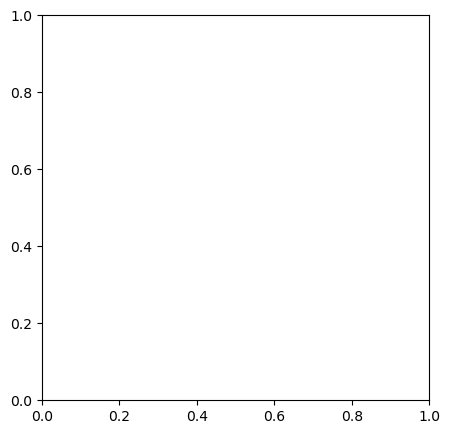

In [429]:
axes, fig = plt.subplots(1,1,figsize=(5,5))

In [430]:
type(fig) == plt.Figure

False

In [135]:
matall = pd.concat([matt_ss,matv_ss])
matall

,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_HYPOXIA,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_MITOTIC_SPINDLE,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_DNA_REPAIR,HALLMARK_G2M_CHECKPOINT,HALLMARK_APOPTOSIS,HALLMARK_NOTCH_SIGNALING,HALLMARK_ADIPOGENESIS,HALLMARK_ESTROGEN_RESPONSE_EARLY,HALLMARK_ESTROGEN_RESPONSE_LATE,HALLMARK_ANDROGEN_RESPONSE,HALLMARK_MYOGENESIS,HALLMARK_PROTEIN_SECRETION,HALLMARK_INTERFERON_ALPHA_RESPONSE,HALLMARK_INTERFERON_GAMMA_RESPONSE,HALLMARK_APICAL_JUNCTION,HALLMARK_APICAL_SURFACE,HALLMARK_HEDGEHOG_SIGNALING,HALLMARK_COMPLEMENT,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,HALLMARK_PI3K_AKT_MTOR_SIGNALING,HALLMARK_MTORC1_SIGNALING,HALLMARK_E2F_TARGETS,HALLMARK_MYC_TARGETS_V1,HALLMARK_MYC_TARGETS_V2,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,...,HALLMARK_KRAS_SIGNALING_DN,HALLMARK_PANCREAS_BETA_CELLS,Activated B cell,Activated CD4 T cell,Activated CD8 T cell,Activated dendritic cell,CD56bright natural killer cell,CD56dim natural killer cell,Central memory CD4 T cell,Central memory CD8 T cell,Effector memeory CD4 T cell,Effector memeory CD8 T cell,Eosinophil,Gamma delta T cell,Immature B cell,Immature dendritic cell,Macrophage,Mast cell,MDSC,Memory B cell,Monocyte,Natural killer cell,Natural killer T cell,Neutrophil,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 17 T helper cell,Type 2 T helper cell
P01,0.022661,0.091207,0.081716,-0.009366,0.184736,-0.081509,0.081935,0.133009,0.144519,0.214680,0.212621,0.126638,0.167404,0.177005,0.020085,-0.029611,-0.043373,0.191769,0.142450,0.157679,0.245465,0.049182,0.161117,0.017984,5.320738e-02,0.015171,0.156089,0.077294,0.130516,0.103643,...,0.187347,0.096383,0.249311,-0.377603,0.122279,-0.089037,0.039078,0.072490,0.127286,0.097829,0.049951,0.083183,-0.013571,0.015861,-0.070844,0.183164,0.050453,0.186585,0.023903,0.128525,-0.156038,0.099613,0.129707,0.299286,0.053262,0.007581,0.126016,0.089989,0.054172,0.162087
P02,0.150915,0.082616,-0.126694,0.006097,0.022580,0.024921,0.245637,0.006072,0.076754,0.191690,0.237387,0.041123,0.099629,0.224127,0.040942,0.032433,0.038698,0.348971,0.338557,0.126977,0.124125,0.225576,0.214286,0.100976,1.789619e-01,0.044041,0.005382,0.070768,-0.027176,0.123791,...,0.276492,0.112625,0.231143,0.013494,-0.016430,0.037400,0.111200,0.036920,0.075067,0.038504,-0.022286,-0.056606,-0.059547,0.056776,0.271949,0.076632,0.143560,0.244927,0.185639,0.048815,0.013154,0.044508,0.065593,0.446971,0.099435,0.180644,0.117305,0.175953,0.066496,0.085536
P03,0.003253,0.002239,-0.108530,0.219912,0.174208,0.124641,-0.044700,0.149498,0.135504,0.054615,0.200003,-0.001274,-0.047890,0.006720,-0.154018,-0.041592,-0.044006,0.110515,0.031491,0.055773,0.159586,0.043613,-0.003349,-0.046197,9.684594e-07,-0.097880,0.178072,0.054268,-0.179648,-0.012600,...,-0.000880,-0.062057,-0.180907,-0.208864,0.043244,-0.081049,-0.082139,0.084735,0.058855,-0.065547,-0.068684,0.125716,0.205233,-0.038420,0.005265,0.090349,0.027856,-0.096467,-0.154909,-0.017156,0.068394,0.039908,0.073207,-0.371589,-0.036356,-0.036607,0.001837,0.100879,-0.286916,0.139593
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P135,0.030373,0.003811,0.218454,0.092368,0.385791,0.107434,0.116603,0.070038,-0.033958,0.004687,0.125131,0.144256,0.103530,0.075723,0.088132,0.048281,0.094956,0.023406,0.012320,0.037624,0.130999,0.023823,0.053727,0.062401,5.323601e-02,0.019384,-0.016643,-0.104339,0.148073,0.049633,...,0.131714,-0.002350,0.077969,0.001972,0.008325,-0.043247,-0.013760,-0.081141,0.024604,0.052394,-0.037187,0.273134,0.128653,-0.078405,0.155198,0.002940,-0.058378,-0.218688,0.018498,0.305036,0.039364,0.032740,-0.005672,-0.037506,-0.015738,0.026340,0.205053,0.037378,0.127103,-0.047575
P137,0.098346,0.123634,0.123491,0.16616

In [492]:

pca = PCA(n_components=2)
X_r = pca.fit_transform(pd.concat([matt_ss, matv_ss]))


In [284]:
colData = pd.concat([pd.DataFrame({'Cluster':yt,'Set':"Train"}),
                    pd.DataFrame({'Cluster':yv,'Set':'Valid'})])
colData['sel_organ'] = ""
mask = colData.index.isin(list(mm.keys()))
colData.loc[mask,'sel_organ'] = list(mm.values())
colData2 = colData

labels = pd.merge(pd.DataFrame(X_r, columns=['x','y'],index = colData.index), 
                  colData2,
                  left_index=True,right_index=True,how='left')
labels


,x,y,Cluster,Set,sel_organ
Custom_Label,,,,,
P01,-0.124864,0.005349,Others,Train,
P02,-0.571491,0.366562,C2,Train,
P03,0.274756,-0.492967,Others,Train,
...,...,...,...,...,...
P135,0.115210,-0.192489,Others,Valid,-43
P137,-0.103788,-0.520864,Others,Valid,-48
P138,-0.085223,0.515667,Others,Valid,-49


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


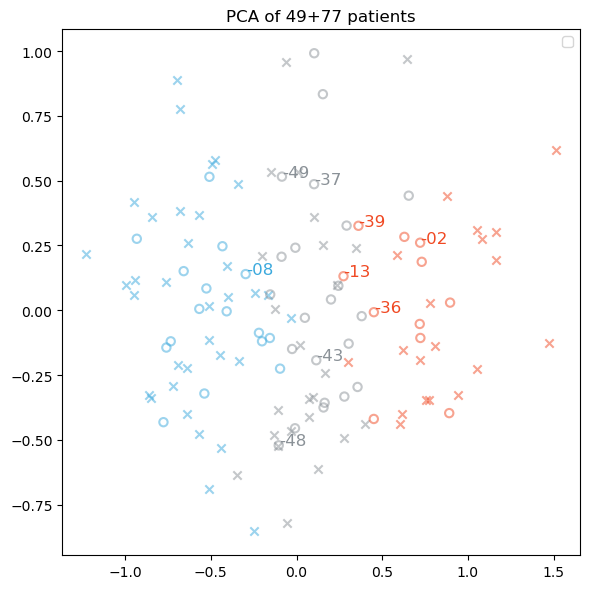

In [294]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))  # Assuming 30 figures, you can adjust the layout as needed

lw = 1.5
m_cluster = {"C1":'#F04923',"C2":'#3BA9DD',"Others":'#8A9197'}
m_organ_c = m_cluster #{'C1':'red','C2':'blue','Others':'black'}
m_set = {'Train':'x','Valid':'o'}

for _,row in labels.iterrows():
    x, y ,c,s,o = row[['x','y','Cluster','Set','sel_organ']]
    fc = 'none' if s == 'Valid' else m_cluster[c]
    ax.scatter(
        x, y, color=m_cluster[c], marker=m_set[s],
        alpha=0.5, lw=lw, facecolors=fc 
    )
    if not pd.isna(o):
        ax.text(x,y, s= o, alpha=1,fontsize=12,color= m_organ_c[c])

ax.legend(loc="best", shadow=False, scatterpoints=1)
ax.set_title("PCA of 49+77 patients")

plt.tight_layout()
plt.show()


### build ssgsea model

In [81]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.decomposition import PCA

In [65]:
matt_ss

,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_HYPOXIA,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_MITOTIC_SPINDLE,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_DNA_REPAIR,HALLMARK_G2M_CHECKPOINT,HALLMARK_APOPTOSIS,...,Monocyte,Natural killer cell,Natural killer T cell,Neutrophil,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 17 T helper cell,Type 2 T helper cell
P01,0.022661,0.091207,0.081716,-0.009366,0.184736,-0.081509,0.081935,0.133009,0.144519,0.214680,...,-0.156038,0.099613,0.129707,0.299286,0.053262,0.007581,0.126016,0.089989,0.054172,0.162087
P02,0.150915,0.082616,-0.126694,0.006097,0.022580,0.024921,0.245637,0.006072,0.076754,0.191690,...,0.013154,0.044508,0.065593,0.446971,0.099435,0.180644,0.117305,0.175953,0.066496,0.085536
P03,0.003253,0.002239,-0.108530,0.219912,0.174208,0.124641,-0.044700,0.149498,0.135504,0.054615,...,0.068394,0.039908,0.073207,-0.371589,-0.036356,-0.036607,0.001837,0.100879,-0.286916,0.139593
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P84,0.143644,0.194698,0.052249,0.134940,0.207453,0.143900,0.220094,0.018218,0.050047,0.266981,...,0.037890,0.132872,0.126653,0.262803,0.063256,0.197220,0.125649,0.167422,0.315014,0.156547
P85,0.118472,0.095104,-0.027578,0.134934,0.129635,0.098262,0.212846,0.037943,-0.113351,0.172940,...,0.008560,0.040041,0.129367,0.257113,0.058333,0.190280,0.058389,0.139765,0.074530,0.082249
P86,0.121001,0.121644,0.108661,0.007119,-0.048487,0.023428,0.026811,0.149146,0.110050,0.253600,...,0.031622,0.108736,0.135514,0.261234,0.047483,0.152714,0.204425,0.092353,0.053152,0.010375


In [66]:
XX = matt_ss
YY = yt

In [67]:
colData2

,Cluster,Set,sel_organ
P01,Others,Train,
P02,C2,Train,
P03,Others,Train,
...,...,...,...
P135,Others,Valid,-43
P137,Others,Valid,-48
P138,Others,Valid,-49


In [68]:
labelsall = colData2['Set']
labelsall

P01     Train
P02     Train
P03     Train
        ...  
P135    Valid
P137    Valid
P138    Valid
Name: Set, Length: 126, dtype: object

In [69]:
sel_organ_uid = [*mm.keys()]
sel_organ_uid

['P087', 'P088', 'P089', 'P090', 'P091', 'P092', 'P135', 'P137', 'P138']

In [70]:
best_pred ={
    "1528731":["C1"],
    "1535920":["C1","Others"],
    "1538224":["C1","C2"],
    "1554631":["Others"],
    "1555314":["C1"],
    "1557024":["C1"],
    "1563492":["Others"],
    "1567143":["Others"],
    "1567947":["C2"]
}
# convert best_pred.keys() from uid -> Custom_Label
_ = gv[gv['uid'].isin(best_pred.keys())].set_index('uid')['Custom_Label'].to_dict()
to = {}
for i in best_pred:
    to[_[i]] = best_pred[i]
best_pred = to
best_pred

{'P092': ['C1'],
 'P091': ['C1', 'Others'],
 'P088': ['C1', 'C2'],
 'P087': ['Others'],
 'P090': ['C1'],
 'P089': ['C1'],
 'P135': ['Others'],
 'P137': ['Others'],
 'P138': ['C2']}

In [71]:
COL = []

In [91]:
chosen = {'score':0.5,'C1':0}
mask = matv_ss.index.isin(mm.keys())
i = 0
add = 0
while True:
#     dtc = RandomForestClassifier() #
    dtc = SVC(C=1.5,probability = True)
    xtrain, xtest, ytrain, ytest = train_test_split(XX, YY, test_size=0.3, stratify=YY.values)

    dtc.fit(xtrain,ytrain)

    print(dtc.score(xtest,ytest))
    p2 = dtc.predict(matv_ss)
    p2 = pd.Series(p2,index=matv_ss.index)
    p = pd.Series(p2).value_counts()
    colData = pd.DataFrame({'Cluster':list(yt) + list(p2.values),'set':labelsall})
    
    _ = colData.loc[sel_organ_uid,:]
    _ = _['Cluster'].to_dict()
    
    ypred = dtc.predict(xtest)
    cm = confusion_matrix(ytest,ypred)
    cm = pd.DataFrame(cm, index=dtc.classes_,columns=dtc.classes_)
    cm.index.name = 'GroundTruth'
    PPV = cm.apply(lambda x: x[x.name] / x.sum(),0)[['C1','C2']].mean()
    
    print(f"PPV = {PPV}")
    
    if i==10000:
        break
#     if 'C1' in pd.Series(yv)[mask].values:
    if PPV > chosen['score'] or p['C1'] >= chosen['C1']:
        chosen = {'model':dtc,'score':PPV,'cm':cm,'C1':p['C1'],'xtest':xtest,'ytest':ytest}
    if PPV > 0.9 and p['C1']> 5 and p['C2'] > 10 and 'C1' in pd.Series(yv)[mask].values:
        print(f"PPV = {PPV}, #C1 = {p['C1']}")
        COL.append(dtc)
        add +=1
        if add >= 10:
            break
    cnt = 0
    for i,j in _.items():
        if j in best_pred[i]:
            cnt +=1
    if cnt > 3:
        break
#     _['ORG'] = pd.Series(mm)
    
    
p

1.0
PPV = 1.0


Others    24
C2        16
C1         9
Name: count, dtype: int64

In [147]:
xtest = chosen['xtest']
ytest = chosen['ytest']
ypred = dtc.predict(xtest)
cm = confusion_matrix(ytest,ypred)
cm = pd.DataFrame(cm, index=dtc.classes_,columns=dtc.classes_)
cm.index.name = 'GroundTruth'
PPV = cm.apply(lambda x: x[x.name] / x.sum(),0)[['C1','C2']].mean()
print(f"PPV = {PPV}")
cm

PPV = 1.0


,C1,C2,Others
GroundTruth,,,
C1,6,0,0
C2,0,11,0
Others,0,0,7


In [148]:
ypred = dtc.predict(matt_ss)
cm = confusion_matrix(yt,ypred)
cm = pd.DataFrame(cm, index=dtc.classes_,columns=dtc.classes_)
cm.index.name = 'GroundTruth'
PPV = cm.apply(lambda x: x[x.name] / x.sum(),0)[['C1','C2']].mean()
print(f"PPV = {PPV}")
cm

PPV = 1.0


,C1,C2,Others
GroundTruth,,,
C1,19,0,0
C2,0,33,1
Others,0,0,24


In [149]:
# pca = PCA(n_components=2)
# X_r = pca.fit_transform(pd.concat([matt_ss, matv_ss]))


In [150]:
yvbar = dtc.predict(matv_ss)
yvbar = pd.Series(yvbar, index = matv_ss.index)
yvbar

P087        C1
P088    Others
P089        C1
         ...  
P135    Others
P137    Others
P138    Others
Length: 49, dtype: object

In [151]:

pca = PCA(n_components=2)
X_r = pca.fit_transform(pd.concat([matt_ss, matv_ss]))


In [152]:
colData = pd.concat([pd.DataFrame({'Cluster':yt,'Set':"Train"}),
                    pd.DataFrame({'Cluster':yvbar,'Set':'Valid'})])
colData['sel_organ'] = ""
mask = colData.index.isin(list(mm.keys()))
colData.loc[mask,'sel_organ'] = list(mm.values())
colData2 = colData

data_pca = pd.merge(pd.DataFrame(X_r, columns=['x','y'],index = colData.index), 
                  colData2,
                  left_index=True,right_index=True,how='left')
data_pca


,x,y,Cluster,Set,sel_organ
P01,-0.124864,0.005349,Others,Train,
P02,-0.571491,0.366562,C2,Train,
P03,0.274756,-0.492967,Others,Train,
...,...,...,...,...,...
P135,0.115210,-0.192489,Others,Valid,-43
P137,-0.103788,-0.520864,Others,Valid,-48
P138,-0.085223,0.515667,Others,Valid,-49


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


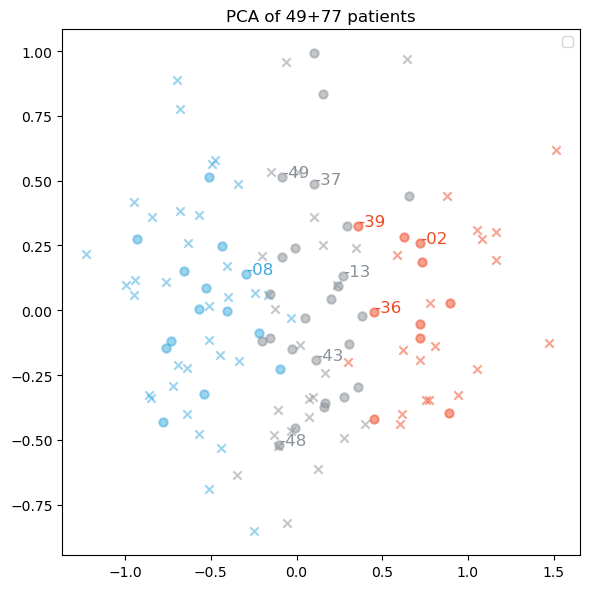

In [153]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))  # Assuming 30 figures, you can adjust the layout as needed

lw = 1.5
m_cluster = {"C1":'#F04923',"C2":'#3BA9DD',"Others":'#8A9197'}
m_organ_c = m_cluster # {'C1':'red','C2':'blue','Others':'black'}
m_set = {'Train':'x','Valid':'o'}

for _,row in data_pca.iterrows():
    x, y ,c,s,o = row[['x','y','Cluster','Set','sel_organ']]
    fc = 'none' if s == 'Valid' else m_cluster[c]
    ax.scatter(
        x, y, color=m_cluster[c], marker=m_set[s],
        alpha=0.5, lw=lw
    )
    if not pd.isna(o):
        ax.text(x,y, s= o, alpha=1,fontsize=12,color= m_organ_c[c])

ax.legend(loc="best", shadow=False, scatterpoints=1)
ax.set_title("PCA of 49+77 patients")

plt.tight_layout()
plt.show()


### ROC model Metrics

In [99]:
from sklearn.metrics import roc_curve, auc, RocCurveDisplay, roc_auc_score
from itertools import cycle
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
# import numpy as np
from sklearn.metrics import confusion_matrix


In [154]:
class_names = ['C1','C2','Others']
colors = cycle(['#F04923', '#3BA9DD','#8A9197'])

In [155]:
ypred = dtc.predict(xtest)
cm = confusion_matrix(ytest,ypred)
cm = pd.DataFrame(cm, index=dtc.classes_,columns=dtc.classes_)
cm.index.name = 'GroundTruth'
PPV = cm.apply(lambda x: x[x.name] / x.sum(),0)[['C1','C2']].mean()
print(f"PPV = {PPV}")
cm

PPV = 1.0


,C1,C2,Others
GroundTruth,,,
C1,6,0,0
C2,0,11,0
Others,0,0,7


In [156]:
ypred = dtc.predict(matt_ss)
cm = confusion_matrix(yt,ypred)
cm = pd.DataFrame(cm, index=dtc.classes_,columns=dtc.classes_)
cm.index.name = 'GroundTruth'
PPV = cm.apply(lambda x: x[x.name] / x.sum(),0)[['C1','C2']].mean()
print(f"PPV = {PPV}")
cm

PPV = 1.0


,C1,C2,Others
GroundTruth,,,
C1,19,0,0
C2,0,33,1
Others,0,0,24


In [393]:
from sklearn.metrics import precision_score, recall_score, accuracy_score, roc_auc_score

# Calculate Bx_avoided for class 2
def calculate_bx_avoided(cm, target_class):
    FP = cm[:, target_class].sum() - cm[target_class, target_class]
    TN = cm.sum() - (cm[target_class, :].sum() + cm[:, target_class].sum() - cm[target_class, target_class])
    FN = cm[target_class, :].sum() - cm[target_class, target_class]

    total_non_target = TN + FN
    avoidance_rate = 1 - (FP / total_non_target) if total_non_target > 0 else 0

    return avoidance_rate * 100

def bootstrap_auc(y_true_binary, y_pred_binary, n_bootstraps, seed=None):
    bootstrapped_scores = []
    rng = np.random.RandomState(seed)
    
    for _ in range(n_bootstraps):
        # Bootstrap by sampling with replacement
        indices = rng.randint(0, len(y_pred_binary), len(y_pred_binary))
        if len(np.unique(y_true_binary[indices])) < 2:
            # We need at least one positive and one negative sample
            continue
        
        score = roc_auc_score(y_true_binary[indices], y_pred_binary[indices])
        bootstrapped_scores.append(score)
    
    sorted_scores = np.array(bootstrapped_scores)
    sorted_scores.sort()
    
    # Compute the 2.5th and 97.5th percentiles (95% CI)
    lower_bound = np.percentile(sorted_scores, 2.5)
    upper_bound = np.percentile(sorted_scores, 97.5)
    
    return lower_bound, upper_bound

def calc_metrics(dtc, x, y_true, class_to_avoid = 'Others', digits = 1
                 , n_bootstraps = 500,random_seed=42, represent = False):
    # Accuracy
    y_pred = dtc.predict(x)
    cm = confusion_matrix(y_true,y_pred)

    # Classification Report: includes Precision (PPV), Recall (Sensitivity)
    report = classification_report(y_true, y_pred, target_names=dtc.classes_,output_dict=True)

    # Compute Specificity and NPV manually
    # Sensitivity (Recall), Specificity, and NPV calculations
    specificity = {}
    npv = {}
    
    res = {i:report[i] for i in dtc.classes_}
    
    colfrm = ['AUC','lower','upper','Sensitivity','Specificity','NPV','PPV','Accuracy','Total Accuracy']
    colnames = ['AUC','95% CI lower','95% CI upper','Sen(%)','Spe(%)',"NPV(%)",'PPV(%)','Accuracy(%)','Total Accuracy(%)']
    
    for i in range(cm.shape[0]):
        cls = dtc.classes_[i]
        tn = cm.sum() - (cm[i, :].sum() + cm[:, i].sum() - cm[i, i])
        fp = cm[:, i].sum() - cm[i, i]
        fn = cm[i, :].sum() - cm[i, i]
        tp = cm[i, i]

        
        res[cls]['Sensitivity'] = res[cls]['recall']
        res[cls]['Specificity'] = tn / (tn + fp) if (tn + fp) > 0 else 0
        res[cls]['PPV'] = res[cls]['precision']
        res[cls]['NPV'] = tn / (tn + fn) if (tn + fn) > 0 else 0 * 100
        

    # Calculate AUC for each class
    y_true_bin = pd.get_dummies(y_true).values
    y_pred_bin = pd.get_dummies(y_pred).values

    auc_scores = []
    for i in range(y_true_bin.shape[1]):
        cls = dtc.classes_[i]
        auc = roc_auc_score(y_true_bin[:, i], y_pred_bin[:, i])
        accuracy = accuracy_score(y_true_bin[:, i], y_pred_bin[:, i])
        auc_scores.append(auc)
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_bin[:, i])
        lower_bound, upper_bound = bootstrap_auc(y_true_bin[:, i], y_pred_bin[:, i], n_bootstraps, seed=random_seed)
        
        res[cls]["AUC"] = auc
        res[cls]['lower'] = lower_bound
        res[cls]['upper'] = upper_bound
        res[cls]['Accuracy'] = accuracy
        
    res = pd.DataFrame(res).T
    
    accuracy = accuracy_score(y_true, y_pred)
    res['Total Accuracy'] = accuracy
    
    res = res[colfrm]
    res.loc[:,colfrm] = (res.loc[:,colfrm].values * 100).round(digits)
    res.columns = colnames
    # Note: `Bx_avoided` is not a standard metric in sklearn; you may need to clarify its definition or compute it based on domain-specific logic.
    
    cta = np.where(dtc.classes_==class_to_avoid)[0][0]
    bx_avoided = calculate_bx_avoided(cm, cta)
    res['Bx Class'] = ""
    res.loc[class_to_avoid,'Bx Class'] = '√'
    
    res['Bx Avoided(%)'] = np.nan
    res.loc[class_to_avoid,'Bx Avoided(%)'] = round(bx_avoided,digits)
    res.insert(0,'AUC(95% CI)', res["AUC"].astype(str) + " (" +res['95% CI lower'].astype(str) +'-'+res['95% CI upper'].astype(str)+ ")"  )
    if represent:
        res = res[['AUC(95% CI)','Sen(%)','Spe(%)',"NPV(%)",'PPV(%)','Accuracy(%)','Total Accuracy(%)','Bx Class','Bx Avoided(%)']]
    res = pd.merge(cm, res, left_index=True, right_on='Class', how ='inner', suffixes=['','__xx'] )
    return res


    
from sklearn.metrics import roc_curve, auc, RocCurveDisplay, roc_auc_score
from itertools import cycle
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize

def plot_auc_3plus(dtc, X, ytruth,
                   class_names =['C1','C2','Others'],
                   colors = cycle(['#F04923', '#3BA9DD','#8A9197']),
                   plot_micro_average_curve = True
                  ):
    
    # If your target labels are not already binarized (one-hot encoded), you'll need to do so:
    ytruth_bin = label_binarize(ytruth, classes=class_names)
    n_classes = ytruth_bin.shape[1]

    # Predict probabilities
    y_score = dtc.predict_proba(X)

    # Compute ROC curve and ROC area for each class
    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(ytruth_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
        
    # Compute micro-average ROC curve and ROC area
    if plot_micro_average_curve:
        ytruth_bin_c1_c2 = ytruth_bin[:,:2]
        y_score_c1_c2 = y_score[:,:2]
        fpr["micro"], tpr["micro"], _ = roc_curve(ytruth_bin_c1_c2.ravel(), y_score_c1_c2.ravel())
        roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])
    #return fpr, tpr, roc_auc
    # Plot all ROC curves
    fig = plt.figure(figsize=(8,8))

    for i, color in zip(range(n_classes), colors):
        plt.plot(fpr[i], tpr[i], color=color, lw=2,
                 label='ROC curve of class {0} (area = {1:0.4f})'
                 ''.format(class_names[i], roc_auc[i]))
    if plot_micro_average_curve:
        plt.plot(fpr["micro"], tpr["micro"],
                 label='micro-average ROC curve (C1 & C2) (area = {0:0.4f})'
                       ''.format(roc_auc["micro"]),
                 color='deeppink', linestyle='--', linewidth=2)

    plt.plot([0, 1], [0, 1], 'k--', lw=2) 
    plt.xlim([-0.01, 1.0]) 
    plt.ylim([0.0, 1.01])
    plt.xlabel('False Positive Rate') 
    plt.ylabel('True Positive Rate') 
    plt.title('Receiver Operating Characteristic for Multi-Class') 
    plt.legend(loc="lower right") 
#     plt.show()
    return fig


In [398]:
x = chosen['xtest']
y_true = chosen['ytest']

class_to_avoid = 'C1'
digits = 1

n_bootstraps = 1000
random_seed=42
represent = False

In [453]:
class_names = dtc.classes_
n_classes = len(class_names)
# Accuracy
y_pred = dtc.predict(x)
cm = confusion_matrix(y_true,y_pred)
y_prob = dtc.predict_proba(x)

res = {i:report[i] for i in dtc.classes_}

colfrm = ['AUC','lower','upper','Sensitivity','Specificity','NPV','PPV','Accuracy','Total Accuracy']
colnames = ['AUC','95% CI lower','95% CI upper','Sen(%)','Spe(%)',"NPV(%)",'PPV(%)','Accuracy(%)','Total Accuracy(%)']

for i in range(cm.shape[0]):
    cls = dtc.classes_[i]
    tn = cm.sum() - (cm[i, :].sum() + cm[:, i].sum() - cm[i, i])
    fp = cm[:, i].sum() - cm[i, i]
    fn = cm[i, :].sum() - cm[i, i]
    tp = cm[i, i]


    res[cls]['Sensitivity'] = res[cls]['recall']
    res[cls]['Specificity'] = tn / (tn + fp) if (tn + fp) > 0 else 0
    res[cls]['PPV'] = res[cls]['precision']
    res[cls]['NPV'] = tn / (tn + fn) if (tn + fn) > 0 else 0 * 100


# Calculate AUC for each class
y_true_bin = pd.get_dummies(y_true).values
y_pred_bin = pd.get_dummies(y_pred).values

In [457]:
ytruth_bin_c1_c2 = y_true_bin[:,:2].ravel()
y_score_c1_c2 = y_prob[:,:2].ravel()
fpr, tpr, _ = roc_curve(ytruth_bin_c1_c2, y_score_c1_c2)
# roc_auc = roc_auc_score(ytruth_bin_c1_c2, y_score_c1_c2)

In [458]:
fpr

array([0.        , 0.03225806, 0.03225806, 0.12903226, 0.12903226,
       0.19354839, 0.19354839, 0.29032258, 0.29032258, 0.32258065,
       0.32258065, 0.38709677, 0.4516129 , 0.4516129 , 0.48387097,
       0.48387097, 0.51612903, 0.51612903, 0.58064516, 0.67741935,
       0.67741935, 0.77419355, 0.83870968, 0.90322581, 0.93548387,
       1.        ])

In [409]:
yprob = dtc.predict_proba(x)

In [412]:
?accuracy_score

In [418]:
?roc_auc_score

In [413]:
roc_auc_score(y_true_bin[:, i], y_pred_bin[:, i])

0.5966386554621849

In [417]:
?auc

In [411]:
fpr, tpr, _ = roc_curve(y_true_bin[:, i], yprob[:, i])
fpr

array([0.        , 0.05882353, 0.11764706, 0.11764706, 0.17647059,
       0.17647059, 0.64705882, 0.64705882, 0.76470588, 0.76470588,
       0.82352941, 0.94117647, 1.        , 1.        ])

In [407]:
roc_curve(y_true_bin[:, i], y_pred_bin[:, i])


(array([0.        , 0.23529412, 1.        ]),
 array([0.        , 0.42857143, 1.        ]),
 array([inf,  1.,  0.]))

In [403]:
y_pred

array(['C2', 'C2', 'Others', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2', 'C2',
       'C2', 'C2', 'C2', 'C2', 'Others', 'Others', 'Others', 'C2', 'C2',
       'C1', 'Others', 'Others', 'C2', 'Others'], dtype=object)

In [401]:
y_pred_bin

array([[False,  True, False],
       [False,  True, False],
       [False, False,  True],
       [False,  True, False],
       [False,  True, False],
       [False,  True, False],
       [False,  True, False],
       [False,  True, False],
       [False,  True, False],
       [False,  True, False],
       [False,  True, False],
       [False,  True, False],
       [False,  True, False],
       [False,  True, False],
       [False, False,  True],
       [False, False,  True],
       [False, False,  True],
       [False,  True, False],
       [False,  True, False],
       [ True, False, False],
       [False, False,  True],
       [False, False,  True],
       [False,  True, False],
       [False, False,  True]])

In [400]:
y_true_bin

array([[False,  True, False],
       [False,  True, False],
       [ True, False, False],
       [False, False,  True],
       [False,  True, False],
       [ True, False, False],
       [False, False,  True],
       [False,  True, False],
       [False,  True, False],
       [ True, False, False],
       [False, False,  True],
       [False,  True, False],
       [False,  True, False],
       [False,  True, False],
       [False, False,  True],
       [ True, False, False],
       [ True, False, False],
       [False, False,  True],
       [False,  True, False],
       [ True, False, False],
       [False, False,  True],
       [False, False,  True],
       [False,  True, False],
       [False,  True, False]])

In [237]:
metri = calc_metrics(dtc, xtest, ytest,represent=True).reset_index(names = 'Class')
metri


,Class,AUC(95% CI),Sen(%),Spe(%),NPV(%),PPV(%),Accuracy(%),Total Accuracy(%),Bx Class,Bx Avoided(%)
0,C1,100.0 (100.0-100.0),100.0,100.0,100.0,100.0,100.0,100.0,,NaN
1,C2,100.0 (100.0-100.0),100.0,100.0,100.0,100.0,100.0,100.0,,NaN
2,Others,100.0 (100.0-100.0),100.0,100.0,100.0,100.0,100.0,100.0,√,100.0


In [238]:
metri2 = calc_metrics(dtc, matt_ss, yt, represent=True).reset_index(names = 'Class')
metri2

,Class,AUC(95% CI),Sen(%),Spe(%),NPV(%),PPV(%),Accuracy(%),Total Accuracy(%),Bx Class,Bx Avoided(%)
0,C1,100.0 (100.0-100.0),100.0,100.0,100.0,100.0,100.0,98.7,,NaN
1,C2,98.5 (95.3-100.0),97.1,100.0,97.7,100.0,98.7,98.7,,NaN
2,Others,99.1 (97.0-100.0),100.0,98.1,100.0,96.0,98.7,98.7,√,98.1


In [241]:
?write_excel

In [246]:
write_excel({
        f'test_set_{len(xtest)}':metri,
        f"train_test_{len(matt_ss)}":metri2
    }
    ,'fig.S10_Model_Metrics.xlsx'
    ,outputdir='report_reply/'
)



  append #1 Sheet [test_set_24]
  append #2 Sheet [train_test_77]
writing 1 .xls @ report_reply/fig.S7_Model_Metrics.xlsx


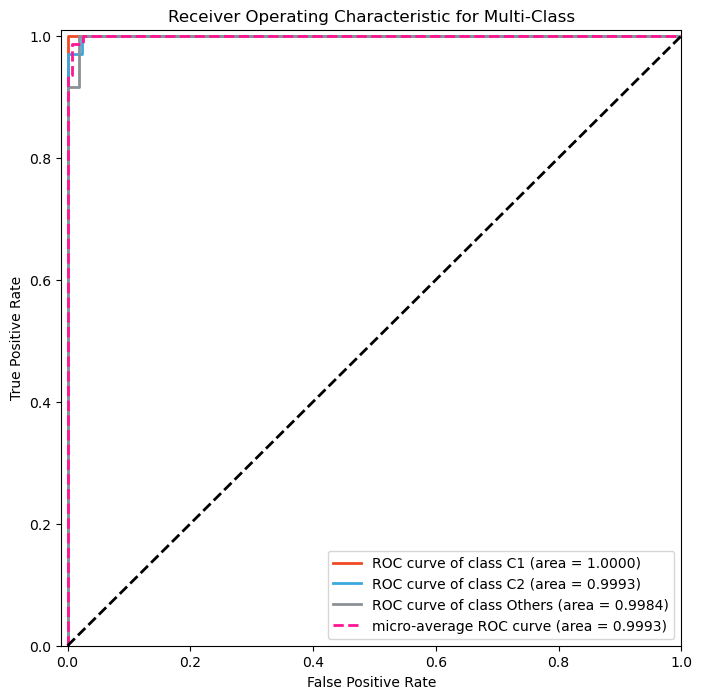

In [176]:
fig_test = plot_auc_3plus(dtc, matt_ss, yt)

In [ ]:
db.exporting(fig_test, 'fig.S10_train_test_ROC.pdf', outputdir='report_reply/')

### dump

In [496]:
data_pca = pd.concat([pd.DataFrame(X_r,columns=['x1','x2']),colData.reset_index()],axis=1)
info1 = glx[['Custom_Label','uid']].set_index('Custom_Label')
info1.index.name = None
info2 = glx2[['Custom_Label','uid']].set_index('Custom_Label')
info2.index.name = None
i = pd.concat([info1,info2])
data_pca = pd.merge(data_pca, i, how='left', left_on='index', right_index=True)
data_pca


,x1,x2,index,Cluster,Set,sel_organ,uid
0,-0.124864,0.005349,P01,Others,Train,,1428424
1,-0.571491,0.366562,P02,C2,Train,,1448200
2,0.274756,-0.492967,P03,Others,Train,,1418501
...,...,...,...,...,...,...,...
123,0.115210,-0.192489,P135,Others,Valid,-43,1563492
124,-0.103788,-0.520864,P137,Others,Valid,-48,1567143
125,-0.085223,0.515667,P138,Others,Valid,-49,1567947


In [497]:
echo(data_pca)

,x1,x2,index,Cluster,Set,sel_organ,uid
0,-0.124864,0.005349,P01,Others,Train,,1428424
1,-0.571491,0.366562,P02,C2,Train,,1448200
2,0.274756,-0.492967,P03,Others,Train,,1418501
3,-0.399041,0.050338,P04,C2,Train,,1415218
4,-0.947650,0.418156,P05,C2,Train,,1400438
5,-0.509523,-0.114389,P06,C2,Train,,1366639
6,0.940411,-0.327549,P07,C1,Train,,1338183
7,0.124060,-0.612963,P08,Others,Train,,1308161
8,-0.106493,-0.385775,P09,Others,Train,,1305008
9,0.875399,0.441382,P10,C1,Train,,1465475


In [498]:
db.exporting(data_pca,'ssgsea_pca_data',outputdir='export_model/')


[08/03 12:53:16] overwritting 1 file with 126 lines at 
	[PROJECT_ROOT]/export_model/ssgsea_pca_data.dfx


In [482]:
glx = db.importing('external_info/Proteomics52/washed/prt_glx.dfx')
glx2 = pd.merge(glx, colData,left_on='Custom_Label',right_index=True,how='left',suffixes=['','__xx'])
glx2['set'] = 'Valid'
glx2['Cluster'] = glx2['Cluster'].fillna('pCR')
db.exporting(glx2,'prt_glx_with_predict',outputdir='external_info/Proteomics52/washed/')
glx = db.importing('export_by2_86_pCR_nonpCR/wes_glx.dfx')

glx2


[08/03 12:49:11]reading external_info/Proteomics52/washed/prt_glx.dfx
[08/03 12:49:11] overwritting 1 file with 52 lines at 
	[PROJECT_ROOT]/external_info/Proteomics52/washed/prt_glx_with_predict.dfx
[08/03 12:49:11]reading export_by2_86_pCR_nonpCR/wes_glx.dfx


,Custom_Label,uid,source,Group,Cluster,Set,sel_organ,set
0,P087,1554631,valid52,non.pCR,C1,Valid,-36,Valid
1,P088,1538224,valid52,non.pCR,Others,Valid,-13,Valid
2,P089,1557024,valid52,non.pCR,C1,Valid,-39,Valid
...,...,...,...,...,...,...,...,...
49,P136,1566005,valid52,pCR,pCR,NaN,NaN,Valid
50,P137,1567143,valid52,non.pCR,Others,Valid,-48,Valid
51,P138,1567947,valid52,non.pCR,Others,Valid,-49,Valid


,uid
P01,1428424
P02,1448200
P03,1418501
...,...
P136,1566005
P137,1567143
P138,1567947


,x1,x2,Cluster,Set,sel_organ,uid
P01,-0.124864,0.005349,Others,Train,NaN,1428424
P02,-0.571491,0.366562,C2,Train,NaN,1448200
P03,0.274756,-0.492967,Others,Train,NaN,1418501
...,...,...,...,...,...,...
P135,0.115210,-0.192489,Others,Valid,-43.0,1563492
P137,-0.103788,-0.520864,Others,Valid,-48.0,1567143
P138,-0.085223,0.515667,Others,Valid,-49.0,1567947


In [324]:
dtc

SVC(C=1.5)

In [325]:
import sklearn
sklearn.__version__

'1.3.0'

In [326]:
ALL = [dtc, matall, xtrain,xtest,ytrain,ytest, XX,YY,
       matt_ss, matv_ss, yv,yt, colData, colData2,sel_organ_uid, gt,gv,
#        mm, chosen
      ]
joblib.dump(ALL,f'export_model/ssgsea_dtc_sklearn{sklearn.__version__}_240803.joblib')

['export_model/ssgsea_dtc_sklearn1.3.0_240803.joblib']

In [259]:
db.exporting(matv_ss, 'external_info/Proteomics52/washed/prt_ssgsea_matv_ss')
db.exporting(colData[colData.index.isin(matv_ss.index)],'external_info/Proteomics52/washed/prt_ssgsea_yv_colData')

[07/28 03:31:16] writing 1 file with 49 lines at 
	[PROJECT_ROOT]/external_info/Proteomics52/washed/prt_ssgsea_matv_ss.dfx
[07/28 03:31:16] writing 1 file with 49 lines at 
	[PROJECT_ROOT]/external_info/Proteomics52/washed/prt_ssgsea_yv_colData.dfx


In [246]:
db.exporting(matall, 'external_info/Proteomics52/washed/prt_ssgsea_matall')

[07/28 03:03:08] writing 1 file with 126 lines at 
	[PROJECT_ROOT]/external_info/Proteomics52/washed/prt_ssgsea_matall.dfx


In [248]:
db.exporting(matall, 'export_model/prt_ssgsea_matall')
db.exporting(colData, 'export_model/prt_colData')

[07/28 03:09:15] writing 1 file with 126 lines at 
	[PROJECT_ROOT]/export_model/prt_ssgsea_matall.dfx
[07/28 03:09:15] writing 1 file with 126 lines at 
	[PROJECT_ROOT]/export_model/prt_colData.dfx


### load

In [280]:
dtc, matall, xtrain,xtest,ytrain,ytest, XX,YY,matt_ss, matv_ss, yv,yt, \
    colData, colData2,sel_organ_uid, gt,gv = joblib.load('export_model/ssgsea_dtc_sklearn1.3.0_240803.joblib')

## IHC model

### prepare X

In [81]:
import openpyxl

In [82]:
rawdata_ihc_v52 = 'external_info/IHC/02师姐返回52例分子分型前瞻验证4marker染色评分v3.0（染色重判）.xlsx'
rawdata_ihc_t77 = "external_info/IHC/77例分子分型切片4marker染色评分v3.0（Vim re-scored）.xlsx"

In [83]:
book52 = openpyxl.load_workbook(rawdata_ihc_v52)
book77 = openpyxl.load_workbook(rawdata_ihc_t77)
# book_ext = openpyxl.load_workbook('external_info/IHC/CD8免疫组化染色结果v1.0.xlsx')

book52.sheetnames

['CANT1', 'MRE11', 'VIM（包含间质）', 'VIM（只评肿瘤）', 'CD8']

In [84]:
book77.sheetnames

['VIM (re-scored incl. stroma)', 'VIM (re-scored tumor only)', 'MRE11', 'CANT1', 'CD8']

In [85]:
def rank(x:[np.array,pd.Series,list]):
    if type(x)==list:
        x = np.array(x)
    mask = ~x.isna()
    y = np.full_like(x,np.nan)
    for t,n in zip([0.05,0.25,0.5,0.75,1],[0,1,2,3,4]):
        to_fill = x <= t
        y[to_fill & mask] = n
        mask = ~to_fill & mask
    if type(x) == pd.Series:
        return pd.Series(y,index=x.index,name=x.name)
    else:
        return y

In [86]:
glx = db.importing('export_by2_86_pCR_nonpCR/wes_glx.dfx')
# glx = glx[glx['Response']!='pCR']
colData = glx[['uid','Custom_Label','Protein_Cluster']].rename(columns={'Custom_Label':'tsb'})
colData['uid'] = colData['uid'].astype(str)
colData['G3'] = ['C1' if i =='C1' else 'C2' if i=='C2' else 'Co' for i in colData['Protein_Cluster']]
mp = colData.set_index('uid')['tsb'].to_dict()
colData

[08/24 04:47:25]reading export_by2_86_pCR_nonpCR/wes_glx.dfx


,uid,tsb,Protein_Cluster,G3
0,1428424,P01,C4,Co
1,1448200,P02,C2,C2
2,1418501,P03,C3,Co
...,...,...,...,...
83,1454489,P84,C2,C2
84,1477341,P85,C2,C2
85,1481407,P86,C2,C2


In [87]:
colData[colData['tsb']=='P39']

,uid,tsb,Protein_Cluster,G3
38,1381312,P39,C1,C1


In [88]:
# handle train test
import re
collect = []

for sheetname in ['VIM (re-scored incl. stroma)', 'MRE11', 'CANT1', 'CD8']:
    df = pd.read_excel(rawdata_ihc_t77,sheet_name=sheetname,engine='openpyxl')
    marker = re.sub('[^A-Z0-9]','',sheetname)
    if marker !='CD8':
        df['Cluster颜色'] = df['Cluster颜色'].astype(int).astype(str)
        df['sit'] = df['染色情况（阴性：0分；+：1分；++：2分；+++：3分）'].fillna(0)
        df['per'] = df['染色比例（0-5%：0分；6-25%：1分；26-50%：2分；51-75%：3分；76-100%：4分）']
        df['H'] = df['H-score']
        if df['per'].dtype==int and df['per'].max() <5:
            pass
        else:
            if df['per'].mean() > 5:
                df['per'] = df['per'] / 100
            df['per'] = rank(df['per'])
        #     df['H'] = df['sit'] * df['per']
        mk = df.set_index('Cluster颜色')[['sit','per','H']].copy()
        mk.columns = marker+"_"+pd.Series(['sit','per','H'])
        mk.index = [mp[i] for i in mk.index]
        mk.index.name = None
        mk.name = marker
        mk = mk.sort_index()
        collect.append(mk)
    else:
        df['Cluster颜色'] = df['Cluster颜色'].astype(int).astype(str)
#         df['CD8'] = pd.Series(df['CD8阳性细胞占肿瘤灶比例（%）'] >= 0.1).astype(int)
        df['CD8'] = df['CD8阳性细胞占肿瘤灶比例（%）'] 
        cd8 = df.set_index('Cluster颜色')[['CD8']] 
        cd8.index = [mp[i] for i in cd8.index]
        cd8.index.name = None
        # cd8.name = "CD8"
        cd8 = cd8.sort_index()
        collect.append(cd8)

matt = pd.concat(collect,axis=1)
matt = matt.astype(float)

matt

,VIM_sit,VIM_per,VIM_H,MRE11_sit,MRE11_per,MRE11_H,CANT1_sit,CANT1_per,CANT1_H,CD8
P01,2.0,2.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.05
P02,2.0,2.0,4.0,0.0,0.0,0.0,1.0,2.0,2.0,0.10
P03,2.0,2.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.10
...,...,...,...,...,...,...,...,...,...,...
P84,2.0,2.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.05
P85,2.0,2.0,4.0,1.0,2.0,2.0,0.0,0.0,0.0,0.10
P86,3.0,2.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00


In [89]:
gv = db.importing('external_info/Proteomics52/washed/prt_glx.dfx')
gv = gv[gv['Group']!='pCR']
gv['uid'] = gv['uid'].astype(str)

organ_info = db.importing('external_info/Organoids/湘雅医院前列腺癌类器官队列信息v3.0.xlsx')
organ_info = organ_info[~organ_info['根治术病理号'].isna()][['根治术病理号','类器官序列号']].rename(columns={'根治术病理号':'uid','类器官序列号':'ooid'})
organ_info['uid'] = organ_info['uid'].astype(int).astype(str)
organ_info['oid'] = organ_info['ooid'].str.lstrip('ORG')
sel_organ_uid = ["1528731","1535920","1538224","1554631","1555314","1557024","1563492","1567143","1567947"]
gv = pd.merge(gv, organ_info,on='uid',how='left',suffixes=['','__xx'])
gv['sel'] = ""
mask = gv['uid'].isin(sel_organ_uid)
gv.loc[mask,'sel'] = gv.loc[mask,'oid']
# gv.index = gv['Custom_Label']
gv.sample(8)

[08/24 04:47:26]reading external_info/Proteomics52/washed/prt_glx.dfx
[08/24 04:47:26]reading external_info/Organoids/湘雅医院前列腺癌类器官队列信息v3.0.xlsx
  Sheets list: ['总表', 'Sheet1', '影像学资料获取', '类器官药筛已完成', '单细胞测序送样筛选', 'WES送样']
  Read the 1 / 6 sheet named <总表>


,Custom_Label,uid,source,Group,ooid,oid,sel
18,P105,1510834,valid52,non.pCR,NaN,NaN,
3,P090,1555314,valid52,non.pCR,ORG-37,-37,-37
19,P106,1511128,valid52,non.pCR,NaN,NaN,
...,...,...,...,...,...,...,...
26,P114,1516112,valid52,non.pCR,NaN,NaN,
32,P121,1524487,valid52,non.pCR,NaN,NaN,
28,P116,1517415,valid52,non.pCR,NaN,NaN,


In [90]:
mm = gv[(gv['sel']!='') & ~gv['oid'].isna()].set_index('Custom_Label')['oid'].to_dict()
mm

{'P087': '-36',
 'P088': '-13',
 'P089': '-39',
 'P090': '-37',
 'P091': '-08',
 'P092': '-02',
 'P135': '-43',
 'P137': '-48',
 'P138': '-49'}

In [91]:
# handle valid
collect = []
for sheetname in ['CANT1', 'MRE11', 'VIM（包含间质）', 'CD8']:
    df = pd.read_excel(rawdata_ihc_v52,sheet_name=sheetname,engine='openpyxl')
    marker = re.sub('[^A-Z0-9]','',sheetname)
    if marker != 'CD8':
    #     df['Cluster颜色'] = df['Cluster颜色'].astype(int).astype(str)
    #     mk = df.set_index('Cluster颜色')['染色比例（0-5%：0分；6-25%：1分；26-50%：2分；51-75%：3分；76-100%：4分）'].fillna(0) / 100
    #     mk.index.name = None
    #     mk.name = marker
    #     mk = mk.sort_index()
    #     mk = rank(mk)
    #     collect.append(mk)
        df['Cluster颜色'] = df['Cluster颜色'].astype(int).astype(str)
        df['sit'] = df['染色情况（阴性：0分；+：1分；++：2分；+++：3分）'].fillna(0)
        df['per'] = df['染色比例（0-5%：0分；6-25%：1分；26-50%：2分；51-75%：3分；76-100%：4分）'].fillna(0)
        df['H'] = df['H-score']
        if df['per'].dtype==int and df['per'].max() <5:
            pass
        else:
            if df['per'].mean() > 5:
                df['per'] = df['per'] / 100
            df['per'] = rank(df['per'])
    #     df['H'] = df['sit'] * df['per']
        mk = df.set_index('Cluster颜色')[['sit','per','H']].copy()
        mk.columns = marker+"_"+pd.Series(['sit','per','H'])
        mk.index.name = None
        mk.name = marker
        mk = mk.sort_index()
        collect.append(mk)

    else:
#         df['CD8'] = pd.Series(df['染色比例（0-5%：0分；6-25%：1分；26-50%：2分；51-75%：3分；76-100%：4分）'] >= 0.1).astype(int)
        df['CD8'] = df['染色比例（0-5%：0分；6-25%：1分；26-50%：2分；51-75%：3分；76-100%：4分）']
        df['Cluster颜色'] = df['Cluster颜色'].astype(int).astype(str)
        cd8 = df.set_index('Cluster颜色')[['CD8']]
        cd8.index.name = None
        # cd8.name = "CD8"
        cd8 = cd8.sort_index()
        if cd8['CD8'].mean() > 1:
            cd8['CD8'] = cd8['CD8'] / 100
        collect.append(cd8)

matv = pd.concat(collect, axis=1)
matv = matv.loc[gv['uid']]
matv.index = gv['Custom_Label']
matv.index.name =None
matv = matv[matt.columns]
matv

,VIM_sit,VIM_per,VIM_H,MRE11_sit,MRE11_per,MRE11_H,CANT1_sit,CANT1_per,CANT1_H,CD8
P087,1,2.0,2,1,2.0,2,2,2.0,4,0.0
P088,1,3.0,3,1,4.0,4,1,2.0,2,0.1
P089,1,3.0,3,1,4.0,4,1,4.0,4,0.0
...,...,...,...,...,...,...,...,...,...,...
P135,2,2.0,4,0,0.0,0,0,0.0,0,0.0
P137,2,2.0,4,1,1.0,1,1,1.0,1,0.1
P138,1,2.0,2,0,0.0,0,0,0.0,0,0.3


### prepare Y

In [92]:
data_pca = db.importing('ssgsea_pca_data',frm='export_model/').set_index('index')
data_pca.index.name = None
data_pca

[08/24 04:47:29]reading export_model/ssgsea_pca_data.dfx


,x1,x2,Cluster,Set,sel_organ,uid
P01,-0.124864,0.005349,Others,Train,NaN,1428424
P02,-0.571491,0.366562,C2,Train,NaN,1448200
P03,0.274756,-0.492967,Others,Train,NaN,1418501
...,...,...,...,...,...,...
P135,0.115210,-0.192489,Others,Valid,-43.0,1563492
P137,-0.103788,-0.520864,Others,Valid,-48.0,1567143
P138,-0.085223,0.515667,Others,Valid,-49.0,1567947


In [93]:
yt = data_pca.loc[matt.index,'Cluster']
yt

P01    Others
P02        C2
P03    Others
        ...  
P84        C2
P85        C2
P86        C2
Name: Cluster, Length: 77, dtype: object

In [94]:
yv = data_pca.loc[matv.index,'Cluster']
yv

P087        C1
P088    Others
P089        C1
         ...  
P135    Others
P137    Others
P138    Others
Name: Cluster, Length: 49, dtype: object

In [95]:
assert (matt.index==yt.index).all()

assert (matv.index==yv.index).all()


In [298]:
gv[gv['Custom_Label']=='P121']

,Custom_Label,uid,source,Group,ooid,oid,sel
32,P121,1524487,valid52,non.pCR,NaN,NaN,


### merge t v check PCA distribution

In [96]:
matall = pd.concat([matt,matv])
# if matall['VIM_per'].mean() < 1:
#     matall['VIM_per'] = matall['VIM_per'] * 10
# if matall['CD8'].mean() < 1:
#     matall['CD8'] = matall['CD8'] * 10
yall = pd.concat([yt,yv])
matall

,VIM_sit,VIM_per,VIM_H,MRE11_sit,MRE11_per,MRE11_H,CANT1_sit,CANT1_per,CANT1_H,CD8
P01,2.0,2.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.05
P02,2.0,2.0,4.0,0.0,0.0,0.0,1.0,2.0,2.0,0.10
P03,2.0,2.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.10
...,...,...,...,...,...,...,...,...,...,...
P135,2.0,2.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00
P137,2.0,2.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,0.10
P138,1.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.30


In [300]:
yall

P01     Others
P02         C2
P03     Others
         ...  
P135    Others
P137    Others
P138    Others
Name: Cluster, Length: 126, dtype: object

In [301]:
# matall = matall.loc[:,~matall.columns.str.endswith('_sit')]

In [302]:
# matall['CANT1_per'] = matall['CANT1_per'] * 10
# matall['CANT1_sit'] = matall['CANT1_sit'] * 10
# matall['CD8'] =  matall['CD8'] * 20

In [303]:
matall.loc[matall.isna().sum(axis=1)>0,]

,VIM_sit,VIM_per,VIM_H,MRE11_sit,MRE11_per,MRE11_H,CANT1_sit,CANT1_per,CANT1_H,CD8


In [304]:
from sklearn.decomposition import PCA

pca = PCA(n_components=4)
X_r = pd.DataFrame(pca.fit_transform(matall),index=matall.index ,columns=['X1','X2','X3','X4'])
X_r

labels = pd.merge(X_r.rename(columns={'X1':'x','X2':'y'}), 
                  data_pca[['Cluster','Set','sel_organ']],
                  left_index=True,right_index=True,how='left')
labels

,x,y,X3,X4,Cluster,Set,sel_organ
P01,-5.080174,0.133706,0.138262,0.542590,Others,Train,NaN
P02,-3.202528,-1.998804,-0.085908,0.247085,C2,Train,NaN
P03,-5.080266,0.133724,0.138558,0.543240,Others,Train,NaN
...,...,...,...,...,...,...,...
P135,-5.080081,0.133687,0.137965,0.541940,Others,Valid,-43.0
P137,-2.929224,-0.053938,0.047312,0.261909,Others,Valid,-48.0
P138,-5.159247,0.257390,-2.060029,0.740305,Others,Valid,-49.0


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


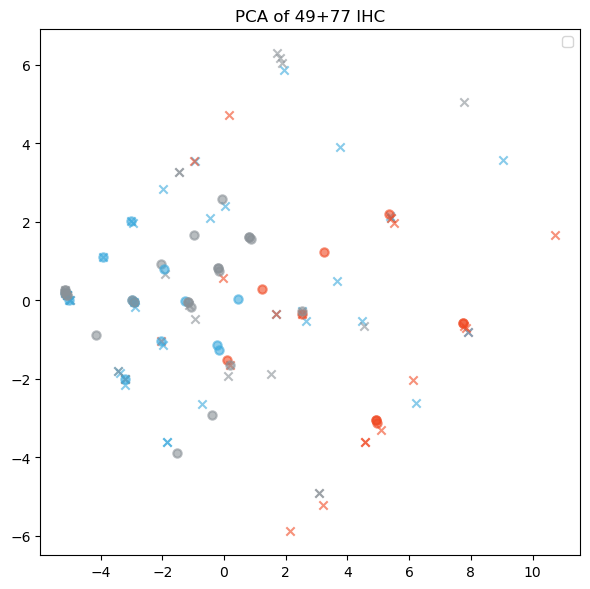

In [305]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))  # Assuming 30 figures, you can adjust the layout as needed

lw = 1.5
m_cluster = {"C1":'#F04923',"C2":'#3BA9DD',"Others":'#8A9197'}
m_organ_c = m_cluster #{'C1':'red','C2':'blue','Others':'black'}
m_set = {'Train':'x','Valid':'o'}

for _,row in labels.iterrows():
    x, y ,c,s,o = row[['x','y','Cluster','Set','sel_organ']]
    fc = 'none' if s == 'Valid' else m_cluster[c]
#     if s == 'Train':
    ax.scatter(
        x, y, color=m_cluster[c], marker=m_set[s],
        alpha=0.6, lw=lw
    )
#     if not pd.isna(o):
#         ax.text(x,y, s= o, alpha=1,fontsize=12,color= m_organ_c[c])

ax.legend(loc="best", shadow=False, scatterpoints=1)
ax.set_title("PCA of 49+77 IHC")

plt.tight_layout()
plt.show()


In [306]:
matt

,VIM_sit,VIM_per,VIM_H,MRE11_sit,MRE11_per,MRE11_H,CANT1_sit,CANT1_per,CANT1_H,CD8
P01,2.0,2.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.05
P02,2.0,2.0,4.0,0.0,0.0,0.0,1.0,2.0,2.0,0.10
P03,2.0,2.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.10
...,...,...,...,...,...,...,...,...,...,...
P84,2.0,2.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.05
P85,2.0,2.0,4.0,1.0,2.0,2.0,0.0,0.0,0.0,0.10
P86,3.0,2.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00


In [307]:
matv

,VIM_sit,VIM_per,VIM_H,MRE11_sit,MRE11_per,MRE11_H,CANT1_sit,CANT1_per,CANT1_H,CD8
P087,1,2.0,2,1,2.0,2,2,2.0,4,0.0
P088,1,3.0,3,1,4.0,4,1,2.0,2,0.1
P089,1,3.0,3,1,4.0,4,1,4.0,4,0.0
...,...,...,...,...,...,...,...,...,...,...
P135,2,2.0,4,0,0.0,0,0,0.0,0,0.0
P137,2,2.0,4,1,1.0,1,1,1.0,1,0.1
P138,1,2.0,2,0,0.0,0,0,0.0,0,0.3


In [308]:
yt

P01    Others
P02        C2
P03    Others
        ...  
P84        C2
P85        C2
P86        C2
Name: Cluster, Length: 77, dtype: object

In [309]:
yv

P087        C1
P088    Others
P089        C1
         ...  
P135    Others
P137    Others
P138    Others
Name: Cluster, Length: 49, dtype: object

In [310]:
df_t = matt.copy()
df_t['Set'] = 'Train'
df_t['Cluster'] = yt
df_v = matv.copy()
df_v['Set'] = 'Valid'
df_v['Cluster'] = yv

df = pd.concat([df_t,df_v]).reset_index().rename(columns={'index':"Custom_Label"})
df

,Custom_Label,VIM_sit,VIM_per,VIM_H,MRE11_sit,MRE11_per,MRE11_H,CANT1_sit,CANT1_per,CANT1_H,CD8,Set,Cluster
0,P01,2.0,2.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.05,Train,Others
1,P02,2.0,2.0,4.0,0.0,0.0,0.0,1.0,2.0,2.0,0.10,Train,C2
2,P03,2.0,2.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.10,Train,Others
...,...,...,...,...,...,...,...,...,...,...,...,...,...
123,P135,2.0,2.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,Valid,Others
124,P137,2.0,2.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,0.10,Valid,Others
125,P138,1.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.30,Valid,Others


In [312]:
db.exporting(df, 'IHC_score_predict_tb',outputdir='external_info/IHC/')


[08/24 02:12:26] overwritting 1 file with 126 lines at 
	[PROJECT_ROOT]/external_info/IHC/IHC_score_predict_tb.dfx


### Model

In [327]:
from sklearn.metrics import confusion_matrix
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

In [371]:
yt

P01    Others
P02        C2
P03    Others
        ...  
P84        C2
P85        C2
P86        C2
Name: Cluster, Length: 77, dtype: object

In [372]:
XX = matall
YY = pd.concat([yt,yv])

XX = matt
YY = yt

assert (YY.index==XX.index).all()
XX

,VIM_sit,VIM_per,VIM_H,MRE11_sit,MRE11_per,MRE11_H,CANT1_sit,CANT1_per,CANT1_H,CD8
P01,2.0,2.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.05
P02,2.0,2.0,4.0,0.0,0.0,0.0,1.0,2.0,2.0,0.10
P03,2.0,2.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.10
...,...,...,...,...,...,...,...,...,...,...
P84,2.0,2.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.05
P85,2.0,2.0,4.0,1.0,2.0,2.0,0.0,0.0,0.0,0.10
P86,3.0,2.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00


In [373]:
# YY.loc[YY != 'C1'] = 'Others'
YY

P01    Others
P02        C2
P03    Others
        ...  
P84        C2
P85        C2
P86        C2
Name: Cluster, Length: 77, dtype: object

In [30]:
# xtt = XX.loc[data_pca[data_pca['Set']=='Train'].index]
# ytt = YY.loc[xtt.index]

In [31]:
# xvalid = XX.loc[data_pca[data_pca['Set']=='Valid'].index]
# yvalid = YY.loc[xvalid.index]

In [32]:
# XX = matt
# YY = yt
# assert (YY.index==XX.index).all()

In [316]:
cm.apply(lambda x: x[x.name] / x.sum(),0)[['C1']].mean()

1.0

In [375]:
chosen = {'score':0.5,'sc':0.5}

def stat(x,y,dtc, retppv = False):
    ypred = dtc.predict(x)
    cm = confusion_matrix(y,ypred)
    cm = pd.DataFrame(cm, index=dtc.classes_,columns=dtc.classes_)
    PPV = cm.apply(lambda x: x[x.name] / x.sum(),0)[['C1']].mean()
#     print(PPV)
    if retppv:
        return PPV, cm
    else:
        return cm

# xtt,xvalid,ytt,yvalid = train_test_split(XX, YY, test_size=0.3, stratify=YY.values)
xtt = matt
ytt = yt
xvalid = matv
yvalid = yv


i=0
while True:
    i += 1
#     dtc = SVC() 
    dtc = RandomForestClassifier()
#     dtc = DecisionTreeClassifier(max_depth=3,max_leaf_nodes=10)
    xtrain,xtest, ytrain,ytest = train_test_split(xtt, ytt, test_size=0.3, stratify=ytt.values)
    
    dtc.fit(xtrain,ytrain)

    sc = dtc.score(xtest,ytest)
    
    PPV, cm = stat(xtest,ytest,dtc,retppv=True)
    PPV2, cm2 = stat(xvalid,yvalid,dtc,retppv=True)
    
    if PPV2 > chosen['score']:
        chosen = {'model':dtc,'score':PPV2,'cm':cm,
                  'xtest':xtest,'ytest':ytest,
                  'xtrain':xtrain,'ytrain':ytrain,
                  'xvalid':xvalid,'yvalid':yvalid
                 }
        print(PPV, PPV2)
    if (PPV - PPV2)**2 < 0.1**2 and  PPV2 > 0.80 and cm['C1']['C1'] > 3:
        break
    
    if i % 50==0:
        offset = (i//50)
        print(i, "|"+'=' * offset +'>' + " "*(40-offset) + '|')
    if i > 500:
        break
    
    
#     if PPV > 0.85:
#         break
        
#      if (p2.loc[["1538224","1554631",'1563492']].values=='C1').any() and p['C1'] >= 2:
#         break

#     _ = colData.loc[organ_uid,:]
#     _ = _['Cluster'].to_dict()
#     cnt = 0
#     for i,j in _.items():
#         if j in best_pred[i]:
#             cnt +=1
#     if cnt > 5:
#         break
print('Job Done!')


0.625 0.6153846153846154
1.0 1.0
Job Done!


In [376]:
dtc = chosen['model']
cm = chosen['cm']
xtest = chosen['xtest']
ytest = chosen['ytest']
dtc.score(matt,yt)

0.8571428571428571

In [377]:

# ypred = dtc.predict(xtest)
# cm = confusion_matrix(ytest,ypred)
# cm = pd.DataFrame(cm, index=dtc.classes_,columns=dtc.classes_)
# cm.index.name = 'GroundTruth'
# PPV = cm.apply(lambda x: x[x.name] / x.sum(),0)[['C1','C2']].mean()
# print(PPV)
# cm
stat(xtest,ytest,dtc)

,C1,C2,Others
C1,1,2,3
C2,0,10,1
Others,0,4,3


In [378]:
# ypred = dtc.predict(matv)
# cm = confusion_matrix(yv,ypred)
# cm = pd.DataFrame(cm, index=dtc.classes_,columns=dtc.classes_)
# cm.index.name = 'GroundTruth'
# PPV = cm.apply(lambda x: x[x.name] / x.sum(),0)[['C1','C2']].mean()
# print(PPV)
# cm
stat(xvalid,yvalid,dtc)

,C1,C2,Others
C1,6,0,4
C2,0,12,2
Others,0,11,14


In [3]:
import joblib
# joblib.dump(chosen,'export_model/IHC_chosen.joblib')
chosen = joblib.load('export_model/IHC_chosen.joblib')
dtc = chosen['model']

In [386]:
chosen.keys()

dict_keys(['model', 'score', 'cm', 'xtest', 'ytest', 'xtrain', 'ytrain', 'xvalid', 'yvalid'])

In [103]:
chosen['xtest']

,VIM_sit,VIM_per,VIM_H,MRE11_sit,MRE11_per,MRE11_H,CANT1_sit,CANT1_per,CANT1_H,CD8
P50,2.0,2.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,0.10
P47,1.0,2.0,2.0,1.0,4.0,4.0,1.0,4.0,4.0,0.10
P10,2.0,2.0,4.0,1.0,1.0,1.0,1.0,2.0,2.0,0.00
...,...,...,...,...,...,...,...,...,...,...
P68,3.0,3.0,9.0,1.0,2.0,2.0,1.0,2.0,2.0,0.01
P69,3.0,2.0,6.0,1.0,1.0,1.0,1.0,2.0,2.0,0.20
P23,3.0,3.0,9.0,2.0,4.0,8.0,0.0,0.0,0.0,0.05


In [104]:
chosen['ytest']

P50        C2
P47        C2
P10        C1
        ...  
P68    Others
P69        C2
P23        C2
Name: Cluster, Length: 24, dtype: object

### ROC model metrics

In [69]:
# x = chosen['xtest']
# y_true = chosen['ytest']

# class_to_avoid = 'Others'
# digits = 1

# n_bootstraps = 500
# random_seed=42
# represent = False

# plot_micro_average_curve = True

# fig_title = 'Receiver Operating Characteristic for Multi-Class'

# fig_colors = cycle(['#F04923',
# '#3BA9DD',
# '#8A9197'])

,Ground Truth Class,C1,C2,Others,AUC,Sen(%),Spe(%),NPV(%),PPV(%),Accuracy(%),Total Accuracy(%),Bx Class,Bx Avoided(%)
0,C1,1,2,3,80.6,16.7,100.0,78.3,100.0,79.2,58.3,√,100.0
1,C2,0,10,1,69.2,90.9,53.8,87.5,62.5,70.8,58.3,,NaN
2,Others,0,4,3,48.7,42.9,76.5,76.5,42.9,66.7,58.3,,NaN


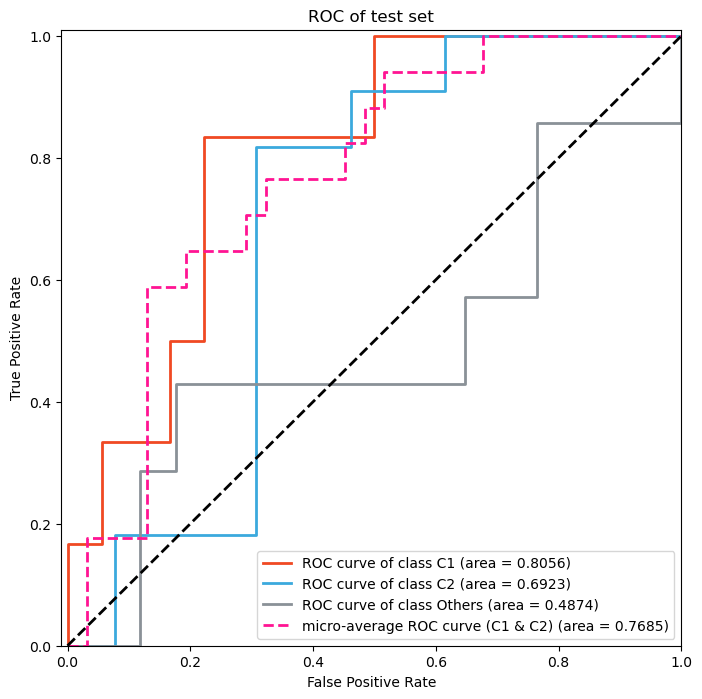

In [78]:
X = chosen['xtest']
y = chosen['ytest']

metri_t, fig_t = plot_calc_metrics(dtc, X, y,class_to_avoid='C1', represent=True, fig_title='ROC of test set')
metri_t


,Ground Truth Class,C1,C2,Others,AUC,Sen(%),Spe(%),NPV(%),PPV(%),Accuracy(%),Total Accuracy(%),Bx Class,Bx Avoided(%)
0,C1,6,0,4,91.3,60.0,100.0,90.7,100.0,91.8,65.3,√,100.0
1,C2,0,12,2,86.4,85.7,68.6,92.3,52.2,73.5,65.3,,NaN
2,Others,0,11,14,72.2,56.0,75.0,62.1,70.0,65.3,65.3,,NaN


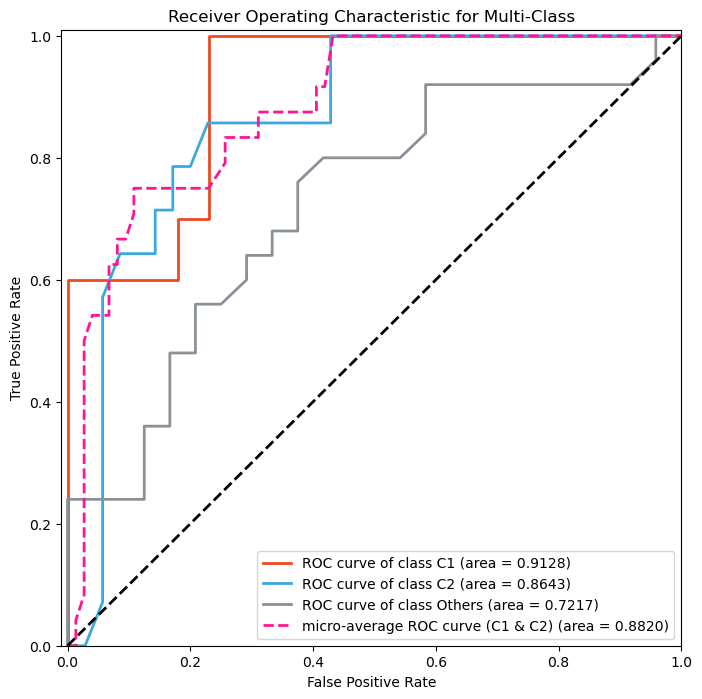

In [79]:
X = chosen['xvalid']
y = chosen['yvalid']

metri_v, fig_v = plot_calc_metrics(dtc, X, y,class_to_avoid='C1',represent=True)
metri_v


,Ground Truth Class,C1,C2,Others,AUC,Sen(%),Spe(%),NPV(%),PPV(%),Accuracy(%),Total Accuracy(%),Bx Class,Bx Avoided(%)
0,C1,20,2,7,94.6,69.0,100.0,91.5,100.0,92.9,77.8,√,100.0
1,C2,0,45,3,90.8,93.8,76.9,95.2,71.4,83.3,77.8,,NaN
2,Others,0,16,33,83.7,67.3,87.0,80.7,76.7,79.4,77.8,,NaN


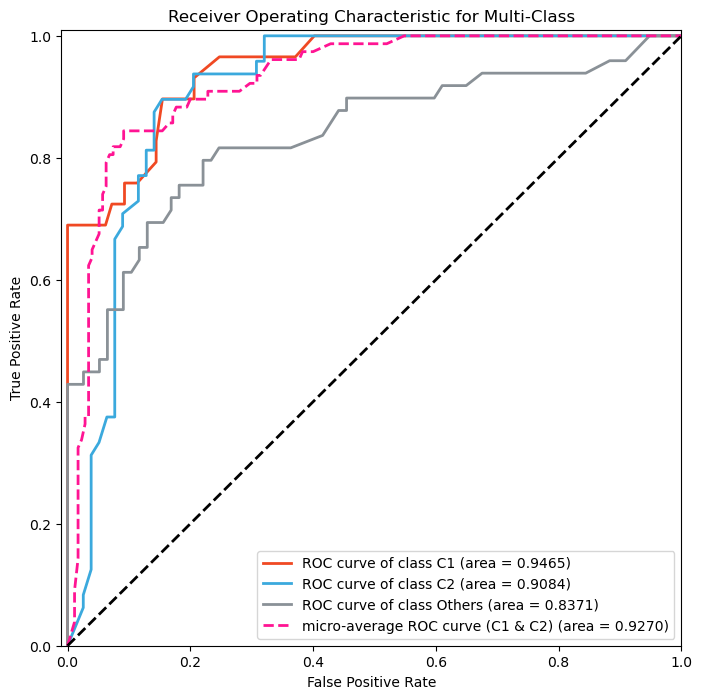

In [97]:
X = matall
y = yall

metri_all, fig_all = plot_calc_metrics(dtc, X, y,class_to_avoid='C1',represent=True, )
metri_all

In [98]:
write_excel({
        f"test_set_{len(chosen['xtest'])}":metri_t,
        f"valid_set_{len(chosen['xvalid'])}":metri_v,
        f"all_cohort_{len(matall)}":metri_all
    }
    ,'fig.S10_IHC_Model_Metrics.xlsx'
    ,outputdir='report_reply/'
)



  append #1 Sheet [test_set_24]
  append #2 Sheet [valid_set_49]
  append #3 Sheet [all_cohort_126]
writing 1 .xls @ report_reply/fig.S8_IHC_Model_Metrics.xlsx


In [99]:
matall.shape

(126, 10)

In [102]:
db.exporting(fig_t, 'fig.S10_IHC_ROC_test_set.pdf',outputdir='report_reply/')
db.exporting(fig_v, 'fig.S10_IHC_ROC_valid_set.pdf',outputdir='report_reply/')
db.exporting(fig_all, 'fig.S10_IHC_ROC_all_126.pdf',outputdir='report_reply/')

[08/24 04:49:12] writing 1 file with plt at 
	[PROJECT_ROOT]/report_reply/fig.S8_IHC_ROC_test_set.pdf
[08/24 04:49:13] writing 1 file with plt at 
	[PROJECT_ROOT]/report_reply/fig.S8_IHC_ROC_valid_set.pdf
[08/24 04:49:13] writing 1 file with plt at 
	[PROJECT_ROOT]/report_reply/fig.S8_IHC_ROC_all_126.pdf


## Valid using EXTERNAL data

### Cancer cell

In [173]:
cc = db.importing('external_info/article_data_others_works/PC_CancerCell_Canada/PRAD_CA_protein_mat.dfx', index_col=0)
cc[cc==0] = np.nan
cc.index.name = 'symbol'
cc

[08/25 02:30:43]reading external_info/article_data_others_works/PC_CancerCell_Canada/PRAD_CA_protein_mat.dfx


,CPCG0100,CPCG0102,CPCG0103,CPCG0182,CPCG0183,CPCG0184,CPCG0185,CPCG0190,CPCG0191,CPCG0191-2,...,CPCG0465,CPCG0473,CPCG0540,CPCG0545,CPCG0547,CPCG0550,CPCG0551,CPCG0557,CPCG0584,CPCG0615
symbol,,,,,,,,,,,,,,,,,,,,,
A1BG,4.045250e+08,194420000.0,159870000.0,105624500.0,77825000.0,33844000.0,1.980900e+08,259895000.0,279600000.0,5.324700e+08,...,188160000.0,2.268750e+08,12372000.0,125096500.0,80508500.0,46591500.0,145075000.0,2.826400e+08,83166000.0,121990000.0
A1CF,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A2M,1.721750e+09,784765000.0,648205000.0,431765000.0,941540000.0,200930000.0,1.439800e+09,861530000.0,736910000.0,1.316500e+09,...,853650000.0,1.088300e+09,68388500.0,802675000.0,436535000.0,942485000.0,416735000.0,1.456300e+09,442285000.0,465315000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZYG11B,NaN,NaN,NaN,NaN,NaN,1313950.0,NaN,5134500.0,NaN,NaN,...,NaN,NaN,NaN,NaN,8149500.0,5088500.0,NaN,NaN,NaN,NaN
ZYX,3.318900e+08,293335000.0,207205000.0,193020000.0,108093000.0,29285500.0,2.737100e+08,36078000.0,251220000.0,5.015600e+08,...,341900000.0,1.716400e+08,23419000.0,212540000.0,62034000.0,131243000.0,131394000.0,3.136700e+08,102695000.0,121535000.0
ZZEF1,NaN,NaN,NaN,NaN,NaN,16386000.0,NaN,2822650.0,NaN,NaN,...,NaN,NaN,NaN,NaN,8086500.0,NaN,25542500.0,1.238350e+08,NaN,NaN


In [174]:
from sklearn.preprocessing import StandardScaler

In [175]:
x = StandardScaler().fit_transform(cc.T).T
cc = pd.DataFrame(x, index=cc.index, columns=cc.columns)
cc

[python_env]/lib/pythonX/site-packages/sklearn/utils/extmath.py:1051: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
[python_env]/lib/pythonX/site-packages/sklearn/utils/extmath.py:1056: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
[python_env]/lib/pythonX/site-packages/sklearn/utils/extmath.py:1076: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


,CPCG0100,CPCG0102,CPCG0103,CPCG0182,CPCG0183,CPCG0184,CPCG0185,CPCG0190,CPCG0191,CPCG0191-2,...,CPCG0465,CPCG0473,CPCG0540,CPCG0545,CPCG0547,CPCG0550,CPCG0551,CPCG0557,CPCG0584,CPCG0615
symbol,,,,,,,,,,,,,,,,,,,,,
A1BG,0.319827,-0.170380,-0.250990,-0.377553,-0.442413,-0.545028,-0.161817,-0.017617,0.028358,0.618342,...,-0.184985,-0.094657,-0.595125,-0.332122,-0.436152,-0.515286,-0.285509,0.035451,-0.429952,-0.339370
A1CF,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A2M,0.480409,-0.233306,-0.337326,-0.502192,-0.113888,-0.678022,0.265644,-0.174833,-0.269758,0.171724,...,-0.180835,-0.002099,-0.778981,-0.219664,-0.498558,-0.113168,-0.513640,0.278212,-0.494178,-0.476636
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZYG11B,NaN,NaN,NaN,NaN,NaN,-0.769119,NaN,-0.415423,NaN,NaN,...,NaN,NaN,NaN,NaN,-0.136304,-0.419682,NaN,NaN,NaN,NaN
ZYX,0.520487,0.364991,0.017620,-0.039590,-0.382110,-0.699949,0.285841,-0.672554,0.195137,1.204785,...,0.560859,-0.125818,-0.723609,0.039136,-0.567870,-0.288743,-0.288134,0.447004,-0.403880,-0.327897
ZZEF1,NaN,NaN,NaN,NaN,NaN,-0.777507,NaN,-0.912017,NaN,NaN,...,NaN,NaN,NaN,NaN,-0.859814,NaN,-0.686701,0.288076,NaN,NaN


In [176]:
# 筛选出NA数小于50%的基因
x = cc.isna()
x = x.apply(np.sum,1)
mask = x<79*0.5
cc2 = cc.loc[mask]
cc2

,CPCG0100,CPCG0102,CPCG0103,CPCG0182,CPCG0183,CPCG0184,CPCG0185,CPCG0190,CPCG0191,CPCG0191-2,...,CPCG0465,CPCG0473,CPCG0540,CPCG0545,CPCG0547,CPCG0550,CPCG0551,CPCG0557,CPCG0584,CPCG0615
symbol,,,,,,,,,,,,,,,,,,,,,
A1BG,0.319827,-0.170380,-0.250990,-0.377553,-0.442413,-0.545028,-0.161817,-0.017617,0.028358,0.618342,...,-0.184985,-0.094657,-0.595125,-0.332122,-0.436152,-0.515286,-0.285509,0.035451,-0.429952,-0.339370
A2M,0.480409,-0.233306,-0.337326,-0.502192,-0.113888,-0.678022,0.265644,-0.174833,-0.269758,0.171724,...,-0.180835,-0.002099,-0.778981,-0.219664,-0.498558,-0.113168,-0.513640,0.278212,-0.494178,-0.476636
AAAS,NaN,-0.606856,NaN,-0.523186,-0.573592,0.968106,NaN,NaN,NaN,-0.632293,...,NaN,-0.607742,-0.711586,-0.353306,-0.540083,-0.370417,-0.390032,0.662478,NaN,-0.632967
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZW10,-0.058368,-0.419521,NaN,-0.340785,-0.422515,-0.380919,NaN,-0.388991,-0.404957,-0.052690,...,NaN,NaN,-0.536492,-0.433733,-0.375948,-0.395162,-0.435257,NaN,-0.458502,-0.502237
ZYX,0.520487,0.364991,0.017620,-0.039590,-0.382110,-0.699949,0.285841,-0.672554,0.195137,1.204785,...,0.560859,-0.125818,-0.723609,0.039136,-0.567870,-0.288743,-0.288134,0.447004,-0.403880,-0.327897
ZZEF1,NaN,NaN,NaN,NaN,NaN,-0.777507,NaN,-0.912017,NaN,NaN,...,NaN,NaN,NaN,NaN,-0.859814,NaN,-0.686701,0.288076,NaN,NaN


In [177]:
db.exporting(cc2, 'prt_mat_na_lt_50per',outputdir='external_info/article_data_others_works/PC_CancerCell_Canada/')

[08/25 02:30:48] overwritting 1 file with 4363 lines at 
	[PROJECT_ROOT]/external_info/article_data_others_works/PC_CancerCell_Canada/prt_mat_na_lt_5per.dfx


In [ ]:
%%R
## [INTERNAL_URL_REMOVED]

# library(SeqKnn)
library(magrittr)

mat_na = read.table( 'external_info/article_data_others_works/PC_CancerCell_Canada/prt_mat_na_lt_5per.dfx'
                 , header=TRUE
                 , row.names=1
                 , sep='\t') %>% as.matrix

mat = SeqKnn::SeqKNN(mat_na, k = 12)

mat %>% write.table(file = 'external_info/article_data_others_works/PC_CancerCell_Canada/prt_mat_seqknn_lt5per.dfx',sep='\t')



In [189]:

mat = db.importing('external_info/article_data_others_works/PC_CancerCell_Canada/prt_mat_seqknn_lt5per.dfx',index_col=0)
mat

[08/25 02:53:09]reading external_info/article_data_others_works/PC_CancerCell_Canada/prt_mat_seqknn_lt5per.dfx


,CPCG0100,CPCG0102,CPCG0103,CPCG0182,CPCG0183,CPCG0184,CPCG0185,CPCG0190,CPCG0191,CPCG0191.2,...,CPCG0465,CPCG0473,CPCG0540,CPCG0545,CPCG0547,CPCG0550,CPCG0551,CPCG0557,CPCG0584,CPCG0615
A1BG,0.319827,-0.170380,-0.250990,-0.377553,-0.442413,-0.545028,-0.161817,-0.017617,0.028358,0.618342,...,-0.184985,-0.094657,-0.595125,-0.332122,-0.436152,-0.515286,-0.285509,0.035451,-0.429952,-0.339370
A2M,0.480409,-0.233306,-0.337326,-0.502192,-0.113888,-0.678022,0.265644,-0.174833,-0.269758,0.171724,...,-0.180835,-0.002099,-0.778981,-0.219664,-0.498558,-0.113168,-0.513640,0.278212,-0.494178,-0.476636
AAAS,-0.309909,-0.606856,-0.565248,-0.523186,-0.573592,0.968106,-0.354212,-0.245034,-0.335696,-0.632293,...,-0.418787,-0.607742,-0.711586,-0.353306,-0.540083,-0.370417,-0.390032,0.662478,-0.490873,-0.632967
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZW10,-0.058368,-0.419521,-0.524038,-0.340785,-0.422515,-0.380919,-0.302005,-0.388991,-0.404957,-0.052690,...,-0.273405,-0.415861,-0.536492,-0.433733,-0.375948,-0.395162,-0.435257,-0.555107,-0.458502,-0.502237
ZYX,0.520487,0.364991,0.017620,-0.039590,-0.382110,-0.699949,0.285841,-0.672554,0.195137,1.204785,...,0.560859,-0.125818,-0.723609,0.039136,-0.567870,-0.288743,-0.288134,0.447004,-0.403880,-0.327897
ZZEF1,-0.088369,-0.382669,-0.556871,-0.325368,-0.397902,-0.777507,-0.156570,-0.912017,0.106799,1.096241,...,-0.262810,-0.318498,-0.669906,-0.446227,-0.859814,-0.406207,-0.686701,0.288076,-0.539304,-0.501982


In [190]:
mat.values.max()

8.75113364143746

In [191]:
import matplotlib.pyplot as plt
import seaborn as sns

In [192]:
cmap=sns.diverging_palette(255,10,n=100)

<Axes: >

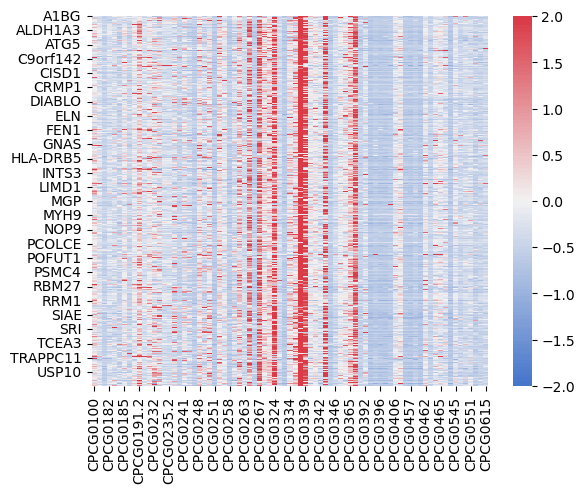

In [193]:
sns.heatmap(mat,center=0,vmin=-2,vmax=2,cmap=cmap)

### Cell Reports Medicine

In [106]:
# cr = db.importing('external_info/article_data_others_works/PC_CellReportsMedicine/mmc3.xlsx')

[08/25 01:19:45]reading external_info/article_data_others_works/PC_CellReportsMedicine/mmc3.xlsx
  Sheets list: ['Protein_matrix']
  Read the 1 / 1 sheet named <Protein_matrix>


In [109]:
# db.exporting(cr, 'prt_data_920c_1c_id_2c_name_oc_data_na',outputdir='external_info/article_data_others_works/PC_CellReportsMedicine/')

[08/25 01:23:28] writing 1 file with 10071 lines at 
	[PROJECT_ROOT]/external_info/article_data_others_works/PC_CellReportsMedicine/prt_data_920c_1c_id_2c_name_oc_data_na.dfx


In [267]:
cr = db.importing('external_info/article_data_others_works/PC_CellReportsMedicine/prt_data_920c_1c_id_2c_name_oc_data_na.dfx')
ind = cr.iloc[:,:2]
cr = cr.loc[:,'PCSHA_1_1':]
ind.loc[ind['GeneName'].isna(),"GeneName"] = ""
cr.index = ind.apply('_'.join,1)
cr

[08/25 03:35:31]reading external_info/article_data_others_works/PC_CellReportsMedicine/prt_data_920c_1c_id_2c_name_oc_data_na.dfx


,PCSHA_1_1,PCSHA_1_2,PCSHA_1_3,PCSHA_3_1,PCSHA_3_2,PCSHA_3_3,PCSHA_5_1,PCSHA_5_2,PCSHA_5_3,PCSHA_6_1,PCSHA_6_2,PCSHA_6_3,PCSHA_7_1,PCSHA_7_2,PCSHA_7_3,PCSHA_8_1,PCSHA_8_2,PCSHA_8_3,PCSHA_9_1,PCSHA_9_2,PCSHA_9_3,PCSHA_10_1,PCSHA_10_2,PCSHA_10_3,PCSHA_11_1,PCSHA_11_2,PCSHA_11_3,PCSHA_13_1,PCSHA_13_2,PCSHA_13_3,...,PCSHA_311_1,PCSHA_311_2,PCSHA_311_3,PCSHA_312_1,PCSHA_312_2,PCSHA_312_3,PCSHA_313_1,PCSHA_313_2,PCSHA_313_3,PCSHA_314_1,PCSHA_314_2,PCSHA_314_3,PCSHA_315_1,PCSHA_315_2,PCSHA_315_3,PCSHA_321_1,PCSHA_321_2,PCSHA_321_3,PCSHA_322_1,PCSHA_322_2,PCSHA_322_3,PCSHA_323_1,PCSHA_323_2,PCSHA_323_3,PCSHA_324_1,PCSHA_324_2,PCSHA_324_3,PCSHA_325_1,PCSHA_325_2,PCSHA_325_3
A0A024RBG1_NUDT4B,5371.05,NaN,NaN,NaN,NaN,NaN,2074.02,5872.06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3090.03,7440.07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4140.04,NaN,3898.04,NaN,5643.06
A0A075B6H7_IGKV3-7,59799.40,207391.00,30623.2,562342.000,10359.1,975604.0,147367.00,283808.00,148015.0,251092.0,150852.0,384594.0,NaN,17018.20,341424.00,NaN,195319.00,176729.0,354947.00,NaN,NaN,173745.00,493250.00,188050.00,139354.00,460938.00,71799.50,22421.10,17428.100,470213.00,...,593208.0,404041.00,656535.00,684142.00,16834.10,62677.40,NaN,145197.0,18876.1,6060.07,81451.50,115177.0,466187.00,1845070.00,1275310.00,264594.00,433602.00,372395.00,242652.00,146016.00,944587.0,268832.0,296252.0,413418.0,96508.60,261046.00,215288.00,200623.00,282593.0,267177.00
A0A075B6H9_IGLV4-69,NaN,22164.10,NaN,56475.300,NaN,27240.1,9409.05,33529.20,15638.1,22769.1,11385.1,245603.0,NaN,8662.05,21893.10,NaN,26273.10,29876.2,26446.20,NaN,NaN,NaN,21096.10,10290.10,21793.10,22308.10,5013.03,NaN,126072.000,3972.02,...,19180.1,NaN,14398.10,82154.50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23766.10,95106.50,33164.20,8583.04,16530.10,19451.10,18261.10,NaN,16669.1,20687.1,19350.1,25363.1,NaN,9983.06,6994.04,NaN,NaN,6253.04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Q9Y6X9_MORC2,3530.04,1496.02,NaN,744.009,NaN,NaN,3752.03,3916.03,NaN,NaN,NaN,NaN,9901.12,NaN,NaN,NaN,NaN,NaN,2636.03,8102.09,2597.03,3730.03,1454.01,NaN,NaN,NaN,NaN,2324.02,955.009,NaN,...,NaN,2825.02,4669.03,846.01,3823.03,NaN,2986.03,NaN,NaN,2482.03,NaN,NaN,NaN,3297.02,1145.01,1780.02,2192.02,2190.02,6969.05,1937.02,NaN,NaN,NaN,NaN,1870.01,2171.02,1786.01,1182.01,NaN,2557.02
Q9Y6Y0_IVNS1ABP,2650.03,2370.03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3515.02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,2021.03,2595.03,NaN,NaN,NaN,4126.03,NaN,NaN,NaN,1422.02,NaN,2938.04,NaN,NaN,NaN,3500.05,NaN,5359.06,9479.11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3268.04,NaN,NaN
Q9Y6Y8_SEC23IP,74148.60,62670.50,50760.4,89570.700,24434.2,24294.2,27876.20,53944.50,11535.1,31112.2,16304.1,13774.1,169511.00,97142.80,9381.06,129027.0,6269.04,NaN,34844.30,82506.70,33707.30,77987.60,22553.20,5060.04,7789.06,6364.05,8754.07,3652.03,20148.200,12055.10,...,24500.2,65056.60,34977.30,59644.50,84506.70,3717.02,80804.60,51378.4,31874.3,53453.40,70430.60,75337.7,49899.40,27600.30,27127.20,65178.60,72254.70,62864.60,55441.50,108064.00,14507.1,43588.3,42681.4,51265.4,49490.50,47477.40,40949.40,54016.50,13396.1,88801.70


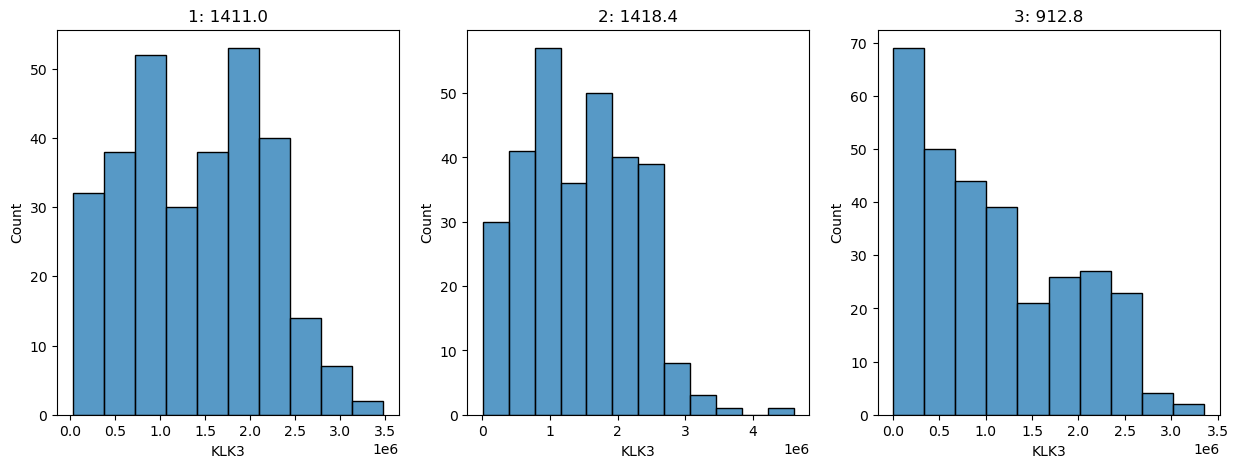

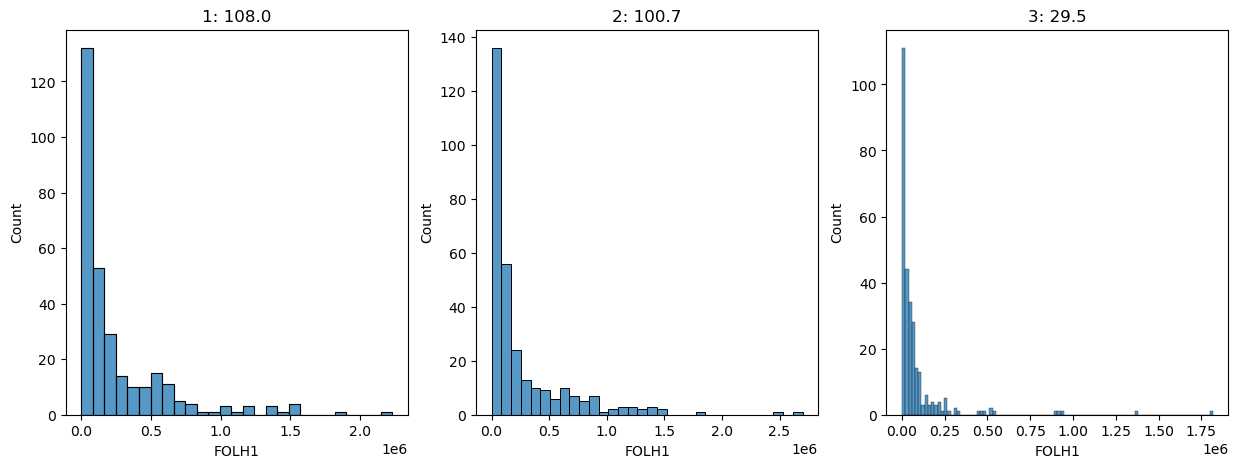

In [223]:
for gene in ['KLK3','FOLH1']:
    x = cr.loc[gene,:]
    fig, axes = plt.subplots(1,3,figsize=(15,5))
    for i,ax in zip('123',axes):
        v = x[x.index.str.endswith(i)]
        ax = sns.histplot(v, ax=ax)
        ax.set_title(i+': ' + str(round(v.median()/1000,1)))


In [270]:
cn = cr.columns.str[-1]
cr1 = cr.loc[:,cn=='1']
cr2 = cr.loc[:,cn=='2']

cr1.columns = cr1.columns.str[:-2]
cr2.columns = cr2.columns.str[:-2]


In [271]:
assert (cr1.columns == cr2.columns).all()

In [272]:
cr_m = np.nansum([cr1.values,cr2.values],axis=0) / 2
crm = pd.DataFrame(cr_m, index=cr1.index ,columns = cr1.columns)
crm[crm==0] = np.nan
crm.index.name = "symbol"
crm

,PCSHA_1,PCSHA_3,PCSHA_5,PCSHA_6,PCSHA_7,PCSHA_8,PCSHA_9,PCSHA_10,PCSHA_11,PCSHA_13,PCSHA_14,PCSHA_15,PCSHA_16,PCSHA_17,PCSHA_18,PCSHA_19,PCSHA_20,PCSHA_21,PCSHA_22,PCSHA_23,PCSHA_25,PCSHA_26,PCSHA_27,PCSHA_28,PCSHA_30,PCSHA_31,PCSHA_32,PCSHA_33,PCSHA_34,PCSHA_35,...,PCSHA_229,PCSHA_230,PCSHA_241,PCSHA_242,PCSHA_243,PCSHA_244,PCSHA_245,PCSHA_257,PCSHA_258,PCSHA_259,PCSHA_260,PCSHA_261,PCSHA_262,PCSHA_263,PCSHA_264,PCSHA_265,PCSHA_301,PCSHA_303,PCSHA_304,PCSHA_305,PCSHA_311,PCSHA_312,PCSHA_313,PCSHA_314,PCSHA_315,PCSHA_321,PCSHA_322,PCSHA_323,PCSHA_324,PCSHA_325
symbol,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
A0A024RBG1_NUDT4B,2685.525,NaN,3973.040,NaN,NaN,NaN,5265.05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3572.530,1531.015,NaN,NaN,1884.0200,2149.52,NaN,914.01,NaN,4723.045,1338.5100,...,NaN,NaN,7521.075,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2145.520,4445.540,1115.51,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2070.020,1949.020
A0A075B6H7_IGKV3-7,133595.200,286350.5500,215587.500,200972.00,8509.100,97659.50,177473.50,333497.50,300146.000,19924.6000,152540.75,208885.50,203998.50,342846.000,538863.75,678905.00,450709.500,319961.150,24569.150,71554.500,33459.715,598045.035,268861.1000,587742.0000,9816.05,106783.700,221376.00,NaN,125682.700,92604.0000,...,323754.50,219204.500,3232.520,601530.00,192422.700,150296.00,720413.500,574647.500,170261.50,150451.500,250770.000,348111.500,1071962.50,214971.00,533398.500,456194.500,163296.25,274013.500,372441.500,138871.80,498624.500,350488.05,72598.500,43755.785,1155628.50,349098.000,194334.000,282542.00,178777.300,241608.000
A0A075B6H9_IGLV4-69,11082.050,28237.6500,21469.125,17077.10,4331.025,13136.55,13223.10,10548.05,22050.600,63036.0000,1938.01,11067.10,38431.70,26372.150,17539.57,44497.75,22332.100,40833.750,10487.550,17370.620,67084.550,12308.050,16963.0700,17912.6000,6727.05,NaN,3876.52,NaN,5434.550,5479.0500,...,1726.51,9184.050,NaN,69037.50,28036.665,1821.51,53334.300,3023.015,5973.55,12483.050,18714.120,10687.550,33523.20,7682.05,14161.100,17644.070,9489.55,2777.515,20662.100,3731.02,9590.050,41077.25,NaN,NaN,59436.30,12556.570,9130.550,20018.60,4991.530,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Q9Y6X9_MORC2,2513.030,372.0045,3834.030,NaN,4950.560,NaN,5369.06,2592.02,NaN,1639.5145,1125.51,5205.05,NaN,1485.510,NaN,NaN,232.002,1983.515,7698.055,522.505,1122.010,1241.015,322.5035,311.5035,3120.02,4255.530,7930.56,885.505,2252.025,1591.5150,...,NaN,NaN,10292.575,NaN,4098.030,4211.53,776.010,NaN,NaN,1476.515,1292.015,2164.515,3057.52,NaN,1693.515,1427.515,NaN,1916.020,1030.510,788.51,1412.510,2334.52,1493.015,1241.015,1648.51,1986.020,4453.035,NaN,2020.515,591.005
Q9Y6Y0_IVNS1ABP,2510.030,NaN,NaN,NaN,1757.510,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2746.52,NaN,NaN,1160.505,NaN,450.0055,...,NaN,NaN,NaN,7354.10,NaN,NaN,1255.515,NaN,NaN,NaN,1029.015,707.510,NaN,NaN,NaN,1085.015,NaN,NaN,1042.015,NaN,1010.515,NaN,2063.015,711.010,1469.02,1750.025,7419.085,NaN,NaN,1634.020
Q9Y6Y8_SEC23IP,68409.550,57002.4500,40910.350,23708.15,133326.900,67648.02,58675.50,50270.40,7076.555,11900.1150,24174.20,24486.70,18764.15,18384.135,24309.70,20676.15,19059.600,10912.600,51441.850,38044.300,31056.250,33680.250,44276.3500,31886.2800,39612.00,11533.075,24995.70,182741.000,29911.250,32974.7500,...,11682.58,40924.335,85485.200,16904.65,45661.900,23284.70,32432.250,59845.050,72022.15,19074.650,25878.750,37076.350,37836.30,26102.20,51335.400,36636.300,26163.75,45237.350,40907.400,15682.15,44778.400,72075.60,66091.500,61942.000,38749.85,68716.650,81752.750,43134.85,48483.950,33706.300


In [273]:
x = crm.isna()
x = x.apply(np.sum,1)
mask = x< crm.shape[1]*0.5
crm2 = crm.loc[mask]
crm2

,PCSHA_1,PCSHA_3,PCSHA_5,PCSHA_6,PCSHA_7,PCSHA_8,PCSHA_9,PCSHA_10,PCSHA_11,PCSHA_13,PCSHA_14,PCSHA_15,PCSHA_16,PCSHA_17,PCSHA_18,PCSHA_19,PCSHA_20,PCSHA_21,PCSHA_22,PCSHA_23,PCSHA_25,PCSHA_26,PCSHA_27,PCSHA_28,PCSHA_30,PCSHA_31,PCSHA_32,PCSHA_33,PCSHA_34,PCSHA_35,...,PCSHA_229,PCSHA_230,PCSHA_241,PCSHA_242,PCSHA_243,PCSHA_244,PCSHA_245,PCSHA_257,PCSHA_258,PCSHA_259,PCSHA_260,PCSHA_261,PCSHA_262,PCSHA_263,PCSHA_264,PCSHA_265,PCSHA_301,PCSHA_303,PCSHA_304,PCSHA_305,PCSHA_311,PCSHA_312,PCSHA_313,PCSHA_314,PCSHA_315,PCSHA_321,PCSHA_322,PCSHA_323,PCSHA_324,PCSHA_325
symbol,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
A0A075B6H7_IGKV3-7,133595.20,286350.5500,215587.500,200972.000,8509.100,97659.500,177473.50,333497.50,300146.000,19924.6000,152540.7500,208885.500,203998.50,342846.000,538863.750,678905.000,450709.500,319961.150,24569.150,71554.500,33459.715,598045.035,268861.1000,587742.0000,9816.050,106783.700,221376.000,NaN,125682.700,92604.000,...,323754.500,219204.500,3232.520,601530.000,192422.700,150296.00,720413.500,574647.500,170261.500,150451.500,250770.000,348111.500,1071962.500,214971.000,533398.500,456194.500,163296.250,274013.500,372441.500,138871.80,498624.500,350488.050,72598.500,43755.785,1155628.50,349098.000,194334.000,282542.000,178777.300,241608.000
A0A075B6H9_IGLV4-69,11082.05,28237.6500,21469.125,17077.100,4331.025,13136.550,13223.10,10548.05,22050.600,63036.0000,1938.0100,11067.100,38431.70,26372.150,17539.570,44497.750,22332.100,40833.750,10487.550,17370.620,67084.550,12308.050,16963.0700,17912.6000,6727.050,NaN,3876.520,NaN,5434.550,5479.050,...,1726.510,9184.050,NaN,69037.500,28036.665,1821.51,53334.300,3023.015,5973.550,12483.050,18714.120,10687.550,33523.200,7682.050,14161.100,17644.070,9489.550,2777.515,20662.100,3731.02,9590.050,41077.250,NaN,NaN,59436.30,12556.570,9130.550,20018.600,4991.530,NaN
A0A075B6I0_IGLV8-61,14705.10,11733.1000,2207.510,20640.150,NaN,6805.550,NaN,NaN,NaN,NaN,4541.0300,15476.100,19145.60,33319.200,37902.750,31312.650,12369.570,51938.500,NaN,12098.600,8474.050,28358.700,15970.6500,21490.1000,5992.050,NaN,NaN,NaN,2486.510,6643.050,...,7282.565,10334.600,NaN,41565.850,NaN,25139.70,31331.150,NaN,NaN,3723.525,24515.650,16578.625,50981.315,2360.515,23338.700,38784.750,20427.150,15252.075,23383.100,36998.78,50367.350,18850.600,NaN,6988.050,51167.30,28042.200,37267.800,23634.150,13345.110,18624.600
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Q9Y6X8_ZHX2,10628.10,6867.0600,10014.085,7125.065,7669.070,1239.015,3009.03,2124.02,3500.540,906.5050,1492.5135,2730.025,NaN,2497.030,2087.025,2365.525,2241.525,1562.015,4015.535,4090.540,2197.530,2264.015,3011.5300,220.5025,1686.515,3662.540,5064.045,3740.025,3051.525,2790.025,...,4016.540,6320.550,8701.590,7015.075,6920.075,4122.05,5004.545,3967.040,7531.585,8650.075,4440.050,5087.560,5983.065,5362.560,3652.545,10396.595,2156.025,4908.055,4862.545,2763.53,5936.065,5431.065,4328.555,5573.555,3543.53,5212.055,6253.565,4960.055,4959.545,1794.525
Q9Y6X9_MORC2,2513.03,372.0045,3834.030,NaN,4950.560,NaN,5369.06,2592.02,NaN,1639.5145,1125.5100,5205.050,NaN,1485.510,NaN,NaN,232.002,1983.515,7698.055,522.505,1122.010,1241.015,322.5035,311.5035,3120.020,4255.530,7930.560,885.505,2252.025,1591.515,...,NaN,NaN,10292.575,NaN,4098.030,4211.53,776.010,NaN,NaN,1476.515,1292.015,2164.515,3057.520,NaN,1693.515,1427.515,NaN,1916.020,1030.510,788.51,1412.510,2334.520,1493.015,1241.015,1648.51,1986.020,4453.035,NaN,2020.515,591.005
Q9Y6Y8_SEC23IP,68409.55,57002.4500,40910.350,23708.150,133326.900,67648.020,58675.50,50270.40,7076.555,11900.1150,24174.2000,24486.700,18764.15,18384.135,24309.700,20676.150,19059.600,10912.600,51441.850,38044.300,31056.250,33680.250,44276.3500,31886.2800,39612.000,11533.075,24995.700,182741.000,29911.250,32974.750,...,11682.58

In [274]:

db.exporting(crm, 'prt_mat_na_306', outputdir='external_info/article_data_others_works/PC_CellReportsMedicine/',index=True)


[08/25 03:36:15] overwritting 1 file with 10071 lines at 
	[PROJECT_ROOT]/external_info/article_data_others_works/PC_CellReportsMedicine/prt_mat_na_306.dfx


In [276]:
x = StandardScaler().fit_transform(crm2.T).T
crm2 = pd.DataFrame(x, index=crm2.index, columns=crm2.columns)
crm2

,PCSHA_1,PCSHA_3,PCSHA_5,PCSHA_6,PCSHA_7,PCSHA_8,PCSHA_9,PCSHA_10,PCSHA_11,PCSHA_13,PCSHA_14,PCSHA_15,PCSHA_16,PCSHA_17,PCSHA_18,PCSHA_19,PCSHA_20,PCSHA_21,PCSHA_22,PCSHA_23,PCSHA_25,PCSHA_26,PCSHA_27,PCSHA_28,PCSHA_30,PCSHA_31,PCSHA_32,PCSHA_33,PCSHA_34,PCSHA_35,...,PCSHA_229,PCSHA_230,PCSHA_241,PCSHA_242,PCSHA_243,PCSHA_244,PCSHA_245,PCSHA_257,PCSHA_258,PCSHA_259,PCSHA_260,PCSHA_261,PCSHA_262,PCSHA_263,PCSHA_264,PCSHA_265,PCSHA_301,PCSHA_303,PCSHA_304,PCSHA_305,PCSHA_311,PCSHA_312,PCSHA_313,PCSHA_314,PCSHA_315,PCSHA_321,PCSHA_322,PCSHA_323,PCSHA_324,PCSHA_325
symbol,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
A0A075B6H7_IGKV3-7,-0.461843,0.234557,-0.088046,-0.154677,-1.032102,-0.625671,-0.261805,0.449496,0.297449,-0.980059,-0.375472,-0.118600,-0.140880,0.492116,1.385746,2.024184,0.983857,0.387785,-0.958885,-0.744682,-0.918354,1.655549,0.154824,1.608578,-1.026143,-0.584075,-0.061657,NaN,-0.497916,-0.648719,...,0.405079,-0.071557,-1.056157,1.671437,-0.193653,-0.385706,2.213418,1.548881,-0.294684,-0.384997,0.072348,0.516121,3.816104,-0.090857,1.360830,1.008863,-0.326438,0.178313,0.627039,-0.437788,1.202298,0.526955,-0.739923,-0.871414,4.197531,0.520618,-0.184940,0.217194,-0.255861,0.030579
A0A075B6H9_IGLV4-69,-0.303509,0.835039,0.385839,0.094358,-0.751548,-0.167160,-0.161416,-0.338949,0.424429,3.144466,-0.910363,-0.304502,1.511577,0.711233,0.125050,1.914157,0.443111,1.670992,-0.342964,0.113838,3.413152,-0.222145,0.086790,0.149807,-0.592533,NaN,-0.781712,NaN,-0.678311,-0.675358,...,-0.924399,-0.429472,NaN,3.542761,0.821700,-0.918094,2.500603,-0.838355,-0.642540,-0.210531,0.203000,-0.329691,1.185820,-0.529154,-0.099165,0.131986,-0.409197,-0.854648,0.332280,-0.791368,-0.402527,1.687152,NaN,NaN,2.905568,-0.205651,-0.433023,0.289574,-0.707713,NaN
A0A075B6I0_IGLV8-61,-0.183837,-0.285259,-0.610328,0.018702,NaN,-0.453416,NaN,NaN,NaN,NaN,-0.530695,-0.157526,-0.032301,0.451385,0.607803,0.382910,-0.263539,1.086785,NaN,-0.272786,-0.396477,0.282104,-0.140649,0.047707,-0.481178,NaN,NaN,NaN,-0.600807,-0.458962,...,-0.437138,-0.332984,NaN,0.732809,NaN,0.172253,0.383541,NaN,NaN,-0.558593,0.150956,-0.119901,1.054120,-0.605107,0.110792,0.637902,0.011433,-0.165171,0.112307,0.576954,1.033168,-0.042368,NaN,-0.447188,1.060467,0.271303,0.586135,0.120875,-0.230248,-0.050081
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Q9Y6X8_ZHX2,3.345871,1.605387,3.061725,1.724784,1.976531,-0.999084,-0.179980,-0.589533,0.047474,-1.152958,-0.881773,-0.309094,NaN,-0.416916,-0.606653,-0.477773,-0.535156,-0.849610,0.285797,0.320507,-0.555515,-0.524748,-0.178823,-1.470417,-0.791996,0.122443,0.771012,0.158300,-0.160315,-0.281328,...,0.286262,1.352481,2.454347,1.673884,1.629921,0.335089,0.743478,0.263355,1.912907,2.430507,0.482248,0.781894,1.196304,0.909155,0.117817,3.238738,-0.574722,0.698825,0.677765,-0.293589,1.174554,0.940857,0.430652,1.006797,0.067369,0.839506,1.321482,0.722889,0.722653,-0.742012
Q9Y6X9_MORC2,0.239787,-0.940579,0.968066,NaN,1.583619,NaN,1.814341,0.283335,NaN,-0.241790,-0.525165,1.723921,NaN,-0.326694,NaN,NaN,-1.017763,-0.052139,3.098336,-0.857607,-0.527094,-0.461486,-0.967869,-0.973934,0.574426,1.200442,3.226518,-0.657482,0.095893,-0.268252,...,NaN,NaN,4.528718,NaN,1.113611,1.176185,-0.717847,NaN,NaN,-0.331653,-0.433369,0.047648,0.539969,NaN,-0.212019,-0.358667,NaN,-0.089350,-0.577539,-0.710956,-0.366939,0.141373,-0.322556,-0.461486,-0.236830,-0.050758,1.309329,NaN,-0.031741,-0.819842
Q9Y6Y8_SEC23IP,1.362416,0.895310,0.236360,-0.468048,4.020697,1.331233,0.963820,0.619642,-1.149090,-0.951571,-0.448964,-0.436167,-0.670498,-0.686059,-0.443415,-0.592204,-0.658400,-0.992009,0.667611,0.118999,-0.167153,-0.059703,0.374193,-0.133164,0.183194,-0.966601,-0.415324,6.044140,-0.214039,-0.088593,...,-0.960479,0.236933,2.061642,-0.746642,0.430930,-0.48

In [277]:

db.exporting(crm2, 'prt_mat_na_lt_50per',outputdir='external_info/article_data_others_works/PC_CellReportsMedicine/',index=True)


[08/25 03:42:37] overwritting 1 file with 6688 lines at 
	[PROJECT_ROOT]/external_info/article_data_others_works/PC_CellReportsMedicine/prt_mat_na_lt_50per.dfx


In [ ]:
%%R
## [INTERNAL_URL_REMOVED]

library(magrittr)

mat_na = read.table( 'external_info/article_data_others_works/PC_CellReportsMedicine/prt_mat_na_lt_50per.dfx'
                 , header=TRUE
                 , row.names=1
                 , sep='\t') %>% as.matrix

mat = SeqKnn::SeqKNN(mat_na, k = 16)

mat %>% write.table(file = 'external_info/article_data_others_works/PC_CellReportsMedicine/prt_mat_seqknn_lt50per.dfx',sep='\t')


In [ ]:

mat_cr = db.importing('external_info/article_data_others_works/PC_CellReportsMedicine/prt_mat_seqknn_lt50per.dfx',index_col=0)
mat_cr



In [145]:
des_cr = db.importing('external_info/article_data_others_works/PC_CellReportsMedicine/mmc2.xlsx')
des_cr['Surgery_date'] = pd.to_datetime(des_cr['Surgery_date'])
des_cr['BCR_date'] = pd.to_datetime(des_cr['BCR_date'])

des_cr['bcr_status'] = [1 if i=='Y' else 0 if i=='N' else np.nan for i in des_cr['BCR(Y/N)']]
des_cr['bcr_months'] = ((des_cr['BCR_date'] - des_cr['Surgery_date']).dt.days / 30).round(1)
des_cr


[08/25 02:09:59]reading external_info/article_data_others_works/PC_CellReportsMedicine/mmc2.xlsx
  Sheets list: ['Patient_info']
  Read the 1 / 1 sheet named <Patient_info>


,Patient_ID,Age,Biopsy_ISUP,Surgery_date,Primary_GleasonScore(G1),Second_GleasonScore(G2),Surgery_ISUP,Pathological_stage,pre_PSA,D'Amico,BCR(Y/N),BCR_date,BCR_PSA,Preoperative_endocrine_therapy,Postoperative_endocrine_therapy,Postoperative_radiotherapy,Benign,bcr_status,bcr_months
0,1,77.0,3.0,2018-11-19,4,3,3,pT3a,4.766,Medium,Y,2019-02-21,0.500,N,N,N,N,1.0,3.1
1,3,66.0,4.0,2015-08-14,4,4,4,pT3b,99.350,High,Y,2019-01-23,2.306,N,Y,Y,N,1.0,41.9
2,5,68.0,4.0,2015-10-08,4,4,4,pT3a,15.000,High,Y,2015-11-20,2.441,N,N,N,N,1.0,1.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
303,355,65.0,NaN,2014-02-24,3,4,2,pT2c,3.192,NaN,N,2014-03-21,0.016,N,N,N,N,0.0,0.8
304,356,71.0,5.0,2015-09-07,5,4,5,pT3a,34.410,High,N,2018-12-05,0.080,N,Y,N,N,0.0,39.5
305,357,78.0,4.0,2016-12-26,4,3,3,pT3b,27.507,High,Y,2019-10-31,0.530,N,N,N,N,1.0,34.6


In [146]:
des_cr[des_cr['bcr_status'].isna()]

,Patient_ID,Age,Biopsy_ISUP,Surgery_date,Primary_GleasonScore(G1),Second_GleasonScore(G2),Surgery_ISUP,Pathological_stage,pre_PSA,D'Amico,BCR(Y/N),BCR_date,BCR_PSA,Preoperative_endocrine_therapy,Postoperative_endocrine_therapy,Postoperative_radiotherapy,Benign,bcr_status,bcr_months
220,249,68.0,3.0,2015-03-13,5,4,5,pT3a,104.369,High,Y,2015-04-23,0.915,Y,Y,Y,N,NaN,1.4
256,293,76.0,NaN,2014-10-30,4,5,5,pT4,NaN,NaN,NaN,NaT,NaN,N,N,N,N,NaN,NaN


### load ssGSEA res

In [307]:
# dtc, matall, xtrain, xtest,ytrain,ytest, XX,YY,matt_ss, matv_ss, yv,yt, \
#    colData, colData2,sel_organ_uid, gt,gv
MODEL = joblib.load('export_model/ssgsea_dtc_sklearn1.3.0_240803.joblib')
dtc = MODEL[0]
dtc

SVC(C=1.5)

In [289]:
cc = db.importing('external_info/article_data_others_works/PC_CancerCell_Canada/ssgsea_mat_79.dfx',index_col=0).T
cc = cc.loc[:,dtc.feature_names_in_]
cc

[08/25 04:22:12]reading external_info/article_data_others_works/PC_CancerCell_Canada/ssgsea_mat_79.dfx


,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_HYPOXIA,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_MITOTIC_SPINDLE,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_DNA_REPAIR,HALLMARK_G2M_CHECKPOINT,HALLMARK_APOPTOSIS,HALLMARK_NOTCH_SIGNALING,HALLMARK_ADIPOGENESIS,HALLMARK_ESTROGEN_RESPONSE_EARLY,HALLMARK_ESTROGEN_RESPONSE_LATE,HALLMARK_ANDROGEN_RESPONSE,HALLMARK_MYOGENESIS,HALLMARK_PROTEIN_SECRETION,HALLMARK_INTERFERON_ALPHA_RESPONSE,HALLMARK_INTERFERON_GAMMA_RESPONSE,HALLMARK_APICAL_JUNCTION,HALLMARK_APICAL_SURFACE,HALLMARK_HEDGEHOG_SIGNALING,HALLMARK_COMPLEMENT,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,HALLMARK_PI3K_AKT_MTOR_SIGNALING,HALLMARK_MTORC1_SIGNALING,HALLMARK_E2F_TARGETS,HALLMARK_MYC_TARGETS_V1,HALLMARK_MYC_TARGETS_V2,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,...,HALLMARK_KRAS_SIGNALING_DN,HALLMARK_PANCREAS_BETA_CELLS,Activated B cell,Activated CD4 T cell,Activated CD8 T cell,Activated dendritic cell,CD56bright natural killer cell,CD56dim natural killer cell,Central memory CD4 T cell,Central memory CD8 T cell,Effector memeory CD4 T cell,Effector memeory CD8 T cell,Eosinophil,Gamma delta T cell,Immature B cell,Immature dendritic cell,Macrophage,Mast cell,MDSC,Memory B cell,Monocyte,Natural killer cell,Natural killer T cell,Neutrophil,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 17 T helper cell,Type 2 T helper cell
CPCG0100,0.066975,0.228318,0.091714,0.109226,0.162137,0.148535,0.054528,-0.011201,0.372449,0.061474,0.188690,-0.006753,0.058321,0.091764,0.073000,0.190727,0.140760,0.125587,0.088136,0.137073,-0.003821,0.392695,0.241822,0.108750,0.124586,0.186157,0.343557,0.255598,-0.074227,0.131904,...,0.002012,0.102996,0.009054,-0.188509,-0.043090,0.162191,0.035323,0.238644,0.118175,0.078401,0.040050,0.089946,-0.392857,0.100969,0.188451,0.020426,0.054585,0.104931,-0.055062,-0.088160,0.213238,0.111391,0.266362,0.023073,0.101343,0.072706,0.154433,-0.019493,0.516234,-0.104864
CPCG0102,-0.052211,0.229007,-0.011356,0.076556,-0.142582,0.111886,-0.113006,-0.050239,-0.075531,0.129179,0.152668,0.228745,0.000310,0.083304,0.078725,0.343317,0.064870,-0.120599,-0.067032,0.212987,0.116972,0.129062,0.251425,0.077735,0.133392,0.147696,-0.064185,0.042218,-0.171996,0.424370,...,-0.124375,0.198568,-0.237666,-0.233160,0.065812,0.114668,0.032243,0.178605,0.070226,0.287226,0.146702,0.102490,-0.373377,0.114289,-0.328229,0.144617,0.069578,0.026515,-0.024177,0.016410,0.135771,0.122336,0.192944,-0.157111,0.200241,0.005734,0.080305,0.074271,-0.324970,0.104581
CPCG0103,-0.064949,0.240292,0.011591,0.054526,0.204563,-0.107533,-0.007517,-0.079722,0.008091,0.216180,0.465750,0.125948,0.033135,0.154980,0.039120,0.454159,-0.074009,0.009583,-0.042176,0.178768,0.120498,-0.141713,0.242683,0.039689,0.106061,0.054086,-0.017864,0.120227,0.042015,0.281286,...,0.286494,0.019782,0.183819,-0.184020,-0.029178,0.058879,0.059864,0.080220,0.048253,0.231353,0.189423,-0.187500,0.016234,0.064905,-0.245622,0.238617,-0.195391,0.241512,-0.020852,-0.144482,-0.119638,0.189747,0.094026,0.142754,0.057211,-0.102533,0.011655,0.197575,0.353306,-0.152028
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CPCG0557,0.060787,0.283914,-0.095698,0.126236,0.135066,0.005370,0.092190,-0.082698,-0.102364,0.225424,0.452286,0.110140,0.120603,0.180800,0.007440,0.453121,-0.114971,0.134577,0.097153,0.219241,0.121015,-0.011767,0.347924,-0.047121,0.093545,-0.008382,-0.044796,-0.128352,-0.169713,0.410324,...,0.325471,-0.005656,0.343250,-0.253895,0.033847,0.039744,0.091219,0.026171,0.119405,0.046581,0.126883,0.066173,-0.369244,0.143308,-0.395107,0.087673,-0.265079,0.430947,0.125265,-0.021542,-0.051241,0.143999,0.195697,0.162000,-0.033854,-0.074111,0.037495,0.203316,0.147875,-0.081195
CPCG0584,-0.084378,0.141211

In [288]:
cr = db.importing('external_info/article_data_others_works/PC_CellReportsMedicine/ssgsea_mat_306.dfx',index_col=0).T
cr = cr.loc[:,dtc.feature_names_in_]
cr

[08/25 04:22:02]reading external_info/article_data_others_works/PC_CellReportsMedicine/ssgsea_mat_306.dfx


,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_HYPOXIA,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_MITOTIC_SPINDLE,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_DNA_REPAIR,HALLMARK_G2M_CHECKPOINT,HALLMARK_APOPTOSIS,HALLMARK_NOTCH_SIGNALING,HALLMARK_ADIPOGENESIS,HALLMARK_ESTROGEN_RESPONSE_EARLY,HALLMARK_ESTROGEN_RESPONSE_LATE,HALLMARK_ANDROGEN_RESPONSE,HALLMARK_MYOGENESIS,HALLMARK_PROTEIN_SECRETION,HALLMARK_INTERFERON_ALPHA_RESPONSE,HALLMARK_INTERFERON_GAMMA_RESPONSE,HALLMARK_APICAL_JUNCTION,HALLMARK_APICAL_SURFACE,HALLMARK_HEDGEHOG_SIGNALING,HALLMARK_COMPLEMENT,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,HALLMARK_PI3K_AKT_MTOR_SIGNALING,HALLMARK_MTORC1_SIGNALING,HALLMARK_E2F_TARGETS,HALLMARK_MYC_TARGETS_V1,HALLMARK_MYC_TARGETS_V2,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,...,HALLMARK_KRAS_SIGNALING_DN,HALLMARK_PANCREAS_BETA_CELLS,Activated B cell,Activated CD4 T cell,Activated CD8 T cell,Activated dendritic cell,CD56bright natural killer cell,CD56dim natural killer cell,Central memory CD4 T cell,Central memory CD8 T cell,Effector memeory CD4 T cell,Effector memeory CD8 T cell,Eosinophil,Gamma delta T cell,Immature B cell,Immature dendritic cell,Macrophage,Mast cell,MDSC,Memory B cell,Monocyte,Natural killer cell,Natural killer T cell,Neutrophil,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 17 T helper cell,Type 2 T helper cell
PCSHA_1,0.053433,0.163133,0.209966,0.122327,0.041575,0.066868,0.054014,0.035796,0.176613,0.205042,0.073515,0.056855,0.131746,0.110027,0.118609,0.045153,0.172439,0.008674,-0.048858,0.123158,0.190386,0.186884,0.206428,0.086019,0.114364,0.098122,0.032550,0.069983,-0.206665,0.064905,...,0.025351,-0.034088,0.043086,-0.161041,0.033062,0.050511,0.120202,-0.062141,0.008056,-0.051320,-0.006499,-0.098906,-0.330934,0.085993,-0.134611,0.193920,0.059273,0.104123,0.059117,0.101027,0.187555,0.009612,0.173578,0.410284,0.133353,-0.055590,0.093913,0.024788,-0.230911,-0.001204
PCSHA_3,0.054707,0.076525,0.150230,0.082016,0.296987,0.082484,0.008079,0.117160,0.092135,0.104511,0.160358,0.191532,0.043610,0.152159,0.041927,-0.016380,0.193932,-0.054755,-0.060764,0.027622,-0.130776,-0.172686,0.051564,0.167171,0.101824,0.153968,0.048309,0.114553,0.073118,-0.052552,...,-0.098372,-0.075188,-0.009952,0.148045,0.068561,0.078217,0.094731,0.066840,-0.041644,0.085867,0.004260,-0.142842,-0.158988,0.134518,-0.017988,0.175086,0.034584,0.183919,-0.050985,-0.055127,-0.025314,-0.074102,0.169542,-0.222376,0.114256,-0.229357,0.029911,0.020213,-0.029435,0.034846
PCSHA_5,0.052059,0.026010,0.040653,0.034663,0.217239,0.099305,0.030325,0.209175,0.269669,0.046878,0.105531,0.147723,-0.005484,-0.026177,0.012250,-0.168339,0.137095,-0.021993,-0.025380,-0.062962,0.013121,-0.068241,-0.045851,0.215980,0.065249,0.183706,0.269358,0.379570,0.360820,-0.241194,...,-0.142182,0.136258,0.040920,-0.360992,0.072118,0.016860,0.010973,0.076534,0.052435,0.054047,0.135254,-0.005081,0.260181,0.087479,-0.169632,0.126799,-0.079897,-0.153124,-0.137237,-0.186250,0.095994,-0.180318,-0.084839,-0.332531,0.044150,-0.078299,-0.006876,-0.108364,-0.068243,0.006522
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PCSHA_323,0.002136,0.201376,0.113810,0.174143,-0.044451,0.092185,0.130912,-0.047418,0.009632,0.066522,0.265185,0.136871,0.116333,0.105402,0.002084,0.307401,0.102768,-0.006425,0.047645,0.285066,0.114256,0.036193,0.151455,-0.017362,0.222885,0.107319,-0.113242,-0.062413,-0.214543,0.231833,...,0.119596,0.067279,0.081971,-0.325089,-0.179520,0.127641,0.028270,0.102108,0.169672,-0.138736,-0.038097,-0.005153,-0.380296,0.062836,-0.059890,0.198906,-0.100332,-0.012627,-0.254466,0.130569,-0.096283,0.185223,0.052374,-0.270325,-0.039910,-0.028491,0.031707,0.223641,-0.208045,0.124340
PCSHA_324,-0.0710

#### cancer reports

In [337]:
from sklearn.decomposition import PCA

mat = cr

pca = PCA(n_components=4)
X_r = pd.DataFrame(pca.fit_transform(mat),index=mat.index ,columns=['X1','X2','X3','X4'])

cls = dtc.predict(mat)


df = pd.DataFrame({"pid":mat.index,"Group":cls})

data_pca = pd.merge( X_r[['X1','X2']]
                    , df,
            left_index=True,right_on='pid',how='left')
cr_data = data_pca
data_pca

,X1,X2,pid,Group
0,-0.122410,0.008674,PCSHA_1,C2
1,0.484882,-0.114866,PCSHA_3,C1
2,1.065630,-0.250712,PCSHA_5,C1
...,...,...,...,...
303,-0.338148,-0.682885,PCSHA_323,C2
304,-0.266892,-0.112958,PCSHA_324,C2
305,-1.043006,-0.500903,PCSHA_325,C2


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


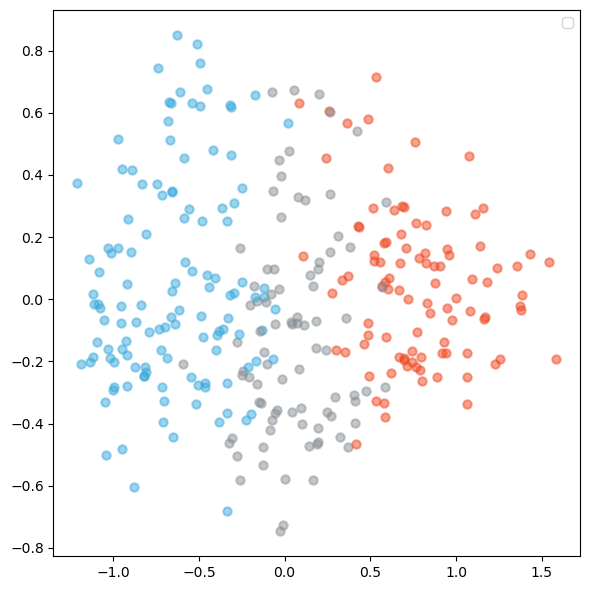

In [338]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))  # Assuming 30 figures, you can adjust the layout as needed

lw = 1.5
m_cluster = {"C1":'#F04923',"C2":'#3BA9DD',"Others":'#8A9197'}
# m_organ_c = m_cluster # {'C1':'red','C2':'blue','Others':'black'}
# m_set = {'Train':'x','Valid':'o'}

for _,row in data_pca.iterrows():
    x, y ,c = row[['X1','X2','Group']]
    ax.scatter(
        x, y, color=m_cluster[c],
        alpha=0.5, lw=lw
    )

ax.legend(loc="best", shadow=False, scatterpoints=1)
# ax.set_title("PCA of 49+77 patients")

plt.tight_layout()
plt.show()


In [324]:
db.exporting(fig,'fig.S10_ext_valid_predict_by_ssgsea_PCA_CancerReports.pdf',outputdir='report_reply')

[08/25 08:37:00] writing 1 file with plt at 
	[PROJECT_ROOT]/report_reply/fig.S9_ext_valid_predict_by_ssgsea_PCA_CancerReports.pdf


In [315]:
des_cr['pid'] = "PCSHA_"+des_cr['Patient_ID'].astype(str)

In [319]:
os_table = des_cr[['pid','bcr_months','bcr_status']]
ost = pd.merge(os_table, data_pca, on='pid',how='inner')
ost

,pid,bcr_months,bcr_status,x,y,Group
0,PCSHA_1,3.1,1.0,-0.122410,0.008674,C2
1,PCSHA_3,41.9,1.0,0.484882,-0.114866,C1
2,PCSHA_5,1.4,1.0,1.065630,-0.250712,C1
...,...,...,...,...,...,...
303,PCSHA_355,0.8,0.0,-0.713022,-0.281579,C2
304,PCSHA_356,39.5,0.0,-0.818012,-0.246563,C2
305,PCSHA_357,34.6,1.0,-0.143031,-0.100831,Others


In [320]:
db.exporting(ost, 'bcr_table_pca_cluster',outputdir='external_info/article_data_others_works/PC_CellReportsMedicine/')

[08/25 08:35:02] writing 1 file with 306 lines at 
	[PROJECT_ROOT]/external_info/article_data_others_works/PC_CellReportsMedicine/bcr_table_pca_cluster.dfx


#### cancer cell

In [327]:
cc

,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_HYPOXIA,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_MITOTIC_SPINDLE,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_DNA_REPAIR,HALLMARK_G2M_CHECKPOINT,HALLMARK_APOPTOSIS,HALLMARK_NOTCH_SIGNALING,HALLMARK_ADIPOGENESIS,HALLMARK_ESTROGEN_RESPONSE_EARLY,HALLMARK_ESTROGEN_RESPONSE_LATE,HALLMARK_ANDROGEN_RESPONSE,HALLMARK_MYOGENESIS,HALLMARK_PROTEIN_SECRETION,HALLMARK_INTERFERON_ALPHA_RESPONSE,HALLMARK_INTERFERON_GAMMA_RESPONSE,HALLMARK_APICAL_JUNCTION,HALLMARK_APICAL_SURFACE,HALLMARK_HEDGEHOG_SIGNALING,HALLMARK_COMPLEMENT,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,HALLMARK_PI3K_AKT_MTOR_SIGNALING,HALLMARK_MTORC1_SIGNALING,HALLMARK_E2F_TARGETS,HALLMARK_MYC_TARGETS_V1,HALLMARK_MYC_TARGETS_V2,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,...,HALLMARK_KRAS_SIGNALING_DN,HALLMARK_PANCREAS_BETA_CELLS,Activated B cell,Activated CD4 T cell,Activated CD8 T cell,Activated dendritic cell,CD56bright natural killer cell,CD56dim natural killer cell,Central memory CD4 T cell,Central memory CD8 T cell,Effector memeory CD4 T cell,Effector memeory CD8 T cell,Eosinophil,Gamma delta T cell,Immature B cell,Immature dendritic cell,Macrophage,Mast cell,MDSC,Memory B cell,Monocyte,Natural killer cell,Natural killer T cell,Neutrophil,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 17 T helper cell,Type 2 T helper cell
CPCG0100,0.066975,0.228318,0.091714,0.109226,0.162137,0.148535,0.054528,-0.011201,0.372449,0.061474,0.188690,-0.006753,0.058321,0.091764,0.073000,0.190727,0.140760,0.125587,0.088136,0.137073,-0.003821,0.392695,0.241822,0.108750,0.124586,0.186157,0.343557,0.255598,-0.074227,0.131904,...,0.002012,0.102996,0.009054,-0.188509,-0.043090,0.162191,0.035323,0.238644,0.118175,0.078401,0.040050,0.089946,-0.392857,0.100969,0.188451,0.020426,0.054585,0.104931,-0.055062,-0.088160,0.213238,0.111391,0.266362,0.023073,0.101343,0.072706,0.154433,-0.019493,0.516234,-0.104864
CPCG0102,-0.052211,0.229007,-0.011356,0.076556,-0.142582,0.111886,-0.113006,-0.050239,-0.075531,0.129179,0.152668,0.228745,0.000310,0.083304,0.078725,0.343317,0.064870,-0.120599,-0.067032,0.212987,0.116972,0.129062,0.251425,0.077735,0.133392,0.147696,-0.064185,0.042218,-0.171996,0.424370,...,-0.124375,0.198568,-0.237666,-0.233160,0.065812,0.114668,0.032243,0.178605,0.070226,0.287226,0.146702,0.102490,-0.373377,0.114289,-0.328229,0.144617,0.069578,0.026515,-0.024177,0.016410,0.135771,0.122336,0.192944,-0.157111,0.200241,0.005734,0.080305,0.074271,-0.324970,0.104581
CPCG0103,-0.064949,0.240292,0.011591,0.054526,0.204563,-0.107533,-0.007517,-0.079722,0.008091,0.216180,0.465750,0.125948,0.033135,0.154980,0.039120,0.454159,-0.074009,0.009583,-0.042176,0.178768,0.120498,-0.141713,0.242683,0.039689,0.106061,0.054086,-0.017864,0.120227,0.042015,0.281286,...,0.286494,0.019782,0.183819,-0.184020,-0.029178,0.058879,0.059864,0.080220,0.048253,0.231353,0.189423,-0.187500,0.016234,0.064905,-0.245622,0.238617,-0.195391,0.241512,-0.020852,-0.144482,-0.119638,0.189747,0.094026,0.142754,0.057211,-0.102533,0.011655,0.197575,0.353306,-0.152028
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CPCG0557,0.060787,0.283914,-0.095698,0.126236,0.135066,0.005370,0.092190,-0.082698,-0.102364,0.225424,0.452286,0.110140,0.120603,0.180800,0.007440,0.453121,-0.114971,0.134577,0.097153,0.219241,0.121015,-0.011767,0.347924,-0.047121,0.093545,-0.008382,-0.044796,-0.128352,-0.169713,0.410324,...,0.325471,-0.005656,0.343250,-0.253895,0.033847,0.039744,0.091219,0.026171,0.119405,0.046581,0.126883,0.066173,-0.369244,0.143308,-0.395107,0.087673,-0.265079,0.430947,0.125265,-0.021542,-0.051241,0.143999,0.195697,0.162000,-0.033854,-0.074111,0.037495,0.203316,0.147875,-0.081195
CPCG0584,-0.084378,0.141211

In [101]:
OUTPUTROOT

'report_2914'

In [341]:
mat = cc

pca = PCA(n_components=4)
X_r = pd.DataFrame(pca.fit_transform(mat),index=mat.index ,columns=['X1','X2','X3','X4'])

cls = dtc.predict(mat)


df = pd.DataFrame({"pid":mat.index,"Group":cls})

data_pca = pd.merge( X_r[['X1','X2']]
                    , df,
            left_index=True,right_on='pid',how='left')
cc_data = data_pca
data_pca

,X1,X2,pid,Group
0,-0.450857,-0.115976,CPCG0100,C2
1,-0.941124,0.018457,CPCG0102,C2
2,-0.211683,-0.757077,CPCG0103,C2
...,...,...,...,...
76,-0.381637,-0.861620,CPCG0557,C2
77,-0.107453,-0.216368,CPCG0584,C1
78,-0.495502,-0.456670,CPCG0615,C1


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


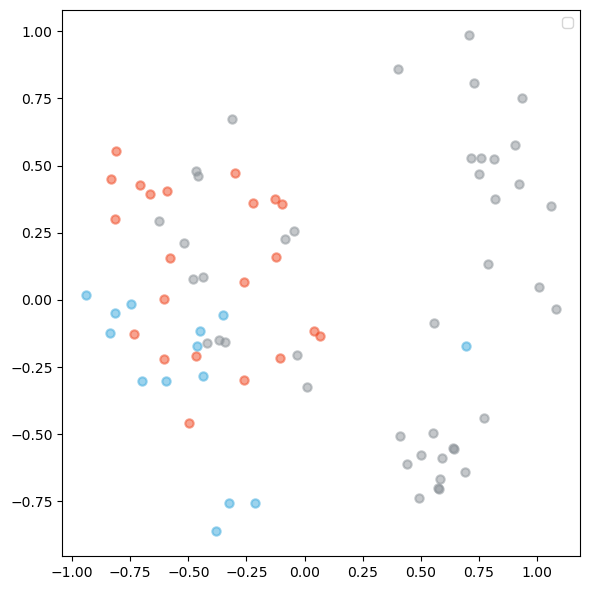

In [342]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))  # Assuming 30 figures, you can adjust the layout as needed

lw = 1.5
m_cluster = {"C1":'#F04923',"C2":'#3BA9DD',"Others":'#8A9197'}
# m_organ_c = m_cluster # {'C1':'red','C2':'blue','Others':'black'}
# m_set = {'Train':'x','Valid':'o'}

for _,row in data_pca.iterrows():
    x, y ,c = row[['X1','X2','Group']]
    ax.scatter(
        x, y, color=m_cluster[c],
        alpha=0.5, lw=lw
    )

ax.legend(loc="best", shadow=False, scatterpoints=1)
# ax.set_title("PCA of 49+77 patients")

plt.tight_layout()
plt.show()


In [329]:
db.exporting(data_pca, 'PCA_with_cluster',outputdir='external_info/article_data_others_works/PC_CancerCell_Canada/')

[08/25 08:50:47] writing 1 file with 79 lines at 
	[PROJECT_ROOT]/external_info/article_data_others_works/PC_CancerCell_Canada/PCA_with_cluster.dfx


In [328]:


db.exporting(fig,'fig.S10_ext_valid_predict_by_ssgsea_PCA_CancerCell.pdf',outputdir='report_reply')



[08/25 08:50:14] writing 1 file with plt at 
	[PROJECT_ROOT]/report_reply/fig.S9_ext_valid_predict_by_ssgsea_PCA_CancerCell.pdf


#### put ori data

In [330]:
# Ankit Sinha, et al
cc

,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_HYPOXIA,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_MITOTIC_SPINDLE,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_DNA_REPAIR,HALLMARK_G2M_CHECKPOINT,HALLMARK_APOPTOSIS,HALLMARK_NOTCH_SIGNALING,HALLMARK_ADIPOGENESIS,HALLMARK_ESTROGEN_RESPONSE_EARLY,HALLMARK_ESTROGEN_RESPONSE_LATE,HALLMARK_ANDROGEN_RESPONSE,HALLMARK_MYOGENESIS,HALLMARK_PROTEIN_SECRETION,HALLMARK_INTERFERON_ALPHA_RESPONSE,HALLMARK_INTERFERON_GAMMA_RESPONSE,HALLMARK_APICAL_JUNCTION,HALLMARK_APICAL_SURFACE,HALLMARK_HEDGEHOG_SIGNALING,HALLMARK_COMPLEMENT,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,HALLMARK_PI3K_AKT_MTOR_SIGNALING,HALLMARK_MTORC1_SIGNALING,HALLMARK_E2F_TARGETS,HALLMARK_MYC_TARGETS_V1,HALLMARK_MYC_TARGETS_V2,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,...,HALLMARK_KRAS_SIGNALING_DN,HALLMARK_PANCREAS_BETA_CELLS,Activated B cell,Activated CD4 T cell,Activated CD8 T cell,Activated dendritic cell,CD56bright natural killer cell,CD56dim natural killer cell,Central memory CD4 T cell,Central memory CD8 T cell,Effector memeory CD4 T cell,Effector memeory CD8 T cell,Eosinophil,Gamma delta T cell,Immature B cell,Immature dendritic cell,Macrophage,Mast cell,MDSC,Memory B cell,Monocyte,Natural killer cell,Natural killer T cell,Neutrophil,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 17 T helper cell,Type 2 T helper cell
CPCG0100,0.066975,0.228318,0.091714,0.109226,0.162137,0.148535,0.054528,-0.011201,0.372449,0.061474,0.188690,-0.006753,0.058321,0.091764,0.073000,0.190727,0.140760,0.125587,0.088136,0.137073,-0.003821,0.392695,0.241822,0.108750,0.124586,0.186157,0.343557,0.255598,-0.074227,0.131904,...,0.002012,0.102996,0.009054,-0.188509,-0.043090,0.162191,0.035323,0.238644,0.118175,0.078401,0.040050,0.089946,-0.392857,0.100969,0.188451,0.020426,0.054585,0.104931,-0.055062,-0.088160,0.213238,0.111391,0.266362,0.023073,0.101343,0.072706,0.154433,-0.019493,0.516234,-0.104864
CPCG0102,-0.052211,0.229007,-0.011356,0.076556,-0.142582,0.111886,-0.113006,-0.050239,-0.075531,0.129179,0.152668,0.228745,0.000310,0.083304,0.078725,0.343317,0.064870,-0.120599,-0.067032,0.212987,0.116972,0.129062,0.251425,0.077735,0.133392,0.147696,-0.064185,0.042218,-0.171996,0.424370,...,-0.124375,0.198568,-0.237666,-0.233160,0.065812,0.114668,0.032243,0.178605,0.070226,0.287226,0.146702,0.102490,-0.373377,0.114289,-0.328229,0.144617,0.069578,0.026515,-0.024177,0.016410,0.135771,0.122336,0.192944,-0.157111,0.200241,0.005734,0.080305,0.074271,-0.324970,0.104581
CPCG0103,-0.064949,0.240292,0.011591,0.054526,0.204563,-0.107533,-0.007517,-0.079722,0.008091,0.216180,0.465750,0.125948,0.033135,0.154980,0.039120,0.454159,-0.074009,0.009583,-0.042176,0.178768,0.120498,-0.141713,0.242683,0.039689,0.106061,0.054086,-0.017864,0.120227,0.042015,0.281286,...,0.286494,0.019782,0.183819,-0.184020,-0.029178,0.058879,0.059864,0.080220,0.048253,0.231353,0.189423,-0.187500,0.016234,0.064905,-0.245622,0.238617,-0.195391,0.241512,-0.020852,-0.144482,-0.119638,0.189747,0.094026,0.142754,0.057211,-0.102533,0.011655,0.197575,0.353306,-0.152028
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CPCG0557,0.060787,0.283914,-0.095698,0.126236,0.135066,0.005370,0.092190,-0.082698,-0.102364,0.225424,0.452286,0.110140,0.120603,0.180800,0.007440,0.453121,-0.114971,0.134577,0.097153,0.219241,0.121015,-0.011767,0.347924,-0.047121,0.093545,-0.008382,-0.044796,-0.128352,-0.169713,0.410324,...,0.325471,-0.005656,0.343250,-0.253895,0.033847,0.039744,0.091219,0.026171,0.119405,0.046581,0.126883,0.066173,-0.369244,0.143308,-0.395107,0.087673,-0.265079,0.430947,0.125265,-0.021542,-0.051241,0.143999,0.195697,0.162000,-0.033854,-0.074111,0.037495,0.203316,0.147875,-0.081195
CPCG0584,-0.084378,0.141211

In [332]:
# ssGSEA - Sun Rui, et al.
cr

,HALLMARK_TNFA_SIGNALING_VIA_NFKB,HALLMARK_HYPOXIA,HALLMARK_CHOLESTEROL_HOMEOSTASIS,HALLMARK_MITOTIC_SPINDLE,HALLMARK_WNT_BETA_CATENIN_SIGNALING,HALLMARK_TGF_BETA_SIGNALING,HALLMARK_IL6_JAK_STAT3_SIGNALING,HALLMARK_DNA_REPAIR,HALLMARK_G2M_CHECKPOINT,HALLMARK_APOPTOSIS,HALLMARK_NOTCH_SIGNALING,HALLMARK_ADIPOGENESIS,HALLMARK_ESTROGEN_RESPONSE_EARLY,HALLMARK_ESTROGEN_RESPONSE_LATE,HALLMARK_ANDROGEN_RESPONSE,HALLMARK_MYOGENESIS,HALLMARK_PROTEIN_SECRETION,HALLMARK_INTERFERON_ALPHA_RESPONSE,HALLMARK_INTERFERON_GAMMA_RESPONSE,HALLMARK_APICAL_JUNCTION,HALLMARK_APICAL_SURFACE,HALLMARK_HEDGEHOG_SIGNALING,HALLMARK_COMPLEMENT,HALLMARK_UNFOLDED_PROTEIN_RESPONSE,HALLMARK_PI3K_AKT_MTOR_SIGNALING,HALLMARK_MTORC1_SIGNALING,HALLMARK_E2F_TARGETS,HALLMARK_MYC_TARGETS_V1,HALLMARK_MYC_TARGETS_V2,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,...,HALLMARK_KRAS_SIGNALING_DN,HALLMARK_PANCREAS_BETA_CELLS,Activated B cell,Activated CD4 T cell,Activated CD8 T cell,Activated dendritic cell,CD56bright natural killer cell,CD56dim natural killer cell,Central memory CD4 T cell,Central memory CD8 T cell,Effector memeory CD4 T cell,Effector memeory CD8 T cell,Eosinophil,Gamma delta T cell,Immature B cell,Immature dendritic cell,Macrophage,Mast cell,MDSC,Memory B cell,Monocyte,Natural killer cell,Natural killer T cell,Neutrophil,Plasmacytoid dendritic cell,Regulatory T cell,T follicular helper cell,Type 1 T helper cell,Type 17 T helper cell,Type 2 T helper cell
PCSHA_1,0.053433,0.163133,0.209966,0.122327,0.041575,0.066868,0.054014,0.035796,0.176613,0.205042,0.073515,0.056855,0.131746,0.110027,0.118609,0.045153,0.172439,0.008674,-0.048858,0.123158,0.190386,0.186884,0.206428,0.086019,0.114364,0.098122,0.032550,0.069983,-0.206665,0.064905,...,0.025351,-0.034088,0.043086,-0.161041,0.033062,0.050511,0.120202,-0.062141,0.008056,-0.051320,-0.006499,-0.098906,-0.330934,0.085993,-0.134611,0.193920,0.059273,0.104123,0.059117,0.101027,0.187555,0.009612,0.173578,0.410284,0.133353,-0.055590,0.093913,0.024788,-0.230911,-0.001204
PCSHA_3,0.054707,0.076525,0.150230,0.082016,0.296987,0.082484,0.008079,0.117160,0.092135,0.104511,0.160358,0.191532,0.043610,0.152159,0.041927,-0.016380,0.193932,-0.054755,-0.060764,0.027622,-0.130776,-0.172686,0.051564,0.167171,0.101824,0.153968,0.048309,0.114553,0.073118,-0.052552,...,-0.098372,-0.075188,-0.009952,0.148045,0.068561,0.078217,0.094731,0.066840,-0.041644,0.085867,0.004260,-0.142842,-0.158988,0.134518,-0.017988,0.175086,0.034584,0.183919,-0.050985,-0.055127,-0.025314,-0.074102,0.169542,-0.222376,0.114256,-0.229357,0.029911,0.020213,-0.029435,0.034846
PCSHA_5,0.052059,0.026010,0.040653,0.034663,0.217239,0.099305,0.030325,0.209175,0.269669,0.046878,0.105531,0.147723,-0.005484,-0.026177,0.012250,-0.168339,0.137095,-0.021993,-0.025380,-0.062962,0.013121,-0.068241,-0.045851,0.215980,0.065249,0.183706,0.269358,0.379570,0.360820,-0.241194,...,-0.142182,0.136258,0.040920,-0.360992,0.072118,0.016860,0.010973,0.076534,0.052435,0.054047,0.135254,-0.005081,0.260181,0.087479,-0.169632,0.126799,-0.079897,-0.153124,-0.137237,-0.186250,0.095994,-0.180318,-0.084839,-0.332531,0.044150,-0.078299,-0.006876,-0.108364,-0.068243,0.006522
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PCSHA_323,0.002136,0.201376,0.113810,0.174143,-0.044451,0.092185,0.130912,-0.047418,0.009632,0.066522,0.265185,0.136871,0.116333,0.105402,0.002084,0.307401,0.102768,-0.006425,0.047645,0.285066,0.114256,0.036193,0.151455,-0.017362,0.222885,0.107319,-0.113242,-0.062413,-0.214543,0.231833,...,0.119596,0.067279,0.081971,-0.325089,-0.179520,0.127641,0.028270,0.102108,0.169672,-0.138736,-0.038097,-0.005153,-0.380296,0.062836,-0.059890,0.198906,-0.100332,-0.012627,-0.254466,0.130569,-0.096283,0.185223,0.052374,-0.270325,-0.039910,-0.028491,0.031707,0.223641,-0.208045,0.124340
PCSHA_324,-0.0710

In [343]:
cc_data

,X1,X2,pid,Group
0,-0.450857,-0.115976,CPCG0100,C2
1,-0.941124,0.018457,CPCG0102,C2
2,-0.211683,-0.757077,CPCG0103,C2
...,...,...,...,...
76,-0.381637,-0.861620,CPCG0557,C2
77,-0.107453,-0.216368,CPCG0584,C1
78,-0.495502,-0.456670,CPCG0615,C1


In [344]:
cr_data

,X1,X2,pid,Group
0,-0.122410,0.008674,PCSHA_1,C2
1,0.484882,-0.114866,PCSHA_3,C1
2,1.065630,-0.250712,PCSHA_5,C1
...,...,...,...,...
303,-0.338148,-0.682885,PCSHA_323,C2
304,-0.266892,-0.112958,PCSHA_324,C2
305,-1.043006,-0.500903,PCSHA_325,C2


In [347]:
db.exporting(cr_data, 'predict_cluster_data',outputdir='external_info/article_data_others_works/PC_CellReportsMedicine/')
db.exporting(cc_data, 'predict_cluster_data',outputdir='external_info/article_data_others_works/PC_CancerCell_Canada/')


[08/25 09:24:12] writing 1 file with 306 lines at 
	[PROJECT_ROOT]/external_info/article_data_others_works/PC_CellReportsMedicine/predict_cluster_data.dfx
[08/25 09:24:12] writing 1 file with 79 lines at 
	[PROJECT_ROOT]/external_info/article_data_others_works/PC_CancerCell_Canada/predict_cluster_data.dfx


In [350]:
cr_input = db.importing('external_info/article_data_others_works/PC_CellReportsMedicine/prt_mat_ssgsea_input.dfx')
cc_input = db.importing('external_info/article_data_others_works/PC_CancerCell_Canada/prt_mat_ssgsea_input.dfx')
cr_input


[08/25 09:36:49]reading external_info/article_data_others_works/PC_CellReportsMedicine/prt_mat_ssgsea_input.dfx
[08/25 09:36:49]reading external_info/article_data_others_works/PC_CancerCell_Canada/prt_mat_ssgsea_input.dfx


,PCSHA_1,PCSHA_3,PCSHA_5,PCSHA_6,PCSHA_7,PCSHA_8,PCSHA_9,PCSHA_10,PCSHA_11,PCSHA_13,PCSHA_14,PCSHA_15,PCSHA_16,PCSHA_17,PCSHA_18,PCSHA_19,PCSHA_20,PCSHA_21,PCSHA_22,PCSHA_23,PCSHA_25,PCSHA_26,PCSHA_27,PCSHA_28,PCSHA_30,PCSHA_31,PCSHA_32,PCSHA_33,PCSHA_34,PCSHA_35,...,PCSHA_229,PCSHA_230,PCSHA_241,PCSHA_242,PCSHA_243,PCSHA_244,PCSHA_245,PCSHA_257,PCSHA_258,PCSHA_259,PCSHA_260,PCSHA_261,PCSHA_262,PCSHA_263,PCSHA_264,PCSHA_265,PCSHA_301,PCSHA_303,PCSHA_304,PCSHA_305,PCSHA_311,PCSHA_312,PCSHA_313,PCSHA_314,PCSHA_315,PCSHA_321,PCSHA_322,PCSHA_323,PCSHA_324,PCSHA_325
A2M,1.120555,0.143784,-0.310076,-0.771399,-0.319232,-0.576824,-0.744564,-0.514655,0.251683,0.054785,-0.901634,-0.633442,-0.765370,0.787333,0.122105,-0.843845,-0.455024,1.397610,0.012830,-0.197467,0.397358,0.679410,0.071329,-0.299389,3.045227,-0.803437,-0.411176,-0.751648,-0.593805,0.584878,...,-0.224393,0.208678,-0.540391,0.195530,1.104319,1.740096,0.166661,0.351067,0.122280,3.303468,0.327852,-0.586022,0.834314,0.185997,-0.081984,0.427825,0.930565,1.867604,-0.074006,0.478914,1.208737,-0.433592,3.984143,1.601681,4.693090,0.885804,-0.464852,1.373046,3.050658,5.629418
AAAS,-0.515900,0.633930,2.624361,1.286959,-0.347125,-1.043179,0.813901,2.653757,-0.990561,-1.058351,-0.555827,-0.162685,-0.856968,-0.840384,-0.752264,-0.502502,-0.202680,-0.812987,-0.699871,-0.195881,-0.575956,-0.442309,1.650708,0.349173,0.068680,-0.084698,-0.187549,-0.878926,0.132869,-0.085829,...,-0.789124,-0.952633,2.064383,-0.861448,1.029666,0.574136,0.487951,-0.625550,-0.904173,1.425877,0.882160,1.380747,1.573523,-0.394649,0.599401,1.224509,0.071814,2.041586,1.170717,-0.444175,1.555390,0.291511,0.684257,0.198926,0.621997,0.698182,5.424939,0.903686,-0.113360,-0.877511
AADAT,-0.755013,0.321144,0.404786,-0.559391,1.611801,-0.392219,0.826573,0.176847,-0.635285,-0.724069,-0.712842,-0.345887,-0.315588,-0.521444,-0.412547,-0.366938,-0.188374,-0.096389,0.334569,-0.393736,-0.159645,-0.510564,-0.673424,-0.252991,-0.413553,-0.723748,-0.090055,-0.684131,-0.493647,-0.606182,...,-0.528857,-0.117292,0.219252,-0.119928,-0.346956,-0.216539,0.041161,0.321061,-0.014946,0.796055,-0.188914,-0.242023,0.586727,0.048794,0.553747,0.882350,-0.213530,1.760465,0.719605,-0.295469,-0.526840,0.091723,-0.281748,-0.206368,-0.339996,-0.402849,6.168364,0.018400,0.848520,0.719121
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZNF185,1.477693,0.422613,-0.267168,-0.443674,3.455688,0.912337,0.886852,-0.251188,-0.036728,-0.972477,-0.564740,-0.427622,-0.171346,-0.553506,1.241324,1.938413,-0.442314,-0.409746,-0.411160,-0.085489,0.166077,1.882036,-0.326579,1.419606,-0.362486,-0.660285,-0.432880,2.454640,0.090976,-0.443929,...,1.235164,-0.051972,-0.869522,0.808111,-0.194221,-0.504847,-0.071150,0.816919,1.311510,-0.597763,-0.854370,2.690315,0.426781,-0.196058,0.127111,0.283408,-0.346232,-0.932336,0.800794,0.980012,0.705636,2.503236,-0.482049,1.090393,-0.437237,0.604390,-0.896627,1.911348,-0.120480,0.160190
ZW10,0.699967,0.185644,-0.471110,-0.325524,8.562703,2.334990,2.987421,-0.539795,-0.741469,-0.662760,-0.795248,-0.508577,-0.595904,-0.367712,-0.610350,-0.848042,-0.652535,-0.669972,0.208046,-0.180260,-0.270118,0.295109,-0.621557,-0.703521,0.996403,-0.781065,-0.636323,3.208574,-0.577241,-0.223570,...,-0.082207,0.897016,3.272037,0.139277,0.794847,0.041988,-0.133189,0.342335,1.609898,1.181604,0.375165,0.389067,0.746515,0.231509,1.025573,0.479929,0.034796,0.916870,0.968197,-0.108500,0.687611,3.360195,1.329941,1.022296,0.162924,1.043129,1.067999,0.461005,1.839601,0.281993
ZYX,2.190937,0.565819,-0.228442,-0.022655,0.701911,-0.607308,-0.125926,0.616766,-0.401703,-1.277933,-0.824232,-0.613775,0.704791,0.685400,0.485039,-0.058829,0.020168,-0.412124,-0.690397,-0.846546,0.089999,0.613032,0.856648,2.016181,2.466560,-0.074407,-0.014495,-0.599604,0.302304,-0.42287

In [353]:
write_excel({'ssGSEA -CC- Ankit Sinha, et al':cc,
             'ssGSEA -CRM- Rui Sun, et al.':cr,
             'Prediction -CC- Ankit Sinha, et al': cc_data,
             'Prediction -CRM- Rui Sun, et al.':cr_data,
             "prt -CC- Ankit Sinha, et al":cc_input,
             "prt -CRM- Rui Sun, et al.": cr_input
            }
            , 'fig.S10_related_data.xlsx'
            , outputdir='report_reply/')

  append #1 Sheet [ssGSEA -CC- Ankit Sinha, et al]
  append #2 Sheet [ssGSEA -CRM- Rui Sun, et al.]
  append #3 Sheet [Prediction -CC- Ankit Sinha, et al]
  append #4 Sheet [Prediction -CRM- Rui Sun, et al.]
  append #5 Sheet [prt -CC- Ankit Sinha, et al]
  append #6 Sheet [prt -CRM- Rui Sun, et al.]
writing 1 .xls @ report_reply/fig.S9_related_data.xlsx
